# Pronóstico de demanda — Klixmant S.A.S.
**Analítica de Marketing · UNAB (TEMA, curso 2228) · Trabajo Final U4**

Notebook **global** del proyecto. Todas las fases se trabajan aquí, en orden, siguiendo CRISP-DM.

| Sección | Fase CRISP-DM | Estado |
|---|---|---|
| 0. Configuración del entorno (local / Colab + Drive) | — | ✅ |
| 1. Marco de trabajo | — | ✅ |
| 2. Entendimiento del negocio | Business understanding | ✅ |
| 3. Entendimiento de los datos (cuadre + EDA) | Data understanding | ✅ |
| 4. Preparación e ingeniería de variables | Data preparation | ✅ |
| 5. Modelado (escalera de modelos + validación preliminar) | Modeling | ✅ (candidato; §6 lo confirma o cambia) |
| 6. Validación y métricas (backtesting de 15 orígenes + holdout) | Evaluation | ✅ |
| 7. Gráficas finales (producción, póster e índice de figuras) | — | ✅ |
| 8. Documentación / despliegue (modelo guardado, guía, *model card*, datos de la app) | Deployment | ✅ |

> **Regla para quien siga:** ejecutar siempre de arriba abajo (*Run all*). Las secciones nuevas usan las variables
> y funciones definidas en la sección 0 (`RUTAS`, `cargar_pedidos()`, `guardar_fig()`, `DECISIONES`, `EVENTOS`).
> El texto explicativo de este notebook es un borrador técnico: el grupo debe redactarlo con sus propias palabras antes de entregar.

## 0. Configuración del entorno

El mismo notebook corre **en local** y **en Google Colab**:

- **Local:** la carpeta del proyecto es la carpeta donde está este notebook (o la primera carpeta padre que contenga el Excel).
- **Colab:** se monta Google Drive en `/content/drive` y se busca la carpeta compartida del proyecto
  ([enlace](https://drive.google.com/drive/folders/19HmUVRpHptxeVwAI32HIwC5_zZ1NGYgO?usp=drive_link)).
  Para que aparezca dentro de `/content/drive/MyDrive/`, cada integrante debe abrir el enlace y usar
  **"Organizar → Agregar acceso directo a Mi unidad"**. Si no se encuentra, se descarga la carpeta con `gdown`
  a `/content/klixmant` (en ese caso lo que se guarde se pierde al cerrar la sesión).

In [1]:
# 0.1 Detección del entorno y montaje de Drive
import sys, os, glob, warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)

EN_COLAB = "google.colab" in sys.modules
NOMBRE_EXCEL = "Klixmant_Base_de_Datos_UNAB_2026-10-07.xlsx"
DRIVE_FOLDER_ID = "19HmUVRpHptxeVwAI32HIwC5_zZ1NGYgO"
DRIVE_FOLDER_URL = f"https://drive.google.com/drive/folders/{DRIVE_FOLDER_ID}?usp=drive_link"
# Ruta esperada en Drive (ajustar si el acceso directo tiene otro nombre)
RUTA_DRIVE = "/content/drive/MyDrive/Trabajo final Klixmant S.A.S"


def _base_desde_excel(ruta_excel):
    # Si el Excel está dentro de datos/, la base del proyecto es la carpeta padre
    p = Path(ruta_excel).parent
    return p.parent if p.name == "datos" else p


if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    candidatos = glob.glob(f"{RUTA_DRIVE}/{NOMBRE_EXCEL}") + glob.glob(f"{RUTA_DRIVE}/datos/{NOMBRE_EXCEL}")
    for patron in ["/content/drive/MyDrive/*/", "/content/drive/MyDrive/*/*/", "/content/drive/Shareddrives/*/*/"]:
        if candidatos:
            break
        candidatos = glob.glob(patron + NOMBRE_EXCEL) + glob.glob(patron + "datos/" + NOMBRE_EXCEL)
    if candidatos:
        BASE = _base_desde_excel(candidatos[0])
    else:
        print("No se encontró la carpeta en Drive; se descarga con gdown (los resultados NO quedan en Drive).")
        os.system("pip -q install gdown")
        import gdown
        BASE = Path("/content/klixmant")
        gdown.download_folder(url=DRIVE_FOLDER_URL, output=str(BASE), quiet=True)
else:
    BASE = Path.cwd()
    for p in [BASE, *BASE.parents]:
        if (p / NOMBRE_EXCEL).exists() or (p / "datos" / NOMBRE_EXCEL).exists():
            BASE = p
            break

print("Entorno:", "Colab" if EN_COLAB else "Local")
print("Carpeta del proyecto:", BASE)

Entorno: Local
Carpeta del proyecto: C:\Users\diani\OneDrive\Escritorio\Trabajo final Klixmant S.A.S


In [2]:
# 0.2 Estructura de carpetas (§1 del plan) y ubicación del Excel original
RUTAS = {k: BASE / k for k in ["datos", "procesado", "modelos", "figuras", "docs"]}
for p in RUTAS.values():
    p.mkdir(exist_ok=True)

# El Excel original no se modifica nunca. Puede estar en datos/ o en la raíz del proyecto.
RUTA_EXCEL = next((p for p in [RUTAS["datos"] / NOMBRE_EXCEL, BASE / NOMBRE_EXCEL] if p.exists()), None)
assert RUTA_EXCEL is not None, f"No se encontró {NOMBRE_EXCEL} en {BASE} ni en {RUTAS['datos']}"
print("Excel:", RUTA_EXCEL)
for k, v in RUTAS.items():
    print(f"  {k:<10} -> {v}")

Excel: C:\Users\diani\OneDrive\Escritorio\Trabajo final Klixmant S.A.S\Klixmant_Base_de_Datos_UNAB_2026-10-07.xlsx
  datos      -> C:\Users\diani\OneDrive\Escritorio\Trabajo final Klixmant S.A.S\datos
  procesado  -> C:\Users\diani\OneDrive\Escritorio\Trabajo final Klixmant S.A.S\procesado
  modelos    -> C:\Users\diani\OneDrive\Escritorio\Trabajo final Klixmant S.A.S\modelos
  figuras    -> C:\Users\diani\OneDrive\Escritorio\Trabajo final Klixmant S.A.S\figuras
  docs       -> C:\Users\diani\OneDrive\Escritorio\Trabajo final Klixmant S.A.S\docs


In [3]:
# 0.3 Librerías, versiones y semilla
import random, re
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import statsmodels
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

import platform
VERSIONES = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
             "matplotlib": matplotlib.__version__, "seaborn": sns.__version__, "statsmodels": statsmodels.__version__}
print(VERSIONES)

{'python': '3.14.7', 'pandas': '3.1.1', 'numpy': '2.5.4', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'statsmodels': '0.15.0'}


In [4]:
# 0.4 Estilo de gráficas (paleta Okabe-Ito, apta para daltonismo; mismo color = mismo canal en todo el trabajo)
OKABE_ITO = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000"]
COLOR_CANAL = {"EFFI": "#0072B2", "DROPI": "#E69F00", "TOTAL": "#000000"}
COLOR_FAMILIA = {"COLOMBIA": "#D55E00", "RESTO": "#0072B2"}
COLOR_EVENTO = "#F0E442"

sns.set_theme(style="whitegrid", palette=OKABE_ITO)
plt.rcParams.update({"figure.figsize": (11, 4.5), "figure.dpi": 100, "axes.titleweight": "bold",
                     "axes.titlesize": 12, "savefig.bbox": "tight", "savefig.dpi": 150})


MESES_ES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
FMT_MES = matplotlib.ticker.FuncFormatter(lambda x, pos: MESES_ES[mdates.num2date(x).month - 1])   # ejes de fecha en español


def guardar_fig(fig, nombre):
    # Guarda en figuras/ con nombre numerado por sección, p. ej. "3_2_01_serie_semanal"
    ruta = RUTAS["figuras"] / f"{nombre}.png"
    fig.savefig(ruta)
    return ruta


def sombrear_mundial(ax, alpha=0.25, etiqueta=True):
    ax.axvspan(EVENTOS["mundial_inicio"], EVENTOS["mundial_fin"], color=COLOR_EVENTO, alpha=alpha,
               label="Mundial 2026" if etiqueta else None, zorder=0)

In [5]:
# 0.5 Constantes del caso: decisiones de negocio (§2) y calendario de eventos (§3.4)
DECISIONES = {
    "unidad_pronostico": "catalogo",          # agregable a referencia (tela) y desagregable a talla x color
    "top_n_modelados": 20,                    # top 15-20 (~71-75 % del volumen); el resto por regla
    "frecuencia": "W-MON",                    # semanas lunes a domingo, identificadas por el lunes
    "horizonte_principal": 4,                 # semanas
    "horizonte_extendido": 8,                 # semanas
    "eje_tiempo": "fecha_remision",           # nunca fecha_carga
    "medida": "cantidad_total",               # sumar unidades, no contar filas
    "excluir_estados": ["CANCELADO"],
    "fecha_corte_datos": pd.Timestamp("2026-10-06"),
}

EVENTOS = {
    "mundial_inicio": pd.Timestamp("2026-06-11"),
    "mundial_fin": pd.Timestamp("2026-07-19"),
}
FAMILIA_COLOMBIA_REGEX = r"COLOMBIA|SELECCI"   # catálogos de la Selección Colombia
# Partidos de Colombia en el Mundial (detalle y fuentes en §3.3)
EVENTOS_PARTIDOS = pd.DataFrame({
    "fecha": pd.to_datetime(["2026-06-17", "2026-06-23", "2026-06-27", "2026-07-03", "2026-07-07"]),
    "evento": ["COL vs UZB (3-1)", "COL vs COD (1-0)", "COL vs POR (0-0)", "COL vs GHA (1-0) 16avos", "SUI vs COL (0-0, 4-3 pen) 8vos"],
    "tipo": "partido_colombia",
})

print(DECISIONES)

{'unidad_pronostico': 'catalogo', 'top_n_modelados': 20, 'frecuencia': 'W-MON', 'horizonte_principal': 4, 'horizonte_extendido': 8, 'eje_tiempo': 'fecha_remision', 'medida': 'cantidad_total', 'excluir_estados': ['CANCELADO'], 'fecha_corte_datos': Timestamp('2026-10-06 00:00:00')}


In [6]:
# 0.6 Funciones de carga compartidas por todas las secciones
_CACHE = {}


def cargar_pedidos():
    # Lee la hoja PEDIDOS directamente (las hojas de resumen se recalculan con fórmulas, no se usan como fuente)
    if "pedidos" not in _CACHE:
        df = pd.read_excel(RUTA_EXCEL, sheet_name="PEDIDOS")
        for c in df.columns:
            if c.startswith("fecha_") or c == "corte_fecha":
                df[c] = pd.to_datetime(df[c])
        _CACHE["pedidos"] = df
    return _CACHE["pedidos"].copy()


def cargar_hoja(nombre, fila_encabezado=3):
    # Las hojas auxiliares (CATALOGOS, CATALOGOS_RANKING, RESUMEN_*) tienen el encabezado en la fila 4 de Excel
    clave = f"hoja_{nombre}"
    if clave not in _CACHE:
        _CACHE[clave] = pd.read_excel(RUTA_EXCEL, sheet_name=nombre, header=fila_encabezado)
    return _CACHE[clave].copy()


def inicio_semana(fechas):
    # Lunes de la semana (lunes a domingo, igual que RESUMEN_SEMANAL)
    fechas = pd.to_datetime(fechas)
    return (fechas - pd.to_timedelta(fechas.dt.day_of_week, unit="D")).dt.normalize()


# La columna talla viene en parte como texto libre ("MARFIL/M – HOMBRE/", "HOMBRE L/NEGRO/"...).
# Se extrae la sigla oficial de la hoja TALLAS (15 valores). Revisar/ajustar en §4.
SIGLAS_TALLA = ["4", "6", "8", "10", "12", "14", "16", "XS", "S", "M", "L", "XL", "2XL", "3XL", "4XL"]
_ALIAS_TALLA = {"XXL": "2XL", "XXXL": "3XL", "XXXXL": "4XL"}


def talla_estandar(t):
    if pd.isna(t):
        return "SIN_TALLA"
    tokens = [_ALIAS_TALLA.get(x, x) for x in re.split(r"[^0-9A-Z]+", str(t).upper()) if x]
    validos = [x for x in tokens if x in SIGLAS_TALLA]
    return validos[0] if len(set(validos)) == 1 else ("AMBIGUA" if validos else "SIN_TALLA")


def referencia_base(r):
    # "H N L NEGRO" -> "H N L": la referencia incluye el color; la tela base es lo que queda sin el último token
    r = str(r)
    return r.rsplit(" ", 1)[0] if " " in r else r


def demanda(df):
    # Definición de demanda (§2.2): unidades de líneas no canceladas, por fecha_remision
    return df[~df["estado_actual"].isin(DECISIONES["excluir_estados"])].copy()

## 1. Marco de trabajo: CRISP-DM

| Fase CRISP-DM | Sección del notebook | Producto |
|---|---|---|
| Entendimiento del negocio | §2 | Pregunta de negocio, unidad de pronóstico, horizonte |
| Entendimiento de los datos | §3 | Cuadre contra cifras de control, EDA, clasificación de catálogos |
| Preparación | §4 | Tabla semanal limpia y variables |
| Modelado | §5 | Líneas base, modelo principal y comparación |
| Evaluación | §6 | Backtesting, métricas por segmento |
| Despliegue | §8 | Modelo guardado, guía de uso, *model card* |

**Reproducibilidad**
- Un solo notebook, numerado por fases; semilla fija (`SEMILLA = 42`) y versiones registradas en `VERSIONES`.
- Carpetas: `datos/` (Excel original, sin tocar), `procesado/` (tablas intermedias en CSV), `modelos/`, `figuras/`, `docs/`.
- Siempre se lee la hoja `PEDIDOS`; las hojas de resumen solo sirven para comparar.

*Fuente: Chapman, P. et al. (2000). CRISP-DM 1.0: Step-by-step data mining guide. SPSS.*

## 2. Entendimiento del negocio

**Problema (según Klixmant):** el insumo se compra y la confección se programa mirando el agregado y con criterio, sin modelo.
Cuando termina un evento (el Mundial), el inventario queda comprado. Se pide:
1. Pronóstico **por catálogo**.
2. **Separar demanda base de demanda por evento**.
3. Llegar a **talla y color**, que es como se corta la tela.

**Decisiones de trabajo** (guardadas en `DECISIONES`, sección 0.5)

| Pregunta | Decisión | Justificación |
|---|---|---|
| ¿Qué se pronostica? | **Catálogo**, agregando a referencia (tela) y desagregando a talla × color | En Klixmsoft "referencia" = tela base (16 bases): 16 series no sirven para producción (advertencia 4) |
| ¿Qué catálogos se modelan? | **Top 15–20**; el resto por regla | Alta concentración; la cola es intermitente |
| Granularidad | **Semanal** (lunes–domingo); diaria solo en el EDA | 9 meses: la mensual tiene 9 puntos y la diaria por catálogo está llena de ceros |
| Horizonte | **4 semanas** (principal), 8 (extendido) | Tiempo para comprar insumo y planear cortes |
| ¿Qué es demanda? | `cantidad_total` de líneas **no canceladas**, por `fecha_remision` | Las canceladas no se producen; las devoluciones sí se produjeron |
| ¿Modelo por canal? | Total por catálogo con canal como variable (revisar en §4) | Dropi arranca en febrero |

> ⚠️ **Pendiente del grupo:** confirmar con el docente catálogo vs. referencia (la documentación de Klixmant dice que está "pendiente de conversar").
> La celda siguiente cuantifica el problema para llevar esa conversación con números.

In [7]:
# 2.1 Evidencia para la decisión catálogo vs. referencia
pedidos = cargar_pedidos()
dem = demanda(pedidos)
dem["talla_std"] = dem["talla"].map(talla_estandar)
dem["referencia_base"] = dem["referencia"].map(referencia_base)

niveles = pd.DataFrame({
    "nivel": ["referencia (campo tal cual, incluye color)", "referencia base (sin color)", "catálogo",
              "catálogo × talla × color", "sku"],
    "series_distintas": [dem["referencia"].nunique(), dem["referencia_base"].nunique(), dem["catalogo"].nunique(),
                         dem.groupby(["catalogo", "talla_std", "color"]).ngroups, dem["sku"].nunique()],
})
print("Ojo: el campo `referencia` trae la tela + el color (p. ej. 'H N L NEGRO'); la documentación habla de 16 bases.")
print("Referencias base con ≥ 1 % del volumen:",
      (dem.groupby("referencia_base")["cantidad_total"].sum() / dem["cantidad_total"].sum() >= .01).sum())
niveles

Ojo: el campo `referencia` trae la tela + el color (p. ej. 'H N L NEGRO'); la documentación habla de 16 bases.
Referencias base con ≥ 1 % del volumen: 7


,nivel,series_distintas
0,"referencia (campo tal cual, incluye color)",124
1,referencia base (sin color),33
2,catálogo,804
3,catálogo × talla × color,3008
4,sku,1033


In [8]:
# 2.2 ¿Qué tan distinta es la dinámica de los catálogos que comparten una misma tela?
# Si dentro de una referencia conviven catálogos de evento y catálogos base, pronosticar la tela agregada esconde el problema.
tabla_ref = (dem.groupby("referencia_base")
               .agg(unidades=("cantidad_total", "sum"), catalogos=("catalogo", "nunique"),
                    uds_familia_colombia=("catalogo", lambda s: dem.loc[s.index, "cantidad_total"][s.str.contains(FAMILIA_COLOMBIA_REGEX)].sum()))
               .sort_values("unidades", ascending=False))
tabla_ref["%_unidades"] = tabla_ref["unidades"] / tabla_ref["unidades"].sum()
tabla_ref["%_colombia_dentro"] = tabla_ref["uds_familia_colombia"] / tabla_ref["unidades"]
tabla_ref.head(16)

,unidades,catalogos,uds_familia_colombia,%_unidades,%_colombia_dentro
referencia_base,,,,,
H N L,16523,407,3488,0.559,0.211
H CO90 L,4805,12,4797,0.163,0.998
D N L,2793,171,982,0.095,0.352
H R L,1828,183,407,0.062,0.223
D CO90 L,1578,5,1573,0.053,0.997
H MAR L,633,7,626,0.021,0.989
D R L,438,106,102,0.015,0.233
H BANDERA L,136,5,134,0.005,0.985
D MAR L,135,6,130,0.005,0.963


## 3. Entendimiento de los datos (EDA)

### 3.1 Cuadre contra las cifras de control
Antes de analizar, se reproducen con `PEDIDOS` las cifras de la documentación de Klixmant (§2 y §4 del PDF).
Si algo no cuadra, el error es de lectura o de filtro. Esta tabla es la evidencia de calidad de la lectura.

In [9]:
# 3.1.1 Cifras globales
CONTROL = {
    "lineas": 29_899, "unidades": 29_919, "remisiones": 21_826, "catalogos_con_venta": 806,
    "cortes": 435, "lineas_devolucion": 4_061, "lineas_canceladas": 370, "dias_con_venta": 266,
    "unidades_effi": 21_877, "unidades_dropi": 8_042, "fechas_carga_distintas": 216,
    "lineas_despachadas": 29_514,
}
obtenido = {
    "lineas": len(pedidos),
    "unidades": pedidos["cantidad_total"].sum(),
    "remisiones": pedidos["id_remision"].nunique(),
    "catalogos_con_venta": pedidos["catalogo"].nunique(),
    "cortes": pedidos["corte_id"].nunique(),
    "lineas_devolucion": pedidos["es_devolucion"].sum(),
    "lineas_canceladas": (pedidos["estado_actual"] == "CANCELADO").sum(),
    "dias_con_venta": pedidos["fecha_remision"].dt.normalize().nunique(),
    "unidades_effi": pedidos.loc[pedidos["canal"] == "EFFI", "cantidad_total"].sum(),
    "unidades_dropi": pedidos.loc[pedidos["canal"] == "DROPI", "cantidad_total"].sum(),
    "fechas_carga_distintas": pedidos["fecha_carga"].dt.normalize().nunique(),
    "lineas_despachadas": (pedidos["estado_actual"] == "DESPACHADO").sum(),
}
cuadre = pd.DataFrame({"esperado": CONTROL, "obtenido": obtenido})
cuadre["diferencia"] = cuadre["obtenido"] - cuadre["esperado"]
cuadre["cuadra"] = np.where(cuadre["diferencia"] == 0, "✅", "❌")
cuadre

,esperado,obtenido,diferencia,cuadra
lineas,29899,29899,0,✅
unidades,29919,29919,0,✅
remisiones,21826,21826,0,✅
catalogos_con_venta,806,806,0,✅
cortes,435,435,0,✅
lineas_devolucion,4061,4061,0,✅
lineas_canceladas,370,370,0,✅
dias_con_venta,266,266,0,✅
unidades_effi,21877,21877,0,✅
unidades_dropi,8042,8042,0,✅


In [10]:
# 3.1.2 Tabla mensual por canal (documentación §4)
CONTROL_MENSUAL = pd.DataFrame({
    "mes": ["2026-01", "2026-02", "2026-03", "2026-04", "2026-05", "2026-06", "2026-07", "2026-08", "2026-09", "2026-10"],
    "EFFI": [1450, 2697, 3229, 2000, 2297, 4274, 2350, 1431, 1753, 396],
    "DROPI": [0, 1010, 823, 708, 735, 3072, 804, 387, 448, 55],
    "lineas": [1446, 3691, 4052, 2708, 3032, 7346, 3154, 1818, 2201, 451],
    "canceladas": [46, 38, 43, 36, 27, 103, 33, 16, 25, 3],
    "devoluciones": [243, 370, 512, 570, 715, 1172, 455, 24, 0, 0],
}).set_index("mes")
CONTROL_MENSUAL["total"] = CONTROL_MENSUAL["EFFI"] + CONTROL_MENSUAL["DROPI"]

pedidos["mes"] = pedidos["fecha_remision"].dt.strftime("%Y-%m")
mensual = pedidos.pivot_table(index="mes", columns="canal", values="cantidad_total", aggfunc="sum", fill_value=0)
mensual["total"] = mensual.sum(axis=1)
mensual["lineas"] = pedidos.groupby("mes").size()
mensual["canceladas"] = pedidos[pedidos["estado_actual"] == "CANCELADO"].groupby("mes").size()
mensual["devoluciones"] = pedidos.groupby("mes")["es_devolucion"].sum()
mensual = mensual.fillna(0).astype(int)[CONTROL_MENSUAL.columns]

dif_mensual = mensual - CONTROL_MENSUAL
print("Celdas que no cuadran:", int((dif_mensual != 0).sum().sum()))
dif_mensual[(dif_mensual != 0).any(axis=1)] if (dif_mensual != 0).any().any() else mensual

Celdas que no cuadran: 0


canal,EFFI,DROPI,lineas,canceladas,devoluciones,total
mes,,,,,,
2026-01,1450,0,1446,46,243,1450
2026-02,2697,1010,3691,38,370,3707
2026-03,3229,823,4052,43,512,4052
2026-04,2000,708,2708,36,570,2708
2026-05,2297,735,3032,27,715,3032
2026-06,4274,3072,7346,103,1172,7346
2026-07,2350,804,3154,33,455,3154
2026-08,1431,387,1818,16,24,1818
2026-09,1753,448,2201,25,0,2201


In [11]:
# 3.1.3 Top 15 de catálogos (todas las líneas, nombres sin normalizar, como en la documentación)
CONTROL_TOP15 = {
    "CUELLO ALTO COLOMBIA RETRO": 6445, "CUELLO ALTO COLOMBIA": 2688, "CUELLO ALTO COLOMBIA ÉLITE": 1497,
    "CUELLO ALTO HONDA REFLECTIVO": 1439, "CUELLO ALTO YAMAHA REFLECTIVO": 1403, "CUELLO ALTO RED BULL": 1188,
    "COLOMBIA ELITE/CLASICO": 1055, "CUELLO ALTO BMW ESTAMPADO REFLECTIVO": 974,
    "CUELLO ALTO SUZUKI REFLECTIVO": 834, "CUELLO ALTO MERCEDES": 816, "RED BULL": 684,
    "CUELLO ALLTO PULSAR REFLECTIVO": 669, "CUELLO ALTO AMERICA": 640, "TOYOTA": 576,
    "CUELLO ALTO KTM REFLECTIVO": 466,
}
top15 = (pedidos.groupby("catalogo")["cantidad_total"].sum().sort_values(ascending=False).head(15).rename("obtenido")
         .to_frame())
top15["esperado"] = top15.index.map(CONTROL_TOP15)
top15["%"] = top15["obtenido"] / pedidos["cantidad_total"].sum()
top15["%_acum"] = top15["%"].cumsum()
dev = pedidos.groupby("catalogo")["es_devolucion"].sum() / pedidos.groupby("catalogo")["cantidad_total"].sum()
top15["%_devolucion"] = dev.reindex(top15.index)
top15["cuadra"] = np.where(top15["obtenido"] == top15["esperado"], "✅", "❌")
print(f"Top 15 = {top15['%'].sum():.1%} del volumen (control: 71,4 %)")
top15

Top 15 = 71.4% del volumen (control: 71,4 %)


,obtenido,esperado,%,%_acum,%_devolucion,cuadra
catalogo,,,,,,
CUELLO ALTO COLOMBIA RETRO,6445,6445,0.215,0.215,0.298,✅
CUELLO ALTO COLOMBIA,2688,2688,0.090,0.305,0.145,✅
CUELLO ALTO COLOMBIA ÉLITE,1497,1497,0.050,0.355,0.084,✅
CUELLO ALTO HONDA REFLECTIVO,1439,1439,0.048,0.403,0.074,✅
CUELLO ALTO YAMAHA REFLECTIVO,1403,1403,0.047,0.450,0.081,✅
CUELLO ALTO RED BULL,1188,1188,0.040,0.490,0.049,✅
COLOMBIA ELITE/CLASICO,1055,1055,0.035,0.525,0.027,✅
CUELLO ALTO BMW ESTAMPADO REFLECTIVO,974,974,0.033,0.558,0.115,✅
CUELLO ALTO SUZUKI REFLECTIVO,834,834,0.028,0.586,0.076,✅


In [12]:
# 3.1.4 Veredicto del cuadre (detiene el notebook si la lectura no es correcta)
assert (cuadre["diferencia"] == 0).all(), "Las cifras globales no cuadran"
assert (dif_mensual == 0).all().all(), "La tabla mensual no cuadra"
assert (top15["cuadra"] == "✅").all(), "El top 15 no cuadra"
print("✅ Cuadre completo: la lectura de PEDIDOS reproduce todas las cifras de control.")

✅ Cuadre completo: la lectura de PEDIDOS reproduce todas las cifras de control.


### 3.1.5 Calidad de datos complementaria
Revisión de lo que la documentación advierte: estados pendientes, descartes, octubre incompleto,
`fecha_carga` vs `fecha_remision`, nombres de catálogo mal digitados y cobertura de la ficha `CATALOGOS`.

In [13]:
# Estados, descartes y unidades por línea
print("Estados:\n", pedidos["estado_actual"].value_counts().to_string(), "\n")
print("Líneas con descarte = 1:", pedidos["descarte"].sum(),
      "| de ellas canceladas:", ((pedidos["descarte"] == 1) & (pedidos["estado_actual"] == "CANCELADO")).sum())
print("Líneas con cantidad_total > 1:", (pedidos["cantidad_total"] > 1).sum())
print("Rango de fecha_remision:", pedidos["fecha_remision"].min().date(), "→", pedidos["fecha_remision"].max().date())
ultima_semana = inicio_semana(pd.Series([DECISIONES["fecha_corte_datos"]]))[0]
print("Última semana (parcial, solo lunes y martes):", ultima_semana.date())

# Talla en texto libre: cuántos valores crudos hay y qué tanto se recupera con talla_estandar()
print(f"\nValores distintos de talla (crudos): {pedidos['talla'].nunique()} → estandarizados: {dem['talla_std'].nunique()}")
print("Unidades por talla estandarizada:\n", dem.groupby("talla_std")["cantidad_total"].sum()
      .reindex(SIGLAS_TALLA + ["AMBIGUA", "SIN_TALLA"]).dropna().astype(int).to_string())
print("Líneas con talla en texto libre por canal:\n",
      dem[~dem["talla"].isin(SIGLAS_TALLA)].groupby("canal").size().to_string())

# Nulos por columna clave
clave =["canal", "estado_actual", "fecha_remision", "catalogo", "referencia", "talla", "color", "cantidad_total", "departamento"]
pedidos[clave].isna().sum().to_frame("nulos").T

Estados:
 estado_actual
DESPACHADO                29514
CANCELADO                   370
CONFECCION_PENDIENTE          6
ALISTAMIENTO_PENDIENTE        6
ALISTAMIENTO_INICIO           3 

Líneas con descarte = 1: 24 | de ellas canceladas: 0
Líneas con cantidad_total > 1: 8
Rango de fecha_remision: 2026-01-13 → 2026-10-06
Última semana (parcial, solo lunes y martes): 2026-10-05

Valores distintos de talla (crudos): 358 → estandarizados: 16
Unidades por talla estandarizada:
 talla_std
4               7
6              16
8              10
10             12
12             22
14             21
16             10
XS            394
S            3685
M            9314
L            8176
XL           5000
2XL          1856
3XL          1016
4XL             8
SIN_TALLA       2
Líneas con talla en texto libre por canal:
 canal
DROPI    7963
EFFI        2


,canal,estado_actual,fecha_remision,catalogo,referencia,talla,color,cantidad_total,departamento
nulos,0,0,0,10,0,10,10,0,8042


In [14]:
# Posibles nombres de catálogo duplicados por digitación (se reportan; la normalización se decide en §4)
import difflib, unicodedata


def _norm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s.upper()).strip()


vol_cat = dem.groupby("catalogo")["cantidad_total"].sum().sort_values(ascending=False)
nombres = vol_cat.index.tolist()
normal = {n: _norm(n) for n in nombres}
pares = []
for i, a in enumerate(nombres[:150]):                      # catálogos con más volumen
    for b in nombres[i + 1:]:
        # "PERSONALIZADO 86" vs "PERSONALIZADO 96" son pedidos distintos, no errores: se ignoran pares que solo difieren en números
        if re.sub(r"\d+", "#", normal[a]) == re.sub(r"\d+", "#", normal[b]) and normal[a] != normal[b]:
            continue
        r = difflib.SequenceMatcher(None, normal[a], normal[b]).ratio()
        if r >= 0.92 and normal[a] != normal[b] or (normal[a] == normal[b] and a != b):
            pares.append((a, b, round(r, 3), vol_cat[a], vol_cat[b]))
candidatos_dup = pd.DataFrame(pares, columns=["catalogo_a", "catalogo_b", "similitud", "uds_a", "uds_b"])
candidatos_dup.to_csv(RUTAS["procesado"] / "3_candidatos_nombres_duplicados.csv", index=False)
print(f"{len(candidatos_dup)} pares candidatos (similitud ≥ 0,92) → procesado/3_candidatos_nombres_duplicados.csv")
candidatos_dup.head(25)

14 pares candidatos (similitud ≥ 0,92) → procesado/3_candidatos_nombres_duplicados.csv


,catalogo_a,catalogo_b,similitud,uds_a,uds_b
0,CUELLO ALTO KTM REFLECTIVO,CUELLO ALTO AKT REFLECTIVO,0.962,454,103
1,CUELLO ALTO KAWASAKI REFLECTIVO,CUELLO ALTO KAWASAKI SIN REFLECTIVO,0.939,213,6
2,CUELLO ALTO BARCELONA,CUELLO ALTO BARCELONA,1.000,74,46
3,CUELLO ALTO BAYERN MUNICH,CUELLO ALTO BAYER MUNICH,0.980,66,40
4,CUELLO ALTO KTM,CUELLO ALTO AKT,0.933,37,1
5,PERSONALIZADO 86,PERSONALZADO 186,0.938,28,2
6,PERSONALIZADO 330,PERSONAIZADO 30,0.938,19,1
7,BUZO KAWASAKI REFLECTIVO,BUZO KAWASAKI SIN REFLECTIVO,0.923,12,2
8,PERSONALIZADO 399,PERSONALLIZADO 39,0.941,12,2
9,PERSONALIZADO 130,PERSONAIZADO 30,0.938,9,1


In [15]:
# Cobertura de la ficha CATALOGOS (305 catálogos) frente a los catálogos con venta (806)
fichas = cargar_hoja("CATALOGOS")
fichas.columns = [_norm(c).lower().replace(" ", "_") for c in fichas.columns]
fichas["catalogo_norm"] = fichas["catalogo"].map(_norm)
vol_norm = vol_cat.rename(index=_norm).groupby(level=0).sum()
con_ficha = vol_norm.index.isin(fichas["catalogo_norm"])
print(f"Catálogos con venta que tienen ficha: {con_ficha.sum()} de {len(vol_norm)} "
      f"({vol_norm[con_ficha].sum() / vol_norm.sum():.1%} del volumen)")
print("Top 20 sin ficha:", [c for c in vol_norm.sort_values(ascending=False).head(20).index if c not in set(fichas['catalogo_norm'])])
fichas.head()

Catálogos con venta que tienen ficha: 233 de 803 (89.4% del volumen)
Top 20 sin ficha: ['COLOMBIA ELITE/CLASICO', 'RED BULL']


,id,catalogo,tipo_proceso,planchadas,puntadas,reflectivo,personalizado,activo,no_rotativo,estado,creado,catalogo_norm
0,938,PERSONALIZADO 422,ES,NaN,NaN,No,Sí,Sí,Sí,EN_PROCESO,2026-10-06,PERSONALIZADO 422
1,937,PERSONALIZADO 421,ES,NaN,NaN,No,Sí,Sí,Sí,EN_PROCESO,2026-10-06,PERSONALIZADO 421
2,936,PERSONALIZADO 420,BOR,NaN,NaN,No,Sí,Sí,Sí,EN_PROCESO,2026-10-06,PERSONALIZADO 420
3,935,PERSONALIZADO 419,AMBOS,NaN,NaN,No,Sí,Sí,Sí,EN_PROCESO,2026-10-06,PERSONALIZADO 419
4,934,PERSONALIZADO 418,BOR,NaN,NaN,No,Sí,Sí,Sí,EN_PROCESO,2026-10-06,PERSONALIZADO 418


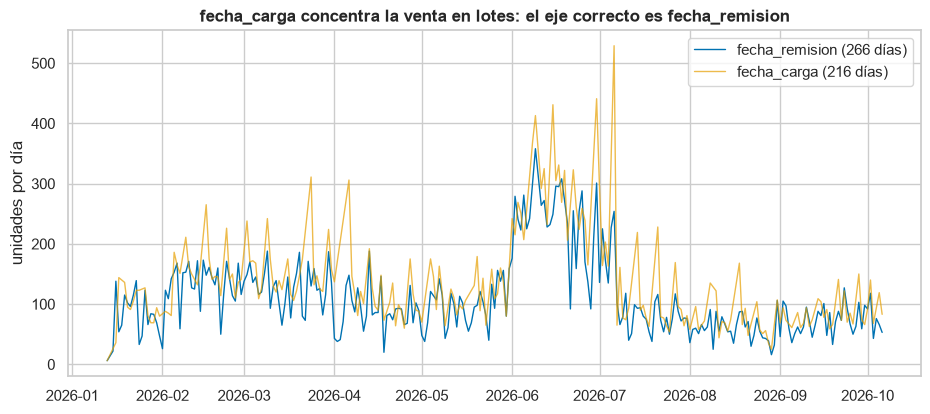

In [16]:
# fecha_carga agrupa días por lote: comparación con fecha_remision (advertencia 1)
d_rem = dem.groupby(dem["fecha_remision"].dt.normalize())["cantidad_total"].sum()
d_car = dem.groupby(dem["fecha_carga"].dt.normalize())["cantidad_total"].sum()
fig, ax = plt.subplots()
ax.plot(d_rem.index, d_rem.values, lw=1, label=f"fecha_remision ({d_rem.size} días)", color=COLOR_CANAL["EFFI"])
ax.plot(d_car.index, d_car.values, lw=1, alpha=.7, label=f"fecha_carga ({d_car.size} días)", color=COLOR_CANAL["DROPI"])
ax.set(title="fecha_carga concentra la venta en lotes: el eje correcto es fecha_remision", ylabel="unidades por día")
ax.legend(); guardar_fig(fig, "3_1_01_fecha_carga_vs_remision"); plt.show()

### 3.2 Preguntas del EDA
Desde aquí se trabaja con la **demanda** definida en §2 (líneas no canceladas, `cantidad_total`, `fecha_remision`).
La última semana (5–6 de octubre) es **parcial** y se marca en las gráficas semanales.

Tablas base que se reutilizan en toda la sección:

In [17]:
dem["fecha"] = dem["fecha_remision"].dt.normalize()
dem["semana"] = inicio_semana(dem["fecha"])
dem["familia"] = np.where(dem["catalogo"].str.upper().str.contains(FAMILIA_COLOMBIA_REGEX, regex=True), "COLOMBIA", "RESTO")

SEMANA_PARCIAL = ultima_semana
semanas = pd.date_range(dem["semana"].min(), dem["semana"].max(), freq=DECISIONES["frecuencia"])

sem_canal = (dem.pivot_table(index="semana", columns="canal", values="cantidad_total", aggfunc="sum")
               .reindex(semanas, fill_value=0).fillna(0))
sem_canal["TOTAL"] = sem_canal.sum(axis=1)
sem_canal["parcial"] = sem_canal.index == SEMANA_PARCIAL

dias = pd.date_range(dem["fecha"].min(), DECISIONES["fecha_corte_datos"], freq="D")
dia_total = dem.groupby("fecha")["cantidad_total"].sum().reindex(dias, fill_value=0)

print(f"{len(semanas)} semanas ({semanas[0].date()} → {semanas[-1].date()}, la última parcial); "
      f"{len(dias)} días calendario, {int((dia_total == 0).sum())} sin venta")
print("Catálogos familia COLOMBIA:", dem.loc[dem.familia == "COLOMBIA", "catalogo"].nunique(),
      f"({dem.loc[dem.familia == 'COLOMBIA', 'cantidad_total'].sum() / dem['cantidad_total'].sum():.1%} de las unidades)")

39 semanas (2026-01-12 → 2026-10-05, la última parcial); 267 días calendario, 1 sin venta
Catálogos familia COLOMBIA: 28 (42.3% de las unidades)


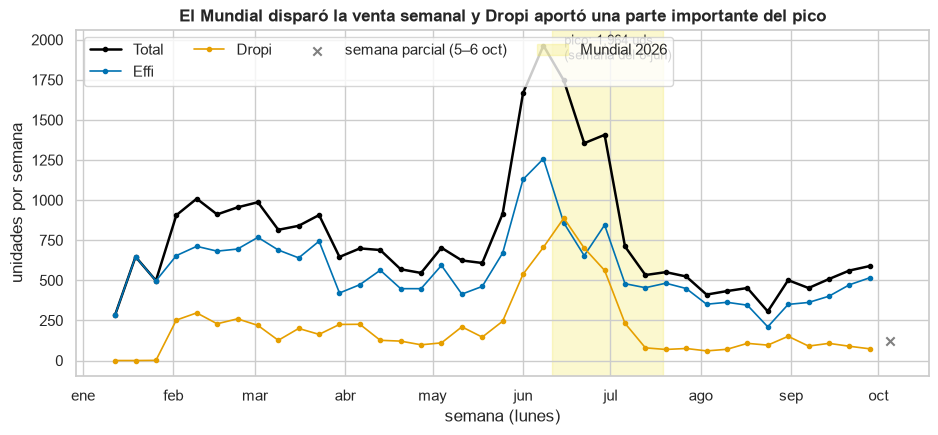

In [18]:
# Serie semanal total y por canal, con banda del Mundial
fig, ax = plt.subplots()
completas = sem_canal[~sem_canal["parcial"]]
for c in ["TOTAL", "EFFI", "DROPI"]:
    ax.plot(completas.index, completas[c], marker="o", ms=3, lw=1.8 if c == "TOTAL" else 1.2,
            color=COLOR_CANAL[c], label=c.capitalize())
ax.scatter([SEMANA_PARCIAL], [sem_canal.loc[SEMANA_PARCIAL, "TOTAL"]], marker="x", color="grey", label="semana parcial (5–6 oct)")
sombrear_mundial(ax)
pico = completas["TOTAL"].idxmax()
ax.annotate(f"pico: {int(completas['TOTAL'].max()):,} uds\n(semana del {pico.day}-{MESES_ES[pico.month - 1]})", xy=(pico, completas["TOTAL"].max()),
            xytext=(15, -10), textcoords="offset points", fontsize=9)
ax.set(title="El Mundial disparó la venta semanal y Dropi aportó una parte importante del pico",
       ylabel="unidades por semana", xlabel="semana (lunes)")
ax.xaxis.set_major_formatter(FMT_MES)
ax.legend(ncol=4, loc="upper left"); guardar_fig(fig, "3_2_01_serie_semanal_canal"); plt.show()

#### Pregunta 1 — ¿Qué tan concentrada está la demanda? (Pareto / ABC)
Clases: **A** = catálogos que acumulan hasta el 80 % del volumen, **B** = hasta el 95 %, **C** = el resto.

,catalogos,unidades,%_catalogos,%_unidades
clase_abc,,,,
A,25,23682,0.031,0.802
B,72,4394,0.090,0.149
C,707,1471,0.879,0.050


Top 10: 61.4% del volumen
Top 15: 71.5% del volumen
Top 20: 76.9% del volumen
Top 30: 82.6% del volumen
Top 50: 89.0% del volumen


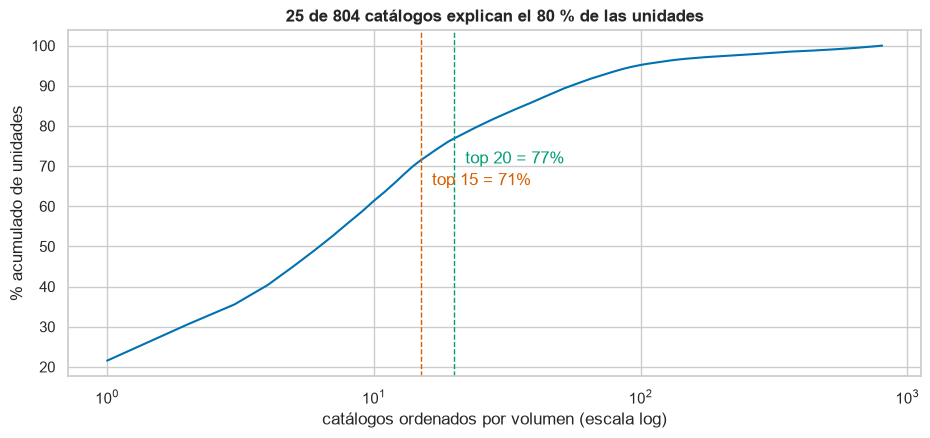

In [19]:
abc = vol_cat.rename("unidades").to_frame()
abc["rank"] = np.arange(1, len(abc) + 1)
abc["%"] = abc["unidades"] / abc["unidades"].sum()
abc["%_acum"] = abc["%"].cumsum()
abc["clase_abc"] = np.select([abc["%_acum"].shift(fill_value=0) < .80, abc["%_acum"].shift(fill_value=0) < .95], ["A", "B"], "C")

resumen_abc = abc.groupby("clase_abc").agg(catalogos=("unidades", "size"), unidades=("unidades", "sum"))
resumen_abc["%_catalogos"] = resumen_abc["catalogos"] / len(abc)
resumen_abc["%_unidades"] = resumen_abc["unidades"] / abc["unidades"].sum()
display(resumen_abc)
for n in [10, 15, 20, 30, 50]:
    print(f"Top {n:>2}: {abc['%'].head(n).sum():.1%} del volumen")

fig, ax = plt.subplots()
ax.plot(abc["rank"], abc["%_acum"] * 100, color=OKABE_ITO[0])
for n, col in [(15, OKABE_ITO[3]), (DECISIONES["top_n_modelados"], OKABE_ITO[2])]:
    ax.axvline(n, ls="--", color=col, lw=1)
    ax.annotate(f"top {n} = {abc['%'].head(n).sum():.0%}", (n, abc["%_acum"].iloc[n - 1] * 100), xytext=(8, -18),
                textcoords="offset points", color=col)
ax.set_xscale("log")
ax.set(title=f"{(abc.clase_abc == 'A').sum()} de {len(abc)} catálogos explican el 80 % de las unidades",
       xlabel="catálogos ordenados por volumen (escala log)", ylabel="% acumulado de unidades")
guardar_fig(fig, "3_2_02_pareto_catalogos"); plt.show()

#### Pregunta 2 — ¿Qué tipo de demanda tiene cada catálogo? (ADI / CV², Syntetos-Boylan-Croston 2005)
- **ADI** = periodos / periodos con demanda; **CV²** = (desviación / media)² de la demanda *cuando hay venta*.
- Umbrales: ADI = 1,32 y CV² = 0,49. Se calcula sobre **semanas completas** desde la primera venta de cada catálogo.
- Catálogos con menos de 2 semanas con venta quedan como *insuficiente*.

In [20]:
ADI_UMBRAL, CV2_UMBRAL = 1.32, 0.49
sem_cat = (dem[dem["semana"] != SEMANA_PARCIAL]
           .groupby(["catalogo", "semana"])["cantidad_total"].sum().unstack(fill_value=0)
           .reindex(columns=semanas[semanas != SEMANA_PARCIAL], fill_value=0))


def clasificar_demanda(serie):
    nz = np.flatnonzero(serie.values)
    activo = serie.values[nz[0]:]                     # desde la primera venta
    positivos = activo[activo > 0]
    adi = len(activo) / len(positivos)
    cv2 = (positivos.std(ddof=0) / positivos.mean()) ** 2 if len(positivos) >= 2 else np.nan
    if len(positivos) < 2:
        tipo = "insuficiente"
    elif adi < ADI_UMBRAL:
        tipo = "suave" if cv2 < CV2_UMBRAL else "errática"
    else:
        tipo = "intermitente" if cv2 < CV2_UMBRAL else "irregular"
    return pd.Series({"semanas_activo": len(activo), "semanas_con_venta": len(positivos), "ADI": adi, "CV2": cv2, "tipo": tipo})


clasif = sem_cat.apply(clasificar_demanda, axis=1)
clasif = clasif.join(abc[["unidades", "rank", "clase_abc"]])
METODO = {"suave": "ETS / ARIMA / ML", "errática": "ML con exógenas", "intermitente": "Croston / SBA",
          "irregular": "SBA / TSB / regla", "insuficiente": "regla (media o cero)"}
clasif["metodo_sugerido"] = clasif["tipo"].map(METODO)

tabla_tipos = clasif.groupby("tipo").agg(catalogos=("unidades", "size"), unidades=("unidades", "sum"))
tabla_tipos["%_unidades"] = tabla_tipos["unidades"] / tabla_tipos["unidades"].sum()
tabla_tipos["metodo_sugerido"] = tabla_tipos.index.map(METODO)
display(tabla_tipos.sort_values("unidades", ascending=False))
print(f"Tipo de demanda del top {DECISIONES['top_n_modelados']}:")
clasif.sort_values("rank").head(DECISIONES["top_n_modelados"])[["rank", "unidades", "ADI", "CV2", "tipo", "clase_abc"]]

,catalogos,unidades,%_unidades,metodo_sugerido
tipo,,,,
errática,19,14966,0.507,ML con exógenas
irregular,44,5439,0.184,SBA / TSB / regla
suave,10,5171,0.175,ETS / ARIMA / ML
intermitente,124,3000,0.102,Croston / SBA
insuficiente,601,963,0.033,regla (media o cero)


Tipo de demanda del top 20:


,rank,unidades,ADI,CV2,tipo,clase_abc
catalogo,,,,,,
CUELLO ALTO COLOMBIA RETRO,1,6366,1.121,1.019,errática,A
CUELLO ALTO COLOMBIA,2,2661,1.152,1.187,errática,A
CUELLO ALTO COLOMBIA ÉLITE,3,1475,1.462,1.523,irregular,A
CUELLO ALTO HONDA REFLECTIVO,4,1431,1.000,0.224,suave,A
CUELLO ALTO YAMAHA REFLECTIVO,5,1384,1.000,0.293,suave,A
CUELLO ALTO RED BULL,6,1179,1.000,0.740,errática,A
COLOMBIA ELITE/CLASICO,7,1041,3.333,0.400,intermitente,A
CUELLO ALTO BMW ESTAMPADO REFLECTIVO,8,960,1.000,0.677,errática,A
CUELLO ALTO SUZUKI REFLECTIVO,9,825,1.000,0.163,suave,A


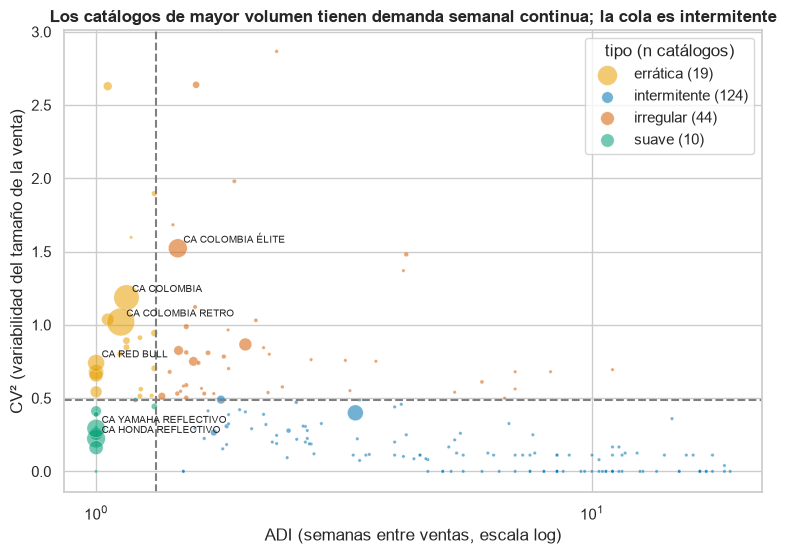

In [21]:
fig, ax = plt.subplots(figsize=(9, 6))
validos = clasif[clasif["tipo"] != "insuficiente"]
colores_tipo = {"suave": OKABE_ITO[2], "errática": OKABE_ITO[1], "intermitente": OKABE_ITO[0], "irregular": OKABE_ITO[3]}
for t, g in validos.groupby("tipo"):
    ax.scatter(g["ADI"], g["CV2"], s=np.clip(g["unidades"] / 8, 6, 400), alpha=.55, color=colores_tipo[t],
               label=f"{t} ({len(g)})", edgecolor="white", lw=.4)
ax.axvline(ADI_UMBRAL, color="grey", ls="--"); ax.axhline(CV2_UMBRAL, color="grey", ls="--")
for _, r in validos.sort_values("rank").head(6).iterrows():
    ax.annotate(r.name.replace("CUELLO ALTO ", "CA "), (r["ADI"], r["CV2"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xscale("log")
ax.set(title="Los catálogos de mayor volumen tienen demanda semanal continua; la cola es intermitente",
       xlabel="ADI (semanas entre ventas, escala log)", ylabel="CV² (variabilidad del tamaño de la venta)")
ax.legend(title="tipo (n catálogos)", loc="upper right"); guardar_fig(fig, "3_2_03_adi_cv2"); plt.show()

#### Pregunta 3 — ¿Hay tendencia o estacionalidad? (STL, ACF/PACF, ADF/KPSS)
Con 9 meses no hay estacionalidad anual estimable. Se revisa:
- **STL robusta sobre la serie diaria** (periodo 7) para separar tendencia, patrón semanal y residuo (el Mundial debería aparecer en tendencia/residuo).
- **ACF/PACF y pruebas de raíz unitaria sobre la serie semanal** (semanas completas).

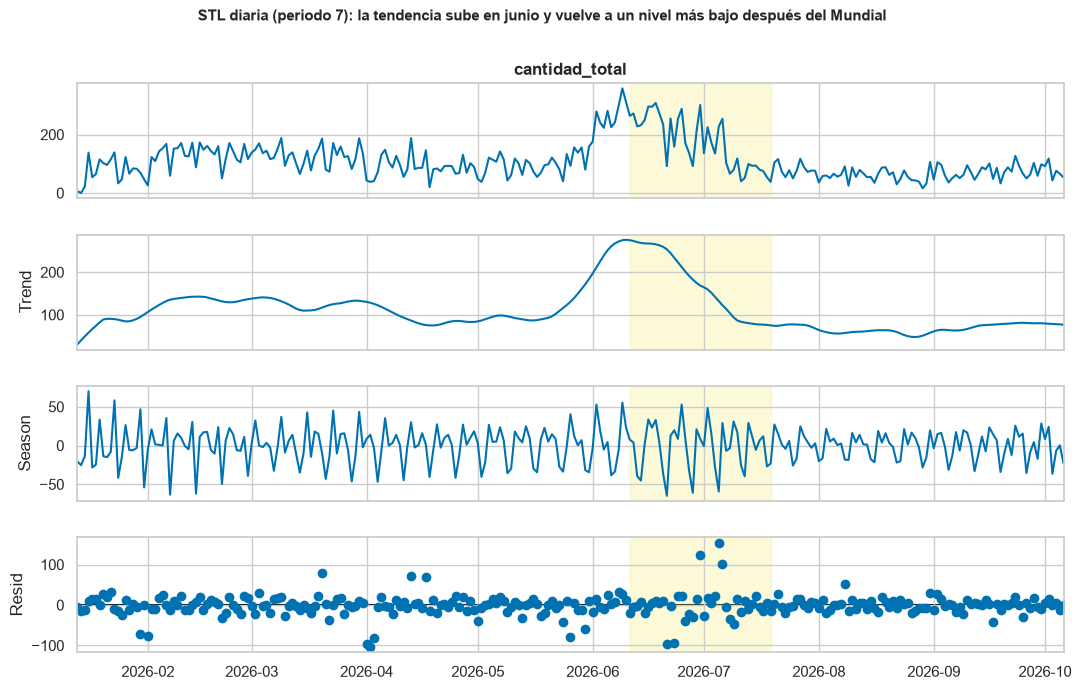

Fuerza de tendencia: 0.81 | fuerza del patrón semanal (día de la semana): 0.45  (FPP3 §4.3)


In [22]:
stl_total = STL(dia_total, period=7, robust=True).fit()
fig = stl_total.plot(); fig.set_size_inches(11, 7)
fig.suptitle("STL diaria (periodo 7): la tendencia sube en junio y vuelve a un nivel más bajo después del Mundial",
             fontsize=11, fontweight="bold", y=1.02)
for a in fig.axes:
    sombrear_mundial(a, alpha=.2, etiqueta=False)
guardar_fig(fig, "3_2_04_stl_diaria_total"); plt.show()

fuerza_tend = max(0, 1 - stl_total.resid.var() / (stl_total.trend + stl_total.resid).var())
fuerza_estac = max(0, 1 - stl_total.resid.var() / (stl_total.seasonal + stl_total.resid).var())
print(f"Fuerza de tendencia: {fuerza_tend:.2f} | fuerza del patrón semanal (día de la semana): {fuerza_estac:.2f}  (FPP3 §4.3)")

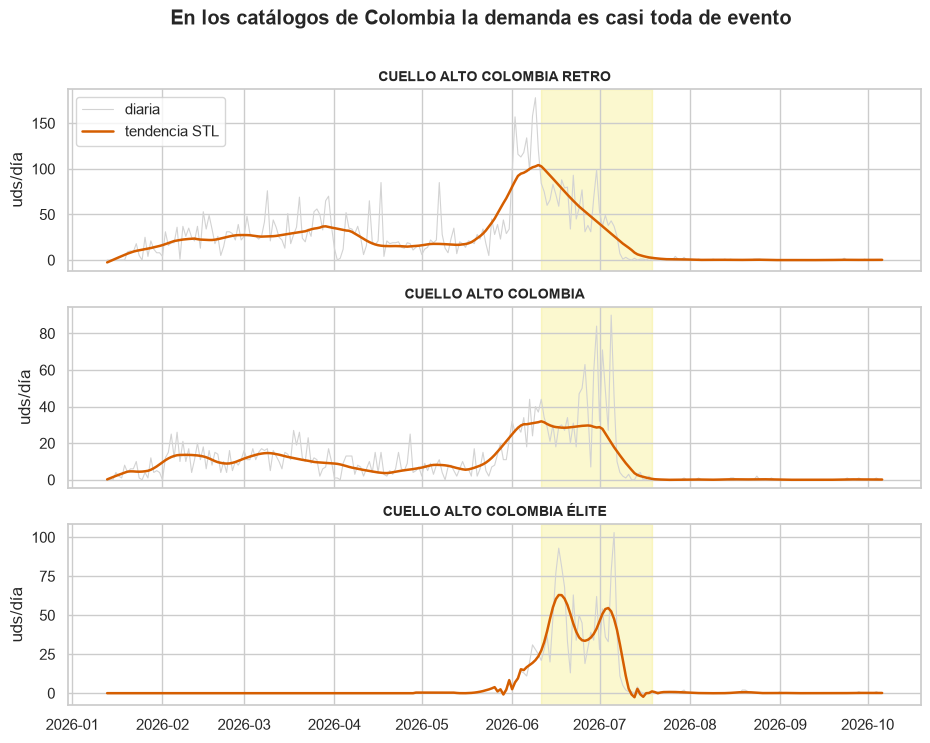

In [23]:
# STL de los 3 catálogos top (serie diaria)
top3 = abc.index[:3]
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, cat in zip(axes, top3):
    s = dem[dem["catalogo"] == cat].groupby("fecha")["cantidad_total"].sum().reindex(dias, fill_value=0)
    r = STL(s, period=7, robust=True).fit()
    ax.plot(s.index, s, color="lightgrey", lw=.8, label="diaria")
    ax.plot(r.trend.index, r.trend, color=OKABE_ITO[3], lw=1.8, label="tendencia STL")
    sombrear_mundial(ax, etiqueta=False)
    ax.set_title(cat, fontsize=10); ax.set_ylabel("uds/día")
axes[0].legend(loc="upper left")
fig.suptitle("En los catálogos de Colombia la demanda es casi toda de evento", fontweight="bold")
guardar_fig(fig, "3_2_05_stl_top3"); plt.show()

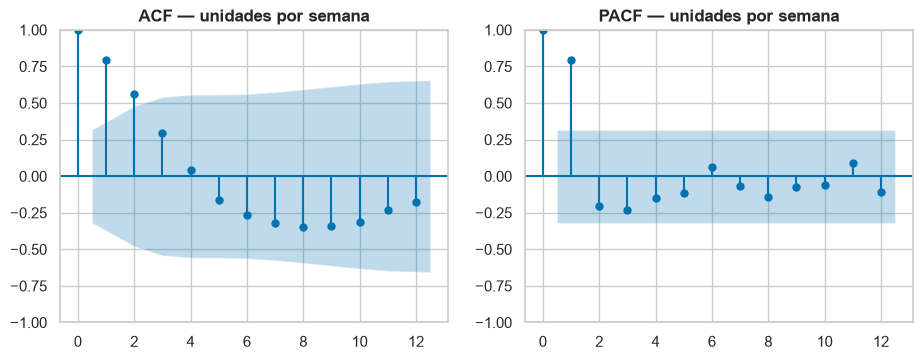

,serie,n,ADF p-valor,KPSS p-valor,lectura
0,semanal total,38,0.188,0.100,no concluyente
1,semanal total (1.ª diferencia),37,0.000,0.100,estacionaria
2,diaria total,267,0.137,0.100,no concluyente


In [24]:
serie_sem = completas["TOTAL"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
plot_acf(serie_sem, lags=12, ax=axes[0]); axes[0].set_title("ACF — unidades por semana")
plot_pacf(serie_sem, lags=12, ax=axes[1], method="ywm"); axes[1].set_title("PACF — unidades por semana")
guardar_fig(fig, "3_2_06_acf_pacf_semanal"); plt.show()


def pruebas_estacionariedad(s, nombre):
    adf_p = adfuller(s, autolag="AIC")[1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_p = kpss(s, regression="c", nlags="auto")[1]
    return {"serie": nombre, "n": len(s), "ADF p-valor": adf_p, "KPSS p-valor": kpss_p,
            "lectura": ("estacionaria" if adf_p < .05 and kpss_p > .05 else
                        "no estacionaria" if adf_p >= .05 and kpss_p <= .05 else "no concluyente")}


pd.DataFrame([pruebas_estacionariedad(serie_sem, "semanal total"),
              pruebas_estacionariedad(serie_sem.diff().dropna(), "semanal total (1.ª diferencia)"),
              pruebas_estacionariedad(dia_total, "diaria total")])

#### Pregunta 4 — ¿Cuánto pesó el Mundial? (familia Colombia vs. resto)
Periodos: **antes** (< 11-jun), **durante** (11-jun a 19-jul) y **después** (> 19-jul). Se compara el promedio de unidades por semana completa.

familia,COLOMBIA,RESTO,semanas
periodo,,,
1_antes,318.900,463.290,21.000
2_durante,958.500,327.500,6.000
3_despues,4.270,476.450,11.000
durante / antes,3.010,0.710,0.290
despues / antes,0.010,1.030,0.520


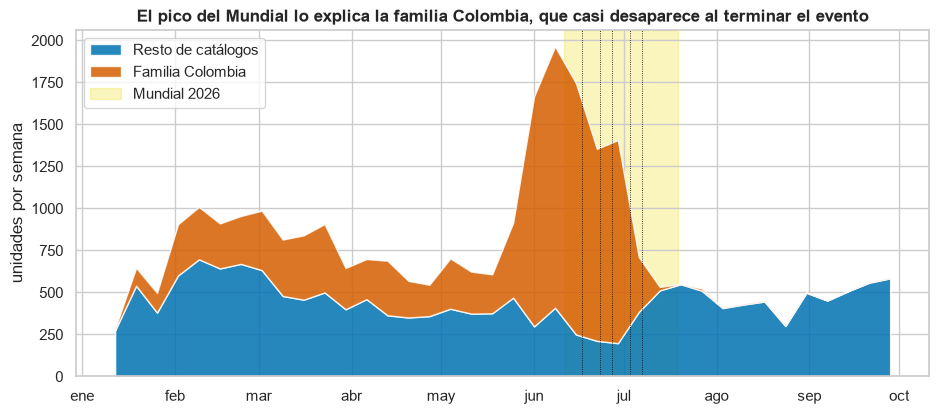

In [25]:
def periodo_evento(fechas):
    return np.select([fechas < EVENTOS["mundial_inicio"], fechas <= EVENTOS["mundial_fin"]], ["1_antes", "2_durante"], "3_despues")


sem_fam = (dem[dem["semana"] != SEMANA_PARCIAL].pivot_table(index="semana", columns="familia", values="cantidad_total", aggfunc="sum")
             .reindex(semanas[semanas != SEMANA_PARCIAL], fill_value=0).fillna(0))
# Periodo de la semana según su día central (jueves)
sem_fam["periodo"] = periodo_evento(sem_fam.index + pd.Timedelta(days=3))
impacto = sem_fam.groupby("periodo")[["COLOMBIA", "RESTO"]].mean()
impacto["semanas"] = sem_fam.groupby("periodo").size().astype(float)
impacto.loc["durante / antes"] = impacto.loc["2_durante"] / impacto.loc["1_antes"]
impacto.loc["despues / antes"] = impacto.loc["3_despues"] / impacto.loc["1_antes"]
display(impacto.round(2))

fig, ax = plt.subplots()
ax.stackplot(sem_fam.index, sem_fam["RESTO"], sem_fam["COLOMBIA"], colors=[COLOR_FAMILIA["RESTO"], COLOR_FAMILIA["COLOMBIA"]],
             labels=["Resto de catálogos", "Familia Colombia"], alpha=.85)
sombrear_mundial(ax, alpha=.35)
for f in EVENTOS_PARTIDOS["fecha"]:
    ax.axvline(f, color="black", lw=.6, ls=":")
ax.set(title="El pico del Mundial lo explica la familia Colombia, que casi desaparece al terminar el evento",
       ylabel="unidades por semana")
ax.xaxis.set_major_formatter(FMT_MES)
ax.legend(loc="upper left"); guardar_fig(fig, "3_2_07_mundial_familia"); plt.show()

#### Pregunta 5 — ¿Hay patrón semanal o quincenal?

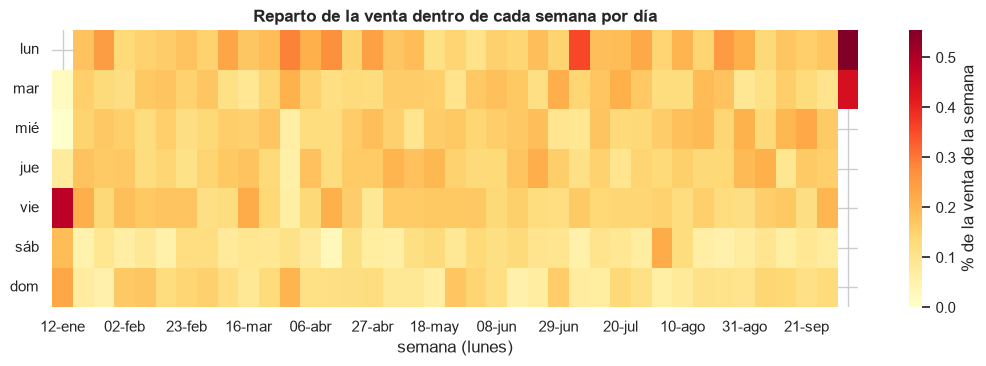

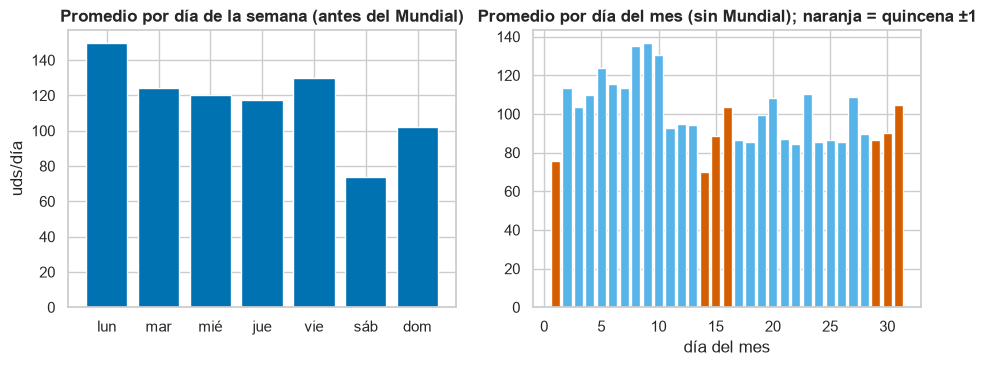

Promedio uds/día (sin Mundial) en días de quincena ±1: 87.5 | resto de días: 103.3


In [26]:
DIAS_ES = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
dd = dia_total.to_frame("unidades")
dd["dia_semana"] = dd.index.day_of_week
dd["semana"] = inicio_semana(dd.index.to_series()).values
dd["dia_mes"] = dd.index.day
dd["quincena"] = dd["dia_mes"].isin([14, 15, 16, 29, 30, 31, 1])   # ±1 día de los pagos del 15 y del 30

heat = dd.pivot_table(index="dia_semana", columns="semana", values="unidades", aggfunc="sum")
heat_rel = heat / heat.sum()                                       # participación del día dentro de su semana
fig, ax = plt.subplots(figsize=(13, 3.6))
sns.heatmap(heat_rel, cmap="YlOrRd", ax=ax, cbar_kws={"label": "% de la venta de la semana"},
            xticklabels=[f"{d.day:02d}-{MESES_ES[d.month - 1]}" if i % 3 == 0 else "" for i, d in enumerate(heat.columns)])
ax.set_yticklabels(DIAS_ES, rotation=0)
ax.set(title="Reparto de la venta dentro de cada semana por día", xlabel="semana (lunes)", ylabel="")
guardar_fig(fig, "3_2_08_heatmap_dia_semana"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
prom_dia = dd[dd.index < EVENTOS["mundial_inicio"]].groupby("dia_semana")["unidades"].mean()
axes[0].bar(DIAS_ES, prom_dia, color=OKABE_ITO[0]); axes[0].set(title="Promedio por día de la semana (antes del Mundial)", ylabel="uds/día")
prom_mes = dd[(dd.index < EVENTOS["mundial_inicio"]) | (dd.index > EVENTOS["mundial_fin"])].groupby("dia_mes")["unidades"].mean()
axes[1].bar(prom_mes.index, prom_mes, color=[OKABE_ITO[3] if d in (14, 15, 16, 29, 30, 31, 1) else OKABE_ITO[5] for d in prom_mes.index])
axes[1].set(title="Promedio por día del mes (sin Mundial); naranja = quincena ±1", xlabel="día del mes")
guardar_fig(fig, "3_2_09_dia_semana_dia_mes"); plt.show()

sin_mundial = dd[(dd.index < EVENTOS["mundial_inicio"]) | (dd.index > EVENTOS["mundial_fin"])]
print("Promedio uds/día (sin Mundial) en días de quincena ±1:", round(sin_mundial.loc[sin_mundial.quincena, "unidades"].mean(), 1),
      "| resto de días:", round(sin_mundial.loc[~sin_mundial.quincena, "unidades"].mean(), 1))

#### Pregunta 6 — ¿Cómo se comportan los canales?

canal,EFFI,DROPI,%_dropi
periodo,,,
1_antes,601.620,180.570,0.230
2_durante,758.000,528.000,0.410
3_despues,391.000,89.730,0.190


Primera venta Dropi: 2026-02-01


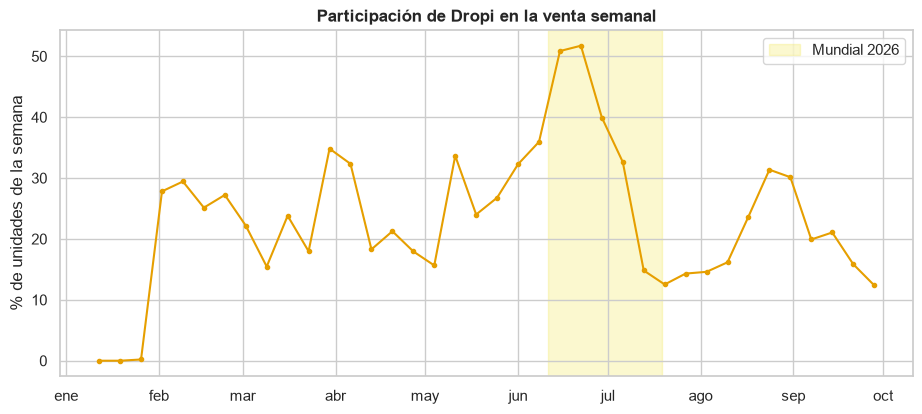

canal,DROPI,EFFI,%_dropi
catalogo,,,
CUELLO ALTO COLOMBIA ÉLITE,1201,274,0.814
CUELLO ALTO BMW ESTAMPADO REFLECTIVO,528,432,0.550
CUELLO ALTO SUZUKI REFLECTIVO,376,449,0.456
CUELLO ALTO YAMAHA REFLECTIVO,498,886,0.360
BUZO COLOMBIA VISITANTE,103,202,0.338
RED BULL,208,468,0.308
CUELLO ALTO COLOMBIA,766,1895,0.288
CUELLO ALTO RED BULL,333,846,0.282
CUELLO ALLTO PULSAR REFLECTIVO,180,483,0.271


In [27]:
pct_dropi = (completas["DROPI"] / completas["TOTAL"]).rename("%_dropi")
canal_periodo = completas.assign(periodo=periodo_evento(completas.index + pd.Timedelta(days=3))).groupby("periodo")[["EFFI", "DROPI"]].mean()
canal_periodo["%_dropi"] = canal_periodo["DROPI"] / canal_periodo.sum(axis=1)
display(canal_periodo.round(2))
primera_dropi = dem.loc[dem.canal == "DROPI", "fecha"].min()
print("Primera venta Dropi:", primera_dropi.date())

fig, ax = plt.subplots()
ax.plot(pct_dropi.index, pct_dropi * 100, marker="o", ms=3, color=COLOR_CANAL["DROPI"])
sombrear_mundial(ax)
ax.set(title="Participación de Dropi en la venta semanal", ylabel="% de unidades de la semana")
ax.xaxis.set_major_formatter(FMT_MES); ax.legend()
guardar_fig(fig, "3_2_10_participacion_dropi"); plt.show()

# ¿Los catálogos top se venden por canales distintos?
mix_canal_top = (dem[dem.catalogo.isin(abc.index[:DECISIONES["top_n_modelados"]])]
                 .pivot_table(index="catalogo", columns="canal", values="cantidad_total", aggfunc="sum", fill_value=0))
mix_canal_top["%_dropi"] = mix_canal_top["DROPI"] / mix_canal_top.sum(axis=1)
mix_canal_top.sort_values("%_dropi", ascending=False)

#### Pregunta 7 — ¿Cómo se reparte talla y color dentro de cada catálogo? ¿Es estable?
Estabilidad medida como la **distancia de variación total** (½ Σ |p_mes − p_total|) entre la mezcla de tallas de cada mes y la del catálogo completo:
0 = idéntica, 1 = totalmente distinta. Base de la desagregación *top-down* (§5.5).

In [28]:
# Se usa la talla estandarizada (talla_std); el color viene limpio
dem["color"] = dem["color"].fillna("SIN_COLOR").astype(str)
ORDEN_TALLAS = [t for t in SIGLAS_TALLA + ["AMBIGUA", "SIN_TALLA"] if t in set(dem["talla_std"])]
dem["mes"] = dem["fecha"].dt.to_period("M")


def estabilidad_mezcla(df, col, min_uds_mes=30):
    tot = df.groupby(col)["cantidad_total"].sum() / df["cantidad_total"].sum()
    filas = []
    for m, g in df.groupby("mes"):
        if g["cantidad_total"].sum() < min_uds_mes:
            continue
        p = g.groupby(col)["cantidad_total"].sum() / g["cantidad_total"].sum()
        filas.append(0.5 * (p.reindex(tot.index, fill_value=0) - tot).abs().sum())
    return np.mean(filas) if filas else np.nan, len(filas)


estab = []
for cat in abc.index[:DECISIONES["top_n_modelados"]]:
    g = dem[dem.catalogo == cat]
    tv_t, n_t = estabilidad_mezcla(g, "talla_std")
    tv_c, _ = estabilidad_mezcla(g, "color")
    estab.append({"catalogo": cat, "unidades": g["cantidad_total"].sum(), "tallas": g.talla_std.nunique(), "colores": g.color.nunique(),
                  "combos_talla_color": g.groupby(["talla_std", "color"]).ngroups, "meses_evaluados": n_t,
                  "TV_talla": tv_t, "TV_color": tv_c})
estab = pd.DataFrame(estab).set_index("catalogo")
estab

,unidades,tallas,colores,combos_talla_color,meses_evaluados,TV_talla,TV_color
catalogo,,,,,,,
CUELLO ALTO COLOMBIA RETRO,6366,14,4,43,7,0.046,0.076
CUELLO ALTO COLOMBIA,2661,12,5,43,7,0.065,0.201
CUELLO ALTO COLOMBIA ÉLITE,1475,9,4,29,2,0.044,0.031
CUELLO ALTO HONDA REFLECTIVO,1431,9,6,39,10,0.083,0.077
CUELLO ALTO YAMAHA REFLECTIVO,1384,8,5,35,10,0.102,0.067
CUELLO ALTO RED BULL,1179,8,5,35,7,0.090,0.099
COLOMBIA ELITE/CLASICO,1041,9,4,30,2,0.047,0.065
CUELLO ALTO BMW ESTAMPADO REFLECTIVO,960,8,5,35,7,0.072,0.110
CUELLO ALTO SUZUKI REFLECTIVO,825,7,6,33,8,0.089,0.055


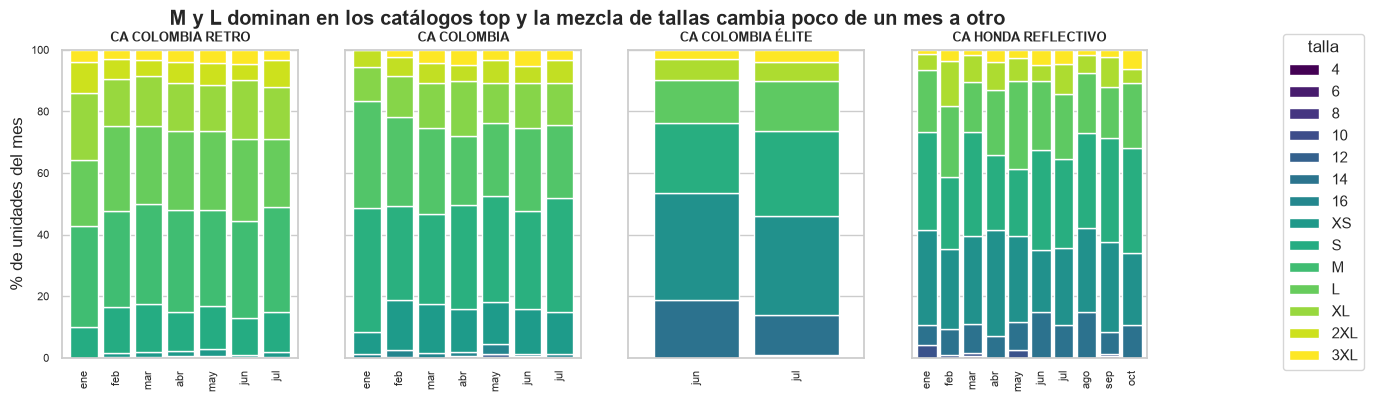

In [29]:
cats = abc.index[:4]
fig, axes = plt.subplots(1, 4, figsize=(14, 4), sharey=True)
for ax, cat in zip(axes, cats):
    g = dem[dem.catalogo == cat]
    t = g.pivot_table(index="mes", columns="talla_std", values="cantidad_total", aggfunc="sum", fill_value=0)
    t = t[[c for c in ORDEN_TALLAS if c in t.columns]]
    t = t[t.sum(axis=1) >= 30]
    t.index = [MESES_ES[p.month - 1] for p in t.index]
    (t.div(t.sum(axis=1), axis=0) * 100).plot(kind="bar", stacked=True, ax=ax, width=.85, legend=False,
                                              colormap="viridis", rot=90, fontsize=8)
    ax.set_title(cat.replace("CUELLO ALTO ", "CA "), fontsize=9); ax.set_xlabel("")
axes[0].set_ylabel("% de unidades del mes")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="talla", loc="center right", bbox_to_anchor=(1.06, .5))
fig.suptitle("M y L dominan en los catálogos top y la mezcla de tallas cambia poco de un mes a otro", fontweight="bold")
guardar_fig(fig, "3_2_11_mezcla_tallas_top4"); plt.show()

#### Pregunta 8 — ¿Nacen y mueren catálogos?
Un catálogo se considera **inactivo** si no vende en las últimas 4 semanas completas.

,catalogos,unidades
estado,,
activo,189,24266
inactivo,615,5281


,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
nuevos,118,102,118,79,91,77,72,54,79,14
última venta (inactivos),44,68,102,74,89,79,73,69,17,0


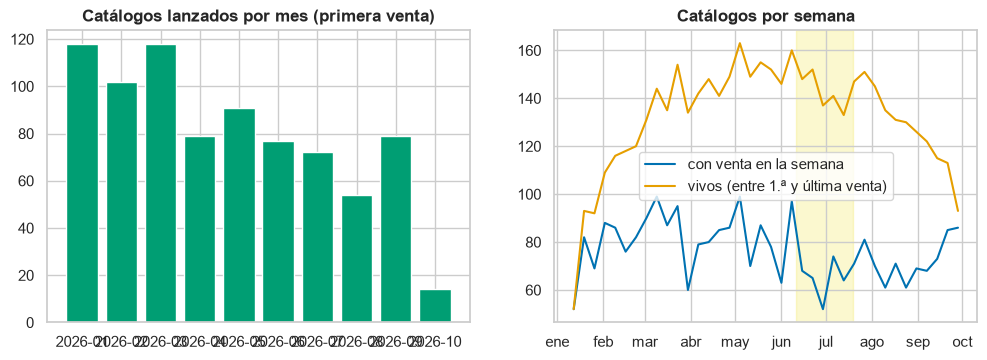

Catálogos con 1 sola semana de vida: 618 de 804


In [30]:
vida = dem.groupby("catalogo").agg(primera=("fecha", "min"), ultima=("fecha", "max"), unidades=("cantidad_total", "sum"))
vida["semanas_vida"] = ((vida["ultima"] - vida["primera"]).dt.days // 7) + 1
corte_inactivo = SEMANA_PARCIAL - pd.Timedelta(weeks=4)
vida["estado"] = np.where(vida["ultima"] >= corte_inactivo, "activo", "inactivo")
vida["mes_lanzamiento"] = vida["primera"].dt.to_period("M")
vida = vida.join(clasif[["tipo", "clase_abc"]])

display(vida.groupby("estado").agg(catalogos=("unidades", "size"), unidades=("unidades", "sum")))
nacen = vida.groupby("mes_lanzamiento").size().rename("nuevos")
mueren = vida[vida.estado == "inactivo"].groupby(vida["ultima"].dt.to_period("M")).size().rename("última venta (inactivos)")
display(pd.concat([nacen, mueren], axis=1).fillna(0).astype(int).T)

activos_sem = pd.Series({s: ((vida["primera"] <= s + pd.Timedelta(days=6)) & (vida["ultima"] >= s)).sum() for s in semanas})
con_venta_sem = dem.groupby("semana")["catalogo"].nunique().reindex(semanas, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(nacen.index.astype(str), nacen.values, color=OKABE_ITO[2]); axes[0].set(title="Catálogos lanzados por mes (primera venta)")
axes[1].plot(con_venta_sem[:-1].index, con_venta_sem[:-1], color=OKABE_ITO[0], label="con venta en la semana")
axes[1].plot(activos_sem[:-1].index, activos_sem[:-1], color=OKABE_ITO[1], label="vivos (entre 1.ª y última venta)")
sombrear_mundial(axes[1], etiqueta=False); axes[1].legend(); axes[1].set(title="Catálogos por semana")
axes[1].xaxis.set_major_formatter(FMT_MES)
guardar_fig(fig, "3_2_12_ciclo_vida_catalogos"); plt.show()
print(f"Catálogos con 1 sola semana de vida: {(vida.semanas_vida == 1).sum()} de {len(vida)}")

### 3.3 Calendario de eventos (variables exógenas para §4)
Fuentes verificadas en prensa deportiva (Vistazo, WinSports, Fox Sports, RPP, Portafolio) y calendario de festivos de Colombia (Ley 51 de 1983, *Ley Emiliani*).
Colombia jugó **5 partidos**: 3 de grupo (K), dieciseisavos y octavos (eliminada por Suiza en penales el 7-jul).

| Evento | Fecha | Nota |
|---|---|---|
| Colombia 3-1 Uzbekistán | 17-jun | Grupo K, jornada 1 |
| Colombia 1-0 RD Congo | 23-jun | Grupo K, jornada 2, Guadalajara (*verificar fecha en FIFA.com*) |
| Colombia 0-0 Portugal | 27-jun | Grupo K, jornada 3, Miami — Colombia 1.ª del grupo |
| Colombia 1-0 Ghana | 3-jul | Dieciseisavos, Kansas City |
| Suiza 0-0 Colombia (4-3 pen.) | 7-jul | Octavos, Vancouver — eliminación |

In [31]:
FESTIVOS_2026 = pd.to_datetime([
    "2026-01-01", "2026-01-12", "2026-03-23", "2026-04-02", "2026-04-03", "2026-05-01", "2026-05-18", "2026-06-08",
    "2026-06-15", "2026-06-29", "2026-07-20", "2026-08-07", "2026-08-17", "2026-10-12", "2026-11-02", "2026-11-16",
    "2026-12-08", "2026-12-25"])
FECHAS_COMERCIALES = pd.DataFrame({
    "fecha": pd.to_datetime(["2026-05-10", "2026-06-21", "2026-09-19", "2026-11-27", "2026-12-24"]),
    "evento": ["Día de la Madre", "Día del Padre", "Amor y Amistad", "Black Friday", "Nochebuena"],
    "tipo": "comercial",
})
PRIMAS = pd.to_datetime(["2026-06-30", "2026-12-20"])

# Calendario diario desde el inicio de los datos hasta el final del horizonte extendido (8 semanas después del corte)
fin_horizonte = SEMANA_PARCIAL + pd.Timedelta(weeks=DECISIONES["horizonte_extendido"] + 1) - pd.Timedelta(days=1)
cal = pd.DataFrame(index=pd.date_range("2026-01-12", fin_horizonte, freq="D"))
cal.index.name = "fecha"
cal["semana"] = inicio_semana(cal.index.to_series()).values
cal["festivo"] = cal.index.isin(FESTIVOS_2026).astype(int)
cal["mundial"] = ((cal.index >= EVENTOS["mundial_inicio"]) & (cal.index <= EVENTOS["mundial_fin"])).astype(int)
cal["partido_colombia"] = cal.index.isin(EVENTOS_PARTIDOS["fecha"]).astype(int)
cal["fecha_comercial"] = cal.index.isin(FECHAS_COMERCIALES["fecha"]).astype(int)
cal["quincena"] = cal.index.day.isin([15, 30]).astype(int) | ((cal.index.month == 2) & (cal.index.day == 28)).astype(int)
cal["prima"] = cal.index.isin(PRIMAS).astype(int)
cal["con_historia"] = (cal.index <= DECISIONES["fecha_corte_datos"]).astype(int)

cal_sem = cal.groupby("semana").agg(n_festivos=("festivo", "sum"), dias_mundial=("mundial", "sum"),
                                    n_partidos_colombia=("partido_colombia", "sum"), fecha_comercial=("fecha_comercial", "max"),
                                    quincena=("quincena", "max"), prima=("prima", "max"), con_historia=("con_historia", "min"))
cal_sem["semana_mundial"] = (cal_sem["dias_mundial"] > 0).astype(int)
cal.to_csv(RUTAS["procesado"] / "3_calendario_eventos_diario.csv")
cal_sem.to_csv(RUTAS["procesado"] / "3_calendario_eventos_semanal.csv")
print(f"Calendario {cal.index.min().date()} → {cal.index.max().date()} guardado en procesado/")
cal_sem[(cal_sem.semana_mundial == 1) | (cal_sem.fecha_comercial == 1) | (cal_sem.con_historia == 0)]

Calendario 2026-01-12 → 2026-12-06 guardado en procesado/


,n_festivos,dias_mundial,n_partidos_colombia,fecha_comercial,quincena,prima,con_historia,semana_mundial
semana,,,,,,,,
2026-05-04,0,0,0,1,0,0,1,0
2026-06-08,1,4,0,0,0,0,1,1
2026-06-15,1,7,1,1,1,0,1,1
2026-06-22,0,7,2,0,0,0,1,1
2026-06-29,1,7,1,0,1,1,1,1
2026-07-06,0,7,1,0,0,0,1,1
2026-07-13,0,7,0,0,1,0,1,1
2026-09-14,0,0,0,1,1,0,1,0
2026-10-05,0,0,0,0,0,0,0,0


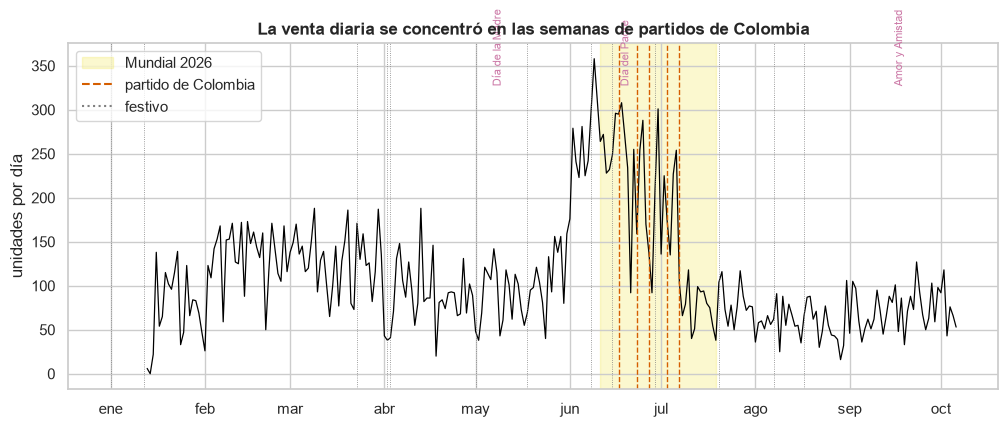

,partido,uds_dia_partido,uds_dia_previo,prom_±3_dias
0,COL vs UZB (3-1),248,250,223.333
1,COL vs COD (1-0),136,221,183.167
2,COL vs POR (0-0),112,142,184.833
3,COL vs GHA (1-0) 16avos,148,176,180.167
4,"SUI vs COL (0-0, 4-3 pen) 8vos",78,199,95.500


In [32]:
# Serie diaria con partidos de Colombia, festivos y fechas comerciales
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(dia_total.index, dia_total, lw=.9, color=COLOR_CANAL["TOTAL"])
sombrear_mundial(ax)
for f in EVENTOS_PARTIDOS["fecha"]:
    ax.axvline(f, color=COLOR_FAMILIA["COLOMBIA"], lw=1, ls="--")
for f in FESTIVOS_2026[FESTIVOS_2026 <= DECISIONES["fecha_corte_datos"]]:
    ax.axvline(f, color="grey", lw=.6, ls=":")
for _, r in FECHAS_COMERCIALES[FECHAS_COMERCIALES.fecha <= DECISIONES["fecha_corte_datos"]].iterrows():
    ax.annotate(r["evento"], (r["fecha"], dia_total.max() * .92), rotation=90, fontsize=8, ha="right", color=OKABE_ITO[4])
ax.plot([], [], color=COLOR_FAMILIA["COLOMBIA"], ls="--", label="partido de Colombia")
ax.plot([], [], color="grey", ls=":", label="festivo")
ax.set(title="La venta diaria se concentró en las semanas de partidos de Colombia", ylabel="unidades por día")
ax.xaxis.set_major_formatter(FMT_MES); ax.legend(loc="upper left")
guardar_fig(fig, "3_3_01_calendario_eventos"); plt.show()

# Efecto de los días de partido: venta de la familia Colombia en el día del partido vs. los ±3 días
col_dia = dem[dem.familia == "COLOMBIA"].groupby("fecha")["cantidad_total"].sum().reindex(dias, fill_value=0)
filas = []
for _, r in EVENTOS_PARTIDOS.iterrows():
    v = col_dia.loc[r.fecha - pd.Timedelta(days=3): r.fecha + pd.Timedelta(days=3)]
    filas.append({"partido": r.evento, "uds_dia_partido": col_dia.get(r.fecha, 0), "uds_dia_previo": col_dia.get(r.fecha - pd.Timedelta(days=1), 0),
                  "prom_±3_dias": v.drop(r.fecha, errors="ignore").mean()})
pd.DataFrame(filas)

> ⚠️ **Limitación del horizonte:** el pronóstico arranca después del 6-oct y cubre **Black Friday (27-nov), la prima de diciembre y Navidad**,
> temporadas **sin historia en los datos** (`con_historia = 0` en el calendario). Debe declararse en la *model card* y sugerir ajuste por criterio experto.

### 3.4 Exportación de tablas para las siguientes fases
Todas en `procesado/` (CSV, separador coma, UTF-8). Los nombres de catálogo **aún no están normalizados** (decisión de §4).

In [33]:
exportar = {
    "3_demanda_diaria_catalogo_canal.csv": dem.groupby(["fecha", "catalogo", "canal"], as_index=False)["cantidad_total"].sum(),
    "3_demanda_semanal_catalogo.csv": dem.groupby(["semana", "catalogo"], as_index=False)["cantidad_total"].sum()
                                          .assign(semana_parcial=lambda d: d["semana"] == SEMANA_PARCIAL),
    "3_demanda_semanal_catalogo_talla_color.csv": dem.groupby(["semana", "catalogo", "talla_std", "color"], as_index=False)["cantidad_total"].sum(),
    "3_referencias_base.csv": tabla_ref.reset_index(),
    "3_serie_semanal_canal.csv": sem_canal.reset_index(names="semana"),
    "3_clasificacion_catalogos.csv": clasif.join(vida[["primera", "ultima", "semanas_vida", "estado"]])
                                          .assign(familia=lambda d: np.where(d.index.str.upper().str.contains(FAMILIA_COLOMBIA_REGEX), "COLOMBIA", "RESTO"))
                                          .reset_index(names="catalogo"),
    "3_estabilidad_mezcla_top.csv": estab.reset_index(),
    "3_cuadre_cifras_control.csv": cuadre.reset_index(names="cifra"),
}
for nombre, df in exportar.items():
    df.to_csv(RUTAS["procesado"] / nombre, index=False, encoding="utf-8")
    print(f"{nombre:<48} {len(df):>7,} filas")

3_demanda_diaria_catalogo_canal.csv                8,139 filas
3_demanda_semanal_catalogo.csv                     2,948 filas
3_demanda_semanal_catalogo_talla_color.csv        11,499 filas
3_referencias_base.csv                                33 filas
3_serie_semanal_canal.csv                             39 filas
3_clasificacion_catalogos.csv                        798 filas
3_estabilidad_mezcla_top.csv                          20 filas
3_cuadre_cifras_control.csv                           12 filas


### 3.5 Hallazgos del EDA (para redactar con palabras propias)
La celda siguiente imprime las cifras clave calculadas arriba, para que el texto del informe y del póster salga de los datos.

In [34]:
top_n = DECISIONES["top_n_modelados"]
h = {
    "unidades de demanda (sin canceladas)": int(dem["cantidad_total"].sum()),
    "semanas completas": int((~sem_canal["parcial"]).sum()),
    f"% volumen top 15 / top {top_n}": f"{abc['%'].head(15).sum():.1%} / {abc['%'].head(top_n).sum():.1%}",
    "catálogos clase A (80 %)": int((abc.clase_abc == "A").sum()),
    "tipos ADI/CV² en el top": clasif.sort_values("rank").head(top_n)["tipo"].value_counts().to_dict(),
    "tipos ADI/CV² en toda la base": clasif["tipo"].value_counts().to_dict(),
    "familia Colombia: semana prom. durante / antes": round(impacto.loc["durante / antes", "COLOMBIA"], 2),
    "resto: semana prom. durante / antes": round(impacto.loc["durante / antes", "RESTO"], 2),
    "familia Colombia: semana prom. después / antes": round(impacto.loc["despues / antes", "COLOMBIA"], 2),
    "% Dropi antes / durante / después": canal_periodo["%_dropi"].round(3).to_dict(),
    "TV talla media en el top (0 = estable)": round(estab["TV_talla"].mean(), 3),
    "catálogos inactivos (sin venta 4 semanas)": int((vida.estado == "inactivo").sum()),
    "fuerza tendencia / patrón semanal (STL diaria)": (round(fuerza_tend, 2), round(fuerza_estac, 2)),
}
for k, v in h.items():
    print(f"- {k}: {v}")
h3 = h      # copia con nombre propio para §8.4 (cifras_clave.json)

- unidades de demanda (sin canceladas): 29549
- semanas completas: 38
- % volumen top 15 / top 20: 71.5% / 76.9%
- catálogos clase A (80 %): 25
- tipos ADI/CV² en el top: {'errática': 8, 'irregular': 5, 'suave': 5, 'intermitente': 2}
- tipos ADI/CV² en toda la base: {'insuficiente': 601, 'intermitente': 124, 'irregular': 44, 'errática': 19, 'suave': 10}
- familia Colombia: semana prom. durante / antes: 3.01
- resto: semana prom. durante / antes: 0.71
- familia Colombia: semana prom. después / antes: 0.01
- % Dropi antes / durante / después: {'1_antes': 0.231, '2_durante': 0.411, '3_despues': 0.187}
- TV talla media en el top (0 = estable): 0.09
- catálogos inactivos (sin venta 4 semanas): 615
- fuerza tendencia / patrón semanal (STL diaria): (np.float64(0.81), np.float64(0.45))


---
## 4. Preparación de datos e ingeniería de variables (CRISP-DM: *data preparation*)

Esta sección convierte la demanda limpia de §3 en las tablas que usan el modelado (§5), la validación (§6) y el pronóstico (§8).

| Producto | Variable en memoria | Archivo |
|---|---|---|
| Demanda línea a línea con nombres normalizados, tela, género y talla | `prep` | — |
| Ficha maestra de catálogos (atributos estáticos, segmento, clúster) | `maestro` | `procesado/4_maestro_catalogos.csv` |
| Calendario semanal del modelo, hasta el final del horizonte de 8 semanas | `cal_modelo` | `procesado/4_calendario_modelo_semanal.csv` |
| Panel catálogo × semana con ceros explícitos y todas las variables | `panel` | `procesado/4_panel_semanal_catalogo.csv` |
| Demanda base frente a demanda de evento (Mundial) | `base_evento` | `procesado/4_base_evento_catalogo_semana.csv`, `procesado/4_incremental_mundial_top.csv` |
| Jerarquía: catálogo → tela (hacia arriba) y catálogo → talla × color (hacia abajo) | `mapa_tela`, `mezcla_tc` | `procesado/4_mapa_catalogo_tela.csv`, `procesado/4_proporciones_talla_color_top.csv` |
| Diccionario de variables derivadas | `diccionario` | `docs/4_diccionario_variables.csv` |

**Funciones reutilizables** (el backtesting de §6 y el pronóstico de §8 las vuelven a llamar con otro corte):
`normalizar_catalogo()`, `descomponer_referencia()`, `construir_panel()`, `agregar_variables()`, `verificar_sin_fuga()`,
`perfil_demanda()`, `agrupar_catalogos()`, `separar_base_evento()`, `proporciones_mezcla()` y `escenario_sin_evento()`.

### 4.1 Limpieza y reglas
Cada regla responde a una advertencia de la documentación de Klixmant o a un problema de datos encontrado en §3.

| # | Tema | Decisión |
|---|---|---|
| R1 | Eje de tiempo | `fecha_remision`, en semanas de lunes a domingo. `fecha_carga` no se usa |
| R2 | Volumen | Suma de `cantidad_total` |
| R3 | Líneas canceladas | Se excluyen (ya filtradas en `dem`) |
| R4 | `descarte = 1` | **Cuenta como demanda**: el cliente sí pidió la prenda; el descarte es un problema de calidad, no de demanda |
| R5 | Estados pendientes (confección, alistamiento) | Cuentan como demanda: la venta ya ocurrió |
| R6 | Semana parcial (5 y 6 de octubre) | Queda fuera del panel |
| R7 | Devoluciones | No se usan como variable: la marca llega semanas después y agosto–octubre salen casi en cero |
| R8 | Geografía | No se usa: Dropi no la trae |
| R9 | Nombres de catálogo | Se normalizan espacios, mayúsculas y errores de digitación (4.1.1) |
| R10 | `referencia` | Se descompone en género + tela + color. La **tela** es el segundo token (4.1.2) |
| R11 | Talla en texto libre (Dropi) | Se adopta `talla_estandar()` después de validarla (4.1.3) |
| R12 | Líneas sin catálogo | Se recuperan tela, color y talla del código pegado. Quedan como `SIN_CATALOGO`: cuentan en el total, no en el panel |
| R13 | Semanas sin venta | Se rellenan con cero desde la primera venta de cada catálogo (4.3) |

In [35]:
# 4.1.1 Normalización de nombres de catálogo (R9)
import difflib
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

VERSIONES["scikit-learn"] = sklearn.__version__

# Correcciones revisadas a mano contra procesado/3_candidatos_nombres_duplicados.csv
CORRECCION_PALABRAS = {"ALLTO": "ALTO", "ALRTO": "ALTO"}
CORRECCION_NOMBRES = {"CUELLO ALTO BAYER MUNICH": "CUELLO ALTO BAYERN MUNICH"}
# Pares parecidos que NO se fusionan porque son marcas o productos distintos
NO_FUSIONAR = [("CUELLO ALTO KTM REFLECTIVO", "CUELLO ALTO AKT REFLECTIVO"), ("CUELLO ALTO KTM", "CUELLO ALTO AKT"),
               ("CUELLO ALTO KAWASAKI REFLECTIVO", "CUELLO ALTO KAWASAKI SIN REFLECTIVO"),
               ("BUZO KAWASAKI REFLECTIVO", "BUZO KAWASAKI SIN REFLECTIVO")]


def _es_personalizado(palabra):
    # PERSONALZADO, PRSONALIZADO, PERSONAIZADO, PERONALIZADO, PERSONALIZANDO... -> PERSONALIZADO
    return difflib.SequenceMatcher(None, palabra, "PERSONALIZADO").ratio() >= 0.8


def normalizar_catalogo(nombre):
    if pd.isna(nombre) or not str(nombre).strip():
        return "SIN_CATALOGO"
    n = re.sub(r"\s+", " ", str(nombre).upper()).strip()
    n = re.sub(r"^([A-Z]+)(\d+)$", r"\1 \2", n)                       # PERSONALIZADO49 -> PERSONALIZADO 49
    n = " ".join(CORRECCION_PALABRAS.get(p, "PERSONALIZADO" if _es_personalizado(p) else p) for p in n.split(" "))
    return CORRECCION_NOMBRES.get(n, n)


MAPA_CATALOGO = {c: normalizar_catalogo(c) for c in dem["catalogo"].dropna().unique()}
for a, b in NO_FUSIONAR:
    assert MAPA_CATALOGO.get(a, a) != MAPA_CATALOGO.get(b, b), f"Se fusionaron por error: {a} / {b}"

prep = dem.copy()
prep["catalogo_crudo"] = prep["catalogo"]
prep["catalogo"] = prep["catalogo_crudo"].map(MAPA_CATALOGO).fillna("SIN_CATALOGO")
assert prep["cantidad_total"].sum() == dem["cantidad_total"].sum()

mapa_nombres = (prep.groupby(["catalogo_crudo", "catalogo"], dropna=False)["cantidad_total"].sum()
                    .rename("unidades").reset_index())
mapa_nombres.to_csv(RUTAS["procesado"] / "4_mapa_nombres_catalogo.csv", index=False, encoding="utf-8")
n_cambiados = (mapa_nombres["catalogo_crudo"].fillna("") != mapa_nombres["catalogo"]).sum()
fusionados = mapa_nombres.groupby("catalogo").filter(lambda g: len(g) > 1)
print(f"Catálogos con venta: {dem['catalogo'].nunique()} nombres crudos → "
      f"{prep.loc[prep.catalogo != 'SIN_CATALOGO', 'catalogo'].nunique()} catálogos normalizados")
print(f"Nombres crudos corregidos: {n_cambiados} | catálogos que reúnen más de un nombre crudo: {fusionados['catalogo'].nunique()}")
print("Fusiones con más volumen (el resto son PERSONALIZADO mal escritos):")
fusionados[fusionados.groupby("catalogo")["unidades"].transform("sum") >= 20].sort_values(["catalogo", "unidades"], ascending=[True, False])

Catálogos con venta: 804 nombres crudos → 798 catálogos normalizados
Nombres crudos corregidos: 44 | catálogos que reúnen más de un nombre crudo: 6
Fusiones con más volumen (el resto son PERSONALIZADO mal escritos):


,catalogo_crudo,catalogo,unidades
151,CUELLO ALTO BARCELONA,CUELLO ALTO BARCELONA,74
150,CUELLO ALTO BARCELONA,CUELLO ALTO BARCELONA,46
153,CUELLO ALTO BAYERN MUNICH,CUELLO ALTO BAYERN MUNICH,66
152,CUELLO ALTO BAYER MUNICH,CUELLO ALTO BAYERN MUNICH,40


In [36]:
# 4.1.2 Descomposición de `referencia` en género + tela + color (R10)
# Formato: "H CO90 L MARFIL" = género (H/D) · tela base · L · color. Las líneas sin catálogo (10 en PEDIDOS, 2 no canceladas)
# traen el código pegado con talla y proceso al final ("HNLMARFILLBOR" = H · N · L · MARFIL · talla L · bordado).
_partes = prep["referencia"].astype(str).str.strip().str.upper().str.split(" ")
TELAS = sorted(_partes[_partes.str.len() == 4].str[1].unique(), key=len, reverse=True)
_TALLAS_RE = "4XL|3XL|2XL|XL|XS|S|M|L|16|14|12|10|8|6|4"
_PATRON_PEGADO = re.compile(rf"^([HD])({'|'.join(map(re.escape, TELAS))})L([A-Z]+?)({_TALLAS_RE})(BOR|ES|RV)?$")


def descomponer_referencia(r):
    # Devuelve (género, tela, color, talla); la talla solo viene en el código pegado
    r = str(r).strip().upper()
    p = r.split(" ")
    if len(p) == 4:
        return p[0], p[1], p[3], None
    m = _PATRON_PEGADO.match(r)
    return (m.group(1), m.group(2), m.group(3), m.group(4)) if m else ("?", "?", "?", None)


_ref = pd.DataFrame([descomponer_referencia(r) for r in prep["referencia"]], index=prep.index,
                    columns=["genero", "tela", "color_ref", "talla_ref"])
prep[["genero", "tela", "color_ref"]] = _ref[["genero", "tela", "color_ref"]]

# Recuperar talla y color de las líneas que no los traen (R12)
_falta_talla = prep["talla_std"].eq("SIN_TALLA") & _ref["talla_ref"].notna()
prep.loc[_falta_talla, "talla_std"] = _ref.loc[_falta_talla, "talla_ref"]
_canon_color = {c.upper(): c for c in prep["color"].unique() if c != "SIN_COLOR"}
_falta_color = prep["color"].eq("SIN_COLOR") & prep["color_ref"].ne("?")
prep.loc[_falta_color, "color"] = prep.loc[_falta_color, "color_ref"].map(lambda c: _canon_color.get(c, c.capitalize()))

print(f"Telas base distintas (2.º token de la referencia): {len(TELAS)} → {sorted(TELAS)}")
print("La documentación de Klixmant habla de 16 bases: coincide." if len(TELAS) == 16 else "⚠️ No coincide con las 16 bases.")
print(f"Líneas sin descomponer: {(prep['tela'] == '?').sum()} | talla recuperada: {_falta_talla.sum()} | color recuperado: {_falta_color.sum()}")
print(f"Color de la referencia = columna color en {(prep['color_ref'] == prep['color'].str.upper()).mean():.2%} de las líneas")
tabla_telas = prep.groupby("tela").agg(unidades=("cantidad_total", "sum"), catalogos=("catalogo", "nunique"),
                                       colores=("color_ref", "nunique")).sort_values("unidades", ascending=False)
tabla_telas["%_unidades"] = tabla_telas["unidades"] / tabla_telas["unidades"].sum()
tabla_telas["%_acum"] = tabla_telas["%_unidades"].cumsum()
tabla_telas

Telas base distintas (2.º token de la referencia): 16 → ['100', '3', 'BANDERA', 'BL', 'BO', 'BTS', 'CCC', 'CM', 'CO90', 'JB', 'JBMAR', 'MAR', 'N', 'PER', 'R', 'RF']
La documentación de Klixmant habla de 16 bases: coincide.
Líneas sin descomponer: 0 | talla recuperada: 2 | color recuperado: 2
Color de la referencia = columna color en 100.00% de las líneas


,unidades,catalogos,colores,%_unidades,%_acum
tela,,,,,
N,19317,442,14,0.654,0.654
CO90,6383,15,6,0.216,0.870
R,2266,222,17,0.077,0.946
MAR,768,10,1,0.026,0.972
BANDERA,200,6,2,0.007,0.979
100,188,3,4,0.006,0.986
JB,145,62,11,0.005,0.990
RF,133,4,3,0.005,0.995
JBMAR,57,2,1,0.002,0.997


In [37]:
# 4.1.3 Validación de talla_estandar() sobre el texto libre de Dropi (R11)
libre = prep[prep["talla"].notna() & ~prep["talla"].astype(str).isin(SIGLAS_TALLA)].copy()
_txt = libre["talla"].astype(str).str.upper()

# (a) El género escrito en el texto (HOMBRE / DAMA) frente al prefijo H/D de la referencia
_gen_txt = pd.Series(np.select([_txt.str.contains("DAMA"), _txt.str.contains("HOMBRE")], ["D", "H"], ""), index=libre.index)
_con_gen = _gen_txt != ""


# (b) El color escrito en el texto frente a la columna color
def color_de_texto(t):
    partes = [x.strip() for x in str(t).upper().split("/") if x.strip()]
    resto = [x for x in partes if not re.search(r"HOMBRE|DAMA|NIÑ", x) and talla_estandar(x) == "SIN_TALLA"]
    return resto[0] if len(resto) == 1 else None


libre["color_texto"] = _txt.map(color_de_texto)
_cruce = libre.dropna(subset=["color_texto"]).groupby(["color_texto", "color"]).size()
_dominante = _cruce.groupby(level=0).max()
equivalencia_color = (_cruce.groupby(level=0).idxmax().map(lambda t: t[1]).rename("color_columna").to_frame()
                      .assign(lineas=_cruce.groupby(level=0).sum(), coincidencia=_dominante / _cruce.groupby(level=0).sum())
                      .sort_values("lineas", ascending=False))

print(f"Líneas con talla en texto libre: {len(libre):,} ({libre['canal'].value_counts().to_dict()})")
print(f"(a) Género del texto = prefijo de la referencia: {(_gen_txt[_con_gen] == libre.loc[_con_gen, 'genero']).mean():.2%} "
      f"de {_con_gen.sum():,} líneas con género escrito")
print(f"(b) Color del texto consistente con la columna color: {_dominante.sum() / _cruce.sum():.2%} "
      f"de {_cruce.sum():,} líneas con color escrito")
print("(c) Talla final:", prep["talla_std"].value_counts().reindex(SIGLAS_TALLA + ["AMBIGUA", "SIN_TALLA"]).dropna().astype(int).to_dict())
print("Veredicto: talla_estandar() se adopta. El texto libre no aporta información que no esté ya en talla, color y referencia.")
equivalencia_color.head(15)

Líneas con talla en texto libre: 7,963 ({'DROPI': 7963})
(a) Género del texto = prefijo de la referencia: 100.00% de 7,963 líneas con género escrito
(b) Color del texto consistente con la columna color: 99.85% de 7,952 líneas con color escrito
(c) Talla final: {'4': 7, '6': 16, '8': 10, '10': 12, '12': 22, '14': 21, '16': 10, 'XS': 394, 'S': 3685, 'M': 9302, 'L': 8170, 'XL': 5000, '2XL': 1856, '3XL': 1016, '4XL': 8}
Veredicto: talla_estandar() se adopta. El texto libre no aporta información que no esté ya en talla, color y referencia.


,color_columna,lineas,coincidencia
color_texto,,,
NEGRO,Negro,3049,1.000
MARFIL,Marfil,1740,1.000
ROJO,Rojo,900,1.000
AMARILLO,Amarillo,606,0.985
BEIGE,Cocoa,577,0.998
AZUL OSCURO,AzulNavy,477,1.000
AZUL REY,AzulRey,390,1.000
AZUL PETROLE,AzulPetroleo,103,1.000
VERDE OSCURO,VerdeOscuro,82,0.988


In [38]:
# 4.1.4 Resumen de reglas aplicadas (líneas y unidades afectadas)
_canc = pedidos["estado_actual"].eq("CANCELADO")
_reglas = [
    ("R3 Canceladas", _canc.sum(), pedidos.loc[_canc, "cantidad_total"].sum(), "fuera de la demanda"),
    ("R4 descarte = 1", prep["descarte"].eq(1).sum(), prep.loc[prep["descarte"].eq(1), "cantidad_total"].sum(), "cuenta como demanda"),
    ("R5 Estados pendientes", prep["estado_actual"].ne("DESPACHADO").sum(),
     prep.loc[prep["estado_actual"].ne("DESPACHADO"), "cantidad_total"].sum(), "cuenta como demanda"),
    ("R6 Semana parcial (5–6 oct)", prep["semana"].eq(SEMANA_PARCIAL).sum(),
     prep.loc[prep["semana"].eq(SEMANA_PARCIAL), "cantidad_total"].sum(), "fuera del panel"),
    ("R7 Marcadas como devolución", prep["es_devolucion"].eq(1).sum(), prep.loc[prep["es_devolucion"].eq(1), "cantidad_total"].sum(),
     "cuentan como demanda; la marca no es variable"),
    ("R9 Nombre de catálogo corregido", (prep["catalogo_crudo"].fillna("") != prep["catalogo"]).sum() - prep["catalogo_crudo"].isna().sum(),
     prep.loc[prep["catalogo_crudo"].notna() & (prep["catalogo_crudo"] != prep["catalogo"]), "cantidad_total"].sum(), "se fusiona"),
    ("R12 Sin catálogo", prep["catalogo"].eq("SIN_CATALOGO").sum(), prep.loc[prep["catalogo"].eq("SIN_CATALOGO"), "cantidad_total"].sum(),
     "solo en el total"),
]
reglas = pd.DataFrame(_reglas, columns=["regla", "lineas", "unidades", "decision"]).astype({"lineas": int, "unidades": int})
print("Descartes por mes:", prep[prep["descarte"].eq(1)].groupby("mes").size().to_dict())
reglas

Descartes por mes: {Period('2026-08', 'M'): 11, Period('2026-09', 'M'): 12, Period('2026-10', 'M'): 1}


,regla,lineas,unidades,decision
0,R3 Canceladas,370,370,fuera de la demanda
1,R4 descarte = 1,24,24,cuenta como demanda
2,R5 Estados pendientes,15,15,cuenta como demanda
3,R6 Semana parcial (5–6 oct),119,119,fuera del panel
4,R7 Marcadas como devolución,4027,4027,cuentan como demanda; la marca no es variable
5,R9 Nombre de catálogo corregido,879,879,se fusiona
6,R12 Sin catálogo,2,2,solo en el total


### 4.2 Estructura jerárquica y ficha maestra de catálogos
Total → canal → tela → **catálogo** → talla × color.
- Se modela el **catálogo** (decisión de §2).
- **Hacia arriba:** la compra de tela se obtiene sumando el pronóstico de cada catálogo por su mezcla de telas (`mapa_tela`). Un mismo catálogo puede cortarse en varias telas.
- **Hacia abajo:** el corte por talla y color sale de las proporciones recientes de cada catálogo (`mezcla_tc`), que se usan en §5.5.

La ficha maestra reúne las variables **estáticas** de cada catálogo. Son las que permiten que un modelo global comparta aprendizaje entre catálogos parecidos.

In [39]:
# 4.2.1 Ficha maestra de catálogos
SEMANAS_COMPLETAS = semanas[semanas != SEMANA_PARCIAL]
ULTIMA_SEMANA_COMPLETA = SEMANAS_COMPLETAS.max()
SEMANAS_HOLDOUT = 6                                            # §6.1 del plan: últimas 6 semanas completas, se tocan una sola vez
SEMANA_INICIO_HOLDOUT = ULTIMA_SEMANA_COMPLETA - pd.Timedelta(weeks=SEMANAS_HOLDOUT - 1)

# Línea de producto: el primer patrón que coincide define la línea (orden = prioridad)
LINEAS_PRODUCTO = [
    ("COLOMBIA", FAMILIA_COLOMBIA_REGEX),
    ("PERSONALIZADO", r"PERSONALIZADO"),
    ("MOTOS", r"\b(HONDA|YAMAHA|SUZUKI|PULSAR|KTM|AKT|KAWASAKI|DOMINAR|APACHE|DUCATI|ROYAL ENFIELD|HERO|BOXER|CFMOTO|RAIDER|"
              r"HUNK|BENELLI|BMW|BAJAJ|TVS)\b"),
    ("AUTOS_Y_MOTOR", r"\b(RED BULL|MERCEDES|TOYOTA|FORD|VOLKSWAGEN|MAZDA|AUDI|KIA|MCLAREN|HYUNDAI|RENAULT|NISSAN|CHEVROLET|"
                      r"FERRARI|FORMULA|F1|AMG|RACING|KENWORTH|INTERNATIONAL|FREIGHTLINER|SCANIA|PETERBILT|HINO|VOLVO|JEEP|SEAT|"
                      r"CITROEN|CATERPILLAR|MACK|CADILLAC|SYM)\b"),
    ("FUTBOL", r"\b(AMERICA|NACIONAL|MILLONARIOS|BARCELONA|BARCA|MADRID|BAYERN|JUNIOR|SANTA FE|ONCE CALDAS|BUCARAMANGA|"
               r"ARGENTINA|ARGENTINO|BRASIL|PORTUGAL|ESPAÑA|CALI|DIM|PSG|LIVERPOOL|VENEZUELA|PASIÓN DE UN PUEBLO)\b"),
]


def linea_producto(nombre):
    return next((linea for linea, patron in LINEAS_PRODUCTO if re.search(patron, nombre)), "OTROS")


def tipo_prenda(nombre):
    if nombre.startswith("CUELLO"):
        return "CUELLO_ALTO"
    return "BUZO" if "BUZO" in nombre.split(" ") else "SIN_DATO"


cat_ok = prep[prep["catalogo"] != "SIN_CATALOGO"]
cat_completas = cat_ok[cat_ok["semana"] != SEMANA_PARCIAL]

maestro = cat_ok.groupby("catalogo").agg(unidades_con_parcial=("cantidad_total", "sum"), primera_venta=("fecha", "min"),
                                         ultima_venta=("fecha", "max"))
maestro["unidades"] = cat_completas.groupby("catalogo")["cantidad_total"].sum().reindex(maestro.index, fill_value=0)
maestro["unidades_pre_holdout"] = (cat_completas[cat_completas["semana"] < SEMANA_INICIO_HOLDOUT]
                                   .groupby("catalogo")["cantidad_total"].sum().reindex(maestro.index, fill_value=0))
maestro = maestro.sort_values(["unidades", "unidades_con_parcial"], ascending=False)
maestro["rank"] = np.arange(1, len(maestro) + 1)
maestro["%_acum"] = maestro["unidades"].cumsum() / maestro["unidades"].sum()
maestro["clase_abc"] = np.select([maestro["%_acum"].shift(fill_value=0) < .80, maestro["%_acum"].shift(fill_value=0) < .95], ["A", "B"], "C")
maestro["top_n"] = maestro["rank"] <= DECISIONES["top_n_modelados"]
maestro["primera_semana"] = inicio_semana(maestro["primera_venta"])
maestro["familia"] = np.where(maestro.index.str.contains(FAMILIA_COLOMBIA_REGEX), "COLOMBIA", "RESTO")
maestro["linea"] = maestro.index.map(linea_producto)
maestro["tipo_prenda"] = maestro.index.map(tipo_prenda)

# Tela y género
_mt = cat_ok.groupby(["catalogo", "tela"])["cantidad_total"].sum()
maestro["tela_principal"] = _mt.groupby(level=0).idxmax().map(lambda t: t[1])
maestro["pct_tela_principal"] = _mt.groupby(level=0).max() / _mt.groupby(level=0).sum()
maestro["n_telas"] = _mt.groupby(level=0).size()
maestro["pct_dama"] = cat_ok.assign(_d=cat_ok["cantidad_total"] * cat_ok["genero"].eq("D")).groupby("catalogo")["_d"].sum() / maestro["unidades_con_parcial"]

# Ficha CATALOGOS (de §3.1.5). Se cruza por nombre normalizado y sin tildes.
_ficha = fichas.copy()
_ficha["clave"] = _ficha["catalogo"].map(lambda x: _norm(normalizar_catalogo(x)))
_ficha = _ficha.drop_duplicates("clave", keep="first").set_index("clave")
_clave = maestro.index.map(_norm)
for col in ["tipo_proceso", "planchadas", "puntadas", "reflectivo", "personalizado", "no_rotativo"]:
    maestro[col] = _ficha[col].reindex(_clave).values
maestro["tiene_ficha"] = maestro["tipo_proceso"].notna().astype(int)

# Sin ficha: proceso desde el sufijo del SKU (BOR = bordado, ES = estampado), reflectivo y personalizado desde el nombre
_suf = cat_ok["sku"].astype(str).str.split(" ").str[-1]
_proc = cat_ok.assign(_suf=_suf)[_suf.isin(["BOR", "ES"])].groupby("catalogo")["_suf"].agg(
    lambda s: s.value_counts().index[0] if s.value_counts(normalize=True).iloc[0] >= .8 else "AMBOS")
maestro["fuente_proceso"] = np.where(maestro["tiene_ficha"] == 1, "ficha", np.where(maestro.index.isin(_proc.index), "sku", "sin_dato"))
maestro["tipo_proceso"] = maestro["tipo_proceso"].fillna(_proc.reindex(maestro.index)).fillna("SIN_DATO")
_si = {"Sí": 1, "Si": 1, "No": 0}
maestro["reflectivo"] = maestro["reflectivo"].map(_si).fillna(
    pd.Series(maestro.index.str.contains("REFLECTIVO") & ~maestro.index.str.contains("SIN REFLECTIVO"), index=maestro.index).astype(int))
maestro["personalizado"] = maestro["personalizado"].map(_si).fillna((maestro["linea"] == "PERSONALIZADO").astype(int))
maestro["no_rotativo"] = maestro["no_rotativo"].map(_si)              # sin ficha queda NaN: no hay cómo inferirlo
maestro[["reflectivo", "personalizado"]] = maestro[["reflectivo", "personalizado"]].astype(int)

_cob = maestro.groupby("tiene_ficha")["unidades"].sum() / maestro["unidades"].sum()
print(f"Catálogos: {len(maestro)} | con ficha: {maestro['tiene_ficha'].sum()} ({_cob.get(1, 0):.1%} del volumen)")
print("Origen de tipo_proceso:", maestro["fuente_proceso"].value_counts().to_dict())
print("Unidades por línea de producto:", maestro.groupby("linea")["unidades"].sum().sort_values(ascending=False).to_dict())
_top_previo = set(abc.index[:DECISIONES["top_n_modelados"]].map(MAPA_CATALOGO))
_top_nuevo = set(maestro.index[maestro["top_n"]])
print(f"Top {DECISIONES['top_n_modelados']} igual al de §3 (con nombres normalizados): {_top_previo == _top_nuevo}")
_top_pre = set(maestro.sort_values("unidades_pre_holdout", ascending=False).index[:DECISIONES["top_n_modelados"]])
print(f"Top {DECISIONES['top_n_modelados']} calculado solo antes del holdout: comparte {len(_top_pre & _top_nuevo)} de "
      f"{DECISIONES['top_n_modelados']} catálogos | sale: {sorted(_top_nuevo - _top_pre)} | entra: {sorted(_top_pre - _top_nuevo)}")
maestro.loc[maestro["top_n"], ["rank", "unidades", "familia", "linea", "tipo_prenda", "tela_principal", "pct_tela_principal",
                               "pct_dama", "tipo_proceso", "fuente_proceso", "reflectivo", "planchadas", "puntadas"]]

Catálogos: 798 | con ficha: 233 (89.6% del volumen)
Origen de tipo_proceso: {'sku': 392, 'ficha': 233, 'sin_dato': 173}
Unidades por línea de producto: {'COLOMBIA': 12495, 'MOTOS': 7295, 'AUTOS_Y_MOTOR': 4888, 'FUTBOL': 3377, 'PERSONALIZADO': 828, 'OTROS': 545}
Top 20 igual al de §3 (con nombres normalizados): True
Top 20 calculado solo antes del holdout: comparte 19 de 20 catálogos | sale: ['FORD'] | entra: ['BUZO COLOMBIA 100 AÑOS']


,rank,unidades,familia,linea,tipo_prenda,tela_principal,pct_tela_principal,pct_dama,tipo_proceso,fuente_proceso,reflectivo,planchadas,puntadas
catalogo,,,,,,,,,,,,,
CUELLO ALTO COLOMBIA RETRO,1,6366,COLOMBIA,COLOMBIA,CUELLO_ALTO,CO90,1.000,0.247,AMBOS,ficha,0,2.000,"7,222.000"
CUELLO ALTO COLOMBIA,2,2661,COLOMBIA,COLOMBIA,CUELLO_ALTO,N,0.716,0.198,AMBOS,ficha,0,2.000,"9,759.000"
CUELLO ALTO COLOMBIA ÉLITE,3,1475,COLOMBIA,COLOMBIA,CUELLO_ALTO,N,1.000,0.274,AMBOS,ficha,0,4.000,"7,222.000"
CUELLO ALTO HONDA REFLECTIVO,4,1420,RESTO,MOTOS,CUELLO_ALTO,N,1.000,0.145,ES,ficha,1,4.000,NaN
CUELLO ALTO YAMAHA REFLECTIVO,5,1372,RESTO,MOTOS,CUELLO_ALTO,N,1.000,0.113,ES,ficha,1,4.000,NaN
CUELLO ALTO RED BULL,6,1172,RESTO,AUTOS_Y_MOTOR,CUELLO_ALTO,N,1.000,0.090,ES,ficha,0,4.000,NaN
COLOMBIA ELITE/CLASICO,7,1041,COLOMBIA,COLOMBIA,SIN_DATO,N,1.000,0.164,BOR,sku,0,NaN,NaN
CUELLO ALTO BMW ESTAMPADO REFLECTIVO,8,956,RESTO,MOTOS,CUELLO_ALTO,N,1.000,0.173,ES,ficha,1,5.000,NaN
CUELLO ALTO SUZUKI REFLECTIVO,9,817,RESTO,MOTOS,CUELLO_ALTO,N,1.000,0.116,ES,ficha,1,4.000,NaN


In [40]:
# 4.2.2 Mapas de la jerarquía: catálogo → tela (hacia arriba) y catálogo → talla × color (hacia abajo)
VENTANA_MEZCLA = 12                                             # semanas recientes (§5.5 del plan: 8–12)
_desde = ULTIMA_SEMANA_COMPLETA - pd.Timedelta(weeks=VENTANA_MEZCLA - 1)
_llave = ["catalogo", "genero", "tela", "color_ref"]
mapa_tela = (cat_completas.groupby(_llave)["cantidad_total"].sum().rename("uds_historia").to_frame()
             .join(cat_completas[cat_completas["semana"] >= _desde].groupby(_llave)["cantidad_total"].sum()
                   .rename(f"uds_ult_{VENTANA_MEZCLA}s")).fillna(0))
mapa_tela["prop_historia"] = mapa_tela["uds_historia"] / mapa_tela.groupby(level=0)["uds_historia"].transform("sum")
_rec = mapa_tela.groupby(level=0)[f"uds_ult_{VENTANA_MEZCLA}s"].transform("sum")
mapa_tela["prop_reciente"] = mapa_tela[f"uds_ult_{VENTANA_MEZCLA}s"] / _rec.where(_rec > 0)
mapa_tela = mapa_tela.reset_index()


def proporciones_mezcla(lineas, catalogos, hasta, semanas_ventana=VENTANA_MEZCLA, alpha=0.5, min_uds=30):
    """Proporción de cada talla × color dentro del catálogo.
    Usa las últimas `semanas_ventana` semanas hasta `hasta` (incluida). Si el catálogo vendió menos de `min_uds` en esa
    ventana, usa toda su historia. Suavizado aditivo `alpha` sobre las combinaciones vistas en la historia."""
    h = lineas[lineas["catalogo"].isin(catalogos) & (lineas["semana"] <= hasta)]
    v = h[h["semana"] > hasta - pd.Timedelta(weeks=semanas_ventana)]
    llave = ["catalogo", "talla_std", "color"]
    t = (h.groupby(llave)["cantidad_total"].sum().rename("uds_historia").to_frame()
         .join(v.groupby(llave)["cantidad_total"].sum().rename("uds_ventana")).fillna(0))
    uds_v = t.groupby(level=0)["uds_ventana"].transform("sum")
    t["fuente"] = np.where(uds_v >= min_uds, "ventana", "historia")
    cuenta = np.where(t["fuente"] == "ventana", t["uds_ventana"], t["uds_historia"]) + alpha
    t["prop"] = cuenta / pd.Series(cuenta, index=t.index).groupby(level=0).transform("sum")
    return t.reset_index()


mezcla_tc = proporciones_mezcla(cat_completas, maestro.index[maestro["top_n"]], ULTIMA_SEMANA_COMPLETA)
assert np.allclose(mezcla_tc.groupby("catalogo")["prop"].sum(), 1)
assert np.allclose(mapa_tela.groupby("catalogo")["prop_historia"].sum(), 1)

_multi = maestro[maestro["n_telas"] > 1]
print(f"Catálogos que se cortan en más de una tela: {len(_multi)} ({_multi['unidades'].sum() / maestro['unidades'].sum():.1%} del volumen)")
print(f"Proporciones talla × color del top: {len(mezcla_tc):,} combinaciones; fuente por catálogo:",
      mezcla_tc.drop_duplicates("catalogo")["fuente"].value_counts().to_dict())
(mapa_tela[mapa_tela["catalogo"].isin(maestro.index[:5])].sort_values(["catalogo", "uds_historia"], ascending=[True, False])
 .groupby("catalogo").head(4))

Catálogos que se cortan en más de una tela: 9 (9.1% del volumen)
Proporciones talla × color del top: 603 combinaciones; fuente por catálogo: {'ventana': 13, 'historia': 7}


,catalogo,genero,tela,color_ref,uds_historia,uds_ult_12s,prop_historia,prop_reciente
499,CUELLO ALTO COLOMBIA,H,MAR,AMARILLO,626,5.000,0.235,0.263
502,CUELLO ALTO COLOMBIA,H,N,NEGRO,532,4.000,0.200,0.211
501,CUELLO ALTO COLOMBIA,H,N,MARFIL,414,1.000,0.156,0.053
500,CUELLO ALTO COLOMBIA,H,N,COCOA,318,1.000,0.120,0.053
509,CUELLO ALTO COLOMBIA RETRO,H,CO90,MARFIL,1661,7.000,0.261,0.292
510,CUELLO ALTO COLOMBIA RETRO,H,CO90,NEGRO,1297,5.000,0.204,0.208
511,CUELLO ALTO COLOMBIA RETRO,H,CO90,ROJO,1187,4.000,0.186,0.167
508,CUELLO ALTO COLOMBIA RETRO,H,CO90,AMARILLO,648,2.000,0.102,0.083
517,CUELLO ALTO COLOMBIA ÉLITE,H,N,AZULNAVY,342,5.000,0.232,0.278
518,CUELLO ALTO COLOMBIA ÉLITE,H,N,MARFIL,254,2.000,0.172,0.111


### 4.3 Calendario del modelo, panel con ceros y variables
**Ventana del evento.** El EDA mostró que el pico de la familia Colombia empezó antes del 11 de junio.
La tabla siguiente sirve para decidir cuántas semanas **antes** del Mundial se marcan como `pre_mundial`.

In [41]:
# 4.3.1 ¿Cuándo empieza el pico? Familia Colombia frente a su nivel de abril
_nivel_abril = sem_fam.loc["2026-04-01":"2026-04-30", "COLOMBIA"].median()
_ventana_ver = sem_fam.loc["2026-04-27":"2026-06-22", ["COLOMBIA", "RESTO"]].copy()
_ventana_ver["COLOMBIA / mediana abril"] = _ventana_ver["COLOMBIA"] / _nivel_abril
SEMANAS_PRE_MUNDIAL = 2                                        # decisión: las 2 semanas antes de la primera semana del Mundial
print("Semanas 25-may y 1-jun frente a la mediana de abril: "
      f"×{_ventana_ver.loc['2026-05-25', 'COLOMBIA / mediana abril']:.1f} y ×{_ventana_ver.loc['2026-06-01', 'COLOMBIA / mediana abril']:.1f}. "
      "Antes de esas dos semanas la familia está en su nivel normal; por eso SEMANAS_PRE_MUNDIAL = 2.")
_ventana_ver

Semanas 25-may y 1-jun frente a la mediana de abril: ×2.0 y ×6.0. Antes de esas dos semanas la familia está en su nivel normal; por eso SEMANAS_PRE_MUNDIAL = 2.


familia,COLOMBIA,RESTO,COLOMBIA / mediana abril
2026-04-27,187.000,359.000,0.818
2026-05-04,300.000,403.000,1.313
2026-05-11,250.000,374.000,1.094
2026-05-18,232.000,376.000,1.015
2026-05-25,446.000,469.000,1.952
2026-06-01,"1,369.000",298.000,5.991
2026-06-08,"1,555.000",409.000,6.805
2026-06-15,"1,496.000",250.000,6.547
2026-06-22,"1,143.000",212.000,5.002


In [42]:
# 4.3.2 Calendario semanal del modelo (parte de cal_sem de §3.3 y llega al final del horizonte de 8 semanas)
cal_modelo = cal_sem.copy()
_sem_mundial = cal_modelo.index[cal_modelo["semana_mundial"] == 1]
INICIO_PRE_MUNDIAL = _sem_mundial.min() - pd.Timedelta(weeks=SEMANAS_PRE_MUNDIAL)
VENTANA_EVENTO = pd.date_range(INICIO_PRE_MUNDIAL, _sem_mundial.max(), freq=DECISIONES["frecuencia"])
_sem_eliminacion = inicio_semana(pd.Series([EVENTOS_PARTIDOS["fecha"].max()]))[0]

cal_modelo["pre_mundial"] = ((cal_modelo.index >= INICIO_PRE_MUNDIAL) & (cal_modelo.index < _sem_mundial.min())).astype(int)
cal_modelo["colombia_en_torneo"] = ((cal_modelo.index >= _sem_mundial.min()) & (cal_modelo.index <= _sem_eliminacion)).astype(int)
cal_modelo["ventana_evento"] = cal_modelo.index.isin(VENTANA_EVENTO).astype(int)
cal_modelo["semanas_desde_fin_mundial"] = np.clip((cal_modelo.index - _sem_mundial.max()).days // 7, 0, 8)
cal_modelo["semana_anio"] = cal_modelo.index.isocalendar().week.astype(int).values
cal_modelo["mes"] = cal_modelo.index.month
cal_modelo.to_csv(RUTAS["procesado"] / "4_calendario_modelo_semanal.csv", encoding="utf-8")

print(f"Ventana del evento: {VENTANA_EVENTO.min().date()} → {VENTANA_EVENTO.max().date()} ({len(VENTANA_EVENTO)} semanas: "
      f"{SEMANAS_PRE_MUNDIAL} previas + {len(_sem_mundial)} del Mundial)")
print(f"Colombia en el torneo: semanas {_sem_mundial.min().date()} → {_sem_eliminacion.date()} (eliminada el 7-jul)")
print(f"Holdout (§6): {SEMANA_INICIO_HOLDOUT.date()} → {ULTIMA_SEMANA_COMPLETA.date()} | calendario hasta {cal_modelo.index.max().date()}")
cal_modelo.loc[cal_modelo[["pre_mundial", "semana_mundial"]].max(axis=1) == 1,
               ["pre_mundial", "semana_mundial", "dias_mundial", "n_partidos_colombia", "colombia_en_torneo", "n_festivos", "prima"]]

Ventana del evento: 2026-05-25 → 2026-07-13 (8 semanas: 2 previas + 6 del Mundial)
Colombia en el torneo: semanas 2026-06-08 → 2026-07-06 (eliminada el 7-jul)
Holdout (§6): 2026-08-24 → 2026-09-28 | calendario hasta 2026-11-30


,pre_mundial,semana_mundial,dias_mundial,n_partidos_colombia,colombia_en_torneo,n_festivos,prima
semana,,,,,,,
2026-05-25,1,0,0,0,0,0,0
2026-06-01,1,0,0,0,0,0,0
2026-06-08,0,1,4,0,1,1,0
2026-06-15,0,1,7,1,1,1,0
2026-06-22,0,1,7,2,1,0,0
2026-06-29,0,1,7,1,1,1,1
2026-07-06,0,1,7,1,1,0,0
2026-07-13,0,1,7,0,0,0,0


In [43]:
# 4.3.3 Panel catálogo × semana con ceros explícitos (R13) y función de variables
VARIABLES_EVENTO = ["pre_mundial", "semana_mundial", "dias_mundial", "n_partidos_colombia", "colombia_en_torneo", "colombia_x_evento"]
VARIABLES_DINAMICAS = ["lag_1", "lag_2", "lag_3", "lag_4", "media_4", "media_8", "desv_4", "desv_8",
                       "semanas_desde_ultima_venta", "pct_dropi_8"]
_COLS_CAL = ["semana_anio", "mes", "n_festivos", "quincena", "fecha_comercial", "prima", "semana_mundial", "dias_mundial",
             "n_partidos_colombia", "pre_mundial", "colombia_en_torneo", "semanas_desde_fin_mundial", "ventana_evento", "con_historia"]
_COLS_EST = ["familia", "linea", "tipo_prenda", "tela_principal", "pct_tela_principal", "n_telas", "pct_dama", "tipo_proceso",
             "reflectivo", "personalizado", "no_rotativo", "planchadas", "puntadas", "tiene_ficha", "primera_semana", "rank",
             "top_n", "cluster"]


def construir_panel(lineas, hasta):
    """Panel catálogo × semana: una fila por semana desde la primera venta del catálogo hasta `hasta` (incluida),
    con cero en las semanas sin venta. y = unidades; y_dropi = unidades del canal Dropi."""
    l = lineas[(lineas["catalogo"] != "SIN_CATALOGO") & (lineas["semana"] <= hasta)]
    agg = (l.assign(y_dropi=np.where(l["canal"] == "DROPI", l["cantidad_total"], 0))
             .groupby(["catalogo", "semana"]).agg(y=("cantidad_total", "sum"), y_dropi=("y_dropi", "sum")))
    primera = agg.reset_index().groupby("catalogo")["semana"].min()
    todas = pd.date_range(primera.min(), hasta, freq=DECISIONES["frecuencia"])
    idx = pd.MultiIndex.from_product([primera.index, todas], names=["catalogo", "semana"])
    p = agg.reindex(idx, fill_value=0).reset_index()
    return p[p["semana"] >= p["catalogo"].map(primera)].reset_index(drop=True)


def agregar_variables(panel, maestro, cal_modelo, ultima_observada=None):
    """Agrega rezagos, ventanas móviles, calendario, evento, atributos del catálogo y ciclo de vida.
    Las variables dinámicas usan solo semanas anteriores (shift(1)): no hay fuga de información.
    Para pronosticar (§8), se agregan filas futuras con y = NaN, se predice una semana, se llena `y` y se vuelve a llamar
    (estrategia recursiva). `ultima_observada` congela pct_dropi_8 en el último valor conocido."""
    df = panel.sort_values(["catalogo", "semana"]).reset_index(drop=True)
    cat = df["catalogo"]
    g = df.groupby("catalogo", sort=False)
    y_prev = g["y"].shift(1)
    for k in range(1, 5):
        df[f"lag_{k}"] = g["y"].shift(k)
    gp = y_prev.groupby(cat, sort=False)
    for w in (4, 8):
        df[f"media_{w}"] = gp.transform(lambda s: s.rolling(w, min_periods=1).mean())
        df[f"desv_{w}"] = gp.transform(lambda s: s.rolling(w, min_periods=2).std())
    # Semanas desde la última venta (antes de la semana actual)
    t = (df["semana"] - pd.Timestamp("2026-01-05")).dt.days // 7
    t_venta = pd.Series(np.where(df["y"] > 0, t, np.nan), index=df.index).groupby(cat).shift(1)
    df["semanas_desde_ultima_venta"] = t - t_venta.groupby(cat).ffill()
    # Participación de Dropi en las 8 semanas anteriores
    s_d = g["y_dropi"].shift(1).groupby(cat).transform(lambda s: s.rolling(8, min_periods=1).sum())
    s_t = gp.transform(lambda s: s.rolling(8, min_periods=1).sum())
    pct = s_d / s_t.where(s_t > 0)
    if ultima_observada is not None:
        pct = pct.where(df["semana"] <= ultima_observada + pd.Timedelta(weeks=1))
    df["pct_dropi_8"] = pct.groupby(cat).ffill()
    # Antes del lanzamiento la demanda era cero: rezagos, medias y desviaciones en 0
    df[VARIABLES_DINAMICAS[:-1]] = df[VARIABLES_DINAMICAS[:-1]].fillna(0)
    # Calendario, evento y atributos estáticos
    df = df.merge(cal_modelo[_COLS_CAL], left_on="semana", right_index=True, how="left")
    df = df.merge(maestro[[c for c in _COLS_EST if c in maestro.columns]], left_on="catalogo", right_index=True, how="left")
    df["es_colombia"] = (df["familia"] == "COLOMBIA").astype(int)
    df["colombia_x_evento"] = df["es_colombia"] * (df["pre_mundial"] | df["semana_mundial"])
    df["semanas_desde_lanzamiento"] = (df["semana"] - df["primera_semana"]).dt.days // 7
    df["es_lanzamiento"] = (df["semanas_desde_lanzamiento"] < 4).astype(int)
    df["conjunto"] = np.select([df["semana"] > ULTIMA_SEMANA_COMPLETA, df["semana"] >= SEMANA_INICIO_HOLDOUT],
                               ["futuro", "holdout"], "entrenamiento")
    return df


def escenario_sin_evento(X):
    """Copia de las variables con el Mundial 'apagado'. Con el modelo de §5: pronóstico base = modelo(escenario_sin_evento(X))."""
    X0 = X.copy()
    X0[[c for c in VARIABLES_EVENTO if c in X0.columns]] = 0
    return X0


panel_y = construir_panel(cat_ok, ULTIMA_SEMANA_COMPLETA)
_esperado = cat_ok.loc[cat_ok["semana"] != SEMANA_PARCIAL, "cantidad_total"].sum()
assert panel_y["y"].sum() == _esperado, "El panel no conserva las unidades"
print(f"Panel: {len(panel_y):,} filas = {panel_y['catalogo'].nunique()} catálogos × semanas desde su primera venta "
      f"| semanas con cero: {(panel_y['y'] == 0).mean():.1%} | unidades: {panel_y['y'].sum():,} (cuadra con la demanda sin la semana parcial)")
_top_p = panel_y[panel_y["catalogo"].isin(maestro.index[maestro["top_n"]])]
print(f"Top {DECISIONES['top_n_modelados']}: {len(_top_p):,} filas, {(_top_p['y'] == 0).mean():.1%} con cero")

Panel: 17,722 filas = 792 catálogos × semanas desde su primera venta | semanas con cero: 83.7% | unidades: 29,428 (cuadra con la demanda sin la semana parcial)


Top 20: 669 filas, 13.2% con cero


In [44]:
# 4.3.4 Prueba de no fuga: las variables de una semana no cambian si se borra el futuro
def verificar_sin_fuga(lineas, cortes, maestro, cal_modelo):
    completo = agregar_variables(construir_panel(lineas, ULTIMA_SEMANA_COMPLETA), maestro, cal_modelo)
    filas = []
    for corte in cortes:
        trunc = agregar_variables(construir_panel(lineas, corte), maestro, cal_modelo)
        m = trunc.merge(completo, on=["catalogo", "semana"], suffixes=("_t", "_c"))
        dif = {v: (~np.isclose(m[f"{v}_t"], m[f"{v}_c"], equal_nan=True)).sum() for v in VARIABLES_DINAMICAS}
        filas.append({"corte": corte.date(), "filas_comparadas": len(m), "celdas_distintas": sum(dif.values())})
    return pd.DataFrame(filas)


_cortes = [VENTANA_EVENTO.min() - pd.Timedelta(weeks=1), VENTANA_EVENTO.max(), SEMANA_INICIO_HOLDOUT - pd.Timedelta(weeks=1)]
prueba_fuga = verificar_sin_fuga(cat_ok, _cortes, maestro, cal_modelo)
assert (prueba_fuga["celdas_distintas"] == 0).all(), "Hay fuga de información en las variables dinámicas"
print("✅ Sin fuga: las variables dinámicas calculadas con datos truncados son idénticas a las del panel completo.")
prueba_fuga

✅ Sin fuga: las variables dinámicas calculadas con datos truncados son idénticas a las del panel completo.


,corte,filas_comparadas,celdas_distintas
0,2026-05-18,5448,0
1,2026-07-13,9937,0
2,2026-08-17,13265,0


### 4.4 Clustering de perfiles de demanda (K-means, U3)
Cada catálogo con historia suficiente (al menos 4 semanas con venta y 20 unidades) se describe con:
- **Intensidad relativa** antes, durante y después de la ventana del evento. Es la venta media por semana en cada periodo, dividida por la suma de las tres, así que no depende del tamaño del catálogo.
- **ADI** (en logaritmo) y **CV²**, que miden la intermitencia y la variabilidad.
- **Tendencia** de las últimas 8 semanas (pendiente relativa al nivel).
- **% Dropi**.

Para no filtrar información del holdout, el perfil se calcula **solo con semanas anteriores a `SEMANA_INICIO_HOLDOUT`**.
En el backtesting de §6, `perfil_demanda()` y `agrupar_catalogos()` deben recalcularse en cada pliegue con su propio corte.
El número de grupos *k* se elige con el método del codo y la silueta, dentro de 3 a 6 grupos para que sea interpretable.

In [45]:
# 4.4.1 Perfil de demanda por catálogo
VARS_CLUSTER = ["int_antes", "int_evento", "int_despues", "log_ADI", "CV2", "tendencia_8s", "pct_dropi"]


def perfil_demanda(panel_y, hasta, ventana_evento, min_semanas_venta=4, min_unidades=20):
    """Indicadores del perfil de cada catálogo con semanas < `hasta`."""
    p = panel_y[panel_y["semana"] < hasta]
    w = p.pivot(index="catalogo", columns="semana", values="y")            # NaN antes del lanzamiento
    wd = p.pivot(index="catalogo", columns="semana", values="y_dropi")
    col, w0 = w.columns, w.fillna(0)
    f = pd.DataFrame({"int_antes": w0.loc[:, col < ventana_evento.min()].mean(axis=1),
                      "int_evento": w0.loc[:, col.isin(ventana_evento)].mean(axis=1),
                      "int_despues": w0.loc[:, col > ventana_evento.max()].mean(axis=1)})
    f = f.div(f.sum(axis=1).replace(0, np.nan), axis=0)
    f["semanas_activo"] = w.notna().sum(axis=1)
    f["semanas_con_venta"] = (w > 0).sum(axis=1)
    f["unidades"] = w0.sum(axis=1)
    f["ADI"] = f["semanas_activo"] / f["semanas_con_venta"].replace(0, np.nan)
    pos = w.where(w > 0)
    f["CV2"] = (pos.std(axis=1, ddof=0) / pos.mean(axis=1)) ** 2
    ult = w0.iloc[:, -8:]
    pendiente = np.polyfit(np.arange(ult.shape[1]), ult.T.values, 1)[0]
    f["tendencia_8s"] = np.clip(pendiente / (ult.mean(axis=1).values + 1), -1, 1)
    f["pct_dropi"] = wd.fillna(0).sum(axis=1) / f["unidades"].replace(0, np.nan)
    f["elegible"] = (f["semanas_con_venta"] >= min_semanas_venta) & (f["unidades"] >= min_unidades)
    return f


def _nombre_cluster(c):
    # Nombre según el centroide: primero el peso del evento, después la forma antes/después; "errática" si CV² es muy alto
    if c["int_evento"] >= 0.5:
        nombre = "evento"
    elif c["int_antes"] >= 0.6:
        nombre = "en declive"
    elif c["int_despues"] >= 0.6:
        nombre = "lanzamiento reciente"
    else:
        nombre = "base"
    return nombre + (" errática" if c["CV2"] >= 1.5 else "")


def agrupar_catalogos(perfil, k=None, k_rango=range(2, 9), k_elegible=(3, 6)):
    """K-means sobre los catálogos elegibles. Si k es None, se elige el de mayor silueta dentro de k_elegible."""
    e = perfil[perfil["elegible"]].copy()
    e["log_ADI"] = np.log(e["ADI"])
    e["CV2"] = e["CV2"].fillna(0).clip(upper=5)
    e["pct_dropi"] = e["pct_dropi"].fillna(0)
    X = StandardScaler().fit_transform(e[VARS_CLUSTER])
    evaluacion = []
    for kk in k_rango:
        km = KMeans(n_clusters=kk, n_init=20, random_state=SEMILLA).fit(X)
        evaluacion.append({"k": kk, "inercia": km.inertia_, "silueta": silhouette_score(X, km.labels_)})
    evaluacion = pd.DataFrame(evaluacion).set_index("k")
    if k is None:
        k = int(evaluacion.loc[k_elegible[0]:k_elegible[1], "silueta"].idxmax())
    e["cluster_id"] = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit_predict(X)
    centro = e.groupby("cluster_id")[["int_antes", "int_evento", "int_despues", "ADI", "CV2", "tendencia_8s", "pct_dropi"]].mean()
    centro["catalogos"] = e.groupby("cluster_id").size()
    centro["unidades"] = e.groupby("cluster_id")["unidades"].sum()
    nombres = centro.apply(_nombre_cluster, axis=1)
    repetidos = nombres.groupby(nombres).cumcount()
    centro["nombre"] = [n if r == 0 else f"{n} ({r + 1})" for n, r in zip(nombres, repetidos)]
    e["cluster"] = e["cluster_id"].map(centro["nombre"])
    return e, evaluacion, centro.sort_values("unidades", ascending=False), k


perfil = perfil_demanda(panel_y, SEMANA_INICIO_HOLDOUT, VENTANA_EVENTO)
clusters, eval_k, centros, K_ELEGIDO = agrupar_catalogos(perfil)
maestro["cluster"] = clusters["cluster"].reindex(maestro.index).fillna("cola")
print(f"Catálogos elegibles para el clustering: {perfil['elegible'].sum()} de {len(perfil)} "
      f"({perfil.loc[perfil['elegible'], 'unidades'].sum() / perfil['unidades'].sum():.1%} de las unidades antes del holdout)")
print(f"k elegido = {K_ELEGIDO} (mayor silueta entre 3 y 6). k = 2 tiene más silueta, pero solo separa 'evento' de 'todo lo demás'.")
display(eval_k.round(3).T)
centros.round(2)

Catálogos elegibles para el clustering: 84 de 691 (94.8% de las unidades antes del holdout)
k elegido = 4 (mayor silueta entre 3 y 6). k = 2 tiene más silueta, pero solo separa 'evento' de 'todo lo demás'.


k,2,3,4,5,6,7,8
inercia,423.084,327.954,287.962,259.182,229.462,205.038,175.667
silueta,0.369,0.253,0.264,0.208,0.228,0.208,0.250


,int_antes,int_evento,int_despues,ADI,CV2,tendencia_8s,pct_dropi,catalogos,unidades,nombre
cluster_id,,,,,,,,,,
3,0.130,0.840,0.030,1.460,0.860,-0.330,0.370,15,"13,304.000",evento
1,0.340,0.170,0.490,1.350,0.530,0.090,0.260,34,"8,869.000",base
0,0.690,0.180,0.130,2.040,0.630,-0.000,0.200,32,"2,487.000",en declive
2,0.340,0.290,0.370,1.530,2.590,0.200,0.090,3,467.000,base errática


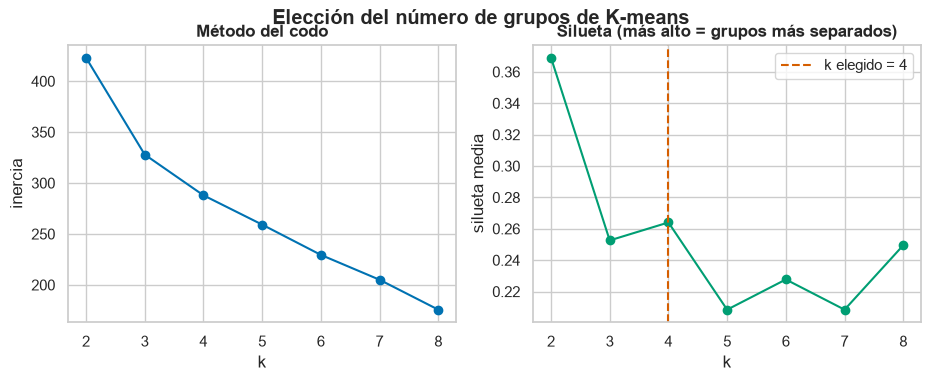

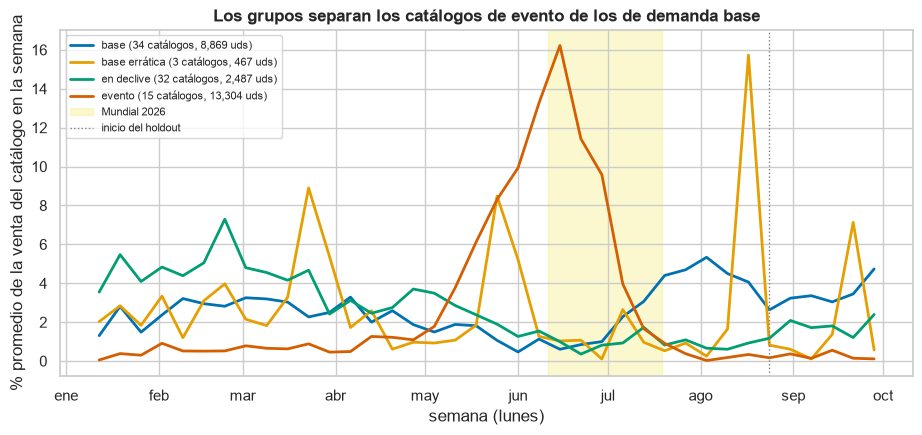

Grupo de cada catálogo del top:


,rank,unidades,linea,cluster,int_antes,int_evento,int_despues
catalogo,,,,,,,
CUELLO ALTO COLOMBIA RETRO,1,6366,COLOMBIA,evento,0.300,0.700,0.000
CUELLO ALTO COLOMBIA,2,2661,COLOMBIA,evento,0.260,0.740,0.000
CUELLO ALTO COLOMBIA ÉLITE,3,1475,COLOMBIA,evento,0.000,0.990,0.010
CUELLO ALTO HONDA REFLECTIVO,4,1420,MOTOS,base,0.370,0.150,0.480
CUELLO ALTO YAMAHA REFLECTIVO,5,1372,MOTOS,base,0.470,0.210,0.330
CUELLO ALTO RED BULL,6,1172,AUTOS_Y_MOTOR,base,0.140,0.260,0.600
COLOMBIA ELITE/CLASICO,7,1041,COLOMBIA,evento,0.000,1.000,0.000
CUELLO ALTO BMW ESTAMPADO REFLECTIVO,8,956,MOTOS,base,0.490,0.230,0.280
CUELLO ALTO SUZUKI REFLECTIVO,9,817,MOTOS,base,0.360,0.210,0.420


In [46]:
# 4.4.2 Gráficas: elección de k y perfil promedio de cada grupo
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(eval_k.index, eval_k["inercia"], marker="o", color=OKABE_ITO[0])
axes[0].set(title="Método del codo", xlabel="k", ylabel="inercia")
axes[1].plot(eval_k.index, eval_k["silueta"], marker="o", color=OKABE_ITO[2])
axes[1].axvline(K_ELEGIDO, color=OKABE_ITO[3], ls="--", label=f"k elegido = {K_ELEGIDO}")
axes[1].set(title="Silueta (más alto = grupos más separados)", xlabel="k", ylabel="silueta media"); axes[1].legend()
fig.suptitle("Elección del número de grupos de K-means", fontweight="bold")
guardar_fig(fig, "4_4_01_kmeans_codo_silueta"); plt.show()

_w = panel_y.pivot(index="catalogo", columns="semana", values="y").fillna(0)
_w = _w.loc[clusters.index]
_norm_w = _w.div(_w.sum(axis=1), axis=0)
fig, ax = plt.subplots()
for i, (nombre, g) in enumerate(clusters.groupby("cluster")):
    uds = int(g["unidades"].sum())
    ax.plot(_norm_w.columns, _norm_w.loc[g.index].mean() * 100, lw=2, color=OKABE_ITO[i % len(OKABE_ITO)],
            label=f"{nombre} ({len(g)} catálogos, {uds:,} uds)")
sombrear_mundial(ax)
ax.axvline(SEMANA_INICIO_HOLDOUT, color="grey", ls=":", lw=1, label="inicio del holdout")
ax.set(title="Los grupos separan los catálogos de evento de los de demanda base",
       ylabel="% promedio de la venta del catálogo en la semana", xlabel="semana (lunes)")
ax.xaxis.set_major_formatter(FMT_MES); ax.legend(fontsize=8, loc="upper left")
guardar_fig(fig, "4_4_02_perfiles_cluster"); plt.show()

print("Grupo de cada catálogo del top:")
maestro.loc[maestro["top_n"], ["rank", "unidades", "linea", "cluster"]].join(perfil[["int_antes", "int_evento", "int_despues"]]).round(2)

### 4.5 Separar la demanda base de la demanda de evento
Es la pregunta central de Klixmant. En esta sección se responde con una **línea base robusta interpolada**:
1. La **ventana del evento** va desde las 2 semanas anteriores a la semana del 11-jun hasta la semana del 19-jul (25-may a 19-jul).
   El **nivel antes** es la mediana de las 4 semanas previas a la ventana y el **nivel después**, la mediana de las 4 semanas siguientes.
2. Dentro de la ventana, la base es la **interpolación lineal** entre esos dos niveles. Fuera de la ventana, la base es la venta real.
3. **Demanda de evento** = venta real − base. Si es negativa, es **demanda desplazada**: catálogos que vendieron menos mientras duró el Mundial.
4. Si un catálogo nació dentro de la ventana, no tiene nivel antes y se usa el nivel después.

Se usa la mediana porque una o dos semanas raras no la mueven. La segunda ruta del plan (§4.5, opción 2) es la variable de
intervención: con el modelo de §5, `escenario_sin_evento()` apaga las variables del Mundial y da el pronóstico base.
Conviene comparar las dos rutas en §5.

In [47]:
# 4.5.1 Línea base interpolada por catálogo
def separar_base_evento(serie, ventana, k=4):
    """serie: unidades semanales de un catálogo (índice = semana). Devuelve y, y_base, y_evento."""
    s = serie.astype(float)
    antes = s[s.index < ventana.min()].tail(k)
    despues = s[s.index > ventana.max()].head(k)
    if len(antes) == 0 and len(despues) == 0:
        nivel_a = nivel_d = 0.0
    else:
        nivel_a = antes.median() if len(antes) else despues.median()
        nivel_d = despues.median() if len(despues) else nivel_a
    base = s.copy()
    en_v = s.index.isin(ventana)
    if en_v.any():
        # posiciones dentro de la ventana completa, para que un catálogo que nace a mitad de la ventana quede bien ubicado
        pos = ventana.get_indexer(s.index[en_v])
        base[en_v] = nivel_a + (nivel_d - nivel_a) * (pos + 1) / (len(ventana) + 1)
    return pd.DataFrame({"y": s, "y_base": base, "y_evento": s - base})


def base_evento_panel(panel_y, ventana, k=4):
    partes = [separar_base_evento(g.set_index("semana")["y"], ventana, k).assign(catalogo=c)
              for c, g in panel_y.groupby("catalogo", sort=False)]
    return pd.concat(partes).reset_index(names="semana")[["catalogo", "semana", "y", "y_base", "y_evento"]]


base_evento = base_evento_panel(panel_y, VENTANA_EVENTO)
assert np.isclose(base_evento["y_base"] + base_evento["y_evento"], base_evento["y"]).all()
base_evento = base_evento.merge(maestro[["familia", "linea", "rank", "top_n", "cluster"]], left_on="catalogo", right_index=True)

_v = base_evento[base_evento["semana"].isin(VENTANA_EVENTO)]


def _resumen_evento(df, por):
    r = df.groupby(por).agg(uds_reales=("y", "sum"), uds_base=("y_base", "sum"), uds_evento_neto=("y_evento", "sum"),
                            uds_evento_positivo=("y_evento", lambda s: s.clip(lower=0).sum()),
                            uds_desplazadas=("y_evento", lambda s: s.clip(upper=0).sum()))
    r["%_evento_sobre_real"] = r["uds_evento_neto"] / r["uds_reales"]
    return r


incremental_familia = _resumen_evento(_v, "familia")
incremental_linea = _resumen_evento(_v, "linea").sort_values("uds_evento_neto", ascending=False)
incremental_top = _resumen_evento(_v[_v["top_n"]], "catalogo").join(maestro[["rank", "familia", "cluster"]]).sort_values("rank")
print(f"Ventana del evento ({len(VENTANA_EVENTO)} semanas): unidades reales {int(_v['y'].sum()):,}, "
      f"base {int(_v['y_base'].sum()):,}, evento neto {int(_v['y_evento'].sum()):,} ({_v['y_evento'].sum() / _v['y'].sum():.0%})")
display(incremental_familia.round(2))
display(incremental_linea.round(2))
incremental_top.round(2)

Ventana del evento (8 semanas): unidades reales 10,297, base 3,995, evento neto 6,301 (61%)


,uds_reales,uds_base,uds_evento_neto,uds_evento_positivo,uds_desplazadas,%_evento_sobre_real
familia,,,,,,
COLOMBIA,"7,566.000",984.000,"6,582.000","6,658.670",-76.670,0.870
RESTO,"2,731.000","3,011.000",-280.000,"1,364.830","-1,644.830",-0.100


,uds_reales,uds_base,uds_evento_neto,uds_evento_positivo,uds_desplazadas,%_evento_sobre_real
linea,,,,,,
COLOMBIA,"7,566.000",984.000,"6,582.000","6,658.670",-76.670,0.870
FUTBOL,"1,132.000",598.000,534.000,845.890,-311.890,0.470
OTROS,90.000,69.000,21.000,73.500,-52.500,0.230
PERSONALIZADO,179.000,164.000,15.000,175.170,-160.170,0.080
AUTOS_Y_MOTOR,555.000,912.000,-357.000,140.720,-497.720,-0.640
MOTOS,775.000,"1,268.000",-493.000,129.560,-622.560,-0.640


,uds_reales,uds_base,uds_evento_neto,uds_evento_positivo,uds_desplazadas,%_evento_sobre_real,rank,familia,cluster
catalogo,,,,,,,,,
CUELLO ALTO COLOMBIA RETRO,"3,150.000",576.000,"2,574.000","2,585.560",-11.560,0.820,1,COLOMBIA,evento
CUELLO ALTO COLOMBIA,"1,459.000",188.000,"1,271.000","1,271.000",0.000,0.870,2,COLOMBIA,evento
CUELLO ALTO COLOMBIA ÉLITE,"1,462.000",4.000,"1,458.000","1,458.000",0.000,1.000,3,COLOMBIA,evento
CUELLO ALTO HONDA REFLECTIVO,131.000,324.000,-193.000,0.000,-193.000,-1.470,4,RESTO,base
CUELLO ALTO YAMAHA REFLECTIVO,148.000,198.000,-50.000,12.560,-62.560,-0.340,5,RESTO,base
CUELLO ALTO RED BULL,253.000,408.000,-155.000,49.670,-204.670,-0.610,6,RESTO,base
COLOMBIA ELITE/CLASICO,"1,037.000",16.000,"1,021.000","1,023.670",-2.670,0.980,7,COLOMBIA,evento
CUELLO ALTO BMW ESTAMPADO REFLECTIVO,107.000,126.000,-19.000,30.500,-49.500,-0.180,8,RESTO,base
CUELLO ALTO SUZUKI REFLECTIVO,102.000,186.000,-84.000,0.000,-84.000,-0.820,9,RESTO,base


In [48]:
# 4.5.2 Sensibilidad: ¿cambia la conclusión si se mueve la ventana o el número de semanas del nivel?
_sens = []
for pre in (1, 2, 3):
    vent = pd.date_range(_sem_mundial.min() - pd.Timedelta(weeks=pre), _sem_mundial.max(), freq=DECISIONES["frecuencia"])
    for k in (3, 4, 6):
        be = base_evento_panel(panel_y, vent, k).merge(maestro[["familia"]], left_on="catalogo", right_index=True)
        be = be[be["semana"].isin(vent)]
        r = be.groupby("familia")["y_evento"].sum()
        _sens.append({"semanas_pre": pre, "k_nivel": k, "evento_COLOMBIA": r.get("COLOMBIA", 0), "evento_RESTO": r.get("RESTO", 0),
                      "%_evento_COLOMBIA": r.get("COLOMBIA", 0) / be.loc[be.familia == "COLOMBIA", "y"].sum()})
sensibilidad = pd.DataFrame(_sens)
print("Rango de la demanda de evento de la familia Colombia: "
      f"{sensibilidad['evento_COLOMBIA'].min():,.0f} a {sensibilidad['evento_COLOMBIA'].max():,.0f} unidades")
sensibilidad.round(2)

Rango de la demanda de evento de la familia Colombia: 6,009 a 6,750 unidades


,semanas_pre,k_nivel,evento_COLOMBIA,evento_RESTO,%_evento_COLOMBIA
0,1,3,"6,119.000",-398.750,0.860
1,1,4,"6,008.750",-255.750,0.840
2,1,6,"6,117.250",-124.000,0.860
3,2,3,"6,538.000",-427.000,0.860
4,2,4,"6,582.000",-280.000,0.870
5,2,6,"6,594.000",-91.000,0.870
6,3,3,"6,703.250",-546.250,0.860
7,3,4,"6,750.000",-385.750,0.870
8,3,6,"6,630.750",-159.250,0.850


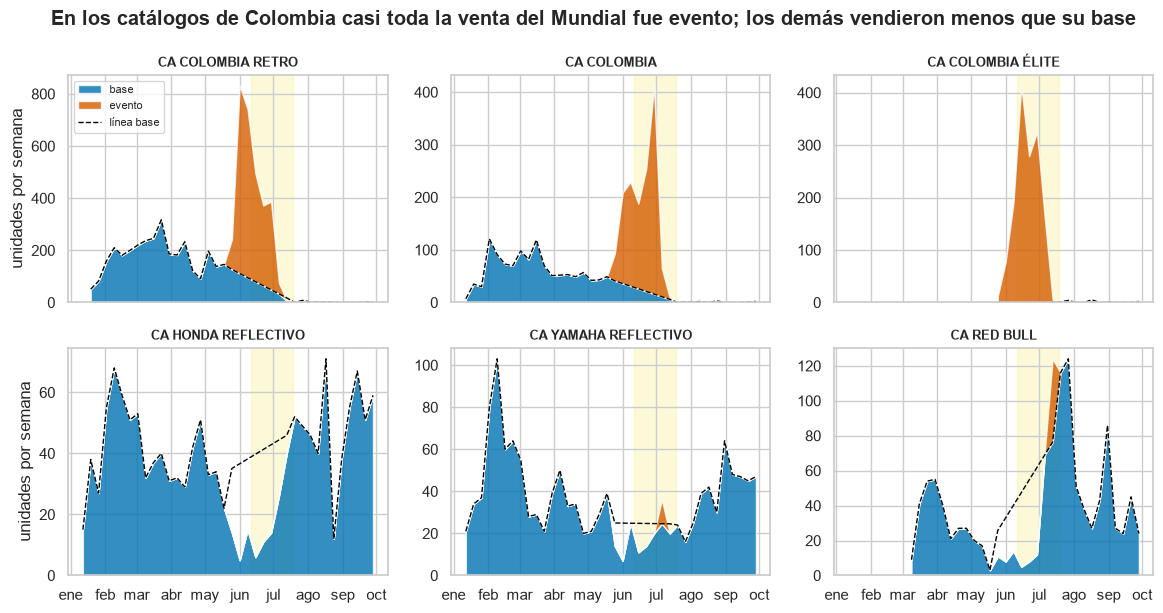

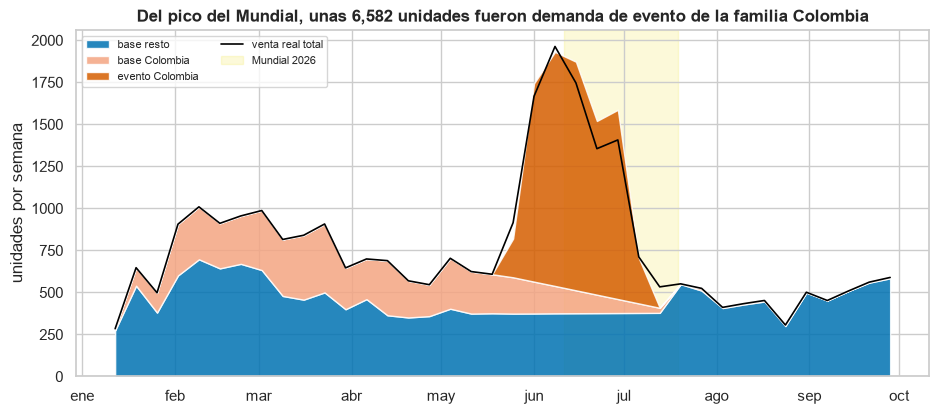

In [49]:
# 4.5.3 Gráficas: base vs. evento
_cats = (list(maestro[(maestro.familia == "COLOMBIA") & maestro.top_n].index[:3]) +
         list(maestro[(maestro.familia == "RESTO") & maestro.top_n].index[:3]))
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5), sharex=True)
for ax, c in zip(axes.flat, _cats):
    d = base_evento[base_evento["catalogo"] == c].set_index("semana")
    ax.stackplot(d.index, np.minimum(d["y"], d["y_base"]), d["y_evento"].clip(lower=0),
                 colors=[COLOR_FAMILIA["RESTO"], COLOR_FAMILIA["COLOMBIA"]], alpha=.8, labels=["base", "evento"])
    ax.plot(d.index, d["y_base"], color="black", ls="--", lw=1, label="línea base")
    sombrear_mundial(ax, alpha=.2, etiqueta=False)
    ax.set_title(c.replace("CUELLO ALTO ", "CA "), fontsize=9); ax.xaxis.set_major_formatter(FMT_MES)
axes[0, 0].set_ylabel("unidades por semana"); axes[1, 0].set_ylabel("unidades por semana")
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.suptitle("En los catálogos de Colombia casi toda la venta del Mundial fue evento; los demás vendieron menos que su base",
             fontweight="bold")
guardar_fig(fig, "4_5_01_base_evento_top6"); plt.show()

_fam = base_evento.groupby(["semana", "familia"])[["y", "y_base", "y_evento"]].sum().unstack("familia")
fig, ax = plt.subplots()
ax.stackplot(_fam.index, _fam[("y_base", "RESTO")], _fam[("y_base", "COLOMBIA")], _fam[("y_evento", "COLOMBIA")].clip(lower=0),
             colors=[COLOR_FAMILIA["RESTO"], "#F4A582", COLOR_FAMILIA["COLOMBIA"]], alpha=.85,
             labels=["base resto", "base Colombia", "evento Colombia"])
ax.plot(_fam.index, _fam[("y", "RESTO")] + _fam[("y", "COLOMBIA")], color="black", lw=1.2, label="venta real total")
sombrear_mundial(ax, alpha=.2)
ax.set(title=f"Del pico del Mundial, unas {incremental_familia.loc['COLOMBIA', 'uds_evento_neto']:,.0f} unidades fueron demanda de evento de la familia Colombia",
       ylabel="unidades por semana")
ax.xaxis.set_major_formatter(FMT_MES); ax.legend(loc="upper left", ncol=2, fontsize=8)
guardar_fig(fig, "4_5_02_base_evento_familia"); plt.show()

### 4.6 Panel final con variables y diccionario
`VARIABLES_MODELO` es la lista recomendada para §5. `VARIABLES_OPCIONALES` son variables que conviene probar con cuidado:
la semana del año y el mes del horizonte (octubre a diciembre) no aparecen en el entrenamiento, así que un árbol
los trataría como la última semana vista. `VARIABLES_CATEGORICAS` deben pasarse como `category` a `HistGradientBoostingRegressor`
(`categorical_features="from_dtype"`). `planchadas`, `puntadas`, `no_rotativo` y `pct_dropi_8` pueden traer NaN.
`HistGradientBoostingRegressor` los maneja sin imputar; para otros modelos, impútenlos con la mediana.

In [50]:
# 4.6.1 Panel final
panel = agregar_variables(panel_y, maestro, cal_modelo, ultima_observada=ULTIMA_SEMANA_COMPLETA)
panel = panel.merge(base_evento[["catalogo", "semana", "y_base", "y_evento"]], on=["catalogo", "semana"], how="left")
assert panel["y"].sum() == panel_y["y"].sum() and len(panel) == len(panel_y)

VARIABLES_CATEGORICAS = ["linea", "tipo_prenda", "tela_principal", "tipo_proceso", "cluster"]
VARIABLES_MODELO = (VARIABLES_DINAMICAS + ["n_festivos", "quincena", "fecha_comercial", "prima"] + VARIABLES_EVENTO +
                    ["es_colombia", "pct_tela_principal", "n_telas", "pct_dama", "reflectivo", "personalizado", "no_rotativo",
                     "planchadas", "puntadas", "tiene_ficha", "semanas_desde_lanzamiento", "es_lanzamiento"] + VARIABLES_CATEGORICAS)
VARIABLES_OPCIONALES = ["semana_anio", "mes", "semanas_desde_fin_mundial", "catalogo"]
OBJETIVOS = ["y", "y_base", "y_evento"]

_dic = [
    ("catalogo", "id", "Nombre del catálogo normalizado (4.1.1)", "—", "id / opcional como categoría"),
    ("semana", "id", "Lunes de la semana (lunes a domingo)", "—", "id"),
    ("y", "objetivo", "Unidades vendidas en la semana (sin canceladas, por fecha_remision)", "semana t", "objetivo"),
    ("y_dropi", "auxiliar", "Unidades del canal Dropi en la semana", "semana t", "no usar (información del presente)"),
    ("y_base", "objetivo", "Demanda base: venta real fuera de la ventana; interpolación entre medianas dentro (4.5)", "semana t", "objetivo alterno"),
    ("y_evento", "objetivo", "y − y_base (negativo = demanda desplazada)", "semana t", "objetivo alterno / análisis"),
    *[(f"lag_{k}", "rezago", f"Unidades de la semana t−{k}", f"t−{k}", "modelo") for k in range(1, 5)],
    *[(f"media_{w}", "ventana", f"Media de unidades de las {w} semanas anteriores", f"t−{w}…t−1", "modelo") for w in (4, 8)],
    *[(f"desv_{w}", "ventana", f"Desviación estándar de las {w} semanas anteriores", f"t−{w}…t−1", "modelo") for w in (4, 8)],
    ("semanas_desde_ultima_venta", "ventana", "Semanas entre t y la última semana con venta antes de t", "pasado", "modelo"),
    ("pct_dropi_8", "canal", "Participación de Dropi en las unidades de las 8 semanas anteriores (NaN si no hubo venta)", "t−8…t−1", "modelo"),
    ("n_festivos", "calendario", "Festivos de Colombia en la semana", "semana t (conocida)", "modelo"),
    ("quincena", "calendario", "1 si la semana incluye día 15, 30 (o 28-feb)", "semana t (conocida)", "modelo"),
    ("fecha_comercial", "calendario", "1 si la semana tiene Día de la Madre, del Padre, Amor y Amistad, Black Friday o Nochebuena", "semana t", "modelo"),
    ("prima", "calendario", "1 si la semana incluye el pago de la prima (30-jun, 20-dic)", "semana t", "modelo"),
    ("semana_anio", "calendario", "Semana ISO del año", "semana t", "opcional (fuera de rango en el horizonte)"),
    ("mes", "calendario", "Mes", "semana t", "opcional (fuera de rango en el horizonte)"),
    ("pre_mundial", "evento", f"1 en las {SEMANAS_PRE_MUNDIAL} semanas antes de la primera semana del Mundial", "semana t", "modelo"),
    ("semana_mundial", "evento", "1 si la semana tiene algún día del Mundial (11-jun a 19-jul)", "semana t", "modelo"),
    ("dias_mundial", "evento", "Días del Mundial dentro de la semana", "semana t", "modelo"),
    ("n_partidos_colombia", "evento", "Partidos de Colombia en la semana", "semana t", "modelo"),
    ("colombia_en_torneo", "evento", "1 desde la primera semana del Mundial hasta la semana de la eliminación (7-jul)", "semana t", "modelo"),
    ("colombia_x_evento", "evento", "es_colombia × (pre_mundial o semana_mundial)", "semana t", "modelo"),
    ("semanas_desde_fin_mundial", "evento", "Semanas desde la última semana del Mundial (tope 8)", "semana t", "opcional"),
    ("ventana_evento", "evento", "1 dentro de la ventana usada en 4.5 (pre + Mundial)", "semana t", "no usar (diagnóstico)"),
    ("con_historia", "calendario", "1 si la semana está dentro del periodo con datos", "semana t", "no usar (diagnóstico)"),
    ("familia", "catálogo", "COLOMBIA o RESTO (regex de §0.5)", "estática", "no usar (usar es_colombia)"),
    ("es_colombia", "catálogo", "1 si el catálogo es de la familia Colombia", "estática", "modelo"),
    ("linea", "catálogo", "Línea de producto: COLOMBIA, MOTOS, AUTOS_Y_MOTOR, FUTBOL, PERSONALIZADO, OTROS (4.2.1)", "estática", "modelo (categórica)"),
    ("tipo_prenda", "catálogo", "CUELLO_ALTO, BUZO o SIN_DATO (desde el nombre)", "estática", "modelo (categórica)"),
    ("tela_principal", "catálogo", "Tela con más unidades del catálogo (2.º token de referencia)", "toda la historia", "modelo (categórica)"),
    ("pct_tela_principal", "catálogo", "% de unidades del catálogo en su tela principal", "toda la historia", "modelo"),
    ("n_telas", "catálogo", "Número de telas en que se ha cortado el catálogo", "toda la historia", "modelo"),
    ("pct_dama", "catálogo", "% de unidades del catálogo en referencias de dama (prefijo D)", "toda la historia", "modelo"),
    ("tipo_proceso", "catálogo", "ES, BOR o AMBOS (ficha; si falta, sufijo del SKU; si no, SIN_DATO)", "estática", "modelo (categórica)"),
    ("reflectivo", "catálogo", "1 si es reflectivo (ficha; si falta, por el nombre)", "estática", "modelo"),
    ("personalizado", "catálogo", "1 si es personalizado (ficha; si falta, por la línea)", "estática", "modelo"),
    ("no_rotativo", "catálogo", "1 si la ficha lo marca como no rotativo (NaN sin ficha)", "estática", "modelo"),
    ("planchadas", "catálogo", "Planchadas del diseño (ficha; NaN si falta)", "estática", "modelo"),
    ("puntadas", "catálogo", "Puntadas del bordado (ficha; NaN si falta)", "estática", "modelo"),
    ("tiene_ficha", "catálogo", "1 si el catálogo tiene ficha en la hoja CATALOGOS", "estática", "modelo"),
    ("cluster", "catálogo", "Grupo K-means del perfil de demanda; 'cola' si no es elegible (4.4)", "semanas < holdout", "modelo (categórica; recalcular por pliegue)"),
    ("primera_semana", "ciclo de vida", "Semana de la primera venta", "estática", "no usar (usar semanas_desde_lanzamiento)"),
    ("semanas_desde_lanzamiento", "ciclo de vida", "Semanas entre la primera venta y t", "semana t", "modelo"),
    ("es_lanzamiento", "ciclo de vida", "1 en las 4 primeras semanas de vida", "semana t", "modelo"),
    ("rank", "segmento", "Posición del catálogo por unidades (semanas completas)", "toda la historia", "no usar (selección del top)"),
    ("top_n", "segmento", f"True para el top {DECISIONES['top_n_modelados']}", "toda la historia", "filtro"),
    ("conjunto", "segmento", "entrenamiento / holdout / futuro", "—", "filtro"),
]
diccionario = pd.DataFrame(_dic, columns=["variable", "grupo", "descripcion", "ventana_temporal", "uso"])
_faltan = set(panel.columns) - set(diccionario["variable"])
assert not _faltan, f"Variables sin documentar: {_faltan}"
assert set(VARIABLES_MODELO) <= set(panel.columns)
diccionario.to_csv(RUTAS["docs"] / "4_diccionario_variables.csv", index=False, encoding="utf-8")
print(f"Panel final: {len(panel):,} filas × {panel.shape[1]} columnas | variables del modelo: {len(VARIABLES_MODELO)} "
      f"({len(VARIABLES_CATEGORICAS)} categóricas)")
print("Filas por conjunto:", panel["conjunto"].value_counts().to_dict(),
      f"| top {DECISIONES['top_n_modelados']}:", panel[panel.top_n]["conjunto"].value_counts().to_dict())
print("NaN en variables del modelo:", panel[VARIABLES_MODELO].isna().sum().loc[lambda s: s > 0].to_dict())
diccionario

Panel final: 17,722 filas × 53 columnas | variables del modelo: 37 (5 categóricas)
Filas por conjunto: {'entrenamiento': 13265, 'holdout': 4457} | top 20: {'entrenamiento': 549, 'holdout': 120}
NaN en variables del modelo: {'pct_dropi_8': 792, 'no_rotativo': 12481, 'planchadas': 13737, 'puntadas': 15593}


,variable,grupo,descripcion,ventana_temporal,uso
0,catalogo,id,Nombre del catálogo normalizado (4.1.1),—,id / opcional como categoría
1,semana,id,Lunes de la semana (lunes a domingo),—,id
2,y,objetivo,Unidades vendidas en la semana (sin canceladas...,semana t,objetivo
3,y_dropi,auxiliar,Unidades del canal Dropi en la semana,semana t,no usar (información del presente)
4,y_base,objetivo,Demanda base: venta real fuera de la ventana; ...,semana t,objetivo alterno
5,y_evento,objetivo,y − y_base (negativo = demanda desplazada),semana t,objetivo alterno / análisis
6,lag_1,rezago,Unidades de la semana t−1,t−1,modelo
7,lag_2,rezago,Unidades de la semana t−2,t−2,modelo
8,lag_3,rezago,Unidades de la semana t−3,t−3,modelo
9,lag_4,rezago,Unidades de la semana t−4,t−4,modelo


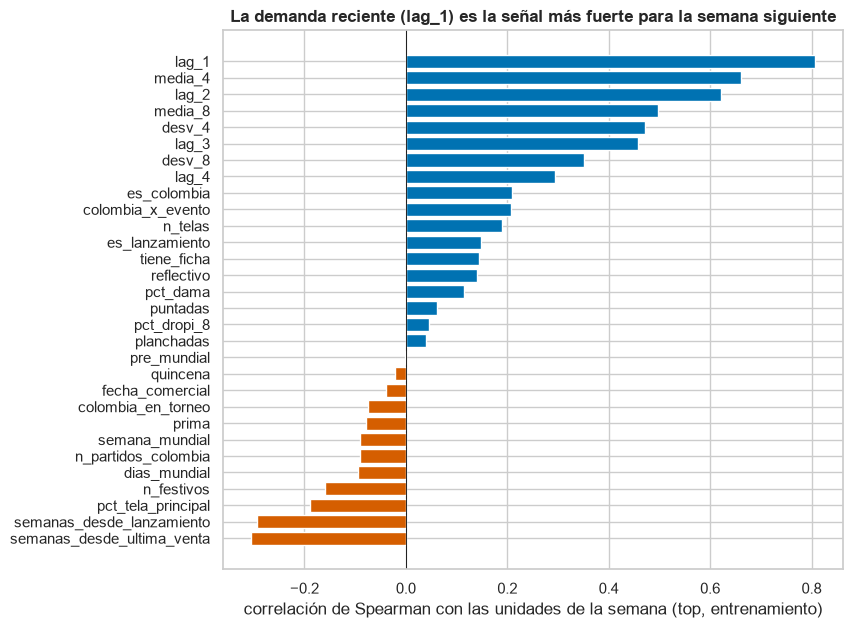

In [51]:
# 4.6.2 ¿Qué variables se asocian más con la demanda? (Spearman, top, conjunto de entrenamiento; orientativo para §5)
_ent = panel[panel["top_n"] & (panel["conjunto"] == "entrenamiento")]
_num = [v for v in VARIABLES_MODELO if v not in VARIABLES_CATEGORICAS and _ent[v].nunique() > 1]
corr = _ent[_num].corrwith(_ent["y"], method="spearman").dropna().sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(corr.index, corr.values, color=[OKABE_ITO[0] if v >= 0 else OKABE_ITO[3] for v in corr.values])
ax.axvline(0, color="black", lw=.6)
ax.set(title=f"La demanda reciente ({corr.abs().idxmax()}) es la señal más fuerte para la semana siguiente",
       xlabel="correlación de Spearman con las unidades de la semana (top, entrenamiento)")
guardar_fig(fig, "4_6_01_correlacion_variables"); plt.show()

In [52]:
# 4.6.3 Exportación para §5–§8
_exportar4 = {
    "4_panel_semanal_catalogo.csv": panel,
    "4_maestro_catalogos.csv": maestro.reset_index(names="catalogo"),
    "4_base_evento_catalogo_semana.csv": base_evento,
    "4_incremental_mundial_top.csv": incremental_top.reset_index(),
    "4_incremental_mundial_linea.csv": incremental_linea.reset_index(),
    "4_perfil_clusters.csv": clusters.reset_index(names="catalogo"),
    "4_mapa_catalogo_tela.csv": mapa_tela,
    "4_proporciones_talla_color_top.csv": mezcla_tc,
    "4_sensibilidad_base_evento.csv": sensibilidad,
}
for nombre, df in _exportar4.items():
    df.to_csv(RUTAS["procesado"] / nombre, index=False, encoding="utf-8")
    print(f"{nombre:<42} {len(df):>7,} filas")
print("También: 4_mapa_nombres_catalogo.csv, 4_calendario_modelo_semanal.csv y docs/4_diccionario_variables.csv")

4_panel_semanal_catalogo.csv                17,722 filas
4_maestro_catalogos.csv                        798 filas


4_base_evento_catalogo_semana.csv           17,722 filas
4_incremental_mundial_top.csv                   20 filas
4_incremental_mundial_linea.csv                  6 filas
4_perfil_clusters.csv                           84 filas
4_mapa_catalogo_tela.csv                     1,643 filas
4_proporciones_talla_color_top.csv             603 filas
4_sensibilidad_base_evento.csv                   9 filas
También: 4_mapa_nombres_catalogo.csv, 4_calendario_modelo_semanal.csv y docs/4_diccionario_variables.csv


### 4.7 Hallazgos de la preparación (para redactar con palabras propias)

In [53]:
_inc_col = incremental_familia.loc["COLOMBIA"]
_inc_rest = incremental_familia.loc["RESTO"]
h4 = {
    "catálogos normalizados (crudos → finales)": f"{dem['catalogo'].nunique()} → {len(maestro)}",
    "telas base (2.º token de referencia)": len(TELAS),
    "catálogos con más de una tela": int((maestro['n_telas'] > 1).sum()),
    "ficha CATALOGOS (catálogos / % volumen)": f"{maestro['tiene_ficha'].sum()} / {_cob.get(1, 0):.1%}",
    "panel (filas, catálogos, % semanas en cero)": (len(panel), panel['catalogo'].nunique(), f"{(panel['y'] == 0).mean():.1%}"),
    "ventana del evento": f"{VENTANA_EVENTO.min().date()} → {VENTANA_EVENTO.max().date()}",
    "evento neto familia Colombia (uds, % de su venta en la ventana)": (int(_inc_col['uds_evento_neto']), f"{_inc_col['%_evento_sobre_real']:.0%}"),
    "evento neto resto (uds; negativo = desplazada)": int(_inc_rest['uds_evento_neto']),
    "sensibilidad evento Colombia (mín–máx)": f"{sensibilidad['evento_COLOMBIA'].min():,.0f}–{sensibilidad['evento_COLOMBIA'].max():,.0f}",
    "k de K-means / grupos": (K_ELEGIDO, centros['nombre'].tolist()),
    "variables del modelo": len(VARIABLES_MODELO),
    "prueba de no fuga": "superada",
}
for k, v in h4.items():
    print(f"- {k}: {v}")

- catálogos normalizados (crudos → finales): 804 → 798
- telas base (2.º token de referencia): 16
- catálogos con más de una tela: 9
- ficha CATALOGOS (catálogos / % volumen): 233 / 89.6%
- panel (filas, catálogos, % semanas en cero): (17722, 792, '83.7%')
- ventana del evento: 2026-05-25 → 2026-07-13
- evento neto familia Colombia (uds, % de su venta en la ventana): (6582, '87%')
- evento neto resto (uds; negativo = desplazada): -280
- sensibilidad evento Colombia (mín–máx): 6,009–6,750
- k de K-means / grupos: (4, ['evento', 'base', 'en declive', 'base errática'])
- variables del modelo: 37
- prueba de no fuga: superada


## 5. Modelado: selección de modelos

En esta sección se construye la **escalera de modelos** del plan (§5.2), de lo más simple a lo más complejo, y se comparan
con una **validación preliminar** en 6 orígenes **anteriores al holdout**. El holdout (24-ago → 28-sep) **no se toca aquí**:
queda para §6, junto con el backtesting de origen móvil completo. Por eso el resultado de esta sección es un **modelo candidato**,
no el modelo final.

### 5.1 Qué condiciona la elección (datos de §3 y §4)

| Característica del dataset | Consecuencia para el modelado |
|---|---|
| Historia corta: 38 semanas completas (≈ 31 antes del holdout) | No hay estacionalidad anual que estimar. Los modelos muy flexibles (LSTM) tienden a sobreajustar |
| Un evento atípico (Mundial) que no se repite en el horizonte | El modelo debe saber cuándo hubo evento (variables de §4.3) para no pronosticar junio en octubre |
| Concentración: top 20 = 76,9 % de las unidades | El esfuerzo de modelado se mide en el top; la cola se resuelve con una regla |
| Cola: 708 de 792 catálogos sin historia suficiente; 618 vivieron una sola semana | Pronosticar catálogo por catálogo en la cola es casi imposible; se evalúa también su total |
| 792 series que comparten tela, proceso, línea y perfil | Un **modelo global** (uno para todas las series) aprovecha mejor la poca historia (*cross-learning*, M5) |
| 84 % de las filas del panel son cero y la demanda es un conteo | Pérdida **Poisson** en el boosting (predicción no negativa) |
| Restricción del enunciado: sklearn, keras o pytorch | Modelo principal en **scikit-learn**; el LSTM en **PyTorch** |

### 5.2 Infraestructura común
Todas las piezas de esta sección (y de §6) usan las mismas funciones:

- **`panel_al_corte(corte)`** reconstruye el panel con información **hasta el corte**. Además recalcula el **clúster K-means con datos
  hasta el corte** (`maestro_al_corte`), como pidió el reporte de §4: así ningún pliegue usa el perfil del futuro.
- **`pronostico_recursivo()`** implementa la estrategia recursiva descrita en §4 (agregar filas futuras con `y = NaN`, predecir la semana *h*,
  escribir la predicción y repetir). Incluye una **salvaguarda**: ninguna predicción supera 2 × la mejor semana histórica del catálogo.
  En las pruebas, un boosting con tasa de aprendizaje 0,1 llegó a pronosticar millones de unidades: con pérdida Poisson el enlace es
  logarítmico y, si los rezagos salen del rango visto en el entrenamiento, la recursión explota.
- **Métricas** (§6.2 del plan): WAPE (principal), sesgo (Σ error / Σ real; positivo = sobrepronóstico), MAE y MASE
  (escala = error medio del ingenuo de 1 semana en la historia del catálogo). §6 las reutiliza.

In [54]:
# 5.2 Infraestructura común: datos a un corte, matriz X, pronóstico recursivo y métricas
import time
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance

TOP = list(maestro.index[maestro["top_n"]])
H = DECISIONES["horizonte_principal"]
H_EXT = DECISIONES["horizonte_extendido"]
SEMANA = pd.Timedelta(weeks=1)
_CATS_FIJAS = {c: sorted(maestro[c].astype(str).unique()) for c in VARIABLES_CATEGORICAS if c != "cluster"}


def maestro_al_corte(corte):
    """Copia de `maestro` con el clúster recalculado solo con semanas <= corte (evita la fuga señalada en §4.4).
    Si el corte cae antes de terminar la ventana del evento, los periodos que todavía no existen quedan en 0."""
    m = maestro.copy()
    perf = perfil_demanda(panel_y, corte + SEMANA, VENTANA_EVENTO)
    perf[["int_antes", "int_evento", "int_despues"]] = perf[["int_antes", "int_evento", "int_despues"]].fillna(0)
    if perf["elegible"].sum() >= 10:
        cl, *_ = agrupar_catalogos(perf, k=K_ELEGIDO)
        m["cluster"] = cl["cluster"].reindex(m.index).fillna("cola")
    else:
        m["cluster"] = "cola"
    return m


def matriz_X(df, variables, maestro_ref):
    """Variables del modelo con las categóricas como `category` y categorías fijas (las mismas en ajuste y predicción)."""
    X = df[variables].copy()
    for c in [v for v in variables if v in VARIABLES_CATEGORICAS]:
        cats = _CATS_FIJAS.get(c) or sorted(maestro_ref[c].astype(str).unique())
        X[c] = pd.Categorical(df[c].astype(str), categories=cats)
    if "catalogo" in variables:          # identidad del catálogo solo para el top (HGB admite máx. 255 categorías); el resto = "OTRO"
        X["catalogo"] = pd.Categorical(df["catalogo"].where(df["catalogo"].isin(TOP), "OTRO"), categories=TOP + ["OTRO"])
    for c in [v for v in variables if X[v].dtype == bool]:
        X[c] = X[c].astype(int)
    return X


def panel_al_corte(corte):
    """Panel con variables calculadas solo con información <= corte (clúster incluido)."""
    m = maestro_al_corte(corte)
    p = agregar_variables(construir_panel(cat_ok, corte), m, cal_modelo, ultima_observada=corte)
    return p, m


def filas_futuras(p_y, corte, h):
    """Agrega h semanas con y = NaN a cada catálogo del panel (estrategia recursiva, reporte 02 §6.2)."""
    cats = p_y["catalogo"].unique()
    fut = pd.DataFrame([(c, corte + SEMANA * k) for c in cats for k in range(1, h + 1)], columns=["catalogo", "semana"])
    fut[["y", "y_dropi"]] = np.nan
    return pd.concat([p_y[["catalogo", "semana", "y", "y_dropi"]], fut], ignore_index=True)


TOPE_RELATIVO = 2.0    # salvaguarda: ningún pronóstico supera 2 × la mejor semana histórica del catálogo


def pronostico_recursivo(modelos, corte, h, variables, m, catalogos=None, p_y=None, transformar=None, redondear=False,
                         tope=TOPE_RELATIVO):
    """Pronóstico recursivo a h semanas desde `corte` (última semana observada).
    `modelos`: dict nombre -> estimador ya ajustado. El primero alimenta los rezagos; los demás (p. ej. cuantiles)
    se evalúan sobre esa misma trayectoria. `transformar(X)` permite escenarios (p. ej. escenario_sin_evento).
    `tope`: con pérdida Poisson (enlace log) la recursión puede explotar si los rezagos salen del rango visto;
    por eso cada predicción se limita a `tope` × el máximo semanal histórico del catálogo (None = sin tope).
    `redondear`: si True, la trayectoria usa unidades enteras (afecta semanas_desde_ultima_venta)."""
    p_y = construir_panel(cat_ok, corte) if p_y is None else p_y
    if catalogos is not None:
        p_y = p_y[p_y["catalogo"].isin(catalogos)]
    maximo = p_y.groupby("catalogo")["y"].max()
    trabajo = filas_futuras(p_y, corte, h)
    nombres = list(modelos)
    salida = []
    for k in range(1, h + 1):
        semana_k = corte + SEMANA * k
        df = agregar_variables(trabajo, m, cal_modelo, ultima_observada=corte)
        fila = df[df["semana"] == semana_k]
        X = matriz_X(fila, variables, m)
        if transformar is not None:
            X = transformar(X)
        techo = (fila["catalogo"].map(maximo).values * tope) if tope else None
        preds = {n: np.clip(modelos[n].predict(X), 0, techo) for n in nombres}
        out = fila[["catalogo", "semana"]].copy()
        out["h"] = k
        for n in nombres:
            out[n] = preds[n]
        salida.append(out)
        valor = np.round(preds[nombres[0]]) if redondear else preds[nombres[0]]
        en_k = trabajo["semana"] == semana_k
        trabajo.loc[en_k, "y"] = pd.Series(valor, index=fila["catalogo"].values).reindex(trabajo.loc[en_k, "catalogo"]).values
        trabajo.loc[en_k, "y_dropi"] = 0     # pct_dropi_8 queda congelado en su último valor (ultima_observada)
    return pd.concat(salida, ignore_index=True)


# ---------- Métricas (§6.2 del plan). §6 las reutiliza. ----------
def escala_mase(p_y, corte):
    """Error absoluto medio del ingenuo de 1 semana en la historia de cada catálogo hasta el corte (denominador del MASE)."""
    p = p_y[p_y["semana"] <= corte].sort_values(["catalogo", "semana"])
    d = p.groupby("catalogo")["y"].diff().abs()
    return d.groupby(p["catalogo"]).mean()


def metricas(df, real="y", pred="pred", escala=None):
    """WAPE, sesgo, MAE y MASE. `escala`: Serie catálogo -> denominador del MASE (promedio del MASE por catálogo)."""
    e = df[pred] - df[real]
    tot = df[real].sum()
    r = {"WAPE": e.abs().sum() / tot if tot > 0 else np.nan,
         "sesgo": e.sum() / tot if tot > 0 else np.nan,
         "MAE": e.abs().mean(), "uds_reales": tot, "uds_pronosticadas": df[pred].sum(), "n": len(df)}
    if escala is not None:
        s = df["catalogo"].map(escala)
        ok = s > 0
        mae_cat = e.abs()[ok].groupby(df.loc[ok, "catalogo"]).mean()
        r["MASE"] = (mae_cat / escala.reindex(mae_cat.index)).mean()
    return r


print(f"Top {len(TOP)} | horizonte {H} semanas (extendido {H_EXT}) | "
      f"holdout {SEMANA_INICIO_HOLDOUT.date()} → {ULTIMA_SEMANA_COMPLETA.date()}: NO se usa en §5")

Top 20 | horizonte 4 semanas (extendido 8) | holdout 2026-08-24 → 2026-09-28: NO se usa en §5


### 5.3 Escalera de modelos

| Nivel | Modelo | Implementación | Rol |
|---|---|---|---|
| 0 | **Ingenuo** (última semana) y **media móvil de 4 semanas** | pandas | Línea base obligatoria |
| Cola | **SBA** (Croston corregido) y **TSB** (decae si el catálogo deja de vender) | NumPy | Demanda intermitente |
| 1 | **ETS** (suavizamiento exponencial simple) y **SARIMAX** AR(1) con *dummies* del Mundial | statsmodels, una serie por catálogo del top | Referencia estadística (U2) |
| 2 | **HGB global Poisson** (`HistGradientBoostingRegressor`) con las 37 variables de §4 | scikit-learn | **Modelo principal** |
| 2 (sensibilidad) | HGB sin el clúster; HGB "suave" (árboles más pequeños) | scikit-learn | ¿Cuánto depende de la configuración? |
| 2b | **Random Forest** global (NaN imputados con la mediana) | scikit-learn | Comparación interpretable |
| 3 | **LSTM** global (8 semanas de historia + variables de evento) | PyTorch | Experimento de deep learning (U1) |

**Detalles de implementación**
- Los modelos estadísticos se ajustan solo a los 20 catálogos del top; para el resto usan la media móvil.
- Los modelos globales se entrenan con **todos** los catálogos, pero solo pronostican los que vendieron en las últimas
  12 semanas. Los inactivos quedan en 0, que es lo que haría cualquier regla, y así la recursión es más rápida.
- Si un catálogo nace después del corte, ningún modelo lo pronostica y su venta cuenta como error.

In [55]:
# 5.3.1 Escalera de modelos: todos devuelven la misma tabla (catalogo, semana, h, pred)
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

SEMANAS_ACTIVO = 12          # catálogos sin venta en las últimas 12 semanas se pronostican en 0 (no se pasan por el modelo)
_CTX = {}                    # caché por corte: panel con variables y maestro recalculado


def contexto(corte):
    if corte not in _CTX:
        p, m = panel_al_corte(corte)
        p_y = p[["catalogo", "semana", "y", "y_dropi"]]
        ult = p_y[p_y["y"] > 0].groupby("catalogo")["semana"].max()
        activos = ult.index[ult > corte - SEMANA * SEMANAS_ACTIVO]
        _CTX[corte] = {"panel": p, "maestro": m, "p_y": p_y, "activos": list(activos)}
    return _CTX[corte]


def _plantilla(ctx, corte, h, catalogos=None):
    cats = ctx["p_y"]["catalogo"].unique() if catalogos is None else catalogos
    return pd.DataFrame([(c, corte + SEMANA * k, k) for c in cats for k in range(1, h + 1)], columns=["catalogo", "semana", "h"])


def _ancho(ctx):
    return ctx["p_y"].pivot(index="semana", columns="catalogo", values="y")       # NaN antes del lanzamiento


# ---------- Nivel 0: líneas base ----------
def m_ingenuo(corte, h, ctx):
    out = _plantilla(ctx, corte, h)
    out["pred"] = out["catalogo"].map(_ancho(ctx).iloc[-1].fillna(0))
    return out


def m_media_movil(corte, h, ctx, w=4):
    out = _plantilla(ctx, corte, h)
    out["pred"] = out["catalogo"].map(_ancho(ctx).tail(w).mean().fillna(0))
    return out


def sba(serie, alpha=0.1):
    """Croston con la corrección de Syntetos-Boylan (SBA): tasa = tamaño / intervalo × (1 − α/2)."""
    y = np.asarray(serie, dtype=float)
    pos = np.flatnonzero(y > 0)
    if len(pos) == 0:
        return 0.0
    z, p, q = y[pos[0]], max(pos[0] + 1, 1), 1
    for t in range(pos[0] + 1, len(y)):
        if y[t] > 0:
            z += alpha * (y[t] - z); p += alpha * (q - p); q = 1
        else:
            q += 1
    return (1 - alpha / 2) * z / p


def tsb(serie, alpha=0.1, beta=0.1):
    """Teunter-Syntetos-Babai: actualiza la probabilidad de venta cada semana, así que decae si el catálogo deja de venderse."""
    y = np.asarray(serie, dtype=float)
    pos = np.flatnonzero(y > 0)
    if len(pos) == 0:
        return 0.0
    z, p = y[pos[0]], 1.0
    for t in range(pos[0] + 1, len(y)):
        p += beta * ((y[t] > 0) - p)
        if y[t] > 0:
            z += alpha * (y[t] - z)
    return p * z


def _por_serie(fn):
    def metodo(corte, h, ctx):
        w = _ancho(ctx)
        out = _plantilla(ctx, corte, h)
        out["pred"] = out["catalogo"].map({c: fn(w[c].dropna()) for c in w.columns})
        return out
    return metodo


m_sba, m_tsb = _por_serie(sba), _por_serie(tsb)


# ---------- Nivel 1: estadísticos por serie (solo top; el resto con media móvil) ----------
def m_ets(corte, h, ctx):
    w, base = _ancho(ctx), m_media_movil(corte, h, ctx)
    for c in [c for c in TOP if c in w.columns]:
        s = w[c].dropna()
        if len(s) >= 6:
            f = SimpleExpSmoothing(s.values, initialization_method="estimated").fit().forecast(h)
            base.loc[base["catalogo"] == c, "pred"] = np.clip(f, 0, None)
    return base


EXOG_SARIMAX = ["pre_mundial", "semana_mundial"]


def m_sarimax(corte, h, ctx):
    """AR(1) con constante y dummies del Mundial (intervención, FPP3 cap. 10). Si una dummy no varía en la historia del catálogo, se omite."""
    w, base = _ancho(ctx), m_media_movil(corte, h, ctx)
    fut = pd.date_range(corte + SEMANA, periods=h, freq=DECISIONES["frecuencia"])
    for c in [c for c in TOP if c in w.columns]:
        s = w[c].dropna()
        if len(s) < 8:
            continue
        ex = cal_modelo.loc[s.index, EXOG_SARIMAX]
        ex = ex.loc[:, ex.std() > 0]
        try:
            with warnings.catch_warnings():            # avisos de convergencia en series cortas: si falla, queda la media móvil
                warnings.simplefilter("ignore")
                r = SARIMAX(s.values, exog=ex.values if ex.shape[1] else None, order=(1, 0, 0), trend="c").fit(disp=False)
            f = r.forecast(h, exog=cal_modelo.loc[fut, ex.columns].values if ex.shape[1] else None)
            base.loc[base["catalogo"] == c, "pred"] = np.clip(f, 0, None)
        except Exception:
            pass                                                        # se queda con la media móvil
    return base


# ---------- Nivel 2: modelos globales de sklearn (recursivos) ----------
PARAMS_HGB = dict(loss="poisson", learning_rate=0.05, max_iter=300, max_leaf_nodes=15, min_samples_leaf=20,
                  l2_regularization=1.0, categorical_features="from_dtype", random_state=SEMILLA,
                  early_stopping=False)   # fijo: con "auto" sklearn activa early stopping (validación ALEATORIA del 10 %)
                                          # cuando hay > 10.000 filas, y en los cortes tardíos el modelo se cortaba en ~10 iteraciones


def datos_entrenamiento(ctx, corte, variables, objetivo="y", solo_activos=False):
    tr = ctx["panel"][ctx["panel"]["semana"] <= corte]
    if solo_activos:
        tr = tr[tr["catalogo"].isin(set(ctx["activos"]) | set(TOP))]
    return matriz_X(tr, variables, ctx["maestro"]), tr[objetivo].clip(lower=0) if objetivo != "y_evento" else tr[objetivo]


def ajustar_hgb(ctx, corte, variables=None, objetivo="y", **kw):
    variables = variables or VARIABLES_MODELO
    X, y = datos_entrenamiento(ctx, corte, variables, objetivo)
    return HistGradientBoostingRegressor(**{**PARAMS_HGB, **kw}).fit(X, y)


def _completar(pred, ctx, corte, h):
    """Une el pronóstico del modelo (catálogos activos) con 0 para los inactivos."""
    out = _plantilla(ctx, corte, h).merge(pred, on=["catalogo", "semana", "h"], how="left")
    return out.fillna({c: 0 for c in pred.columns if c not in ("catalogo", "semana", "h")})


def m_hgb(corte, h, ctx, variables=None, objetivo="y", transformar=None, **kw):
    variables = variables or VARIABLES_MODELO
    mod = ajustar_hgb(ctx, corte, variables, objetivo, **kw)
    pr = pronostico_recursivo({"pred": mod}, corte, h, variables, ctx["maestro"], catalogos=ctx["activos"],
                              p_y=ctx["p_y"], transformar=transformar)
    return _completar(pr, ctx, corte, h)


class RFImputado:
    """Random Forest con imputación (mediana) y categóricas como códigos ordinales: RF de sklearn no acepta NaN categóricos."""
    def __init__(self, **kw):
        self.rf = RandomForestRegressor(**kw)

    def _prep(self, X):
        X = X.copy()
        for c in X.columns:
            if isinstance(X[c].dtype, pd.CategoricalDtype):
                X[c] = X[c].cat.codes
        return X.fillna(self.medianas_)

    def fit(self, X, y):
        self.medianas_ = X.apply(lambda s: s.cat.codes if isinstance(s.dtype, pd.CategoricalDtype) else s).median()
        self.rf.fit(self._prep(X), y)
        return self

    def predict(self, X):
        return self.rf.predict(self._prep(X))


def m_rf(corte, h, ctx, variables=None):
    variables = variables or VARIABLES_MODELO
    X, y = datos_entrenamiento(ctx, corte, variables)
    mod = RFImputado(n_estimators=300, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=SEMILLA).fit(X, y)
    pr = pronostico_recursivo({"pred": mod}, corte, h, variables, ctx["maestro"], catalogos=ctx["activos"], p_y=ctx["p_y"])
    return _completar(pr, ctx, corte, h)


# ---------- Evaluación en varios orígenes ----------
def evaluar(metodos, cortes, h=H):
    """Corre cada método en cada corte y une con la venta real (catálogos nuevos después del corte cuentan con pred = 0)."""
    filas = []
    for corte in cortes:
        ctx = contexto(corte)
        real = panel_y[(panel_y["semana"] > corte) & (panel_y["semana"] <= corte + SEMANA * h)][["catalogo", "semana", "y"]]
        for nombre, fn in metodos.items():
            t0 = time.time()
            p = fn(corte, h, ctx)
            d = real.merge(p[["catalogo", "semana", "pred"]], on=["catalogo", "semana"], how="left").fillna({"pred": 0})
            d["h"] = ((d["semana"] - corte).dt.days // 7).astype(int)
            d["corte"], d["modelo"], d["segundos"] = corte, nombre, time.time() - t0
            filas.append(d)
    r = pd.concat(filas, ignore_index=True)
    r["segmento"] = np.where(r["catalogo"].isin(TOP), "top", "cola")
    r["familia"] = r["catalogo"].map(maestro["familia"])
    registrar_escalas(cortes)
    return r


def combinar_resultados(res, modelos, nombre, pesos=None):
    """Combinación de pronósticos ya evaluados (mismas filas): promedio ponderado de `pred`."""
    pesos = pesos or [1 / len(modelos)] * len(modelos)
    llave = ["corte", "catalogo", "semana"]
    partes = [res[res["modelo"] == m].set_index(llave) for m in modelos]
    out = partes[0].copy()
    out["pred"] = sum(p["pred"] * w for p, w in zip(partes, pesos))
    out["segundos"] = sum(p["segundos"] for p in partes)
    return out.reset_index().assign(modelo=nombre)


def tabla_metricas(d, por=("modelo",)):
    """Métricas por grupo sobre un subconjunto ya filtrado de los resultados. El MASE usa la escala de cada corte."""
    filas = []
    for k, g in d.groupby(list(por)):
        esc = (g[["corte", "catalogo"]].drop_duplicates()
               .assign(e=lambda x: [_ESCALAS[c].get(cat, np.nan) for c, cat in zip(x["corte"], x["catalogo"])]))
        g = g.merge(esc, on=["corte", "catalogo"])
        g = g.assign(catalogo=g["corte"].astype(str) + "|" + g["catalogo"])        # MASE por catálogo × corte
        filas.append({**dict(zip(por, k if isinstance(k, tuple) else (k,))),
                      **metricas(g, escala=g.drop_duplicates("catalogo").set_index("catalogo")["e"])})
    return pd.DataFrame(filas)


_ESCALAS = {}


def registrar_escalas(cortes):
    for c in cortes:
        _ESCALAS[c] = escala_mase(contexto(c)["p_y"], c).to_dict()

In [56]:
# 5.3.2 Nivel 3: LSTM global en PyTorch (experimento de deep learning, U1). Se reporta aunque no gane.
try:
    import torch
    from torch import nn
    TORCH_OK = True
    VERSIONES["torch"] = torch.__version__
except ImportError:                     # en Colab viene instalado; en local: pip install torch
    TORCH_OK = False
    print("PyTorch no está instalado: se omite el LSTM.")

LSTM_VENTANA = 8
LSTM_EXOG = ["pre_mundial", "semana_mundial", "dias_mundial", "n_partidos_colombia", "colombia_en_torneo",
             "n_festivos", "fecha_comercial", "prima"]

if TORCH_OK:
    class RedLSTM(nn.Module):
        """Entrada: últimas 8 semanas de log1p(y) + variables de evento/calendario de cada semana.
        Se concatena el estado final con las variables de la semana objetivo y el indicador de Colombia.
        Salida: tasa esperada (softplus) entrenada con pérdida de Poisson, igual que el HGB."""
        def __init__(self, n_in, n_obj, oculto=16):
            super().__init__()
            self.lstm = nn.LSTM(n_in, oculto, batch_first=True)
            self.cabeza = nn.Sequential(nn.Linear(oculto + n_obj, 16), nn.ReLU(), nn.Linear(16, 1))

        def forward(self, seq, obj):
            _, (h, _) = self.lstm(seq)
            return nn.functional.softplus(self.cabeza(torch.cat([h[-1], obj], dim=1))).squeeze(1)


def _ventanas_lstm(ancho, es_col, semanas_obj):
    """Construye (secuencia, variables objetivo, y) para cada catálogo y semana objetivo."""
    ex = cal_modelo[LSTM_EXOG].astype(float)
    seqs, objs, ys, ids = [], [], [], []
    for t in semanas_obj:
        pasado = pd.date_range(t - SEMANA * LSTM_VENTANA, t - SEMANA, freq=DECISIONES["frecuencia"])
        hist = np.log1p(ancho.reindex(pasado).fillna(0).T.values)                        # catálogos × ventana
        e = np.broadcast_to(ex.reindex(pasado).fillna(0).values, (ancho.shape[1], LSTM_VENTANA, len(LSTM_EXOG)))
        seqs.append(np.concatenate([hist[..., None], e], axis=2))
        o = np.column_stack([np.broadcast_to(ex.loc[t].values, (ancho.shape[1], len(LSTM_EXOG))), es_col,
                             es_col * (ex.loc[t, "pre_mundial"] + ex.loc[t, "semana_mundial"] > 0)])
        objs.append(o)
        ys.append(ancho.loc[t].values if t in ancho.index else np.full(ancho.shape[1], np.nan))
        ids += [(c, t) for c in ancho.columns]
    return (np.concatenate(seqs).astype("float32"), np.concatenate(objs).astype("float32"),
            np.concatenate(ys).astype("float32"), ids)


def m_lstm(corte, h, ctx, epocas=150, semilla=SEMILLA):
    if not TORCH_OK:
        return m_ingenuo(corte, h, ctx)
    torch.manual_seed(semilla)
    cats = ctx["activos"]
    ancho = ctx["p_y"].pivot(index="semana", columns="catalogo", values="y").fillna(0)[cats]
    es_col = maestro.loc[cats, "familia"].eq("COLOMBIA").astype(float).values
    # Entrenamiento: solo semanas objetivo en que el catálogo ya existía (y > 0 alguna vez antes o en t)
    vivo = ancho.cumsum() > 0
    s_tr = [t for t in ancho.index if t >= ancho.index.min() + SEMANA * 2]
    S, O, Y, ids = _ventanas_lstm(ancho, es_col, s_tr)
    mask = np.array([vivo.loc[t, c] for c, t in ids])
    S, O, Y = torch.tensor(S[mask]), torch.tensor(O[mask]), torch.tensor(Y[mask])
    red = RedLSTM(S.shape[2], O.shape[1])
    opt = torch.optim.Adam(red.parameters(), lr=0.01)
    perdida = nn.PoissonNLLLoss(log_input=False)
    for _ in range(epocas):
        perm = torch.randperm(len(Y))
        for i in range(0, len(Y), 256):
            b = perm[i:i + 256]
            opt.zero_grad(); l = perdida(red(S[b], O[b]), Y[b]); l.backward(); opt.step()
    # Pronóstico recursivo
    red.eval()
    maximo = ancho.max()
    trayectoria = ancho.copy()
    salida = []
    with torch.no_grad():
        for k in range(1, h + 1):
            t = corte + SEMANA * k
            s, o, _, _ = _ventanas_lstm(trayectoria, es_col, [t])
            p = np.minimum(red(torch.tensor(s), torch.tensor(o)).numpy(), maximo.values * TOPE_RELATIVO)
            trayectoria.loc[t] = p
            salida.append(pd.DataFrame({"catalogo": cats, "semana": t, "h": k, "pred": p}))
    return _completar(pd.concat(salida, ignore_index=True), ctx, corte, h)

### 5.4 Estrategia multi-paso: recursiva frente a directa
- **Recursiva** (`m_hgb`): un modelo; sus predicciones alimentan los rezagos de la semana siguiente.
- **Directa** (`m_hgb_directo`): un modelo por horizonte *h* = 1…4. La fila de la semana *t* usa las variables dinámicas conocidas en *t*
  y las variables de calendario y evento de la semana objetivo *t + h − 1*.
- **Combinación**: promedio de pronósticos (M5 mostró que combinar recursivo y directo ayuda). También se prueba HGB + ingenuo.

In [57]:
# 5.4 Estrategia multi-paso: directa (un modelo por horizonte) y combinación directa + recursiva (M5)
# Variables que describen la semana OBJETIVO (se conocen de antemano): calendario, evento y ciclo de vida
VARIABLES_SEMANA_OBJETIVO = ["n_festivos", "quincena", "fecha_comercial", "prima", *VARIABLES_EVENTO,
                             "semanas_desde_lanzamiento", "es_lanzamiento"]


def _tabla_directa(df, k):
    """Fila t: variables dinámicas de t (información hasta t−1) + variables de la semana t+k−1 + objetivo y(t+k−1)."""
    d = df.sort_values(["catalogo", "semana"]).copy()
    if k > 1:
        g = d.groupby("catalogo", sort=False)
        for c in VARIABLES_SEMANA_OBJETIVO + ["y"]:
            d[c] = g[c].shift(-(k - 1))
        d["semana_objetivo"] = g["semana"].shift(-(k - 1))
    else:
        d["semana_objetivo"] = d["semana"]
    return d


def m_hgb_directo(corte, h, ctx, variables=None, **kw):
    variables = variables or VARIABLES_MODELO
    m = ctx["maestro"]
    p_y = ctx["p_y"][ctx["p_y"]["catalogo"].isin(ctx["activos"])]
    futuro = agregar_variables(filas_futuras(p_y, corte, h), m, cal_modelo, ultima_observada=corte)
    origen = futuro[futuro["semana"] == corte + SEMANA].set_index("catalogo")
    maximo = p_y.groupby("catalogo")["y"].max()
    salida = []
    for k in range(1, h + 1):
        tr = _tabla_directa(ctx["panel"], k).dropna(subset=["y"])
        mod = HistGradientBoostingRegressor(**{**PARAMS_HGB, **kw}).fit(matriz_X(tr, variables, m), tr["y"].clip(lower=0))
        obj = futuro[futuro["semana"] == corte + SEMANA * k].set_index("catalogo")
        x = origen.copy()
        x[VARIABLES_SEMANA_OBJETIVO] = obj.loc[x.index, VARIABLES_SEMANA_OBJETIVO]
        pred = np.clip(mod.predict(matriz_X(x.reset_index(), variables, m)), 0, maximo.reindex(x.index).values * TOPE_RELATIVO)
        salida.append(pd.DataFrame({"catalogo": x.index, "semana": corte + SEMANA * k, "h": k, "pred": pred}))
    return _completar(pd.concat(salida, ignore_index=True), ctx, corte, h)


def combinar(*metodos, pesos=None):
    """Promedio (ponderado) de varios métodos: M5 mostró que combinar recursivo y directo mejora."""
    pesos = pesos or [1 / len(metodos)] * len(metodos)

    def fn(corte, h, ctx):
        partes = [f(corte, h, ctx).set_index(["catalogo", "semana", "h"])["pred"] * w for f, w in zip(metodos, pesos)]
        return pd.concat(partes, axis=1).sum(axis=1).rename("pred").reset_index()
    return fn

### 5.5 Validación preliminar (antes del holdout)

| Origen (última semana observada) | Periodo | Qué pone a prueba |
|---|---|---|
| 27-abr | antes | Demanda normal |
| 18-may | pre-Mundial | ¿Ve venir el pico? (el calendario sí sabe que viene el Mundial) |
| 8-jun | Mundial | Pronóstico dentro del pico |
| 29-jun | Mundial (eliminación) | Colombia queda eliminada el 7-jul: con datos al 29-jun nadie lo puede saber |
| 13-jul | fin del Mundial | **El caso de Klixmant**: ¿el modelo deja de pronosticar demanda de evento? |
| 20-jul | después | Regreso a la demanda base |

Cada método pronostica 4 semanas desde cada origen. Se reportan el WAPE del top en todos los orígenes, el WAPE del top
**después del Mundial** (orígenes 13 y 20-jul) y las unidades que cada modelo pronostica para la familia Colombia en esas semanas.
La corrida completa tarda unos 6 minutos.

In [58]:
# 5.5.1 Validación preliminar: 6 orígenes antes del holdout, horizonte de 4 semanas
CORTES_VALIDACION = pd.to_datetime(["2026-04-27", "2026-05-18", "2026-06-08", "2026-06-29", "2026-07-13", "2026-07-20"])
PERIODO_CORTE = dict(zip(CORTES_VALIDACION, ["antes", "pre-Mundial", "Mundial", "Mundial (eliminación)",
                                             "fin del Mundial", "después"]))
CORTES_POST = CORTES_VALIDACION[CORTES_VALIDACION >= VENTANA_EVENTO.max()]       # criterio 3 del plan §5.7
assert (CORTES_VALIDACION + SEMANA * H < SEMANA_INICIO_HOLDOUT).all(), "La validación de §5 no puede tocar el holdout"

_sin_cluster = [v for v in VARIABLES_MODELO if v != "cluster"]
METODOS = {
    "ingenuo": m_ingenuo, "media_movil_4": m_media_movil, "SBA": m_sba, "TSB": m_tsb,          # nivel 0 y cola
    "ETS": m_ets, "SARIMAX": m_sarimax,                                                           # nivel 1
    "HGB_poisson": m_hgb,                                                                         # nivel 2 (principal)
    "HGB_sin_cluster": lambda c, h, x: m_hgb(c, h, x, variables=_sin_cluster),                    # sensibilidad
    "HGB_suave": lambda c, h, x: m_hgb(c, h, x, max_iter=150, max_leaf_nodes=7, min_samples_leaf=40),
    "HGB_directo": m_hgb_directo, "RF": m_rf,                                                     # nivel 2 y 2b
    "LSTM": m_lstm,                                                                               # nivel 3
}
NIVEL_MODELO = {"ingenuo": "0 · línea base", "media_movil_4": "0 · línea base", "SBA": "cola", "TSB": "cola",
                "ETS": "1 · estadístico", "SARIMAX": "1 · estadístico", "HGB_poisson": "2 · boosting global",
                "HGB_sin_cluster": "2 · boosting global", "HGB_suave": "2 · boosting global", "HGB_directo": "2 · boosting global",
                "HGB_rec+dir": "combinación", "HGB+ingenuo": "combinación", "RF": "2b · random forest", "LSTM": "3 · deep learning"}

_t0 = time.time()
res = evaluar(METODOS, CORTES_VALIDACION)
res = pd.concat([res, combinar_resultados(res, ["HGB_poisson", "HGB_directo"], "HGB_rec+dir"),
                 combinar_resultados(res, ["HGB_poisson", "ingenuo"], "HGB+ingenuo")], ignore_index=True)
res["periodo"] = res["corte"].map(PERIODO_CORTE)
print(f"{res['modelo'].nunique()} métodos × {len(CORTES_VALIDACION)} orígenes × {H} semanas en {time.time() - _t0:.0f} s")
print("Segundos promedio por origen:", res.groupby("modelo")["segundos"].first().round(1).to_dict())

14 métodos × 6 orígenes × 4 semanas en 345 s
Segundos promedio por origen: {'ETS': 0.4, 'HGB+ingenuo': 7.1, 'HGB_directo': 5.6, 'HGB_poisson': 7.0, 'HGB_rec+dir': 12.6, 'HGB_sin_cluster': 6.0, 'HGB_suave': 4.9, 'LSTM': 19.7, 'RF': 6.4, 'SARIMAX': 1.6, 'SBA': 0.2, 'TSB': 0.2, 'ingenuo': 0.0, 'media_movil_4': 0.0}


In [59]:
# 5.5.2 Tabla de comparación (criterios del plan §5.7)
_top = res[res["segmento"] == "top"]
_post = _top[_top["corte"].isin(CORTES_POST)]
resumen = tabla_metricas(_top).set_index("modelo")[["WAPE", "sesgo", "MASE"]].add_suffix("_top")
resumen["WAPE_top_post"] = tabla_metricas(_post).set_index("modelo")["WAPE"]
_col_post = tabla_metricas(_post[_post["familia"] == "COLOMBIA"]).set_index("modelo")
resumen["uds_Colombia_post_real"] = _col_post["uds_reales"]
resumen["uds_Colombia_post_pron"] = _col_post["uds_pronosticadas"]
resumen["WAPE_cola"] = tabla_metricas(res[res["segmento"] == "cola"]).set_index("modelo")["WAPE"]
_cola_ag = res[res["segmento"] == "cola"].groupby(["modelo", "corte", "semana"], as_index=False)[["y", "pred"]].sum()
resumen["WAPE_cola_agregada"] = _cola_ag.groupby("modelo").apply(lambda g: metricas(g)["WAPE"], include_groups=False)
resumen["skill_MASE_vs_ingenuo"] = 1 - resumen["MASE_top"] / resumen.loc["ingenuo", "MASE_top"]
resumen["segundos_por_origen"] = res.groupby("modelo")["segundos"].first()
resumen.insert(0, "nivel", resumen.index.map(NIVEL_MODELO))
resumen = resumen.sort_values("WAPE_top")

por_origen = (tabla_metricas(_top, por=("modelo", "corte")).pivot(index="modelo", columns="corte", values="WAPE")
              .reindex(resumen.index))
por_origen.columns = [f"{c.date()} ({PERIODO_CORTE[c]})" for c in por_origen.columns]
display(resumen.round(3))
por_origen.round(2)

,nivel,WAPE_top,sesgo_top,MASE_top,WAPE_top_post,uds_Colombia_post_real,uds_Colombia_post_pron,WAPE_cola,WAPE_cola_agregada,skill_MASE_vs_ingenuo,segundos_por_origen
modelo,,,,,,,,,,,
HGB_suave,2 · boosting global,0.935,0.032,1.621,0.796,49,192.557,1.624,0.443,-0.033,4.937
HGB_poisson,2 · boosting global,0.955,0.121,1.566,0.591,49,90.010,1.424,0.251,0.002,7.038
HGB+ingenuo,combinación,0.963,0.118,1.542,0.576,49,87.005,1.386,0.214,0.018,7.084
HGB_sin_cluster,2 · boosting global,0.964,0.132,1.631,0.705,49,121.039,1.525,0.350,-0.039,6.010
ingenuo,0 · línea base,1.006,0.115,1.570,0.600,49,84.000,1.395,0.204,0.000,0.046
HGB_rec+dir,combinación,1.024,0.171,1.596,0.811,49,696.389,1.282,0.230,-0.017,12.615
ETS,1 · estadístico,1.039,0.087,1.678,0.710,49,312.904,1.583,0.261,-0.069,0.411
SARIMAX,1 · estadístico,1.104,0.220,1.685,1.266,49,"1,871.345",1.583,0.261,-0.073,1.641
HGB_directo,2 · boosting global,1.146,0.220,1.768,1.167,49,"1,302.768",1.157,0.291,-0.126,5.577


,2026-04-27 (antes),2026-05-18 (pre-Mundial),2026-06-08 (Mundial),2026-06-29 (Mundial (eliminación)),2026-07-13 (fin del Mundial),2026-07-20 (después)
modelo,,,,,,
HGB_suave,0.560,0.830,0.700,2.530,0.890,0.690
HGB_poisson,0.520,0.810,0.670,3.220,0.580,0.610
HGB+ingenuo,0.560,0.810,0.730,3.110,0.560,0.590
HGB_sin_cluster,0.530,0.790,0.640,3.240,0.670,0.740
ingenuo,0.600,0.810,0.890,3.010,0.590,0.610
HGB_rec+dir,0.530,0.820,0.760,3.260,0.950,0.660
ETS,0.590,0.840,0.900,3.060,0.720,0.690
SARIMAX,0.570,0.850,0.950,2.750,1.080,1.460
HGB_directo,0.580,0.850,0.950,3.290,1.460,0.850


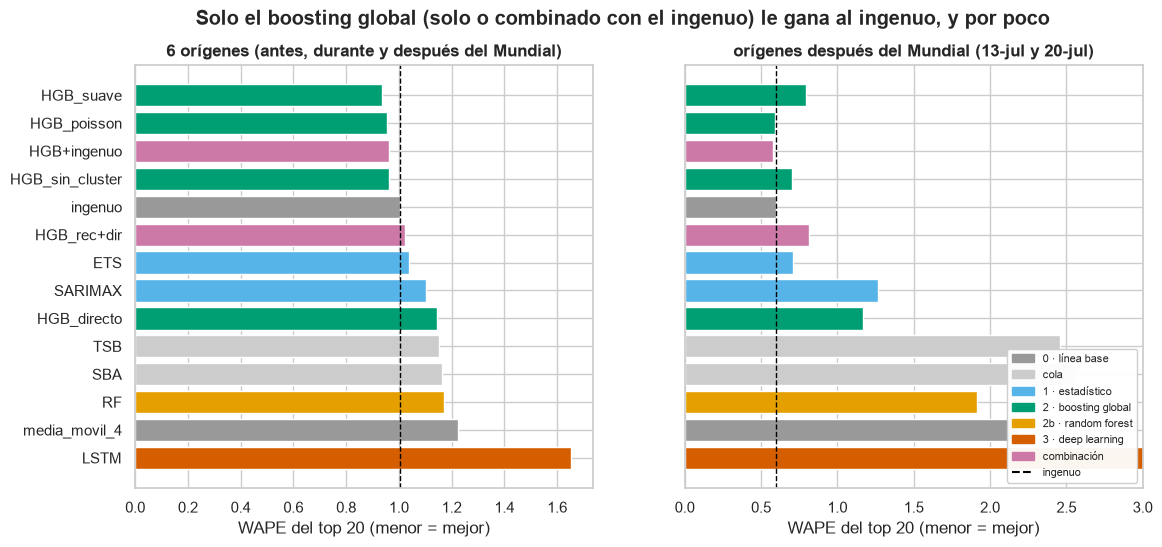

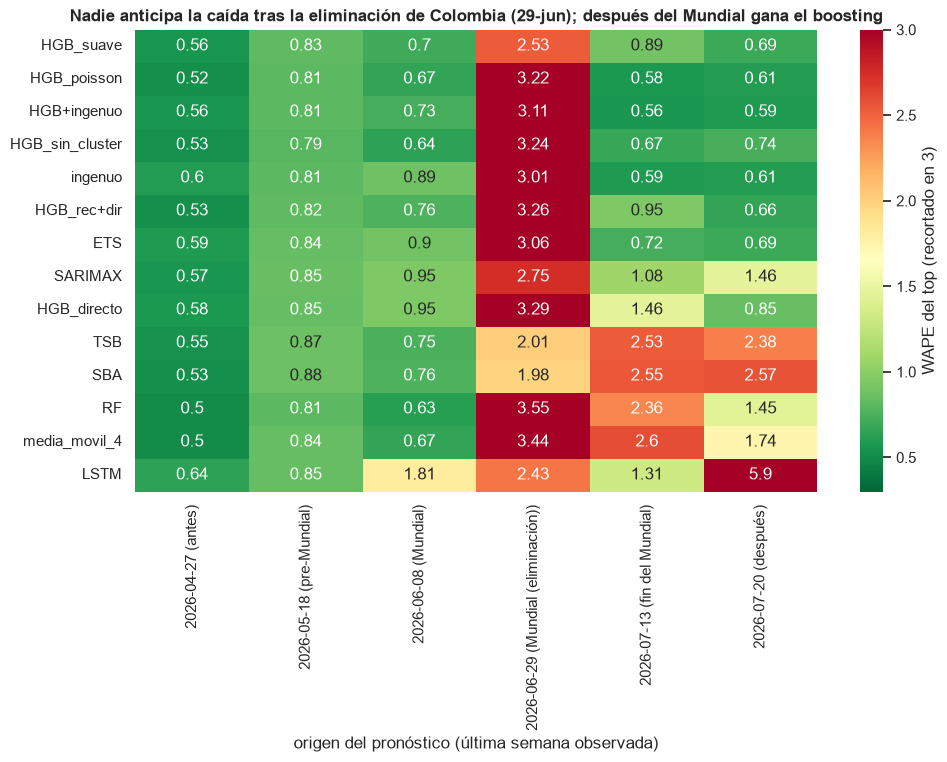

In [60]:
# 5.5.3 Gráficas de la comparación
COLOR_NIVEL = {"0 · línea base": "#999999", "cola": "#CCCCCC", "1 · estadístico": OKABE_ITO[5], "2 · boosting global": OKABE_ITO[2],
               "2b · random forest": OKABE_ITO[1], "3 · deep learning": OKABE_ITO[3], "combinación": OKABE_ITO[4]}
_r = resumen.sort_values("WAPE_top", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, col, titulo in [(axes[0], "WAPE_top", "6 orígenes (antes, durante y después del Mundial)"),
                        (axes[1], "WAPE_top_post", "orígenes después del Mundial (13-jul y 20-jul)")]:
    ax.barh(_r.index, _r[col], color=_r["nivel"].map(COLOR_NIVEL))
    ax.axvline(resumen.loc["ingenuo", col], color="black", ls="--", lw=1, label="ingenuo")
    ax.set(title=titulo, xlabel="WAPE del top 20 (menor = mejor)")
    ax.set_xlim(0, min(_r[col].max() * 1.05, 3))
from matplotlib.patches import Patch
_leyenda = [Patch(color=c, label=n) for n, c in COLOR_NIVEL.items()] + [plt.Line2D([], [], color="black", ls="--", label="ingenuo")]
axes[1].legend(handles=_leyenda, fontsize=8, loc="lower right", framealpha=.95)
fig.suptitle("Solo el boosting global (solo o combinado con el ingenuo) le gana al ingenuo, y por poco", fontweight="bold")
guardar_fig(fig, "5_5_01_wape_por_modelo"); plt.show()

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(por_origen.clip(upper=3), annot=por_origen.round(2), fmt="", cmap="RdYlGn_r", vmin=0.3, vmax=3,
            cbar_kws={"label": "WAPE del top (recortado en 3)"}, ax=ax)
ax.set(title="Nadie anticipa la caída tras la eliminación de Colombia (29-jun); después del Mundial gana el boosting",
       xlabel="origen del pronóstico (última semana observada)", ylabel="")
guardar_fig(fig, "5_5_02_wape_modelo_origen"); plt.show()

### 5.6 Intervalos de predicción (cuantiles)
Se entrenan tres boostings con pérdida cuantil (0,1 / 0,5 / 0,9) que se evalúan sobre la **misma trayectoria recursiva** del modelo
Poisson. Hubo dos ajustes necesarios:
- Los cuantiles se entrenan solo con catálogos **activos + top**. Con el 84 % de las filas en cero, la mediana global es 0.
- Se usan **sin regularización L2**. Con pérdida cuantil los gradientes valen ±τ y `l2_regularization = 1` dejaba las hojas en cero:
  el q50 de Honda salía 0 cuando vende ~35 uds/semana.

Una cobertura del 10–90 % menor al 80 % indica que el intervalo es demasiado angosto. §6 debe recalibrarlo si se va a usar para stock de seguridad.

In [61]:
# 5.6 Intervalos de predicción: HGB con pérdida cuantil (0,1 / 0,5 / 0,9) sobre la trayectoria del modelo principal
CUANTILES = (0.1, 0.5, 0.9)
# Sin L2: con la pérdida cuantil los gradientes valen ±τ y l2_regularization = 1 deja las hojas en ~0 (se comprobó: q50 = 0 en Honda)
PARAMS_CUANTIL = {**PARAMS_HGB, "loss": "quantile", "l2_regularization": 0.0, "learning_rate": 0.1}


def m_hgb_cuantiles(corte, h, ctx, variables=None):
    variables = variables or VARIABLES_MODELO
    X, y = datos_entrenamiento(ctx, corte, variables)
    modelos = {"pred": HistGradientBoostingRegressor(**PARAMS_HGB).fit(X, y)}
    # Los cuantiles se entrenan solo con catálogos activos + top: con el 84 % de filas en cero, la mediana global sería 0
    Xa, ya = datos_entrenamiento(ctx, corte, variables, solo_activos=True)
    for q in CUANTILES:
        modelos[f"q{int(q * 100)}"] = HistGradientBoostingRegressor(**{**PARAMS_CUANTIL, "quantile": q}).fit(Xa, ya)
    pr = pronostico_recursivo(modelos, corte, h, variables, ctx["maestro"], catalogos=ctx["activos"], p_y=ctx["p_y"])
    out = _completar(pr, ctx, corte, h)
    q = out[["q10", "q50", "q90"]].values
    out[["q10", "q50", "q90"]] = np.sort(q, axis=1)                    # evita cuantiles cruzados
    return out


def pinball(y, q, tau):
    d = y - q
    return np.mean(np.maximum(tau * d, (tau - 1) * d))


_cq = []
for corte in CORTES_VALIDACION:
    p = m_hgb_cuantiles(corte, H, contexto(corte))
    real = panel_y[(panel_y["semana"] > corte) & (panel_y["semana"] <= corte + SEMANA * H)][["catalogo", "semana", "y"]]
    _cq.append(real.merge(p, on=["catalogo", "semana"], how="left").fillna(0).assign(corte=corte))
res_cuantiles = pd.concat(_cq, ignore_index=True)
_rq = res_cuantiles[res_cuantiles["catalogo"].isin(TOP)]
cobertura = (_rq.assign(dentro=(_rq["y"] >= _rq["q10"]) & (_rq["y"] <= _rq["q90"]), familia=_rq["catalogo"].map(maestro["familia"]))
             .groupby("corte").agg(cobertura_80=("dentro", "mean"), uds_reales=("y", "sum"), q50=("q50", "sum"), q90=("q90", "sum")))
print(f"Cobertura del intervalo 10–90 % en el top (nominal 80 %): {((_rq.y >= _rq.q10) & (_rq.y <= _rq.q90)).mean():.0%}")
print("Pérdida pinball (top):", {f"q{int(t*100)}": round(float(pinball(_rq.y, _rq[f'q{int(t*100)}'], t)), 2) for t in CUANTILES})
cobertura.round(2)

Cobertura del intervalo 10–90 % en el top (nominal 80 %): 49%
Pérdida pinball (top): {'q10': 7.29, 'q50': 14.59, 'q90': 13.66}


,cobertura_80,uds_reales,q50,q90
corte,,,,
2026-04-27,0.670,2101,"1,094.340","2,361.900"
2026-05-18,0.620,5595,"1,376.260","2,402.360"
2026-06-08,0.500,4605,"2,669.890","6,547.490"
2026-06-29,0.260,1741,"2,625.670","5,751.160"
2026-07-13,0.410,1261,"1,427.290","2,769.880"
2026-07-20,0.500,1177,"1,296.140","2,465.460"


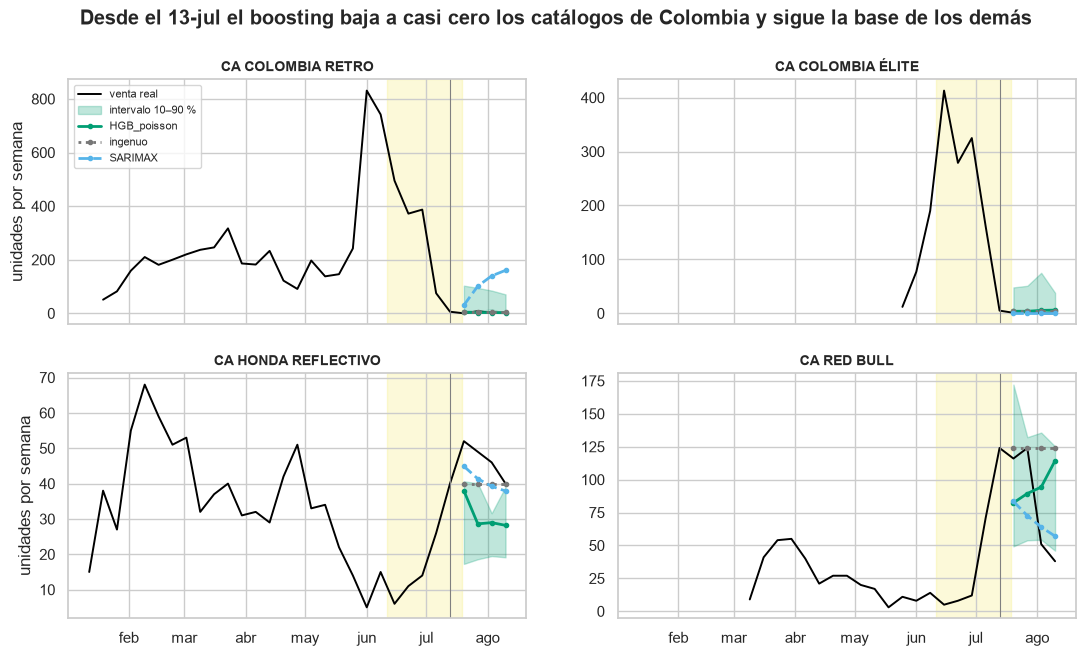

In [62]:
# 5.6.2 Real frente a pronóstico, con intervalo 10–90 %, en el origen de fin del Mundial (13-jul)
_corte_g = pd.Timestamp("2026-07-13")
_cats_g = [TOP[0], TOP[2], TOP[3], TOP[5]]           # dos de Colombia y dos de la base (Honda, Red Bull)
_q = res_cuantiles[res_cuantiles["corte"] == _corte_g].set_index(["catalogo", "semana"])
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for ax, c in zip(axes.flat, _cats_g):
    hist = panel_y[(panel_y["catalogo"] == c) & (panel_y["semana"] <= _corte_g + SEMANA * H)].set_index("semana")["y"]
    ax.plot(hist.index, hist.values, color="black", lw=1.4, label="venta real")
    q = _q.loc[c]
    ax.fill_between(q.index, q["q10"], q["q90"], color=OKABE_ITO[2], alpha=.25, label="intervalo 10–90 %")
    for m, color, ls in [("HGB_poisson", OKABE_ITO[2], "-"), ("ingenuo", "#777777", ":"), ("SARIMAX", OKABE_ITO[5], "--")]:
        p = res[(res["modelo"] == m) & (res["corte"] == _corte_g) & (res["catalogo"] == c)].sort_values("semana")
        ax.plot(p["semana"], p["pred"], color=color, ls=ls, lw=2, marker="o", ms=3, label=m)
    ax.axvline(_corte_g, color="grey", lw=.8)
    sombrear_mundial(ax, alpha=.2, etiqueta=False)
    ax.set_title(c.replace("CUELLO ALTO ", "CA "), fontsize=10); ax.xaxis.set_major_formatter(FMT_MES)
axes[0, 0].legend(fontsize=8, loc="upper left"); axes[0, 0].set_ylabel("unidades por semana"); axes[1, 0].set_ylabel("unidades por semana")
fig.suptitle("Desde el 13-jul el boosting baja a casi cero los catálogos de Colombia y sigue la base de los demás", fontweight="bold")
guardar_fig(fig, "5_6_01_real_vs_pronostico_fin_mundial"); plt.show()

### 5.7 Separar base y evento con el modelo (ruta 2 del plan §4.5)
El boosting se entrena con todo lo anterior al holdout. Desde la semana anterior a la ventana del evento (18-may) se pronostica la
ventana completa (8 semanas) dos veces:
1. Con el calendario real: **con evento**.
2. Con `escenario_sin_evento()`: las 6 variables del Mundial en 0, es decir, **sin evento**.

Como los rezagos vienen de la propia trayectoria, el escenario sin evento **no arrastra** la venta del Mundial. Esto resuelve la advertencia
del reporte de §4 (punto 7) sobre el contrafactual "no puro". La base se compara con la línea base interpolada de §4.5 (ruta 1).
Los catálogos que nacieron dentro de la ventana se separan: el modelo no tiene cómo pronosticarlos desde el 18-may.

In [63]:
# 5.7 Base frente a evento con el modelo (ruta 2 del plan §4.5) y comparación con la ruta 1 (§4.5)
# Modelo entrenado con todo lo anterior al holdout. Desde la semana previa a la ventana se pronostica recursivamente
# la ventana completa dos veces: con el calendario real y con las variables del Mundial apagadas. Como los rezagos
# salen de la propia trayectoria, el escenario "sin evento" es un contrafactual limpio (no arrastra la venta del Mundial).
CORTE_ENTRENAMIENTO = SEMANA_INICIO_HOLDOUT - SEMANA
ctx_final = contexto(CORTE_ENTRENAMIENTO)
modelo_ruta2 = ajustar_hgb(ctx_final, CORTE_ENTRENAMIENTO)
_origen_v = VENTANA_EVENTO.min() - SEMANA
_cats_v = sorted(set(panel_y.loc[panel_y["semana"].isin(VENTANA_EVENTO), "catalogo"]))
_p_y_v = construir_panel(cat_ok, _origen_v)
_args = dict(corte=_origen_v, h=len(VENTANA_EVENTO), variables=VARIABLES_MODELO, m=ctx_final["maestro"], p_y=_p_y_v)
_con = pronostico_recursivo({"con_evento": modelo_ruta2}, **_args)
_sin = pronostico_recursivo({"sin_evento": modelo_ruta2}, transformar=escenario_sin_evento, **_args)
ruta2 = (_con.merge(_sin, on=["catalogo", "semana", "h"])
         .merge(base_evento[["catalogo", "semana", "y", "y_base", "y_evento"]], on=["catalogo", "semana"], how="right")
         .query("semana in @VENTANA_EVENTO").fillna({"con_evento": 0, "sin_evento": 0}))
ruta2["familia"] = ruta2["catalogo"].map(maestro["familia"])
ruta2["evento_modelo"] = ruta2["con_evento"] - ruta2["sin_evento"]
# Los catálogos que nacieron dentro de la ventana no tienen historia en el origen: el modelo no puede pronosticarlos
ruta2["grupo"] = np.where(ruta2["catalogo"].isin(_p_y_v["catalogo"].unique()), "existía antes", "nació en la ventana")

comparacion_rutas = ruta2.groupby(["grupo", "familia"]).agg(
    uds_reales=("y", "sum"), base_ruta1=("y_base", "sum"), evento_ruta1=("y_evento", "sum"),
    pron_con_evento=("con_evento", "sum"), base_ruta2=("sin_evento", "sum"), evento_ruta2=("evento_modelo", "sum"))
print(f"Modelo entrenado hasta {CORTE_ENTRENAMIENTO.date()}; trayectorias desde {_origen_v.date()} ({len(VENTANA_EVENTO)} semanas).")
comparacion_rutas.round(0)

Modelo entrenado hasta 2026-08-17; trayectorias desde 2026-05-18 (8 semanas).


uds_reales  base_ruta1  evento_ruta1  pron_con_evento  base_ruta2  evento_ruta2
grupo               familia                                                                                  
existía antes       COLOMBIA   6,082.000     980.000     5,102.000        3,430.000   1,194.000     2,236.000
                    RESTO      2,491.000   3,008.000      -517.000        2,826.000   2,837.000       -11.000
nació en la ventana COLOMBIA   1,484.000       4.000     1,480.000            0.000       0.000         0.000
                    RESTO        240.000       3.000       237.000            0.000       0.000         0.000

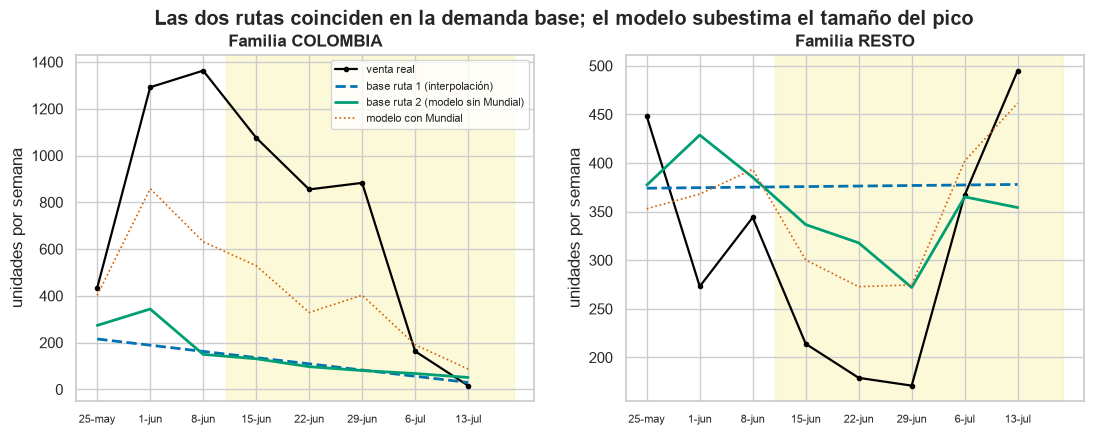

In [64]:
# 5.7.2 Gráfica: las dos rutas, semana a semana (catálogos que existían antes de la ventana)
FMT_DIA = matplotlib.ticker.FuncFormatter(lambda x, pos: f"{mdates.num2date(x).day}-{MESES_ES[mdates.num2date(x).month - 1]}")
_e = ruta2[ruta2["grupo"] == "existía antes"].groupby(["familia", "semana"])[["y", "y_base", "con_evento", "sin_evento"]].sum()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, fam in zip(axes, ["COLOMBIA", "RESTO"]):
    d = _e.loc[fam]
    ax.plot(d.index, d["y"], color="black", lw=1.6, marker="o", ms=3, label="venta real")
    ax.plot(d.index, d["y_base"], color=COLOR_FAMILIA["RESTO"], ls="--", lw=2, label="base ruta 1 (interpolación)")
    ax.plot(d.index, d["sin_evento"], color=OKABE_ITO[2], lw=2, label="base ruta 2 (modelo sin Mundial)")
    ax.plot(d.index, d["con_evento"], color=COLOR_FAMILIA["COLOMBIA"], lw=1.2, ls=":", label="modelo con Mundial")
    sombrear_mundial(ax, alpha=.2, etiqueta=False)
    ax.set(title=f"Familia {fam}", ylabel="unidades por semana")
    ax.set_xticks(d.index); ax.xaxis.set_major_formatter(FMT_DIA); ax.tick_params(axis="x", labelsize=8)
axes[0].legend(fontsize=8)
fig.suptitle("Las dos rutas coinciden en la demanda base; el modelo subestima el tamaño del pico", fontweight="bold")
guardar_fig(fig, "5_7_01_base_evento_dos_rutas"); plt.show()

### 5.8 Jerarquía: de catálogo a talla × color y a tela
- **Hacia abajo:** el pronóstico de cada catálogo se reparte con las proporciones talla × color de las últimas 12 semanas
  (`proporciones_mezcla` de §4.2.2). Esto da la tabla con la que se planean los cortes.
- **Hacia arriba:** se suma por género × tela × color con `mapa_tela` (proporción reciente; si no hay venta reciente, la histórica).
  Esto da la compra de insumo.

Se valida en el último origen (20-jul): ¿cuánto error se agrega al bajar de catálogo a talla × color?

In [65]:
# 5.8 Jerarquía: desagregación a talla × color (hacia abajo) y agregación a tela (hacia arriba)
def desagregar_talla_color(pron, corte, col="pred"):
    """Reparte el pronóstico de cada catálogo con las proporciones talla × color de las últimas semanas hasta el corte
    (`proporciones_mezcla` de §4.2.2: 12 semanas, suavizado 0,5, toda la historia si hubo < 30 uds)."""
    prop = proporciones_mezcla(cat_completas, pron["catalogo"].unique(), corte)
    d = pron.merge(prop[["catalogo", "talla_std", "color", "prop"]], on="catalogo")
    d[f"{col}_tc"] = d[col] * d["prop"]
    return d


def agregar_tela(pron, col="pred"):
    """Suma el pronóstico por género × tela × color con las proporciones de corte de cada catálogo (§4.2.2)."""
    mt = mapa_tela.copy()
    mt["prop"] = mt["prop_reciente"].fillna(mt["prop_historia"])
    d = pron.merge(mt[["catalogo", "genero", "tela", "color_ref", "prop"]], on="catalogo")
    d[f"{col}_tela"] = d[col] * d["prop"]
    return d.groupby(["semana", "genero", "tela", "color_ref"], as_index=False)[f"{col}_tela"].sum()


# Validación de la desagregación en el último origen de validación: ¿se pierde mucha precisión al bajar a talla × color?
_corte_d = CORTES_VALIDACION[-1]
_pr = res[(res["modelo"] == "HGB_poisson") & (res["corte"] == _corte_d) & res["catalogo"].isin(TOP)][["catalogo", "semana", "pred"]]
desag = desagregar_talla_color(_pr, _corte_d)
_real_tc = (cat_completas[cat_completas["catalogo"].isin(TOP) & cat_completas["semana"].isin(_pr["semana"].unique())]
            .groupby(["catalogo", "semana", "talla_std", "color"])["cantidad_total"].sum().rename("y_tc"))
_val_tc = desag.set_index(["catalogo", "semana", "talla_std", "color"]).join(_real_tc, how="outer").fillna({"pred_tc": 0, "y_tc": 0})
_wape_cat = metricas(_val_tc.groupby(["catalogo", "semana"])[["y_tc", "pred_tc"]].sum().reset_index(), "y_tc", "pred_tc")["WAPE"]
_wape_tc = metricas(_val_tc.reset_index(), "y_tc", "pred_tc")["WAPE"]
_wape_tc_4s = metricas(_val_tc.groupby(["catalogo", "talla_std", "color"])[["y_tc", "pred_tc"]].sum().reset_index(), "y_tc", "pred_tc")["WAPE"]
assert np.isclose(desag["pred_tc"].sum(), _pr["pred"].sum())
print(f"Origen {_corte_d.date()} (top): WAPE catálogo × semana {_wape_cat:.2f} → catálogo × talla × color × semana {_wape_tc:.2f} "
      f"| talla × color sumando las 4 semanas (lo que se compra): {_wape_tc_4s:.2f}")
_tela = agregar_tela(_pr)
print(f"Agregado a tela: {len(_tela)} filas (semana × género × tela × color); unidades conservadas: "
      f"{np.isclose(_tela['pred_tela'].sum(), _pr['pred'].sum())}")
(desag.groupby(["catalogo", "talla_std"])["pred_tc"].sum().unstack().reindex(columns=SIGLAS_TALLA).dropna(axis=1, how="all")
 .loc[TOP[:6]].round(0))

Origen 2026-07-20 (top): WAPE catálogo × semana 0.61 → catálogo × talla × color × semana 1.02 | talla × color sumando las 4 semanas (lo que se compra): 0.70
Agregado a tela: 124 filas (semana × género × tela × color); unidades conservadas: True


talla_std,4,6,8,10,12,14,16,XS,S,M,L,XL,2XL,3XL
catalogo,,,,,,,,,,,,,,
CUELLO ALTO COLOMBIA RETRO,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,1.000,1.000,0.000,0.000
CUELLO ALTO COLOMBIA,NaN,0.000,0.000,NaN,0.000,0.000,0.000,0.000,1.000,1.000,1.000,1.000,0.000,0.000
CUELLO ALTO COLOMBIA ÉLITE,NaN,NaN,NaN,0.000,NaN,0.000,NaN,0.000,2.000,4.000,3.000,2.000,1.000,0.000
CUELLO ALTO HONDA REFLECTIVO,0.000,NaN,NaN,NaN,NaN,NaN,NaN,5.000,30.000,63.000,71.000,60.000,23.000,14.000
CUELLO ALTO YAMAHA REFLECTIVO,NaN,NaN,1.000,NaN,NaN,NaN,NaN,4.000,11.000,40.000,28.000,16.000,9.000,3.000
CUELLO ALTO RED BULL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000,48.000,103.000,117.000,61.000,21.000,18.000


### 5.9 ¿Qué usa el modelo? Importancia por permutación
Se mide cuánto empeora el MAE del pronóstico a 1 semana si se desordena cada variable. Se usa el modelo entrenado al 20-jul y las 4 semanas siguientes.
Después del Mundial las variables de evento valen 0 en todas las filas, así que su importancia aquí es 0 **por construcción**:
eso no significa que no sirvan dentro del evento.

In [66]:
# 5.9 ¿Qué usa el modelo? Importancia por permutación (pronóstico a 1 semana, después del Mundial, top + activos)
_corte_i = CORTES_VALIDACION[-1]
_ctx_i = contexto(_corte_i)
_mod_i = ajustar_hgb(_ctx_i, _corte_i)
_fin_i = _corte_i + SEMANA * H
_p_i = agregar_variables(construir_panel(cat_ok, _fin_i), _ctx_i["maestro"], cal_modelo, ultima_observada=_fin_i)
_ev = _p_i[(_p_i["semana"] > _corte_i) & _p_i["catalogo"].isin(set(_ctx_i["activos"]) | set(TOP))]
_imp = permutation_importance(_mod_i, matriz_X(_ev, VARIABLES_MODELO, _ctx_i["maestro"]), _ev["y"],
                              scoring="neg_mean_absolute_error", n_repeats=10, random_state=SEMILLA, n_jobs=-1)
importancia = (pd.DataFrame({"variable": VARIABLES_MODELO, "aumento_MAE": _imp.importances_mean, "desv": _imp.importances_std})
               .sort_values("aumento_MAE", ascending=False).reset_index(drop=True))
print(f"Evaluado en {len(_ev):,} filas ({_corte_i.date()} + 1…{H} semanas, rezagos reales: mide el aporte a 1 paso).")
importancia.head(15).round(3)

Evaluado en 1,308 filas (2026-07-20 + 1…4 semanas, rezagos reales: mide el aporte a 1 paso).


,variable,aumento_MAE,desv
0,desv_4,0.671,0.080
1,cluster,0.356,0.044
2,lag_1,0.353,0.043
3,semanas_desde_ultima_venta,0.296,0.044
4,lag_4,0.055,0.005
5,lag_2,0.052,0.005
6,semanas_desde_lanzamiento,0.041,0.021
7,linea,0.031,0.051
8,desv_8,0.031,0.005
9,media_4,0.028,0.012


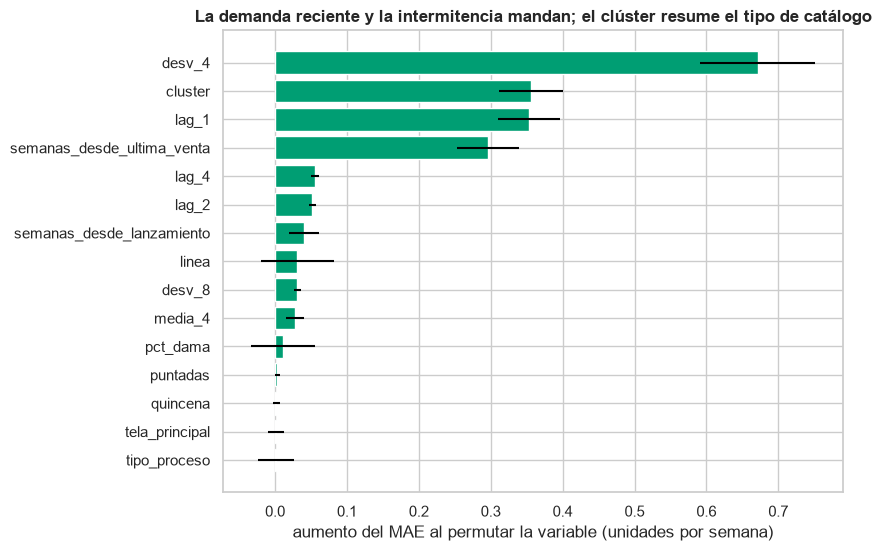

In [67]:
# 5.9.2 Gráfica de importancia
_i = importancia.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(_i["variable"], _i["aumento_MAE"], xerr=_i["desv"], color=OKABE_ITO[2])
ax.set(title="La demanda reciente y la intermitencia mandan; el clúster resume el tipo de catálogo",
       xlabel="aumento del MAE al permutar la variable (unidades por semana)")
guardar_fig(fig, "5_9_01_importancia_permutacion"); plt.show()

### 5.10 Selección del candidato (criterio del plan §5.7)
1. **WAPE del top.** Con 6 orígenes, diferencias menores al 5 % no son concluyentes: esos modelos se consideran empatados.
2. Entre los empatados gana el de **menor WAPE después del Mundial** (que no siga pronosticando demanda de evento).
3. Se reportan el **sesgo** y la **simplicidad**.

Para la **cola** se elige, entre las reglas simples (nivel 0 y cola), la de menor WAPE a nivel catálogo.
§6 confirma o cambia esta elección con el backtesting de origen móvil y el holdout.

In [68]:
# 5.10.1 Regla de selección (plan §5.7), aplicada sobre la validación preliminar
# 1) WAPE del top: se consideran empatados los modelos a menos de 5 % del mejor (6 orígenes son pocos para separar más);
# 2) entre ellos gana el de menor WAPE después del Mundial (criterio 3: no seguir pronosticando demanda de evento);
# 3) el sesgo y la simplicidad se reportan. La cola se decide por el WAPE de la cola a nivel catálogo.
TOLERANCIA_EMPATE = 0.05
_cand = resumen[resumen["WAPE_top"] <= resumen["WAPE_top"].min() * (1 + TOLERANCIA_EMPATE)]
MODELO_CANDIDATO = _cand["WAPE_top_post"].idxmin()
_cola = resumen[resumen["nivel"].isin(["0 · línea base", "cola"])]
MODELO_COLA = _cola["WAPE_cola"].idxmin()
seleccion = _cand[["nivel", "WAPE_top", "sesgo_top", "MASE_top", "WAPE_top_post", "uds_Colombia_post_real", "uds_Colombia_post_pron"]]
print(f"Empatados en WAPE del top (≤ {resumen['WAPE_top'].min() * (1 + TOLERANCIA_EMPATE):.3f}): {list(_cand.index)}")
print(f"➡ Candidato para el top: {MODELO_CANDIDATO} | regla para la cola: {MODELO_COLA}")
print("Se confirma (o se cambia) en §6 con el backtesting de origen móvil completo y el holdout.")
seleccion.round(3)

Empatados en WAPE del top (≤ 0.981): ['HGB_suave', 'HGB_poisson', 'HGB+ingenuo', 'HGB_sin_cluster']
➡ Candidato para el top: HGB+ingenuo | regla para la cola: ingenuo
Se confirma (o se cambia) en §6 con el backtesting de origen móvil completo y el holdout.


,nivel,WAPE_top,sesgo_top,MASE_top,WAPE_top_post,uds_Colombia_post_real,uds_Colombia_post_pron
modelo,,,,,,,
HGB_suave,2 · boosting global,0.935,0.032,1.621,0.796,49,192.557
HGB_poisson,2 · boosting global,0.955,0.121,1.566,0.591,49,90.010
HGB+ingenuo,combinación,0.963,0.118,1.542,0.576,49,87.005
HGB_sin_cluster,2 · boosting global,0.964,0.132,1.631,0.705,49,121.039


In [69]:
# 5.10.2 Exportación para §6–§8
_exportar5 = {
    "5_predicciones_validacion.csv": res,
    "5_metricas_validacion.csv": resumen.reset_index(),
    "5_wape_por_origen.csv": por_origen.reset_index(),
    "5_cuantiles_validacion.csv": res_cuantiles,
    "5_base_evento_dos_rutas.csv": ruta2,
    "5_comparacion_rutas.csv": comparacion_rutas.reset_index(),
    "5_desagregacion_talla_color_validacion.csv": desag,
    "5_importancia_permutacion.csv": importancia,
}
for nombre, df in _exportar5.items():
    df.to_csv(RUTAS["procesado"] / nombre, index=False, encoding="utf-8")
    print(f"{nombre:<46} {len(df):>7,} filas")

5_predicciones_validacion.csv                  198,296 filas
5_metricas_validacion.csv                           14 filas
5_wape_por_origen.csv                               14 filas
5_cuantiles_validacion.csv                      14,164 filas


5_base_evento_dos_rutas.csv                      4,489 filas
5_comparacion_rutas.csv                              4 filas
5_desagregacion_talla_color_validacion.csv       2,316 filas
5_importancia_permutacion.csv                       37 filas


### 5.11 Hallazgos del modelado (para redactar con palabras propias)

In [70]:
_rc = comparacion_rutas.loc["existía antes"]
h5 = {
    "validación preliminar (orígenes, horizonte)": f"{len(CORTES_VALIDACION)} orígenes {CORTES_VALIDACION.min().date()} → {CORTES_VALIDACION.max().date()}, {H} semanas; holdout sin tocar",
    "candidato top / regla cola": f"{MODELO_CANDIDATO} / {MODELO_COLA}",
    "WAPE top: candidato / HGB_poisson / ingenuo": tuple(round(float(resumen.loc[m, "WAPE_top"]), 3) for m in [MODELO_CANDIDATO, "HGB_poisson", "ingenuo"]),
    "WAPE top después del Mundial: candidato / HGB_poisson / ingenuo": tuple(round(float(resumen.loc[m, "WAPE_top_post"]), 3) for m in [MODELO_CANDIDATO, "HGB_poisson", "ingenuo"]),
    "sesgo top del candidato": round(float(resumen.loc[MODELO_CANDIDATO, "sesgo_top"]), 3),
    "Colombia después del Mundial (uds reales vs. HGB / SARIMAX / media móvil)": (int(resumen.loc["HGB_poisson", "uds_Colombia_post_real"]),
        *[int(resumen.loc[m, "uds_Colombia_post_pron"]) for m in ["HGB_poisson", "SARIMAX", "media_movil_4"]]),
    "peor modelo (WAPE top)": f"{resumen['WAPE_top'].idxmax()} ({resumen['WAPE_top'].max():.2f})",
    "cobertura del intervalo 10–90 % (nominal 80 %)": f"{((_rq.y >= _rq.q10) & (_rq.y <= _rq.q90)).mean():.0%}",
    "base en la ventana, catálogos existentes (ruta 1 / ruta 2)": f"COLOMBIA {_rc.loc['COLOMBIA', 'base_ruta1']:,.0f} / {_rc.loc['COLOMBIA', 'base_ruta2']:,.0f} · RESTO {_rc.loc['RESTO', 'base_ruta1']:,.0f} / {_rc.loc['RESTO', 'base_ruta2']:,.0f}",
    "evento Colombia, catálogos existentes (ruta 1 / ruta 2)": f"{_rc.loc['COLOMBIA', 'evento_ruta1']:,.0f} / {_rc.loc['COLOMBIA', 'evento_ruta2']:,.0f}",
    "WAPE al bajar a talla × color (semana / 4 semanas)": f"{_wape_cat:.2f} → {_wape_tc:.2f} / {_wape_tc_4s:.2f}",
    "3 variables más importantes": importancia["variable"].head(3).tolist(),
}
for k, v in h5.items():
    print(f"- {k}: {v}")

- validación preliminar (orígenes, horizonte): 6 orígenes 2026-04-27 → 2026-07-20, 4 semanas; holdout sin tocar
- candidato top / regla cola: HGB+ingenuo / ingenuo
- WAPE top: candidato / HGB_poisson / ingenuo: (0.963, 0.955, 1.006)
- WAPE top después del Mundial: candidato / HGB_poisson / ingenuo: (0.576, 0.591, 0.6)
- sesgo top del candidato: 0.118
- Colombia después del Mundial (uds reales vs. HGB / SARIMAX / media móvil): (49, 90, 1871, 3990)
- peor modelo (WAPE top): LSTM (1.65)
- cobertura del intervalo 10–90 % (nominal 80 %): 49%
- base en la ventana, catálogos existentes (ruta 1 / ruta 2): COLOMBIA 980 / 1,194 · RESTO 3,008 / 2,837
- evento Colombia, catálogos existentes (ruta 1 / ruta 2): 5,102 / 2,236
- WAPE al bajar a talla × color (semana / 4 semanas): 0.61 → 1.02 / 0.70
- 3 variables más importantes: ['desv_4', 'cluster', 'lag_1']


## 6. Validación y métricas (Evaluation)

Esta sección confirma o cambia el candidato de §5 con dos pruebas, en este orden:

1. **Backtesting de origen móvil** (plan §6.1): se pronostica desde **todos los lunes** entre el 13-abr y el 20-jul (15 orígenes),
   4 semanas cada vez. El último pronóstico termina el 17-ago, la semana anterior al holdout. Hay orígenes antes, durante y después del Mundial.
2. **Holdout final** (24-ago → 28-sep, 6 semanas): se abre **una sola vez**, después de fijar el modelo con el backtesting.

Se mantienen las reglas de §5: en cada origen las variables (rezagos, medias móviles, clúster) se recalculan solo con información pasada
(`contexto(corte)`); los catálogos que nacen después del origen cuentan con pronóstico 0; no hay particiones aleatorias.

**Métricas** (plan §6.2): WAPE (principal); sesgo (positivo = sobrepronóstico, que es el inventario quedado que preocupa a Klixmant);
MASE y RMSSE (sin escala, frente al ingenuo de 1 semana); pérdida *pinball* para los intervalos. El MAPE no se usa porque se indefine con ceros.

In [71]:
# 6.1 Backtesting de origen móvil: todos los lunes posibles antes del holdout, horizonte de 4 semanas
RECALCULAR_BACKTESTING = True                  # False: lee procesado/6_backtesting_predicciones.csv (ahorra ~5 min)
PRIMER_CORTE_BT = pd.Timestamp("2026-04-13")   # ≥ 14 semanas de historia para rezagos, medias de 8 semanas y clúster
CORTES_BT = pd.date_range(PRIMER_CORTE_BT, CORTE_ENTRENAMIENTO - SEMANA * H, freq=DECISIONES["frecuencia"])
assert (CORTES_BT + SEMANA * H < SEMANA_INICIO_HOLDOUT).all(), "El backtesting no puede tocar el holdout"


def fase_origen(corte, h=H):
    """Ubica el origen frente a la ventana del evento (25-may → 13-jul) según las semanas que pronostica."""
    if corte + SEMANA * h < VENTANA_EVENTO.min():
        return "antes del evento"
    if corte >= VENTANA_EVENTO.max():
        return "después del evento"
    return "toca el evento"


def m_hgb_redondeo(corte, h, ctx):
    """Experimento del reporte 03 (punto 11): la trayectoria recursiva usa unidades enteras."""
    mod = ajustar_hgb(ctx, corte)
    pr = pronostico_recursivo({"pred": mod}, corte, h, VARIABLES_MODELO, ctx["maestro"], catalogos=ctx["activos"],
                              p_y=ctx["p_y"], redondear=True)
    return _completar(pr, ctx, corte, h)


_CTX_SIN_ATIPICO = {}


def contexto_sin_atipico(corte, k=4):
    """Contexto para entrenar y pronosticar tratando el Mundial como dato ATÍPICO (mentoría con Klixmant, 5-nov):
    "normalmente en junio no vendo eso; no me proyecten con ese dato". Solo aplica cuando el evento ya terminó (corte >= fin de la ventana):
    1) las semanas de la ventana del evento NO entran al entrenamiento;
    2) los rezagos y las medias móviles se calculan con una serie sin el pico: dentro de la ventana, la venta se recorta a la
       línea base de §4.5 (interpolación entre el nivel anterior y el posterior). Solo recorta, nunca infla.
    La línea base se calcula con datos <= corte (no hay fuga). Las líneas base (ingenuo, ETS…) siguen usando la serie real."""
    if corte < VENTANA_EVENTO.max():
        return contexto(corte)
    if corte not in _CTX_SIN_ATIPICO:
        ctx = contexto(corte)
        p_y = ctx["p_y"].copy()
        base = base_evento_panel(p_y[["catalogo", "semana", "y"]], VENTANA_EVENTO, k).set_index(["catalogo", "semana"])["y_base"]
        y_real = p_y["y"].values.astype(float)
        y_base = base.reindex(pd.MultiIndex.from_frame(p_y[["catalogo", "semana"]])).values
        y_limpia = np.where(p_y["semana"].isin(VENTANA_EVENTO).values, np.minimum(y_real, y_base), y_real)
        p_y["y_dropi"] = p_y["y_dropi"] * np.divide(y_limpia, y_real, out=np.ones(len(p_y)), where=y_real > 0)
        p_y["y"] = y_limpia
        panel_m = agregar_variables(p_y, ctx["maestro"], cal_modelo, ultima_observada=corte)
        _CTX_SIN_ATIPICO[corte] = {"panel": panel_m[~panel_m["semana"].isin(VENTANA_EVENTO)], "maestro": ctx["maestro"],
                                   "p_y": p_y, "activos": ctx["activos"]}
    return _CTX_SIN_ATIPICO[corte]


def m_hgb_sin_atipico(corte, h, ctx):
    """HGB_redondeo entrenado sin el atípico del Mundial. Antes del fin del evento es idéntico a HGB_redondeo."""
    c = contexto_sin_atipico(corte)
    mod = ajustar_hgb(c, corte)
    pr = pronostico_recursivo({"pred": mod}, corte, h, VARIABLES_MODELO, c["maestro"], catalogos=c["activos"],
                              p_y=c["p_y"], redondear=True)
    return _completar(pr, ctx, corte, h)


# Finalistas de §5 y referencias. SBA, TSB, RF, LSTM y HGB directo ya quedaron descartados en §5.
METODOS_BT = {"ingenuo": m_ingenuo, "media_movil_4": m_media_movil, "ETS": m_ets, "SARIMAX": m_sarimax,
              "HGB_poisson": m_hgb, "HGB_redondeo": m_hgb_redondeo, "HGB_sin_atipico": m_hgb_sin_atipico}
COMBINACIONES_BT = {"HGB+ingenuo": ["HGB_poisson", "ingenuo"]}
NIVEL_MODELO["HGB_redondeo"] = NIVEL_MODELO["HGB_sin_atipico"] = "2 · boosting global"


def completar_resultados(r, combinaciones=COMBINACIONES_BT, h=H):
    """Agrega las combinaciones y las etiquetas de periodo: fase del origen y si la semana objetivo cae en la ventana del evento."""
    r = pd.concat([r, *[combinar_resultados(r, ms, n) for n, ms in combinaciones.items()]], ignore_index=True)
    r["fase_origen"] = r["corte"].map(lambda c: fase_origen(c, h))
    r["periodo_semana"] = np.where(r["semana"].isin(VENTANA_EVENTO), "evento", "normal")
    return r


_ruta_bt = RUTAS["procesado"] / "6_backtesting_predicciones.csv"
_t0 = time.time()
if RECALCULAR_BACKTESTING or not _ruta_bt.exists():
    bt = completar_resultados(evaluar(METODOS_BT, CORTES_BT))
else:
    bt = pd.read_csv(_ruta_bt, parse_dates=["corte", "semana"])
    registrar_escalas(CORTES_BT)
print(f"Backtesting: {bt['modelo'].nunique()} métodos × {len(CORTES_BT)} orígenes ({CORTES_BT.min().date()} → "
      f"{CORTES_BT.max().date()}) × {H} semanas en {time.time() - _t0:.0f} s")
print("Orígenes por fase:", pd.Series([fase_origen(c) for c in CORTES_BT]).value_counts().to_dict())

C:\Users\diani\.venvs\klixmant\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


Backtesting: 8 métodos × 15 orígenes (2026-04-13 → 2026-07-20) × 4 semanas en 353 s
Orígenes por fase: {'toca el evento': 11, 'antes del evento': 2, 'después del evento': 2}


### 6.2 Resultados del backtesting
Además de las métricas de §5 se agregan:
- **RMSSE** (raíz del error cuadrático escalado, la base de la métrica de M5): como el MASE, pero castiga más los errores grandes.
- **Skill score** frente al ingenuo: 1 − métrica del modelo / métrica del ingenuo. Positivo = el modelo aporta.
- **Orígenes ganados**: en cuántos de los 15 orígenes el modelo tiene menor WAPE que el ingenuo.
- **Bootstrap por origen**: se remuestrean los 15 orígenes con reemplazo (2.000 veces) y se recalcula la diferencia de WAPE frente al ingenuo.
  Si el intervalo del 90 % incluye el 0, la mejora no es concluyente.
- WAPE por **fase del origen**: antes del evento, orígenes cuyo pronóstico toca la ventana del evento (25-may → 13-jul) y después del evento.

In [72]:
# 6.2.1 Métricas del backtesting (top 20): WAPE, sesgo, MASE, RMSSE, por fase del origen y frente al ingenuo
def escala_rmsse(p_y, corte):
    """Error cuadrático medio del ingenuo de 1 semana en la historia de cada catálogo (denominador del RMSSE, M5)."""
    p = p_y[p_y["semana"] <= corte].sort_values(["catalogo", "semana"])
    d = p.groupby("catalogo")["y"].diff() ** 2
    return d.groupby(p["catalogo"]).mean()


_ESCALAS_RMSSE = {}


def rmsse(d):
    """RMSSE promedio por catálogo × origen (solo series con escala > 0)."""
    for c in pd.to_datetime(d["corte"].unique()):
        if c not in _ESCALAS_RMSSE:
            _ESCALAS_RMSSE[c] = escala_rmsse(contexto(c)["p_y"], c)
    g = d.assign(e2=(d["pred"] - d["y"]) ** 2).groupby(["corte", "catalogo"], as_index=False)["e2"].mean()
    g["esc"] = [_ESCALAS_RMSSE[c].get(cat, np.nan) for c, cat in zip(g["corte"], g["catalogo"])]
    g = g[g["esc"] > 0]
    return float(np.sqrt(g["e2"] / g["esc"]).mean())


def tabla_completa(d, por=("modelo",)):
    """`tabla_metricas` de §5 más el RMSSE."""
    t = tabla_metricas(d, por=por)
    r = [{**dict(zip(por, k if isinstance(k, tuple) else (k,))), "RMSSE": rmsse(g)} for k, g in d.groupby(list(por))]
    return t.merge(pd.DataFrame(r), on=list(por))


def bootstrap_vs(d, modelo, ref="ingenuo", B=2000, semilla=SEMILLA):
    """Remuestrea orígenes con reemplazo y recalcula WAPE(modelo) − WAPE(ref).
    Devuelve el intervalo del 90 % y la proporción de remuestreos en que el modelo gana."""
    agg = (d[d["modelo"].isin([modelo, ref])].assign(ae=lambda x: (x["pred"] - x["y"]).abs())
           .groupby(["modelo", "corte"])[["ae", "y"]].sum())
    a = agg.loc[modelo]
    b = agg.loc[ref].reindex(a.index)
    idx = np.random.default_rng(semilla).integers(0, len(a), (B, len(a)))
    dif = (a["ae"].values[idx].sum(1) - b["ae"].values[idx].sum(1)) / a["y"].values[idx].sum(1)
    return np.percentile(dif, 5), np.percentile(dif, 95), (dif < 0).mean()


FASES = {"antes del evento": "WAPE_top_antes", "toca el evento": "WAPE_top_evento", "después del evento": "WAPE_top_post"}
bt_top = bt[bt["segmento"] == "top"]
resumen_bt = tabla_completa(bt_top).set_index("modelo")[["WAPE", "sesgo", "MASE", "RMSSE"]].add_suffix("_top")
for _fase, _col in FASES.items():
    resumen_bt[_col] = tabla_metricas(bt_top[bt_top["fase_origen"] == _fase]).set_index("modelo")["WAPE"]
_cp = tabla_metricas(bt_top[(bt_top["fase_origen"] == "después del evento") & (bt_top["familia"] == "COLOMBIA")]).set_index("modelo")
resumen_bt["uds_Colombia_post_real"] = _cp["uds_reales"]
resumen_bt["uds_Colombia_post_pron"] = _cp["uds_pronosticadas"]

_wo = tabla_metricas(bt_top, por=("modelo", "corte"))
wape_origen_bt = _wo.pivot(index="corte", columns="modelo", values="WAPE")
resumen_bt["origenes_gana_al_ingenuo"] = (wape_origen_bt.lt(wape_origen_bt["ingenuo"], axis=0)).sum()
resumen_bt["skill_WAPE_vs_ingenuo"] = 1 - resumen_bt["WAPE_top"] / resumen_bt.loc["ingenuo", "WAPE_top"]
resumen_bt["skill_MASE_vs_ingenuo"] = 1 - resumen_bt["MASE_top"] / resumen_bt.loc["ingenuo", "MASE_top"]
_bs = {m: bootstrap_vs(bt_top, m) for m in resumen_bt.index if m != "ingenuo"}
resumen_bt["dif_WAPE_vs_ingenuo_IC90"] = pd.Series({m: f"[{a:+.3f}, {b:+.3f}]" for m, (a, b, _) in _bs.items()})
resumen_bt["prob_gana_bootstrap"] = pd.Series({m: p for m, (_, _, p) in _bs.items()})

_cola_bt = bt[bt["segmento"] == "cola"]
resumen_bt["WAPE_cola"] = tabla_metricas(_cola_bt).set_index("modelo")["WAPE"]
_cola_ag = _cola_bt.groupby(["modelo", "corte", "semana"], as_index=False)[["y", "pred"]].sum()
resumen_bt["WAPE_cola_agregada"] = pd.Series({m: metricas(g)["WAPE"] for m, g in _cola_ag.groupby("modelo")})
resumen_bt.insert(0, "nivel", resumen_bt.index.map(NIVEL_MODELO))
resumen_bt = resumen_bt.sort_values("WAPE_top")
wape_origen_bt = wape_origen_bt[resumen_bt.index]
wape_origen_bt.insert(0, "fase", [fase_origen(c) for c in wape_origen_bt.index])

display(resumen_bt.round(3))
wape_origen_bt.round(2)

,nivel,WAPE_top,sesgo_top,MASE_top,RMSSE_top,WAPE_top_antes,WAPE_top_evento,WAPE_top_post,uds_Colombia_post_real,uds_Colombia_post_pron,origenes_gana_al_ingenuo,skill_WAPE_vs_ingenuo,skill_MASE_vs_ingenuo,dif_WAPE_vs_ingenuo_IC90,prob_gana_bootstrap,WAPE_cola,WAPE_cola_agregada
modelo,,,,,,,,,,,,,,,,,
HGB+ingenuo,combinación,0.880,0.010,1.655,1.451,0.424,0.936,0.576,49,87.005,12,0.030,-0.008,"[-0.067, +0.013]",0.863,1.325,0.220
HGB_redondeo,2 · boosting global,0.897,-0.017,1.730,1.518,0.469,0.952,0.585,49,75.252,9,0.011,-0.053,"[-0.062, +0.045]",0.598,1.189,0.281
HGB_poisson,2 · boosting global,0.899,-0.015,1.733,1.520,0.469,0.954,0.591,49,90.010,9,0.009,-0.056,"[-0.058, +0.045]",0.582,1.336,0.237
HGB_sin_atipico,2 · boosting global,0.907,-0.035,1.751,1.535,0.469,0.952,0.762,49,324.494,8,0.001,-0.066,"[-0.054, +0.056]",0.490,1.195,0.297
ingenuo,0 · línea base,0.907,0.035,1.642,1.431,0.439,0.965,0.600,49,84.000,0,0.000,0.000,NaN,NaN,1.361,0.239
ETS,1 · estadístico,0.934,-0.002,1.729,1.481,0.445,0.988,0.710,49,312.904,5,-0.029,-0.053,"[-0.014, +0.067]",0.144,1.599,0.291
SARIMAX,1 · estadístico,1.018,0.049,1.793,1.549,0.502,1.047,1.266,49,"1,871.345",4,-0.122,-0.092,"[+0.043, +0.193]",0.002,1.599,0.291
media_movil_4,0 · línea base,1.078,0.063,1.791,1.538,0.470,1.064,2.184,49,"3,990.000",4,-0.189,-0.091,"[+0.027, +0.375]",0.020,1.599,0.291


modelo,fase,HGB+ingenuo,HGB_redondeo,HGB_poisson,HGB_sin_atipico,ingenuo,ETS,SARIMAX,media_movil_4
corte,,,,,,,,,
2026-04-13,antes del evento,0.490,0.540,0.530,0.540,0.490,0.480,0.530,0.500
2026-04-20,antes del evento,0.360,0.400,0.400,0.400,0.390,0.410,0.470,0.440
2026-04-27,toca el evento,0.560,0.520,0.520,0.520,0.600,0.590,0.570,0.500
2026-05-04,toca el evento,0.680,0.700,0.710,0.700,0.690,0.690,0.730,0.690
2026-05-11,toca el evento,0.840,0.850,0.840,0.850,0.850,0.800,0.820,0.820
2026-05-18,toca el evento,0.810,0.810,0.810,0.810,0.810,0.840,0.850,0.840
2026-05-25,toca el evento,0.760,0.810,0.810,0.810,0.720,0.770,0.810,0.790
2026-06-01,toca el evento,0.450,0.500,0.500,0.500,0.600,0.670,0.800,0.610
2026-06-08,toca el evento,0.730,0.650,0.670,0.650,0.890,0.900,0.950,0.670


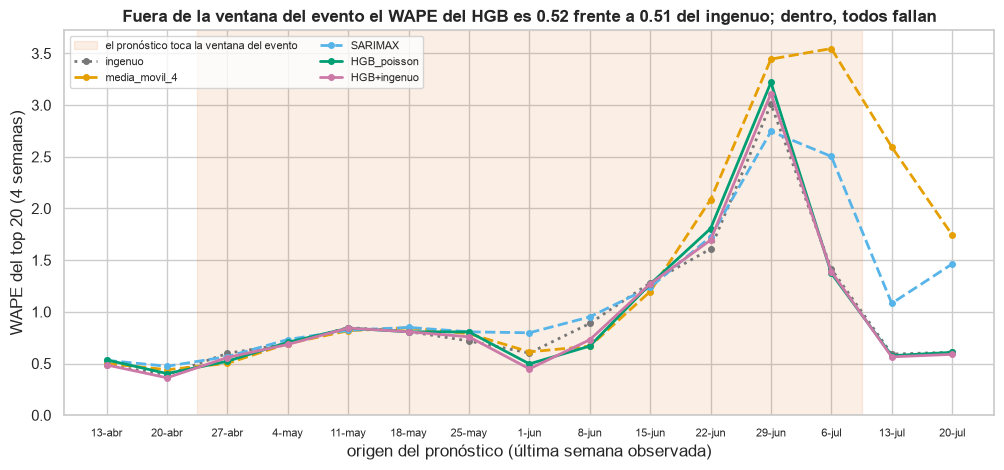

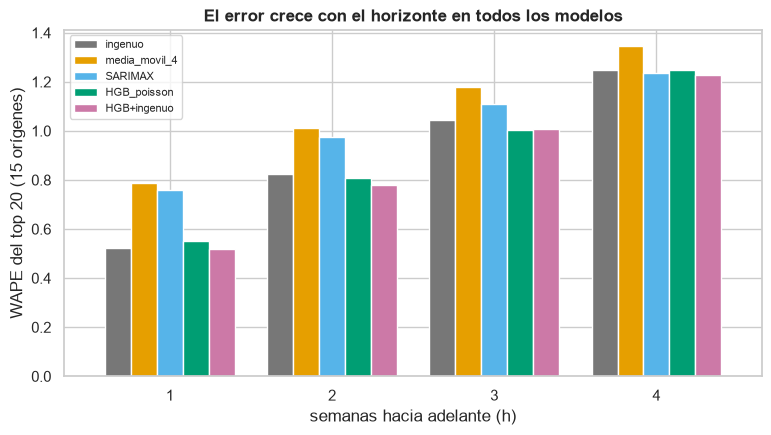

modelo,ingenuo,media_movil_4,SARIMAX,HGB_poisson,HGB+ingenuo
h,,,,,
1,0.523,0.788,0.761,0.551,0.518
2,0.824,1.013,0.976,0.809,0.779
3,1.046,1.177,1.108,1.005,1.007
4,1.249,1.345,1.237,1.246,1.229


In [73]:
# 6.2.2 Gráficas del backtesting: WAPE por origen y por horizonte
MODELOS_GRAFICA = ["ingenuo", "media_movil_4", "SARIMAX", "HGB_poisson", "HGB+ingenuo"]
ESTILO_MODELO = {"ingenuo": ("#777777", ":"), "media_movil_4": (OKABE_ITO[1], "--"), "ETS": (OKABE_ITO[6], "--"),
                 "SARIMAX": (OKABE_ITO[5], "--"), "HGB_poisson": (OKABE_ITO[2], "-"), "HGB_redondeo": (OKABE_ITO[0], "-."),
                 "HGB+ingenuo": (OKABE_ITO[4], "-"), "HGB_sin_atipico": (OKABE_ITO[3], "-")}
_toca = [c for c in CORTES_BT if fase_origen(c) == "toca el evento"]
_fuera = bt_top[bt_top["fase_origen"] != "toca el evento"]
_w_fuera = tabla_metricas(_fuera).set_index("modelo")["WAPE"]

fig, ax = plt.subplots(figsize=(12, 5))
ax.axvspan(min(_toca) - SEMANA / 2, max(_toca) + SEMANA / 2, color=COLOR_FAMILIA["COLOMBIA"], alpha=.1,
           label="el pronóstico toca la ventana del evento")
for m in MODELOS_GRAFICA:
    col, ls = ESTILO_MODELO[m]
    ax.plot(wape_origen_bt.index, wape_origen_bt[m], color=col, ls=ls, lw=2, marker="o", ms=4, label=m)
ax.set(ylim=(0, min(wape_origen_bt[MODELOS_GRAFICA].max().max() * 1.05, 4)), ylabel="WAPE del top 20 (4 semanas)",
       xlabel="origen del pronóstico (última semana observada)")
ax.set_xticks(CORTES_BT); ax.xaxis.set_major_formatter(FMT_DIA); ax.tick_params(axis="x", labelsize=8)
ax.legend(fontsize=8, ncol=2, loc="upper left")
ax.set_title(f"Fuera de la ventana del evento el WAPE del HGB es {_w_fuera['HGB_poisson']:.2f} frente a "
             f"{_w_fuera['ingenuo']:.2f} del ingenuo; dentro, todos fallan", fontweight="bold")
guardar_fig(fig, "6_2_01_wape_por_origen_backtesting"); plt.show()

_wh = (tabla_metricas(bt_top[bt_top["modelo"].isin(MODELOS_GRAFICA)], por=("modelo", "h"))
       .pivot(index="h", columns="modelo", values="WAPE")[MODELOS_GRAFICA])
fig, ax = plt.subplots(figsize=(9, 4.5))
_wh.plot.bar(ax=ax, color=[ESTILO_MODELO[m][0] for m in MODELOS_GRAFICA], width=.8, rot=0)
ax.set(xlabel="semanas hacia adelante (h)", ylabel="WAPE del top 20 (15 orígenes)",
       title="El error crece con el horizonte en todos los modelos")
ax.legend(fontsize=8)
guardar_fig(fig, "6_2_02_wape_por_horizonte"); plt.show()
_wh.round(3)

### 6.3 Selección del modelo final (se fija ANTES de abrir el holdout)
La regla es la de §5.10, ahora con 15 orígenes, más el criterio 4 del plan (simplicidad):

1. El enunciado exige un modelo de sklearn, keras o pytorch, así que el modelo final sale de la **familia HGB** (sola, con redondeo
   o combinada con el ingenuo). El ingenuo y los estadísticos quedan como referencia.
2. **WAPE del top:** se consideran empatados los modelos a menos del 5 % del mejor.
3. Entre los empatados, se queda con los que están a menos del 5 % del mejor **WAPE después del Mundial** (criterio 3: no seguir pronosticando evento).
4. Entre esos gana el **más simple** (HGB solo < HGB + ingenuo). Si hay empate en simplicidad, gana el de menor WAPE después del Mundial.

Para la **cola** se elige entre las reglas simples (ingenuo y media móvil) la de menor WAPE a nivel catálogo.
También se informa si el ingenuo queda empatado con el modelo final: en ese caso el modelo no le gana de forma clara a la línea base.

> **Actualización del 9-nov-2026 (después de la mentoría con Klixmant).** El dueño pidió no proyectar con el pico de junio–julio:
> el Mundial es cada cuatro años y esa venta es un **dato atípico**. Por eso se agrega un paso 0 a la regla:
> **el modelo final debe tratar el Mundial como atípico** (`HGB_sin_atipico`: mismas variables y parámetros que `HGB_redondeo`,
> pero una vez termina el evento sus semanas salen del entrenamiento y los rezagos se calculan sin el pico; ver `contexto_sin_atipico` en §6.1).
> Es una **decisión de negocio**, no un resultado de la regla estadística: la celda imprime también qué modelo habría elegido la regla sola.
> Como el holdout ya se había abierto cuando se tomó la decisión, sus cifras para este modelo son **indicativas**, no una prueba limpia.


In [74]:
# 6.3 Selección del modelo final con el backtesting (el holdout sigue cerrado)
COMPLEJIDAD = {"ingenuo": 0, "media_movil_4": 0, "ETS": 1, "SARIMAX": 1, "HGB_poisson": 2, "HGB_redondeo": 2, "HGB_sin_atipico": 2, "HGB+ingenuo": 3}
FAMILIA_SKLEARN = [m for m in resumen_bt.index if m.startswith("HGB")]
_c = resumen_bt.loc[FAMILIA_SKLEARN]
_paso1 = _c[_c["WAPE_top"] <= _c["WAPE_top"].min() * (1 + TOLERANCIA_EMPATE)]
_paso2 = _paso1[_paso1["WAPE_top_post"] <= _paso1["WAPE_top_post"].min() * (1 + TOLERANCIA_EMPATE)]
MODELO_REGLA = _paso2.assign(cx=_paso2.index.map(COMPLEJIDAD)).sort_values(["cx", "WAPE_top_post"]).index[0]
TRATAR_MUNDIAL_COMO_ATIPICO = True     # paso 0 (decisión de negocio del 9-nov, mentoría con Klixmant): no proyectar con el pico del Mundial
MODELO_FINAL = "HGB_sin_atipico" if TRATAR_MUNDIAL_COMO_ATIPICO else MODELO_REGLA
METODO_FINAL = {**METODOS_BT, "HGB+ingenuo": combinar(m_hgb, m_ingenuo)}[MODELO_FINAL]   # fn(corte, h, ctx) para §8
MODELO_COLA_FINAL = resumen_bt[resumen_bt["nivel"] == "0 · línea base"]["WAPE_cola"].idxmin()
INGENUO_EMPATA = bool(resumen_bt.loc["ingenuo", "WAPE_top"] <= resumen_bt.loc[MODELO_FINAL, "WAPE_top"] * (1 + TOLERANCIA_EMPATE))

print(f"Paso 2 (WAPE top ≤ {_c['WAPE_top'].min() * (1 + TOLERANCIA_EMPATE):.3f}): {list(_paso1.index)}")
print(f"Paso 3 (WAPE después del Mundial ≤ {_paso1['WAPE_top_post'].min() * (1 + TOLERANCIA_EMPATE):.3f}): {list(_paso2.index)}")
print(f"La regla estadística sola habría elegido: {MODELO_REGLA} (WAPE después del Mundial {resumen_bt.loc[MODELO_REGLA, 'WAPE_top_post']:.3f}; "
      f"{MODELO_FINAL}: {resumen_bt.loc[MODELO_FINAL, 'WAPE_top_post']:.3f} en los 2 orígenes pegados al fin del evento)")
print(f"➡ Modelo final para el top: {MODELO_FINAL} (candidato de §5: {MODELO_CANDIDATO}) | regla para la cola: {MODELO_COLA_FINAL} "
      f"(§5: {MODELO_COLA})")
print(f"¿El ingenuo queda empatado (a menos del 5 %) con el modelo final? {'sí' if INGENUO_EMPATA else 'no'} — "
      f"diferencia de WAPE IC 90 %: {resumen_bt.loc[MODELO_FINAL, 'dif_WAPE_vs_ingenuo_IC90']}, "
      f"orígenes ganados {resumen_bt.loc[MODELO_FINAL, 'origenes_gana_al_ingenuo']}/{len(CORTES_BT)}")
resumen_bt.loc[list(dict.fromkeys(FAMILIA_SKLEARN + [MODELO_FINAL, "ingenuo"])), ["WAPE_top", "sesgo_top", "MASE_top", "RMSSE_top", "WAPE_top_post",
                                               "uds_Colombia_post_real", "uds_Colombia_post_pron"]].round(3)

Paso 2 (WAPE top ≤ 0.924): ['HGB+ingenuo', 'HGB_redondeo', 'HGB_poisson', 'HGB_sin_atipico']
Paso 3 (WAPE después del Mundial ≤ 0.605): ['HGB+ingenuo', 'HGB_redondeo', 'HGB_poisson']
La regla estadística sola habría elegido: HGB_redondeo (WAPE después del Mundial 0.585; HGB_sin_atipico: 0.762 en los 2 orígenes pegados al fin del evento)
➡ Modelo final para el top: HGB_sin_atipico (candidato de §5: HGB+ingenuo) | regla para la cola: ingenuo (§5: ingenuo)
¿El ingenuo queda empatado (a menos del 5 %) con el modelo final? sí — diferencia de WAPE IC 90 %: [-0.054, +0.056], orígenes ganados 8/15


,WAPE_top,sesgo_top,MASE_top,RMSSE_top,WAPE_top_post,uds_Colombia_post_real,uds_Colombia_post_pron
modelo,,,,,,,
HGB+ingenuo,0.880,0.010,1.655,1.451,0.576,49,87.005
HGB_redondeo,0.897,-0.017,1.730,1.518,0.585,49,75.252
HGB_poisson,0.899,-0.015,1.733,1.520,0.591,49,90.010
HGB_sin_atipico,0.907,-0.035,1.751,1.535,0.762,49,324.494
ingenuo,0.907,0.035,1.642,1.431,0.600,49,84.000


### 6.4 Holdout final (24-ago → 28-sep)
Los modelos se entrenan con todo lo anterior al 24-ago (`CORTE_ENTRENAMIENTO` = 17-ago) y pronostican las 6 semanas del holdout de forma
recursiva. Se reportan dos horizontes: **h = 1…4** (el horizonte principal de §2) y **h = 1…6** (todo el holdout).
Se evalúan todos los finalistas para tener contexto, pero **la elección ya quedó fija en §6.3**: el holdout no cambia el modelo.

In [75]:
# 6.4 Holdout: se abre UNA sola vez, con el modelo ya elegido
assert SEMANA_INICIO_HOLDOUT == CORTE_ENTRENAMIENTO + SEMANA
_t0 = time.time()
ho = completar_resultados(evaluar(METODOS_BT, [CORTE_ENTRENAMIENTO], h=SEMANAS_HOLDOUT), h=SEMANAS_HOLDOUT)
assert ho["semana"].min() == SEMANA_INICIO_HOLDOUT and ho["semana"].max() == ULTIMA_SEMANA_COMPLETA
ho_top = ho[ho["segmento"] == "top"]

_partes = []
for _etq, _d in [(f"top h=1…{H}", ho_top[ho_top["h"] <= H]), (f"top h=1…{SEMANAS_HOLDOUT}", ho_top)]:
    _t = tabla_completa(_d).set_index("modelo")[["WAPE", "sesgo", "MASE", "RMSSE", "uds_reales", "uds_pronosticadas"]]
    _t.columns = pd.MultiIndex.from_product([[_etq], _t.columns])
    _partes.append(_t)
resumen_ho = pd.concat(_partes, axis=1)
_ho_cola = ho[ho["segmento"] == "cola"]
resumen_ho[("cola h=1…6", "WAPE_catalogo")] = tabla_metricas(_ho_cola).set_index("modelo")["WAPE"]
_ag = _ho_cola.groupby(["modelo", "semana"], as_index=False)[["y", "pred"]].sum()
resumen_ho[("cola h=1…6", "WAPE_agregada")] = pd.Series({m: metricas(g)["WAPE"] for m, g in _ag.groupby("modelo")})
_tot = ho.groupby(["modelo", "semana"], as_index=False)[["y", "pred"]].sum()
resumen_ho[("total semanal h=1…6", "WAPE")] = pd.Series({m: metricas(g)["WAPE"] for m, g in _tot.groupby("modelo")})
resumen_ho[("total semanal h=1…6", "sesgo")] = pd.Series({m: metricas(g)["sesgo"] for m, g in _tot.groupby("modelo")})
resumen_ho = resumen_ho.sort_values((f"top h=1…{H}", "WAPE"))

_k4 = (f"top h=1…{H}", "WAPE")
print(f"Holdout en {time.time() - _t0:.0f} s. Modelo final {MODELO_FINAL}: WAPE top h=1…{H} = {resumen_ho.loc[MODELO_FINAL, _k4]:.3f} "
      f"(backtesting {resumen_bt.loc[MODELO_FINAL, 'WAPE_top_post']:.3f} después del Mundial) | ingenuo {resumen_ho.loc['ingenuo', _k4]:.3f} | "
      f"puesto {list(resumen_ho.index).index(MODELO_FINAL) + 1} de {len(resumen_ho)}")
resumen_ho.round(3)

Holdout en 35 s. Modelo final HGB_sin_atipico: WAPE top h=1…4 = 0.469 (backtesting 0.762 después del Mundial) | ingenuo 0.476 | puesto 1 de 8


top h=1…4                                                 top h=1…6                                                    cola h=1…6               total semanal h=1…6       
                     WAPE  sesgo  MASE RMSSE uds_reales uds_pronosticadas      WAPE  sesgo  MASE RMSSE uds_reales uds_pronosticadas WAPE_catalogo WAPE_agregada                WAPE  sesgo
modelo                                                                                                                                                                                    
HGB_sin_atipico     0.469  0.035 0.748 0.620       1160         1,200.636     0.391  0.054 0.662 0.579       1826         1,924.990         1.165         0.232               0.099 -0.011
ETS                 0.470 -0.028 0.760 0.652       1160         1,127.139     0.427 -0.074 0.743 0.650       1826         1,690.709         1.365         0.267               0.166 -0.057
ingenuo             0.476 -0.003 0.741 0.661       1160         1,156.000     0.433 -0.050 0.727 0.640       1826         1,734.000         1.251         0.267               0.170 -0.070
media_movil_4       0.492  0.015 0.779 0.637       1160         1,177.000     0.453 -0.033 0.767 0.647       1826         1,765.500         1.365         0.267               0.157 -0.031
HGB+ingenuo         0.585  0.100 0.908 0.764       1160         1,276.077     0.538  0.080 0.877 0.730       1826         1,972.068         1.309         0.191               0.092  0.066
HGB_redondeo        0.696  0.192 1.084 0.892       1160         1,382.846     0.652  0.191 1.057 0.860       1826         2,174.009         1.222         0.173               0.110  0.110
HGB_poisson         0.707  0.204 1.096 0.899       1160         1,396.154     0.670  0.210 1.082 0.881       1826         2,210.136         1.396         0.197               0.203  0.203
SARIMAX             1.180  0.649 1.059 0.814       1160         1,912.281     1.189  0.642 1.081 0.831       1826         2,998.067         1.365         0.267               0.391  0.391

In [76]:
# 6.4.2 ¿De dónde sale el sobrepronóstico del holdout? Peso del catálogo con mayor exceso
_exceso = ho_top.assign(e=ho_top["pred"] - ho_top["y"]).groupby(["modelo", "catalogo"])["e"].sum()
CATALOGO_PEOR_HO = _exceso.loc[MODELO_FINAL].idxmax()
_sin_peor = ho_top[ho_top["catalogo"] != CATALOGO_PEOR_HO]
_m_all, _m_sin = tabla_metricas(ho_top).set_index("modelo"), tabla_metricas(_sin_peor).set_index("modelo")
diag_ho = pd.DataFrame({"WAPE_top": _m_all["WAPE"], "sesgo_top": _m_all["sesgo"],
                        "WAPE_top_sin_peor": _m_sin["WAPE"], "sesgo_top_sin_peor": _m_sin["sesgo"],
                        "exceso_uds_peor": _exceso.xs(CATALOGO_PEOR_HO, level="catalogo"),
                        "exceso_uds_top": _exceso.groupby("modelo").sum()}).sort_values("WAPE_top_sin_peor")
_u = panel_y[(panel_y["catalogo"] == CATALOGO_PEOR_HO) & (panel_y["semana"] <= CORTE_ENTRENAMIENTO)].set_index("semana")["y"]
_pf = ho_top[(ho_top["modelo"] == MODELO_FINAL) & (ho_top["catalogo"] == CATALOGO_PEOR_HO)]
print(f"{CATALOGO_PEOR_HO}: última semana antes del holdout = {_u.iloc[-1]:.0f} uds (máximo histórico; promedio de las 8 semanas "
      f"previas {_u.iloc[-9:-1].mean():.0f}). El {MODELO_FINAL} pronostica {_pf['pred'].mean():.0f} uds/semana (tope = "
      f"{TOPE_RELATIVO:.0f} × {_u.max():.0f} = {TOPE_RELATIVO * _u.max():.0f}); la venta real fue {_pf['y'].mean():.0f} uds/semana.")
diag_ho.round(3)

CUELLO ALTO MERCEDES: última semana antes del holdout = 38 uds (máximo histórico; promedio de las 8 semanas previas 36). El HGB_sin_atipico pronostica 45 uds/semana (tope = 2 × 74 = 148); la venta real fue 32 uds/semana.


,WAPE_top,sesgo_top,WAPE_top_sin_peor,sesgo_top_sin_peor,exceso_uds_peor,exceso_uds_top
modelo,,,,,,
HGB_sin_atipico,0.391,0.054,0.384,0.011,81.617,98.990
ETS,0.427,-0.074,0.439,-0.105,37.000,-135.291
ingenuo,0.433,-0.050,0.446,-0.079,37.000,-92.000
media_movil_4,0.453,-0.033,0.465,-0.068,50.500,-60.500
HGB+ingenuo,0.538,0.080,0.558,0.066,38.793,146.068
HGB_redondeo,0.652,0.191,0.680,0.188,40.586,348.009
HGB_poisson,0.670,0.210,0.700,0.210,40.586,384.136
SARIMAX,1.189,0.642,1.288,0.724,-11.271,"1,172.067"


### 6.5 Intervalos de predicción calibrados
En §5.6 los cuantiles del boosting cubrieron solo el 50 % (nominal 80 %). Aquí se **calibran con los residuos del backtesting**
(enfoque *conformal* por horizonte):

1. Para el modelo final y el top, se calcula el residuo estandarizado z = (real − pronóstico) / √(pronóstico + 1). La raíz imita la
   varianza de un conteo de Poisson: el error crece con el nivel de venta.
2. Por cada horizonte *h* se toman los percentiles 10 y 90 de z.
3. El intervalo es pronóstico + z₁₀ · √(pronóstico + 1) … pronóstico + z₉₀ · √(pronóstico + 1), recortado en 0. Para *h* > 4 se usan los valores de *h* = 4.

Se prueban dos calibraciones: con **todos los orígenes** y solo con las **semanas fuera del evento**. Se elige de antemano la segunda,
porque el horizonte de producción (octubre–noviembre) no tiene un evento conocido. Las dos se comparan en el holdout con los cuantiles de §5.6.

In [77]:
# 6.5 Intervalos calibrados con los residuos del backtesting (conformal por horizonte)
NIVELES_INTERVALO = (0.1, 0.9)


def calibrar_intervalo(d, niveles=NIVELES_INTERVALO):
    """Percentiles del residuo estandarizado z = (y − pred) / √(pred + 1) por horizonte."""
    z = (d["y"] - d["pred"]) / np.sqrt(d["pred"] + 1)
    return z.groupby(d["h"]).quantile(list(niveles)).unstack()


def aplicar_intervalo(d, cal, col="pred"):
    """Agrega `lo` y `hi` al pronóstico. Para un h mayor al calibrado se usa el último horizonte."""
    c = cal.reindex(d["h"].clip(upper=cal.index.max()).values).values
    s = np.sqrt(d[col].values + 1)
    return d.assign(lo=np.clip(d[col].values + c[:, 0] * s, 0, None), hi=np.clip(d[col].values + c[:, 1] * s, 0, None))


def evaluar_intervalo(d, lo="lo", hi="hi"):
    dentro = (d["y"] >= d[lo]) & (d["y"] <= d[hi])
    return {"cobertura_80": dentro.mean(), "ancho_medio": (d[hi] - d[lo]).mean(),
            "pinball_q10": pinball(d["y"], d[lo], NIVELES_INTERVALO[0]), "pinball_q90": pinball(d["y"], d[hi], NIVELES_INTERVALO[1]),
            "n": len(d)}


_bt_final = bt_top[bt_top["modelo"] == MODELO_FINAL]
CALIBRACIONES = {"todos los orígenes": calibrar_intervalo(_bt_final),
                 "semanas fuera del evento": calibrar_intervalo(_bt_final[_bt_final["periodo_semana"] == "normal"])}
CALIBRACION_ELEGIDA = "semanas fuera del evento"        # decidida a priori: el horizonte de producción no tiene evento
CALIBRACION_INTERVALO = CALIBRACIONES[CALIBRACION_ELEGIDA]

# Referencia: cuantiles de §5.6 (sin calibrar), entrenados al mismo corte
_real_ho = panel_y[(panel_y["semana"] > CORTE_ENTRENAMIENTO) & (panel_y["semana"] <= ULTIMA_SEMANA_COMPLETA)
                   & panel_y["catalogo"].isin(TOP)][["catalogo", "semana", "y"]]
_q56 = (_real_ho.merge(m_hgb_cuantiles(CORTE_ENTRENAMIENTO, SEMANAS_HOLDOUT, ctx_final)[["catalogo", "semana", "q10", "q90"]],
                       on=["catalogo", "semana"], how="left").fillna({"q10": 0, "q90": 0}))
_q56["h"] = ((_q56["semana"] - CORTE_ENTRENAMIENTO).dt.days // 7).astype(int)

_ho_final = ho_top[ho_top["modelo"] == MODELO_FINAL]
_ho_int = {n: aplicar_intervalo(_ho_final, cal) for n, cal in CALIBRACIONES.items()}
_filas = {"§5.6 cuantiles HGB sin calibrar · holdout": evaluar_intervalo(_q56, "q10", "q90")}
_filas.update({f"conformal ({n}) · holdout": evaluar_intervalo(d) for n, d in _ho_int.items()})
_bt_ev = _bt_final[_bt_final["periodo_semana"] == "evento"]
_filas["conformal (semanas fuera del evento) · semanas del evento del backtesting"] = evaluar_intervalo(
    aplicar_intervalo(_bt_ev, CALIBRACIONES["semanas fuera del evento"]))
intervalos_ho = pd.DataFrame(_filas).T

cobertura_h = pd.DataFrame({
    "§5.6 sin calibrar": _q56.assign(d=(_q56.y >= _q56.q10) & (_q56.y <= _q56.q90)).groupby("h")["d"].mean(),
    **{f"conformal ({n})": d.assign(dd=(d.y >= d.lo) & (d.y <= d.hi)).groupby("h")["dd"].mean() for n, d in _ho_int.items()}})
calibracion_tabla = pd.concat(CALIBRACIONES, names=["calibracion", "h"]).rename(columns={0.1: "z10", 0.9: "z90"})
print(f"Calibración elegida: {CALIBRACION_ELEGIDA}. Factores z por horizonte:")
display(CALIBRACION_INTERVALO.round(2))
intervalos_ho.round(3)

Calibración elegida: semanas fuera del evento. Factores z por horizonte:


,0.100,0.900
h,,
1,-2.410,4.980
2,-2.890,5.930
3,-3.510,8.000
4,-4.780,10.780


,cobertura_80,ancho_medio,pinball_q10,pinball_q90,n
§5.6 cuantiles HGB sin calibrar · holdout,0.642,15.918,1.886,2.809,120.000
conformal (todos los orígenes) · holdout,0.983,66.619,1.302,5.594,120.000
conformal (semanas fuera del evento) · holdout,0.950,42.363,1.280,3.413,120.000
conformal (semanas fuera del evento) · semanas del evento del backtesting,0.658,52.274,15.640,21.336,640.000


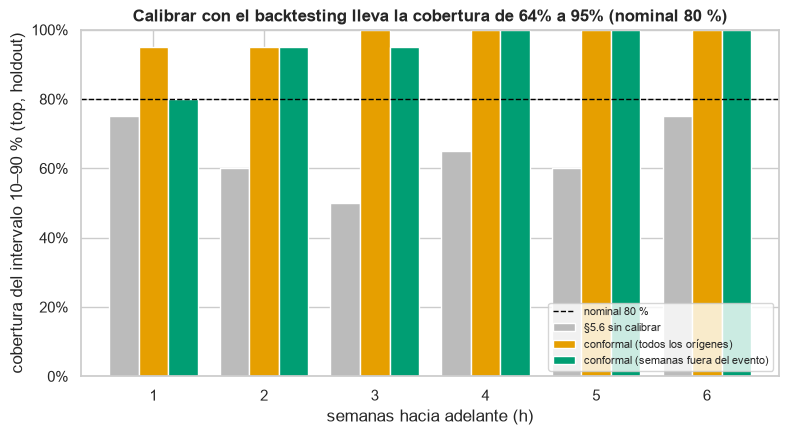

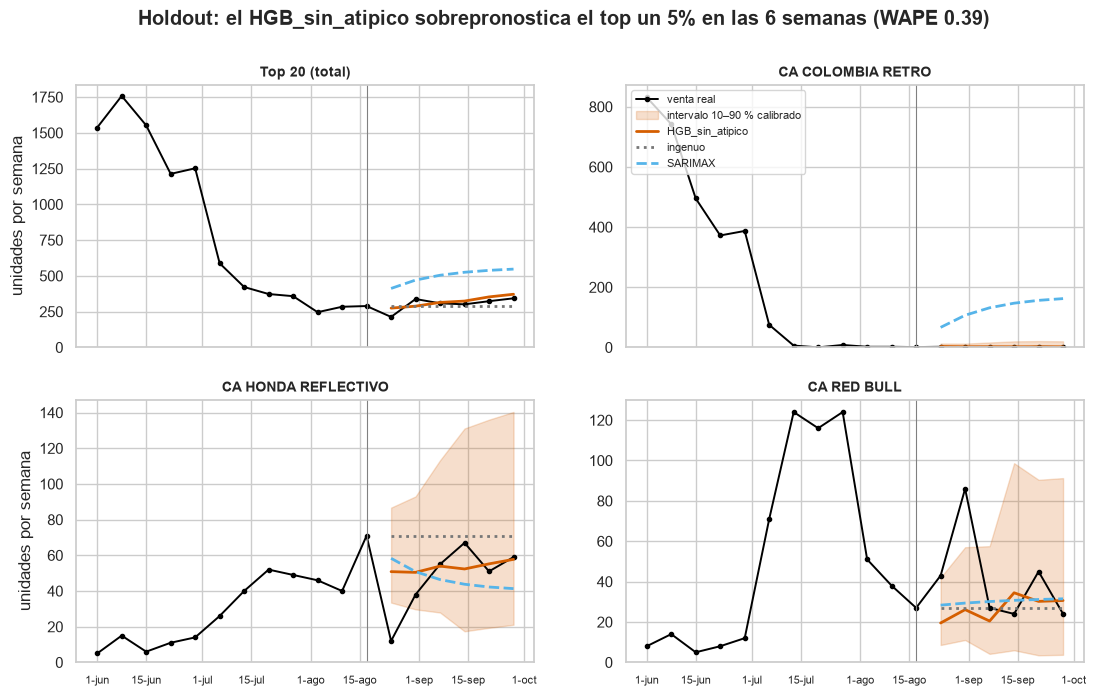

In [78]:
# 6.5.2 Gráficas: cobertura por horizonte y real frente a pronóstico en el holdout
fig, ax = plt.subplots(figsize=(9, 4.5))
cobertura_h.plot.bar(ax=ax, rot=0, width=.8, color=["#BBBBBB", OKABE_ITO[1], OKABE_ITO[2]])
ax.axhline(0.8, color="black", ls="--", lw=1, label="nominal 80 %")
ax.set(ylim=(0, 1), xlabel="semanas hacia adelante (h)", ylabel="cobertura del intervalo 10–90 % (top, holdout)",
       title=f"Calibrar con el backtesting lleva la cobertura de {intervalos_ho.iloc[0]['cobertura_80']:.0%} a "
             f"{evaluar_intervalo(_ho_int[CALIBRACION_ELEGIDA])['cobertura_80']:.0%} (nominal 80 %)")
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0)); ax.legend(fontsize=8, loc="lower right")
guardar_fig(fig, "6_5_01_cobertura_intervalos"); plt.show()

_hi = _ho_int[CALIBRACION_ELEGIDA]
_desde = SEMANA_INICIO_HOLDOUT - SEMANA * 12
_paneles = [("Top 20 (total)", TOP)] + [(c.replace("CUELLO ALTO ", "CA "), [c]) for c in [TOP[0], TOP[3], TOP[5]]]
_tot_ho = ho_top.groupby(["modelo", "semana"])[["y", "pred"]].sum()
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True)
for ax, (titulo, cats) in zip(axes.flat, _paneles):
    hist = panel_y[panel_y["catalogo"].isin(cats) & (panel_y["semana"] >= _desde)].groupby("semana")["y"].sum()
    ax.plot(hist.index, hist.values, color="black", lw=1.4, marker="o", ms=3, label="venta real")
    if len(cats) == 1:
        q = _hi[_hi["catalogo"] == cats[0]].sort_values("semana")
        ax.fill_between(q["semana"], q["lo"], q["hi"], color=ESTILO_MODELO[MODELO_FINAL][0], alpha=.2, label="intervalo 10–90 % calibrado")
    for m in dict.fromkeys([MODELO_FINAL, "ingenuo", "SARIMAX"]):
        p = ho_top[(ho_top["modelo"] == m) & ho_top["catalogo"].isin(cats)].groupby("semana")["pred"].sum()
        col, ls = ESTILO_MODELO[m]
        ax.plot(p.index, p.values, color=col, ls=ls, lw=2, label=m)
    ax.axvline(CORTE_ENTRENAMIENTO, color="grey", lw=.8)
    ax.set_title(titulo, fontsize=10); ax.xaxis.set_major_formatter(FMT_DIA); ax.tick_params(axis="x", labelsize=8)
    ax.set_ylim(bottom=0)
axes[0, 0].set_ylabel("unidades por semana"); axes[1, 0].set_ylabel("unidades por semana")
axes[0, 1].legend(fontsize=8, loc="upper left")
_s = resumen_ho.loc[MODELO_FINAL, (f"top h=1…{SEMANAS_HOLDOUT}", "sesgo")]
fig.suptitle(f"Holdout: el {MODELO_FINAL} {'sobrepronostica' if _s > 0 else 'subpronostica'} el top un {abs(_s):.0%} en las 6 semanas "
             f"(WAPE {resumen_ho.loc[MODELO_FINAL, (f'top h=1…{SEMANAS_HOLDOUT}', 'WAPE')]:.2f})", fontweight="bold")
guardar_fig(fig, "6_5_02_holdout_real_vs_pronostico"); plt.show()

### 6.6 Desglose por segmento (plan §6.3) y error por catálogo
- **Top frente a cola** (todos los catálogos).
- **Familia Colombia frente a resto**, **semanas de evento frente a normales** y **horizonte** (solo el top).
- **Error por catálogo del top en el holdout**: dónde falla el modelo.

In [79]:
# 6.6 Desglose por segmento en el backtesting y el holdout
_m_seg = list(dict.fromkeys([MODELO_FINAL, "HGB_poisson", "ingenuo", "SARIMAX"]))
_seg = []
for _fuente, _d in [("backtesting", bt), ("holdout", ho)]:
    _d = _d[_d["modelo"].isin(_m_seg)]
    for _dim, _sub in [("segmento", _d), ("familia", _d[_d["segmento"] == "top"]),
                       ("periodo_semana", _d[_d["segmento"] == "top"]), ("h", _d[_d["segmento"] == "top"])]:
        _t = tabla_metricas(_sub, por=("modelo", _dim)).rename(columns={_dim: "grupo"})
        _seg.append(_t.assign(fuente=_fuente, dimension=_dim, grupo=_t["grupo"].astype(str)))
segmentos = pd.concat(_seg, ignore_index=True)
tabla_seg = segmentos.pivot_table(index=["fuente", "dimension", "grupo"], columns="modelo", values=["WAPE", "sesgo"])
tabla_seg = tabla_seg.reindex(columns=pd.MultiIndex.from_product([["WAPE", "sesgo"], _m_seg]))
display(tabla_seg.round(3))

# Error por catálogo del top en el holdout (6 semanas)
err_cat_ho = (ho_top[ho_top["modelo"].isin([MODELO_FINAL, "ingenuo"])]
              .assign(ae=lambda x: (x["pred"] - x["y"]).abs(), e=lambda x: x["pred"] - x["y"])
              .groupby(["catalogo", "modelo"]).agg(uds_reales=("y", "sum"), uds_pron=("pred", "sum"), ae=("ae", "sum"), e=("e", "sum")))
err_cat_ho["WAPE"] = err_cat_ho["ae"] / err_cat_ho["uds_reales"]
err_cat_ho["sesgo"] = err_cat_ho["e"] / err_cat_ho["uds_reales"]
err_cat_ho = err_cat_ho.drop(columns=["ae", "e"]).unstack("modelo")
err_cat_ho[("rank", "")] = maestro.loc[err_cat_ho.index, "rank"].values
err_cat_ho[("familia", "")] = maestro.loc[err_cat_ho.index, "familia"].values
err_cat_ho = err_cat_ho.sort_values(("uds_reales", MODELO_FINAL), ascending=False)
err_cat_ho.round(2)

WAPE                                       sesgo                            
                                    HGB_sin_atipico HGB_poisson ingenuo SARIMAX HGB_sin_atipico HGB_poisson ingenuo SARIMAX
fuente      dimension      grupo                                                                                           
backtesting familia        COLOMBIA           0.977       0.970   0.992   1.117           0.030       0.022   0.074   0.011
                           RESTO              0.753       0.744   0.723   0.802          -0.176      -0.097  -0.051   0.131
            h              1                  0.559       0.551   0.523   0.761          -0.044      -0.028   0.015   0.051
                           2                  0.821       0.809   0.824   0.976          -0.055      -0.035   0.031   0.057
                           3                  1.011       1.005   1.046   1.108          -0.021      -0.003   0.039   0.050
                           4                  1.248       1.246   1.249   1.237          -0.018       0.006   0.055   0.037
            periodo_semana evento             0.880       0.882   0.898   1.002          -0.131      -0.129  -0.077  -0.135
                           normal             0.997       0.959   0.938   1.072           0.291       0.373   0.415   0.676
            segmento       cola               1.195       1.336   1.361   1.599          -0.220      -0.036  -0.002   0.243
                           top                0.907       0.899   0.907   1.018          -0.035      -0.015   0.035   0.049
holdout     familia        COLOMBIA           2.450       3.487   2.714  93.033           2.029       2.847   1.571  93.033
                           RESTO              0.375       0.648   0.415   0.479           0.039       0.190  -0.063  -0.072
            h              1                  0.608       0.706   0.629   1.196           0.289       0.394   0.357   0.935
                           2                  0.432       0.801   0.506   1.060          -0.148       0.131  -0.145   0.392
                           3                  0.423       0.706   0.458   1.210           0.020       0.172  -0.062   0.638
                           4                  0.461       0.605   0.352   1.272           0.076       0.183  -0.040   0.745
                           5                  0.329       0.671   0.440   1.242           0.093       0.253  -0.105   0.667
                           6                  0.183       0.542   0.280   1.169           0.083       0.193  -0.157   0.596
            periodo_semana normal             0.391       0.670   0.433   1.189           0.054       0.210  -0.050   0.642
            segmento       cola               1.165       1.396   1.251   1.365          -0.119       0.191  -0.104  -0.028
                           top                0.391       0.670   0.433   1.189           0.054       0.210  -0.050   0.642

uds_reales                uds_pron                    WAPE                   sesgo         rank   familia
modelo                               HGB_sin_atipico ingenuo HGB_sin_atipico ingenuo HGB_sin_atipico ingenuo HGB_sin_atipico ingenuo               
catalogo                                                                                                                                           
CUELLO ALTO HONDA REFLECTIVO                     282     282         320.540 426.000           0.260   0.510           0.140   0.510    4     RESTO
CUELLO ALTO YAMAHA REFLECTIVO                    281     281         269.210 252.000           0.170   0.190          -0.040  -0.100    5     RESTO
CUELLO ALTO RED BULL                             249     249         161.450 162.000           0.490   0.400          -0.350  -0.350    6     RESTO
CUELLO ALTO BMW ESTAMPADO REFLECTIVO             214     214         143.430  90.000           0.400   0.580          -0.330  -0.580    8     RESTO
CUELLO ALTO MERCEDES                             191     191         272.620 228.000           0.440   0.320           0.430   0.190   10     RESTO
CUELLO ALTO SUZUKI REFLECTIVO                    173     173         190.590 126.000           0.120   0.270           0.100  -0.270    9     RESTO
TOYOTA                                            97      97          61.170  36.000           0.400   0.650          -0.370  -0.630   14     RESTO
CUELLO ALTO PULSAR REFLECTIVO                     96      96         135.470 102.000           0.430   0.120           0.410   0.060   12     RESTO
FORD                                              88      88          73.190  78.000           0.380   0.320          -0.170  -0.110   20     RESTO
CUELLO ALTO KTM REFLECTIVO                        84      84         112.190  84.000           0.370   0.520           0.340   0.000   15     RESTO
CUELLO ALTO AMERICA                               34      34          99.730  78.000           1.930   1.350           1.930   1.290   13     RESTO
CUELLO ALTO NACIONAL REY DE COPAS                 21      21          29.810  24.000           1.160   1.000           0.420   0.140   18     RESTO
CUELLO ALTO COLOMBIA                               6       6           8.640   0.000           1.220   1.000           0.440  -1.000    2  COLOMBIA
CUELLO ALTO COLOMBIA RETRO                         5       5          12.930   6.000           1.590   1.000           1.590   0.200    1  COLOMBIA
CUELLO ALTO COLOMBIA ÉLITE                         3       3          12.690  30.000           3.630   9.000           3.230   9.000    3  COLOMBIA
CUELLO ALTO PORTUGAL                               1       1           6.690   6.000           5.920   5.000           5.690   5.000   17     RESTO
CUELLO ALTO ARGENTINA                              1       1           6.500   6.000           5.500   5.000           5.500   5.000   16     RESTO
COLOMBIA ELITE/CLASICO                             0       0           0.070   0.000             inf     NaN             inf     NaN    7  COLOMBIA
RED BULL                                           0       0           0.000   0.000             NaN     NaN             NaN     NaN   11     RESTO
BUZO COLOMBIA VISITANTE                            0       0           8.080   0.000             inf     NaN             inf     NaN   19  COLOMBIA

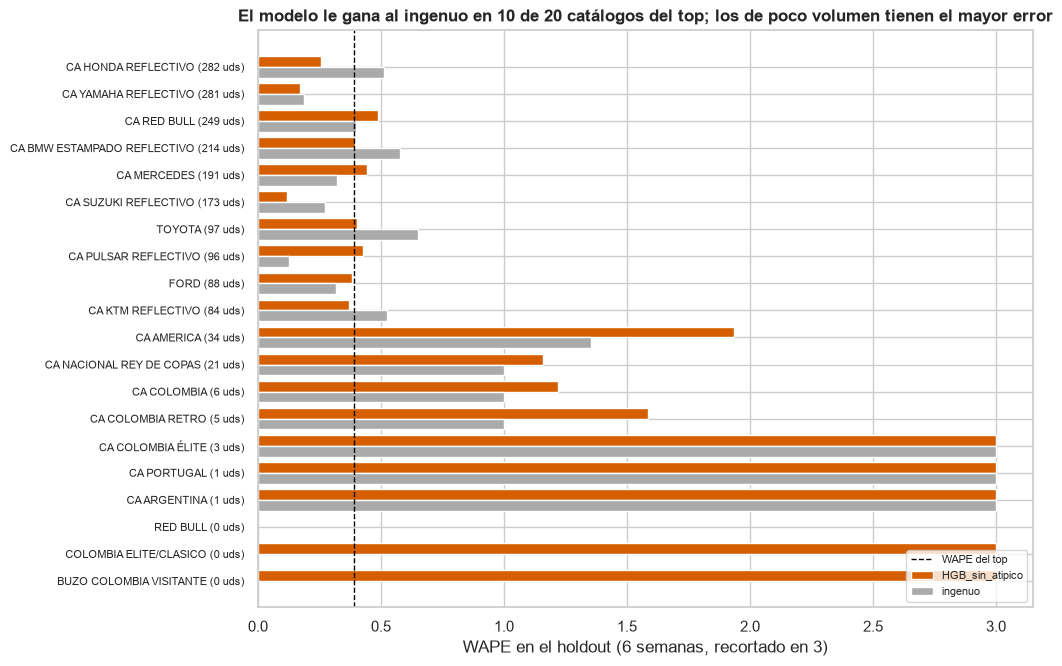

In [80]:
# 6.6.2 Gráfica: error por catálogo del top en el holdout
_e = err_cat_ho.sort_values(("uds_reales", MODELO_FINAL))
_y = np.arange(len(_e))
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.barh(_y + .2, _e[("WAPE", MODELO_FINAL)].clip(upper=3), height=.4, color=ESTILO_MODELO[MODELO_FINAL][0], label=MODELO_FINAL)
ax.barh(_y - .2, _e[("WAPE", "ingenuo")].clip(upper=3), height=.4, color="#AAAAAA", label="ingenuo")
ax.set_yticks(_y, [f"{c.replace('CUELLO ALTO ', 'CA ')[:34]} ({int(u)} uds)" for c, u in zip(_e.index, _e[("uds_reales", MODELO_FINAL)])],
              fontsize=8)
ax.axvline(resumen_ho.loc[MODELO_FINAL, (f"top h=1…{SEMANAS_HOLDOUT}", "WAPE")], color="black", ls="--", lw=1, label="WAPE del top")
_n_peor = int((_e[("WAPE", MODELO_FINAL)] > _e[("WAPE", "ingenuo")]).sum())
ax.set(xlabel="WAPE en el holdout (6 semanas, recortado en 3)",
       title=f"El modelo le gana al ingenuo en {len(_e) - _n_peor} de {len(_e)} catálogos del top; los de poco volumen tienen el mayor error")
ax.legend(fontsize=8, loc="lower right")
guardar_fig(fig, "6_6_01_error_por_catalogo_holdout"); plt.show()

### 6.7 La cola: ¿cuánto vende lo que el modelo deja en 0?
Los modelos globales solo pronostican los catálogos con venta en las últimas 12 semanas (`SEMANAS_ACTIVO`); el resto queda en 0.
La tabla reparte la venta real de la cola en cada origen entre catálogos **activos**, **dormidos que reviven** (vendieron antes, pero no
en las últimas 12 semanas) y **nuevos** (nacen después del origen). Lo que no es "activo" es un error que ningún modelo puede evitar.

In [81]:
# 6.7 Venta real de la cola según el estado del catálogo en el origen
_filas = []
for _corte, _h in [*[(c, H) for c in CORTES_BT], (CORTE_ENTRENAMIENTO, SEMANAS_HOLDOUT)]:
    _ctx = contexto(_corte)
    _vendio = set(_ctx["p_y"].loc[_ctx["p_y"]["y"] > 0, "catalogo"])
    _r = panel_y[(panel_y["semana"] > _corte) & (panel_y["semana"] <= _corte + SEMANA * _h) & ~panel_y["catalogo"].isin(TOP)]
    _estado = np.where(_r["catalogo"].isin(_ctx["activos"]), "activo", np.where(_r["catalogo"].isin(_vendio), "dormido", "nuevo"))
    _filas.append(_r.assign(estado=_estado).groupby("estado")["y"].sum()
                  .rename(f"{_corte.date()}{' (holdout)' if _corte == CORTE_ENTRENAMIENTO else ''}"))
cola_estados = pd.concat(_filas, axis=1).T.fillna(0).reindex(columns=["activo", "dormido", "nuevo"], fill_value=0)
cola_estados["total"] = cola_estados.sum(axis=1)
for _c in ["dormido", "nuevo"]:
    cola_estados[f"%_{_c}"] = cola_estados[_c] / cola_estados["total"]
_bt_ce = cola_estados.iloc[:-1][["activo", "dormido", "nuevo"]].sum()
print(f"Backtesting: de {int(_bt_ce.sum()):,} uds de la cola, {_bt_ce['dormido'] / _bt_ce.sum():.1%} son de catálogos dormidos que reviven "
      f"y {_bt_ce['nuevo'] / _bt_ce.sum():.1%} de catálogos nuevos (pronóstico 0 por construcción).")
cola_estados.round(2)

Backtesting: de 9,823 uds de la cola, 0.3% son de catálogos dormidos que reviven y 26.6% de catálogos nuevos (pronóstico 0 por construcción).


estado,activo,dormido,nuevo,total,%_dormido,%_nuevo
2026-04-13,502,1,206,709,0.000,0.290
2026-04-20,492,0,265,757,0.000,0.350
2026-04-27,444,0,305,749,0.000,0.410
2026-05-04,430,0,213,643,0.000,0.330
2026-05-11,485,3,203,691,0.000,0.290
2026-05-18,538,3,155,696,0.000,0.220
2026-05-25,527,4,140,671,0.010,0.210
2026-06-01,557,5,134,696,0.010,0.190
2026-06-08,542,1,71,614,0.000,0.120
2026-06-15,462,2,67,531,0.000,0.130


In [82]:
# 6.8 Exportación para §7–§8
_exportar6 = {
    "6_backtesting_predicciones.csv": bt.drop(columns=["segundos"], errors="ignore"),
    "6_metricas_backtesting.csv": resumen_bt.reset_index(),
    "6_wape_por_origen_backtesting.csv": wape_origen_bt.reset_index(),
    "6_holdout_predicciones.csv": ho.drop(columns=["segundos"], errors="ignore"),
    "6_metricas_holdout.csv": resumen_ho.set_axis([" | ".join(c) for c in resumen_ho.columns], axis=1).reset_index(),
    "6_metricas_por_segmento.csv": segmentos,
    "6_error_por_catalogo_holdout.csv": err_cat_ho.set_axis([" | ".join(map(str, c)).strip(" |") for c in err_cat_ho.columns], axis=1).reset_index(),
    "6_calibracion_intervalos.csv": calibracion_tabla.reset_index(),
    "6_intervalos_holdout.csv": _ho_int[CALIBRACION_ELEGIDA][["catalogo", "semana", "h", "y", "pred", "lo", "hi"]],
    "6_evaluacion_intervalos.csv": intervalos_ho.reset_index(names="metodo"),
    "6_cola_estado_catalogos.csv": cola_estados.reset_index(names="origen"),
    "6_diagnostico_holdout.csv": diag_ho.reset_index(),
}
for nombre, df in _exportar6.items():
    df.to_csv(RUTAS["procesado"] / nombre, index=False, encoding="utf-8")
    print(f"{nombre:<40} {len(df):>8,} filas")

6_backtesting_predicciones.csv            268,168 filas
6_metricas_backtesting.csv                      8 filas
6_wape_por_origen_backtesting.csv              15 filas


6_holdout_predicciones.csv                 35,656 filas
6_metricas_holdout.csv                          8 filas
6_metricas_por_segmento.csv                    84 filas
6_error_por_catalogo_holdout.csv               20 filas
6_calibracion_intervalos.csv                    8 filas
6_intervalos_holdout.csv                      120 filas
6_evaluacion_intervalos.csv                     4 filas
6_cola_estado_catalogos.csv                    16 filas
6_diagnostico_holdout.csv                       8 filas


### 6.9 Hallazgos de la evaluación (para redactar con palabras propias)

In [83]:
_b, _hk4, _hk6 = resumen_bt, (f"top h=1…{H}", "WAPE"), (f"top h=1…{SEMANAS_HOLDOUT}", "WAPE")
h6 = {
    "backtesting (orígenes, horizonte)": f"{len(CORTES_BT)} orígenes {CORTES_BT.min().date()} → {CORTES_BT.max().date()}, {H} semanas",
    "modelo final top / regla cola (candidato §5)": f"{MODELO_FINAL} / {MODELO_COLA_FINAL} ({MODELO_CANDIDATO} / {MODELO_COLA})",
    "modelo que elegía la regla sola / modelo final (Mundial como atípico)": (MODELO_REGLA, MODELO_FINAL),
    "WAPE top después del Mundial (backtesting): regla / final / ingenuo": tuple(round(float(_b.loc[m, "WAPE_top_post"]), 3) for m in [MODELO_REGLA, MODELO_FINAL, "ingenuo"]),
    "holdout WAPE top h=1…4: regla / final / ingenuo": tuple(round(float(resumen_ho.loc[m, _hk4]), 3) for m in [MODELO_REGLA, MODELO_FINAL, "ingenuo"]),
    "holdout WAPE top h=1…6: regla / final / ingenuo": tuple(round(float(resumen_ho.loc[m, _hk6]), 3) for m in [MODELO_REGLA, MODELO_FINAL, "ingenuo"]),
    "holdout sesgo top h=1…6: regla / final": tuple(round(float(resumen_ho.loc[m, (_hk6[0], "sesgo")]), 3) for m in [MODELO_REGLA, MODELO_FINAL]),
    "WAPE top backtesting: final / HGB_poisson / ingenuo / SARIMAX": tuple(round(float(_b.loc[m, "WAPE_top"]), 3) for m in [MODELO_FINAL, "HGB_poisson", "ingenuo", "SARIMAX"]),
    "WAPE top final por fase (antes / toca evento / después)": tuple(round(float(_b.loc[MODELO_FINAL, c]), 3) for c in FASES.values()),
    "WAPE top ingenuo por fase (antes / toca evento / después)": tuple(round(float(_b.loc["ingenuo", c]), 3) for c in FASES.values()),
    "final vs ingenuo: IC 90 % dif. WAPE, P(gana), orígenes ganados": (_b.loc[MODELO_FINAL, "dif_WAPE_vs_ingenuo_IC90"],
        round(float(_b.loc[MODELO_FINAL, "prob_gana_bootstrap"]), 2), f"{_b.loc[MODELO_FINAL, 'origenes_gana_al_ingenuo']}/{len(CORTES_BT)}"),
    "skill MASE / RMSSE del final vs ingenuo": (round(float(_b.loc[MODELO_FINAL, "skill_MASE_vs_ingenuo"]), 3),
        round(float(1 - _b.loc[MODELO_FINAL, "RMSSE_top"] / _b.loc["ingenuo", "RMSSE_top"]), 3)),
    "sesgo top backtesting (final)": round(float(_b.loc[MODELO_FINAL, "sesgo_top"]), 3),
    "redondeo de la trayectoria: WAPE top HGB_redondeo / HGB_poisson": (round(float(_b.loc["HGB_redondeo", "WAPE_top"]), 3), round(float(_b.loc["HGB_poisson", "WAPE_top"]), 3)),
    "holdout WAPE top h=1…4: final / ingenuo / SARIMAX": tuple(round(float(resumen_ho.loc[m, _hk4]), 3) for m in [MODELO_FINAL, "ingenuo", "SARIMAX"]),
    "holdout WAPE top h=1…6: final / ingenuo / SARIMAX": tuple(round(float(resumen_ho.loc[m, _hk6]), 3) for m in [MODELO_FINAL, "ingenuo", "SARIMAX"]),
    "holdout sesgo top h=1…6 (final)": round(float(resumen_ho.loc[MODELO_FINAL, (_hk6[0], "sesgo")]), 3),
    "holdout WAPE total semanal (final / ingenuo)": tuple(round(float(resumen_ho.loc[m, ("total semanal h=1…6", "WAPE")]), 3) for m in [MODELO_FINAL, "ingenuo"]),
    "cobertura 10–90 % holdout: §5.6 / conformal elegida": (f"{intervalos_ho.iloc[0]['cobertura_80']:.0%}",
        f"{intervalos_ho.loc[f'conformal ({CALIBRACION_ELEGIDA}) · holdout', 'cobertura_80']:.0%}"),
    "holdout sin el catálogo de mayor exceso: WAPE top final / ingenuo": (CATALOGO_PEOR_HO,
        round(float(diag_ho.loc[MODELO_FINAL, "WAPE_top_sin_peor"]), 3), round(float(diag_ho.loc["ingenuo", "WAPE_top_sin_peor"]), 3)),
    "% del sobrepronóstico del top que explica ese catálogo (final)": f"{diag_ho.loc[MODELO_FINAL, 'exceso_uds_peor'] / diag_ho.loc[MODELO_FINAL, 'exceso_uds_top']:.0%}",
    "cola (backtesting): % uds de dormidos / nuevos": (f"{_bt_ce['dormido'] / _bt_ce.sum():.1%}", f"{_bt_ce['nuevo'] / _bt_ce.sum():.1%}"),
}
for k, v in h6.items():
    print(f"- {k}: {v}")

- backtesting (orígenes, horizonte): 15 orígenes 2026-04-13 → 2026-07-20, 4 semanas
- modelo final top / regla cola (candidato §5): HGB_sin_atipico / ingenuo (HGB+ingenuo / ingenuo)
- modelo que elegía la regla sola / modelo final (Mundial como atípico): ('HGB_redondeo', 'HGB_sin_atipico')
- WAPE top después del Mundial (backtesting): regla / final / ingenuo: (0.585, 0.762, 0.6)
- holdout WAPE top h=1…4: regla / final / ingenuo: (0.696, 0.469, 0.476)
- holdout WAPE top h=1…6: regla / final / ingenuo: (0.652, 0.391, 0.433)
- holdout sesgo top h=1…6: regla / final: (0.191, 0.054)
- WAPE top backtesting: final / HGB_poisson / ingenuo / SARIMAX: (0.907, 0.899, 0.907, 1.018)
- WAPE top final por fase (antes / toca evento / después): (0.469, 0.952, 0.762)
- WAPE top ingenuo por fase (antes / toca evento / después): (0.439, 0.965, 0.6)
- final vs ingenuo: IC 90 % dif. WAPE, P(gana), orígenes ganados: ('[-0.054, +0.056]', 0.49, '8/15')
- skill MASE / RMSSE del final vs ingenuo: (-0.066, -0.072

### 6.10 Lectura de la evaluación (borrador técnico; redactar con palabras propias)

> **Actualización del 9-nov-2026 — el Mundial como dato atípico.** Después de la mentoría con Klixmant, el modelo final pasó de
> `HGB_redondeo` a **`HGB_sin_atipico`**: mismas variables y parámetros, pero una vez termina el evento sus 8 semanas (25-may → 13-jul)
> **no entran al entrenamiento** y los rezagos se calculan **sin el pico** (13.233 filas de entrenamiento en vez de 17.722).
> Cifras de la corrida del 9-nov (top 20): holdout WAPE h = 1…4 **0,469** (antes 0,696; ingenuo 0,476); h = 1…6 **0,391** (antes 0,652; ingenuo 0,433),
> sesgo **+5 %** (antes +19 %); total semanal **0,099** (ingenuo 0,170). Backtesting: WAPE 0,907 (igual al ingenuo); en los 2 orígenes
> pegados al fin del evento es **peor** (0,762 vs 0,585 del modelo anterior; Colombia 324 uds pronosticadas vs 49 reales), porque no vio el Mundial.
> **Dos advertencias:** es una decisión de negocio tomada con el holdout ya abierto (sus cifras son indicativas, no una prueba limpia), y el
> intervalo quedó conservador (cobertura 95 % frente al 80 % nominal). El texto de abajo es la lectura del 3-nov y describe el modelo anterior (`HGB_redondeo`); las cifras vigentes son las de la celda 6.9.
> Comparación con el modelo inicial del curso a nivel SKU: notebook §6.11.

Cifras de la corrida del 3-nov-2026 (las celdas de arriba las recalculan).

> ⚠️ **Corrección del 4-nov-2026 (agente 05):** `PARAMS_HGB` ahora fija `early_stopping=False`. Antes, con más de 10.000 filas,
> scikit-learn activaba solo el *early stopping* con una validación aleatoria y cortaba el modelo: afectó al origen del 20-jul, al holdout
> (141 iteraciones) y al pronóstico de producción (10 iteraciones). La **selección no cambia** (`HGB_redondeo`), pero varias cifras de
> esta lectura quedaron viejas. Valores nuevos: holdout WAPE top h=1…6 **0,65** (antes 0,72) con sesgo **+19 %** (antes +31 %);
> sin Honda 0,52 / −3 %; WAPE del total semanal **0,11** para `HGB_redondeo` y **0,09** para `HGB+ingenuo` (ingenuo 0,17);
> Colombia tras el Mundial: 75 uds (antes 90). Las cifras vigentes son las que imprime la celda 6.9. Redáctenlo con esos números.

**Backtesting (15 orígenes).**
- Los tres HGB quedan empatados (WAPE del top 0,88–0,90) y apenas por debajo del ingenuo (0,91). El intervalo del 90 % de la diferencia
  frente al ingenuo incluye el 0 y el HGB gana en 9 de 15 orígenes: **la mejora no es concluyente**. En MASE y RMSSE el ingenuo es igual o mejor.
- Por la regla de §6.3 el modelo final es **`HGB_redondeo`** (HGB Poisson con trayectoria en unidades enteras). Es igual de simple que
  `HGB_poisson` y tiene el mejor WAPE después del Mundial entre los dos. `HGB+ingenuo` tiene el mejor WAPE total, pero la regla prefiere el más simple.
- 11 de los 15 orígenes pronostican semanas de la ventana del evento. Ahí todos los modelos fallan: el peor caso es el origen del 29-jun
  (WAPE ≈ 3), porque nadie puede saber que Colombia queda eliminada el 7-jul.
- Lo que separa a los modelos es el **criterio 3** (no arrastrar el Mundial): después del evento, el HGB y el ingenuo pronostican entre 84 y 118 uds
  de Colombia (real: 49), SARIMAX 1.871 y la media móvil 3.990.

**Holdout (24-ago → 28-sep).**
- El **ingenuo y el ETS ganan** (WAPE del top ≈ 0,43 en 6 semanas). El `HGB_redondeo` queda en 0,72 con un sesgo de +31 %: sobrepronostica.
- Casi todo el exceso viene de **un catálogo**: Honda Reflectivo cerró el 17-ago con su récord (71 uds, frente a un promedio de 35 en las 8 semanas previas)
  y el boosting extrapoló el crecimiento a ~132 uds/semana, cerca del tope (2 × 71 = 142); la venta real fue ~47. Sin Honda, el HGB baja a WAPE 0,52 con sesgo +4 %,
  pero el ingenuo sigue mejor (0,42, sesgo −15 %).
- En el **total semanal**, que es lo que mira compras, el `HGB+ingenuo` es el mejor (WAPE 0,15) frente al ingenuo (0,17).

**Intervalos.** La calibración conformal sube la cobertura del 10–90 % en el holdout del 63 % (§5.6) al 92 %, por encima del 80 % nominal:
son intervalos conservadores. En las semanas del evento la cobertura cae al 63 %. Para un evento nuevo hace falta un ajuste experto.

**Cola.** La regla final es el ingenuo. El 27 % de la venta de la cola viene de catálogos que todavía no existían en el origen, y solo el 0,3 %
de catálogos "dormidos" que reviven: la regla de 12 semanas casi no pierde venta.

**Qué significa para §8.** El holdout no cambia la elección (así lo exige el protocolo), pero sí deja dos recomendaciones:
(1) bajar el `TOPE_RELATIVO` o ponerle un tope a la tendencia, validándolo **solo con el backtesting**; (2) en producción, publicar
junto al modelo el pronóstico ingenuo como referencia y revisar a mano los catálogos en los que los dos difieren más del 50 %.

### 6.11 Comparación con el modelo inicial del curso (nivel SKU)

El modelo inicial del curso (`modelo_inicial.ipynb`) pronostica **SKU × semana** con los 12 rezagos y valida en el último 20 % de las semanas.
Su mejor resultado es un MAPE **en las filas con venta** de 79,8 % (LinearSVR; CatBoost 83,6 %). Ese número y el WAPE de §6 **no son comparables**:
cambian la unidad (SKU vs catálogo), el horizonte (1 semana con rezagos reales vs 4 semanas recursivas) y las semanas evaluadas
(solo después del Mundial vs 15 orígenes, 11 de ellos tocando el evento). Para compararlos de verdad, aquí se usa **su mismo protocolo**:
mismo panel, misma partición y mismas métricas. Sobre esa base se aplican, uno por uno, los puntos de la mentoría con Klixmant:

1. **El Mundial es un dato atípico.** 8 de las 21 semanas de entrenamiento caen en la ventana del evento. Se sacan del entrenamiento (paso 2)
   y, además, los rezagos dejan de arrastrar el pico (paso 4).
2. **El SKU se puede leer.** `H N L NEGRO L ES RV` = género · tela · largo · color · talla · proceso (BOR/ES) · reflectivo.
   En vez de tratarlo como una etiqueta, se le dan esos atributos al modelo (paso 3).
3. **Dos detalles del dato** (§6.11.3): la última semana de la base solo tiene 2 días, y el 27 % de las líneas (todo Dropi) trae un SKU
   ilegible (`-46`, `null-39`). La unidad que sí existe en bodega es la **prenda prefabricada = referencia + talla**.

Todos los modelos de esta sección son de scikit-learn.


In [84]:
# 6.11.1 Protocolo del modelo inicial del curso: panel SKU × semana, 12 rezagos y validación en el último 20 % de las semanas
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

REZAGOS_SKU = [f"lag_{i}" for i in range(1, 13)]
ATRIBUTOS_SKU = ["genero", "tela", "color", "talla", "proceso", "reflectivo"]     # lo que dice el código del SKU (mentoría con Klixmant)
VENTANAS_SKU = ["media_4", "media_8", "media_12", "semanas_con_venta_4", "semanas_con_venta_12", "maximo_12"]
PARAMS_HGB_SKU = {**PARAMS_HGB, "learning_rate": 0.03, "min_samples_leaf": 40}   # más filas y más ceros que el panel por catálogo


def panel_sku(lineas, columna, sin_semana_parcial=False):
    """Panel `columna` × semana con ceros, igual que el modelo inicial: todas las series desde la primera semana de la base."""
    s = lineas.assign(semana=inicio_semana(lineas["fecha_remision"]))
    semanas = pd.date_range(s["semana"].min(), s["semana"].max(), freq=DECISIONES["frecuencia"])
    if sin_semana_parcial:
        semanas = semanas[semanas <= ULTIMA_SEMANA_COMPLETA]
    idx = pd.MultiIndex.from_product([semanas, s[columna].unique()], names=["semana", "sku"])
    return (s.groupby(["semana", columna])["cantidad_total"].sum().reindex(idx, fill_value=0).rename("y").reset_index()
            .sort_values(["sku", "semana"]).reset_index(drop=True))


def atributos_del_sku(sku):
    """"H N L NEGRO L ES RV" → género · tela · (largo) · color · talla · proceso · reflectivo.
    Los SKU de Dropi ("-46", "null-39") no traen el código: quedan como SIN_DATO."""
    p = str(sku).split()
    if len(p) < 5:
        return ("SIN_DATO",) * 6
    return p[0], p[1], p[3], p[4], (p[5] if len(p) > 5 else "SIN_DATO"), ("RV" if len(p) > 6 and p[6] == "RV" else "NO")


def variables_sku(p, topar_evento=False):
    """Rezagos 1–12, ventanas y atributos del SKU. `topar_evento`: dentro de la ventana del Mundial los rezagos no pasan
    del nivel del SKU en las 4 semanas previas (el pico no se usa como si fuera demanda normal)."""
    d = p.copy()
    en_evento = d["semana"].isin(VENTANA_EVENTO)
    d["y_rezago"] = d["y"].astype(float)
    if topar_evento:
        previas = d[(d["semana"] < VENTANA_EVENTO.min()) & (d["semana"] >= VENTANA_EVENTO.min() - SEMANA * 4)]
        nivel = np.ceil(d["sku"].map(previas.groupby("sku")["y"].mean()).fillna(0))
        d["y_rezago"] = np.where(en_evento, np.minimum(d["y"], nivel), d["y"]).astype(float)
    g = d.groupby("sku")["y_rezago"]
    for i in range(1, 13):
        d[f"lag_{i}"] = g.shift(i)
    for w in (4, 8, 12):
        d[f"media_{w}"] = d[REZAGOS_SKU[:w]].mean(axis=1)
    d["semanas_con_venta_4"] = (d[REZAGOS_SKU[:4]] > 0).sum(axis=1)
    d["semanas_con_venta_12"] = (d[REZAGOS_SKU] > 0).sum(axis=1)
    d["maximo_12"] = d[REZAGOS_SKU].max(axis=1)
    _skus = d["sku"].unique()
    d = d.join(pd.DataFrame([atributos_del_sku(s) for s in _skus], index=_skus, columns=ATRIBUTOS_SKU), on="sku")
    d["en_evento"] = en_evento.values
    return d.dropna(subset=["lag_12"]).sort_values(["semana", "sku"]).reset_index(drop=True)


def partir_sku(d, proporcion_validacion=0.20):
    """Últimas semanas (20 %) para validar; el resto para entrenar. Es la misma partición del modelo inicial."""
    fechas = np.sort(d["semana"].unique())
    n_val = max(1, int(np.ceil(len(fechas) * proporcion_validacion)))
    es_val = d["semana"].isin(fechas[-n_val:])
    return d[~es_val], d[es_val]


def X_sku(d, columnas, referencia):
    X = d[columnas].copy()
    for c in [c for c in columnas if c in ATRIBUTOS_SKU]:
        X[c] = pd.Categorical(d[c], categories=sorted(referencia[c].unique()))
    return X


def metricas_sku(y, pred):
    """Las tres métricas del modelo inicial (MAE, RMSE y MAPE solo en las filas con venta) más WAPE y sesgo."""
    y, pred = np.asarray(y, dtype=float), np.clip(np.asarray(pred, dtype=float), 0, None)
    con_venta = y > 0
    return {"MAE": mean_absolute_error(y, pred), "RMSE": float(np.sqrt(mean_squared_error(y, pred))),
            "MAPE_con_venta": mean_absolute_percentage_error(y[con_venta], pred[con_venta]),
            "WAPE": np.abs(pred - y).sum() / y.sum(), "sesgo": (pred.sum() - y.sum()) / y.sum()}


def comparar_modelos_sku(p, etiqueta):
    """Corre la escalera de la comparación sobre un panel y devuelve una fila por modelo."""
    d0, d1 = variables_sku(p), variables_sku(p, topar_evento=True)
    (tr0, va0), (tr1, va1) = partir_sku(d0), partir_sku(d1)
    y_val = va0["y"].values
    filas = []

    def anotar(paso, modelo, pred):
        filas.append({"panel": etiqueta, "paso": paso, "modelo": modelo, **metricas_sku(y_val, pred)})

    anotar("0 · referencia", "Media de las 4 semanas anteriores", va0["media_4"])
    pre = ColumnTransformer([("sku", OneHotEncoder(handle_unknown="ignore"), ["sku"]), ("lags", "passthrough", REZAGOS_SKU)])
    svr = Pipeline([("pre", pre), ("escala", StandardScaler(with_mean=False)),
                    ("modelo", LinearSVR(C=0.01, epsilon=0, tol=1e-4, max_iter=10000, random_state=SEMILLA))])
    anotar("0 · modelo inicial", "LinearSVR (mejor del modelo inicial)",
           svr.fit(tr0[["sku"] + REZAGOS_SKU], tr0["y"]).predict(va0[["sku"] + REZAGOS_SKU]))

    def hgb(tr, va, columnas, ref):
        return HistGradientBoostingRegressor(**PARAMS_HGB_SKU).fit(X_sku(tr, columnas, ref), tr["y"]).predict(X_sku(va, columnas, ref))

    anotar("1 · mismos 12 rezagos", "HGB Poisson, entrenado CON el Mundial", hgb(tr0, va0, REZAGOS_SKU, d0))
    sin0, sin1 = tr0[~tr0["en_evento"]], tr1[~tr1["en_evento"]]
    anotar("2 · Mundial como atípico", "HGB Poisson, entrenado SIN las semanas del Mundial", hgb(sin0, va0, REZAGOS_SKU, d0))
    todas = REZAGOS_SKU + VENTANAS_SKU + ATRIBUTOS_SKU
    anotar("3 · + lectura del SKU", "HGB sin Mundial + atributos del SKU", hgb(sin0, va0, todas, d0))
    anotar("4 · + rezagos sin el pico", "HGB sin Mundial + atributos + rezagos topados", hgb(sin1, va1, todas, d1))
    out = pd.DataFrame(filas)
    out.attrs.update(series=p["sku"].nunique(), semanas_validacion=(va0["semana"].min(), va0["semana"].max()),
                     filas_validacion=len(va0), filas_con_venta=int((y_val > 0).sum()), unidades_validacion=int(y_val.sum()))
    return out


pedidos_sku = cargar_pedidos()
panel_inicial = panel_sku(pedidos_sku, "sku")                # todas las líneas y la semana parcial, como en el modelo inicial
_d = variables_sku(panel_inicial)
_tr, _va = partir_sku(_d)
print(f"Panel del modelo inicial: {panel_inicial['sku'].nunique():,} SKU × {panel_inicial['semana'].nunique()} semanas "
      f"({(panel_inicial['y'] == 0).mean():.1%} de ceros) | entrenamiento {len(_tr):,} filas, validación {len(_va):,} filas "
      f"({_va['semana'].min().date()} → {_va['semana'].max().date()}), {(_va['y'] > 0).sum():,} con venta")
_sin_codigo = pedidos_sku["sku"].astype(str).str.split().str.len() < 5
print(f"SKU sin código legible (\"-46\", \"null-39\"…): {_sin_codigo.sum():,} líneas ({_sin_codigo.mean():.1%}), "
      f"todas del canal {', '.join(pedidos_sku.loc[_sin_codigo, 'canal'].unique())}")
print(f"Semanas de entrenamiento dentro de la ventana del Mundial: {_tr.loc[_tr['en_evento'], 'semana'].nunique()} de {_tr['semana'].nunique()}")


Panel del modelo inicial: 1,042 SKU × 39 semanas (80.0% de ceros) | entrenamiento 21,882 filas, validación 6,252 filas (2026-08-31 → 2026-10-05), 988 con venta
SKU sin código legible ("-46", "null-39"…): 8,042 líneas (26.9%), todas del canal DROPI
Semanas de entrenamiento dentro de la ventana del Mundial: 8 de 21


In [85]:
# 6.11.2 Mismos datos, misma partición y mismas métricas que el modelo inicial: qué cambia al tratar el Mundial como atípico y al leer el SKU
_t0 = time.time()
comparacion_inicial = comparar_modelos_sku(panel_inicial, "A · SKU del modelo inicial")
_a = comparacion_inicial.attrs
print(f"Validación {_a['semanas_validacion'][0].date()} → {_a['semanas_validacion'][1].date()}: {_a['filas_validacion']:,} filas, "
      f"{_a['filas_con_venta']:,} con venta, {_a['unidades_validacion']:,} uds | {time.time() - _t0:.0f} s")
comparacion_inicial.drop(columns="panel").set_index(["paso", "modelo"]).round(3)


Validación 2026-08-31 → 2026-10-05: 6,252 filas, 988 con venta, 2,759 uds | 25 s


,,MAE,RMSE,MAPE_con_venta,WAPE,sesgo
paso,modelo,,,,,
0 · referencia,Media de las 4 semanas anteriores,0.369,1.081,0.735,0.837,-0.005
0 · modelo inicial,LinearSVR (mejor del modelo inicial),0.368,1.102,0.798,0.834,-0.088
1 · mismos 12 rezagos,"HGB Poisson, entrenado CON el Mundial",0.455,1.261,0.813,1.030,0.202
2 · Mundial como atípico,"HGB Poisson, entrenado SIN las semanas del Mundial",0.423,1.118,0.711,0.959,-0.031
3 · + lectura del SKU,HGB sin Mundial + atributos del SKU,0.405,1.068,0.681,0.918,-0.043
4 · + rezagos sin el pico,HGB sin Mundial + atributos + rezagos topados,0.400,1.045,0.672,0.907,-0.016


In [86]:
# 6.11.3 Dos correcciones del dato: (B) quitar la semana parcial y (C) usar la prenda prefabricada (referencia + talla) en vez del SKU
# B: la semana del 5-oct solo tiene 2 días (la base se cortó el 6-oct); en el modelo inicial entra a la validación como si fuera completa.
# C: en bodega el buzo está en blanco y se identifica por referencia + talla; el bordado o estampado se decide con el pedido. Con esa
#    unidad entran también las líneas de Dropi (su SKU no es legible, pero sí traen referencia y talla) y se excluyen las canceladas.
_lineas_prenda = cat_ok.loc[~cat_ok["talla_std"].isin(["SIN_TALLA", "AMBIGUA"]) & (cat_ok["tela"] != "?")].copy()
_lineas_prenda["prenda"] = (_lineas_prenda["genero"] + " " + _lineas_prenda["tela"] + " L " + _lineas_prenda["color_ref"]
                            + " " + _lineas_prenda["talla_std"])
PANELES_SKU = {
    "B · SKU sin la semana parcial": panel_sku(pedidos_sku, "sku", sin_semana_parcial=True),
    "C · prenda (referencia + talla), 2 canales": panel_sku(_lineas_prenda, "prenda", sin_semana_parcial=True),
}
_t0 = time.time()
_partes = [comparacion_inicial]
for _etq, _p in PANELES_SKU.items():
    _r = comparar_modelos_sku(_p, _etq)
    _partes.append(_r)
    print(f"{_etq}: {_r.attrs['series']:,} series | validación {_r.attrs['semanas_validacion'][0].date()} → "
          f"{_r.attrs['semanas_validacion'][1].date()}, {_r.attrs['filas_con_venta']:,} filas con venta, {_r.attrs['unidades_validacion']:,} uds")
comparacion_sku = pd.concat(_partes, ignore_index=True)
comparacion_sku.to_csv(RUTAS["procesado"] / "6_comparacion_modelo_inicial.csv", index=False, encoding="utf-8")

# Cifras del notebook del curso (modelo_inicial.ipynb). CatBoost y XGBoost no son de sklearn/keras/pytorch: se citan, no se reentrenan.
MODELO_INICIAL_CURSO = {"LinearSVR": {"MAE": 0.368, "RMSE": 1.102, "MAPE_con_venta": 0.7977},
                        "CatBoost": {"MAE": 0.476, "RMSE": 1.283, "MAPE_con_venta": 0.8355}}
_svr = comparacion_inicial.set_index("paso").loc["0 · modelo inicial"]
assert (abs(_svr["MAE"] - MODELO_INICIAL_CURSO["LinearSVR"]["MAE"]) < 0.01
        and abs(_svr["MAPE_con_venta"] - MODELO_INICIAL_CURSO["LinearSVR"]["MAPE_con_venta"]) < 0.01), \
    "No se reproduce el LinearSVR del modelo inicial: revisar el panel o la partición"
print(f"Se reproduce el LinearSVR del modelo inicial ✅ (MAE {_svr['MAE']:.3f}, MAPE en casos con venta {_svr['MAPE_con_venta']:.2%}) "
      f"| {time.time() - _t0:.0f} s")
(comparacion_sku.pivot(index=["paso", "modelo"], columns="panel", values="MAPE_con_venta")
 .join(comparacion_sku.pivot(index=["paso", "modelo"], columns="panel", values="RMSE").add_prefix("RMSE · ")).round(3))


B · SKU sin la semana parcial: 1,042 series | validación 2026-08-24 → 2026-09-28, 1,059 filas con venta, 2,947 uds


C · prenda (referencia + talla), 2 canales: 576 series | validación 2026-08-24 → 2026-09-28, 531 filas con venta, 2,917 uds
Se reproduce el LinearSVR del modelo inicial ✅ (MAE 0.368, MAPE en casos con venta 79.77%) | 25 s


,panel,A · SKU del modelo inicial,B · SKU sin la semana parcial,"C · prenda (referencia + talla), 2 canales",RMSE · A · SKU del modelo inicial,RMSE · B · SKU sin la semana parcial,"RMSE · C · prenda (referencia + talla), 2 canales"
paso,modelo,,,,,,
0 · modelo inicial,LinearSVR (mejor del modelo inicial),0.798,0.737,0.648,1.102,1.017,1.408
0 · referencia,Media de las 4 semanas anteriores,0.735,0.677,0.637,1.081,0.957,1.380
1 · mismos 12 rezagos,"HGB Poisson, entrenado CON el Mundial",0.813,0.778,0.706,1.261,1.271,1.609
2 · Mundial como atípico,"HGB Poisson, entrenado SIN las semanas del Mundial",0.711,0.682,0.593,1.118,1.096,1.600
3 · + lectura del SKU,HGB sin Mundial + atributos del SKU,0.681,0.644,0.581,1.068,0.998,1.616
4 · + rezagos sin el pico,HGB sin Mundial + atributos + rezagos topados,0.672,0.632,0.591,1.045,0.978,1.564


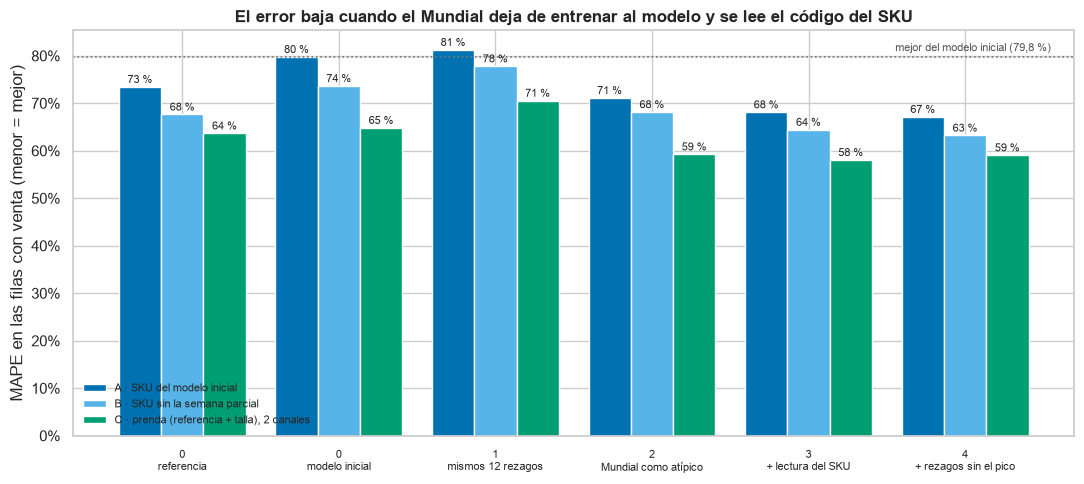

- mejor del modelo inicial (LinearSVR): MAE / RMSE / MAPE con venta: (0.368, 1.102, 0.798)
- mismos datos, HGB con el Mundial → sin el Mundial (MAPE con venta): (0.813, 0.711)
- sesgo con el Mundial → sin el Mundial: (0.202, -0.031)
- + atributos del SKU / + rezagos topados (MAPE con venta): (0.681, 0.672)
- modelo propuesto en el panel del modelo inicial: MAE / RMSE / MAPE con venta: (0.4, 1.045, 0.672)
- modelo propuesto sin la semana parcial (MAPE con venta): 0.632
- modelo propuesto por prenda (MAPE con venta / WAPE): (0.591, 0.563)
- media de 4 semanas en los tres paneles (MAPE con venta): (0.735, 0.677, 0.637)


In [87]:
# 6.11.4 Gráfica y cifras: MAPE en las filas con venta, paso a paso
_orden = list(comparacion_inicial["paso"])
_paneles = list(dict.fromkeys(comparacion_sku["panel"]))
_w = comparacion_sku.pivot(index="paso", columns="panel", values="MAPE_con_venta").loc[_orden, _paneles]
_ref_inicial = MODELO_INICIAL_CURSO["LinearSVR"]["MAPE_con_venta"]
fig, ax = plt.subplots(figsize=(11, 5))
_x = np.arange(len(_orden))
for i, pnl in enumerate(_paneles):
    ax.bar(_x + (i - 1) * 0.27, _w[pnl], width=0.27, label=pnl, color=[OKABE_ITO[0], OKABE_ITO[5], OKABE_ITO[2]][i])
    for xx, v in zip(_x + (i - 1) * 0.27, _w[pnl]):
        ax.text(xx, v + 0.008, f"{v * 100:.0f} %", ha="center", fontsize=8)
ax.axhline(_ref_inicial, color="#777777", ls=":", lw=1.2)
ax.text(len(_orden) - 0.45, _ref_inicial + 0.012, f"mejor del modelo inicial ({_ref_inicial * 100:.1f} %)".replace(".", ","),
        ha="right", fontsize=8, color="#555555")
ax.set_xticks(_x, [p.replace(" · ", "\n", 1) for p in _orden], fontsize=8)
ax.set_ylabel("MAPE en las filas con venta (menor = mejor)")
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_title("El error baja cuando el Mundial deja de entrenar al modelo y se lee el código del SKU")
ax.legend(fontsize=8, frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig(RUTAS["figuras"] / "6_11_01_comparacion_modelo_inicial.png", dpi=150)
plt.show()

_m = comparacion_sku.set_index(["panel", "paso"])
_pa, _pb, _pc = _paneles
_fin = "4 · + rezagos sin el pico"


def _c(panel, paso, col):
    return round(float(_m.loc[(panel, paso), col]), 3)


h611 = {
    "mejor del modelo inicial (LinearSVR): MAE / RMSE / MAPE con venta": tuple(_c(_pa, "0 · modelo inicial", c) for c in ["MAE", "RMSE", "MAPE_con_venta"]),
    "mismos datos, HGB con el Mundial → sin el Mundial (MAPE con venta)": (_c(_pa, "1 · mismos 12 rezagos", "MAPE_con_venta"),
                                                                           _c(_pa, "2 · Mundial como atípico", "MAPE_con_venta")),
    "sesgo con el Mundial → sin el Mundial": (_c(_pa, "1 · mismos 12 rezagos", "sesgo"), _c(_pa, "2 · Mundial como atípico", "sesgo")),
    "+ atributos del SKU / + rezagos topados (MAPE con venta)": (_c(_pa, "3 · + lectura del SKU", "MAPE_con_venta"), _c(_pa, _fin, "MAPE_con_venta")),
    "modelo propuesto en el panel del modelo inicial: MAE / RMSE / MAPE con venta": tuple(_c(_pa, _fin, c) for c in ["MAE", "RMSE", "MAPE_con_venta"]),
    "modelo propuesto sin la semana parcial (MAPE con venta)": _c(_pb, _fin, "MAPE_con_venta"),
    "modelo propuesto por prenda (MAPE con venta / WAPE)": (_c(_pc, _fin, "MAPE_con_venta"), _c(_pc, _fin, "WAPE")),
    "media de 4 semanas en los tres paneles (MAPE con venta)": tuple(_c(p, "0 · referencia", "MAPE_con_venta") for p in _paneles),
}
for k, v in h611.items():
    print(f"- {k}: {v}")


### 6.11.5 Lectura (borrador técnico; redactar con palabras propias)

Las cifras exactas las imprime la celda anterior (`h611`).

- **Se reproduce el modelo inicial**: el LinearSVR da el mismo MAE (0,368) y el mismo MAPE en casos con venta (79,8 %).
- **El Mundial era lo que más inflaba el error.** Con los mismos 12 rezagos, un boosting entrenado *con* las semanas del Mundial queda en ~81 %
  y sobrepronostica (+20 %): aprende que la demanda "se dispara" y lo repite en septiembre. Al sacar esas semanas baja a ~71 % y el sesgo desaparece.
- **Leer el SKU ayuda**: con género, tela, color, talla, proceso y reflectivo baja a ~68 %, y a ~67 % cuando los rezagos no arrastran el pico.
- **Sin la semana parcial** el modelo propuesto queda en ~63 %; **por prenda** (referencia + talla, con Dropi incluido) en ~59 %, con WAPE ~0,56.
- **Límites que hay que decir**: (a) la media de las 4 semanas anteriores es una referencia fuerte (73 % / 68 % / 64 %): el modelo le gana por pocos puntos;
  (b) en **MAE** el LinearSVR sigue siendo mejor (0,37 vs 0,40), porque con 84 % de ceros un modelo que predice casi cero minimiza el error absoluto
  aunque no sirva para planear; en **RMSE** y en MAPE con venta gana el propuesto; (c) el panel C no es comparable fila a fila con el A (otra unidad).


## 7. Graficación final

Esta sección cierra el catálogo de gráficas del plan (§7.2) y deja las versiones para el póster (§9). Casi todas las gráficas ya
se hicieron en §3–§6 junto a su análisis; aquí solo se agregan las que faltaban y se hace el inventario:

1. **7.1 Estilo común.** Misma paleta Okabe-Ito de §0.4 y los mismos colores por modelo (`ESTILO_MODELO`) y familia (`COLOR_FAMILIA`)
   de §6. Se agrega un estilo de letra grande para el póster.
2. **7.2 Gráficas de producción** (fila "Negocio" del plan §7.2): pronóstico por catálogo × semana, por catálogo × talla y por tela.
   Necesitan el pronóstico vigente, que se calcula con el modelo final de §6.3 (`METODO_FINAL`) desde la última semana completa (28-sep).
3. **7.3 Versión póster:** cuatro gráficas con letra grande, en PNG (300 dpi) y PDF, en `figuras/poster/`.
4. **7.4 Índice de figuras:** cada fila del plan §7.2 con su archivo, para que el notebook, la documentación y el póster usen las mismas.

Principios del plan §7.1 que se aplican en todas: el título dice la conclusión y se arma con las cifras de la corrida; los ejes llevan
unidades; la banda amarilla marca el Mundial; no hay 3D, tortas ni doble eje. El plan sugiere plotly para explorar, pero no está en
`requirements.txt` y no se agregó: las gráficas del notebook son estáticas.

> **Nota para §8:** el pronóstico de 7.2 se usa solo para graficar. §8 debe separar entrenar / guardar / pronosticar
> (reporte 04, punto 2) y producir las tablas oficiales. Con la misma semilla y el mismo corte las cifras deben coincidir.

In [88]:
# 7.1 Estilo común para las gráficas finales y el póster
from contextlib import contextmanager

RUTA_POSTER = RUTAS["figuras"] / "poster"
RUTA_POSTER.mkdir(exist_ok=True)
COLOR_PRONOSTICO = ESTILO_MODELO[MODELO_FINAL][0]       # mismo color del modelo final en las gráficas de §6
COLOR_INGENUO = ESTILO_MODELO["ingenuo"][0]
CMAP_UNIDADES = "Blues"                                  # secuencial de un solo tono: se lee con daltonismo y en gris

RC_POSTER = {"font.size": 18, "axes.titlesize": 22, "axes.titleweight": "bold", "axes.labelsize": 18,
             "xtick.labelsize": 15, "ytick.labelsize": 15, "legend.fontsize": 15,
             "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 3}


@contextmanager
def estilo_poster():
    """Letra grande y sin bordes superior y derecho, para leer la gráfica a 2 m (plan §9.1)."""
    with plt.rc_context(RC_POSTER):
        yield


def guardar_poster(fig, nombre):
    """PNG a 300 dpi (para Canva / PowerPoint) y PDF vectorial (para imprimir en A0/A1) en figuras/poster/."""
    rutas = [RUTA_POSTER / f"{nombre}.png", RUTA_POSTER / f"{nombre}.pdf"]
    fig.savefig(rutas[0], dpi=300)
    fig.savefig(rutas[1])
    return rutas


def etiqueta_cat(c, n=32):
    return c.replace("CUELLO ALTO ", "CA ")[:n]


def miles(x):
    return f"{x:,.0f}".replace(",", ".")                   # separador de miles en español (textos del póster)


def fecha_corta(s):
    return f"{s.day}-{MESES_ES[s.month - 1]}"


print(f"Modelo final: {MODELO_FINAL} (color {COLOR_PRONOSTICO}) | póster en {RUTA_POSTER}")

Modelo final: HGB_sin_atipico (color #D55E00) | póster en C:\Users\diani\OneDrive\Escritorio\Trabajo final Klixmant S.A.S\figuras\poster


### 7.2 Gráficas de producción: el pronóstico vigente

El pronóstico sigue la regla de §6.3: **`HGB_redondeo` en el top 20** y el **ingenuo en la cola**. El corte es la última semana completa
(28-sep) y el horizonte es de 8 semanas (5-oct → 23-nov); las 4 primeras son el horizonte principal (§2).

Junto al modelo se publica el **ingenuo** (repetir la última semana), como recomienda el reporte 04 por el caso Honda Reflectivo del holdout.
Un catálogo del top se marca **para revisión manual** si en las 4 semanas el modelo y el ingenuo difieren más del 50 % y en
al menos 10 unidades (el segundo umbral evita marcar catálogos que venden 1–5 unidades).
Los intervalos 10–90 % son los calibrados en §6.5 (conservadores: cubrieron el 92 % en el holdout).

In [89]:
# 7.2.1 Pronóstico vigente: corte = última semana completa, 8 semanas, top con el modelo final y cola con el ingenuo
_t0 = time.time()
CORTE_VIGENTE = ULTIMA_SEMANA_COMPLETA
UMBRAL_REVISION = 0.5                                    # |modelo − ingenuo| / ingenuo en las 4 semanas
UMBRAL_REVISION_UDS = 10                                 # y al menos 10 uds de diferencia (no marcar catálogos de 1–5 uds)
ctx_vigente = contexto(CORTE_VIGENTE)
_reglas = {"modelo": METODO_FINAL, "ingenuo": m_ingenuo}
_p = {n: f(CORTE_VIGENTE, H_EXT, ctx_vigente).rename(columns={"pred": f"pred_{n}"}) for n, f in _reglas.items()}
pron_vigente = _p["modelo"].merge(_p["ingenuo"], on=["catalogo", "semana", "h"])
pron_vigente["segmento"] = np.where(pron_vigente["catalogo"].isin(TOP), "top", "cola")
pron_vigente["pred"] = np.where(pron_vigente["segmento"] == "top", pron_vigente["pred_modelo"], pron_vigente["pred_ingenuo"])
assert pron_vigente["semana"].min() == CORTE_VIGENTE + SEMANA and pron_vigente["h"].max() == H_EXT

# Intervalos calibrados (§6.5) solo para el top, que es donde se calibraron
_top = aplicar_intervalo(pron_vigente[pron_vigente["segmento"] == "top"], CALIBRACION_INTERVALO)
pron_vigente = pron_vigente.merge(_top[["catalogo", "semana", "lo", "hi"]], on=["catalogo", "semana"], how="left")

# Catálogos del top para revisión manual
_s4 = pron_vigente[(pron_vigente["segmento"] == "top") & (pron_vigente["h"] <= H)].groupby("catalogo")[["pred_modelo", "pred_ingenuo"]].sum()
_s4["dif_rel"] = (_s4["pred_modelo"] - _s4["pred_ingenuo"]) / _s4["pred_ingenuo"].clip(lower=1)
_s4["dif_uds"] = _s4["pred_modelo"] - _s4["pred_ingenuo"]
_s4["revisar"] = (_s4["dif_rel"].abs() > UMBRAL_REVISION) & (_s4["dif_uds"].abs() >= UMBRAL_REVISION_UDS)
REVISAR = list(_s4.index[_s4["revisar"]])
pron_vigente["revisar"] = pron_vigente["catalogo"].isin(REVISAR)

# Hacia abajo (talla × color, solo top) y hacia arriba (tela, todos los catálogos)
tc_vigente = desagregar_talla_color(pron_vigente[pron_vigente["segmento"] == "top"][["catalogo", "semana", "h", "pred"]], CORTE_VIGENTE)
tela_vigente = agregar_tela(pron_vigente[["catalogo", "semana", "h", "pred"]])
assert np.isclose(tc_vigente["pred_tc"].sum(), pron_vigente.loc[pron_vigente["segmento"] == "top", "pred"].sum())
_cob_tela = tela_vigente["pred_tela"].sum() / pron_vigente["pred"].sum()

_tot = pron_vigente[pron_vigente["h"] <= H].groupby("segmento")[["pred", "pred_ingenuo"]].sum()
print(f"Pronóstico vigente en {time.time() - _t0:.0f} s: {pron_vigente['catalogo'].nunique()} catálogos × {H_EXT} semanas "
      f"({fecha_corta(pron_vigente['semana'].min())} → {fecha_corta(pron_vigente['semana'].max())})")
print(f"Próximas {H} semanas: top {_tot.loc['top', 'pred']:,.0f} uds (ingenuo {_tot.loc['top', 'pred_ingenuo']:,.0f}) | "
      f"cola {_tot.loc['cola', 'pred']:,.0f} uds | unidades que llegan a tela: {_cob_tela:.1%}")
print(f"Catálogos del top para revisión manual (diferencia > {UMBRAL_REVISION:.0%} frente al ingenuo): {len(REVISAR)}")
_s4.sort_values("dif_rel", key=abs, ascending=False).round(2).head(10)

Pronóstico vigente en 21 s: 792 catálogos × 8 semanas (5-oct → 23-nov)
Próximas 4 semanas: top 1,717 uds (ingenuo 1,372) | cola 984 uds | unidades que llegan a tela: 100.0%
Catálogos del top para revisión manual (diferencia > 50% frente al ingenuo): 4


,pred_modelo,pred_ingenuo,dif_rel,dif_uds,revisar
catalogo,,,,,
CUELLO ALTO NACIONAL REY DE COPAS,23.890,12.000,0.990,11.890,True
CUELLO ALTO ARGENTINA,0.870,0.000,0.870,0.870,False
CUELLO ALTO PORTUGAL,0.790,0.000,0.790,0.790,False
CUELLO ALTO RED BULL,160.680,96.000,0.670,64.680,True
BUZO COLOMBIA VISITANTE,0.640,0.000,0.640,0.640,False
CUELLO ALTO BMW ESTAMPADO REFLECTIVO,184.350,120.000,0.540,64.350,True
FORD,85.380,56.000,0.520,29.380,True
CUELLO ALTO COLOMBIA,4.940,8.000,-0.380,-3.060,False
CUELLO ALTO MERCEDES,270.870,196.000,0.380,74.870,False


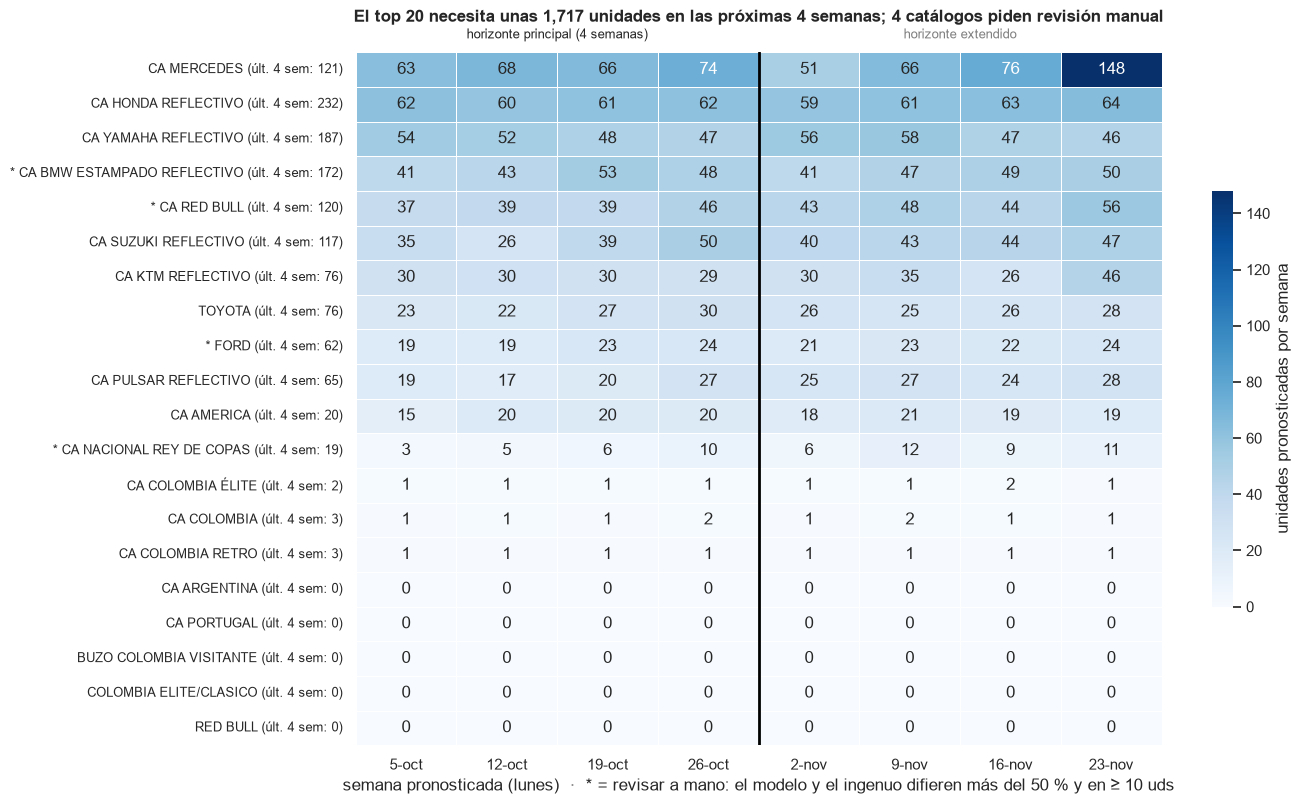

In [90]:
# 7.2.2 Heatmap catálogo × semana pronosticada (top 20): lo que hay que confeccionar cada semana
_m = (pron_vigente[pron_vigente["segmento"] == "top"].pivot(index="catalogo", columns="semana", values="pred"))
ORDEN_TOP_VIGENTE = list(_m[_m.columns[:H]].sum(axis=1).sort_values(ascending=False).index)
_m = _m.loc[ORDEN_TOP_VIGENTE]
_ult4 = (panel_y[panel_y["catalogo"].isin(TOP) & (panel_y["semana"] > CORTE_VIGENTE - SEMANA * H)]
         .groupby("catalogo")["y"].sum())
_tot4 = _m[_m.columns[:H]].sum().sum()

fig, ax = plt.subplots(figsize=(13, 9))
sns.heatmap(_m, annot=True, fmt=".0f", cmap=CMAP_UNIDADES, linewidths=.5, linecolor="white", ax=ax,
            cbar_kws={"label": "unidades pronosticadas por semana", "shrink": .6})
ax.set_yticks(np.arange(len(_m)) + .5,
              [f"{'* ' if c in REVISAR else ''}{etiqueta_cat(c)} (últ. 4 sem: {_ult4.get(c, 0):.0f})" for c in _m.index],
              rotation=0, fontsize=9)
ax.set_xticks(np.arange(H_EXT) + .5, [fecha_corta(s) for s in _m.columns], rotation=0)
ax.axvline(H, color="black", lw=2)
ax.text(H / 2, -0.4, "horizonte principal (4 semanas)", ha="center", fontsize=9)
ax.text(H + (H_EXT - H) / 2, -0.4, "horizonte extendido", ha="center", fontsize=9, color="grey")
ax.set(xlabel="semana pronosticada (lunes)  ·  * = revisar a mano: el modelo y el ingenuo difieren más del 50 % y en ≥ 10 uds",
       ylabel="")
_txt_rev = (f"{len(REVISAR)} catálogos piden revisión manual" if REVISAR else "ninguno se aparta del ingenuo lo bastante para revisarlo a mano")
ax.set_title(f"El top 20 necesita unas {_tot4:,.0f} unidades en las próximas 4 semanas; {_txt_rev}", fontweight="bold", pad=22)
guardar_fig(fig, "7_2_01_pronostico_catalogo_semana"); plt.show()

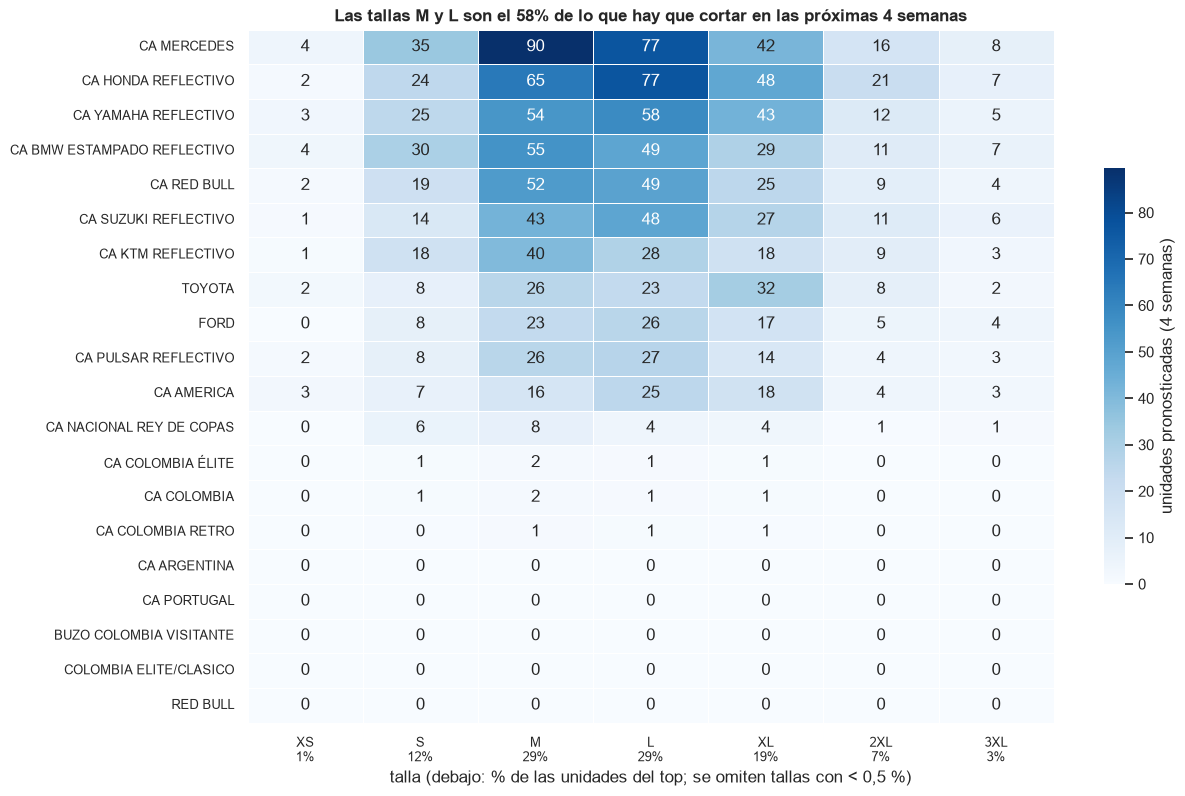

talla_std,XS,S,M,L,XL,2XL,3XL,total
catalogo,,,,,,,,
CUELLO ALTO MERCEDES,4,35,90,77,42,16,8,272
CUELLO ALTO HONDA REFLECTIVO,2,24,65,77,48,21,7,244
CUELLO ALTO YAMAHA REFLECTIVO,3,25,54,58,43,12,5,200
CUELLO ALTO BMW ESTAMPADO REFLECTIVO,4,30,55,49,29,11,7,185
CUELLO ALTO RED BULL,2,19,52,49,25,9,4,160
CUELLO ALTO SUZUKI REFLECTIVO,1,14,43,48,27,11,6,150
CUELLO ALTO KTM REFLECTIVO,1,18,40,28,18,9,3,117
TOYOTA,2,8,26,23,32,8,2,101
FORD,0,8,23,26,17,5,4,83


In [91]:
# 7.2.3 Heatmap catálogo × talla en las próximas 4 semanas (top 20): base para planear los cortes
_tc4 = tc_vigente[tc_vigente["h"] <= H].groupby(["catalogo", "talla_std"])["pred_tc"].sum().unstack(fill_value=0)
_cols = [t for t in SIGLAS_TALLA + ["AMBIGUA", "SIN_TALLA"] if t in _tc4.columns and _tc4[t].sum() >= 0.005 * _tc4.values.sum()]
_tc4 = _tc4.reindex(index=ORDEN_TOP_VIGENTE, columns=_cols).fillna(0)
_part_talla = _tc4.sum() / _tc4.sum().sum()
_dos = _part_talla.sort_values(ascending=False).head(2)

fig, ax = plt.subplots(figsize=(13, 9))
sns.heatmap(_tc4, annot=True, fmt=".0f", cmap=CMAP_UNIDADES, linewidths=.5, linecolor="white", ax=ax,
            cbar_kws={"label": f"unidades pronosticadas ({H} semanas)", "shrink": .6})
ax.set_yticks(np.arange(len(_tc4)) + .5, [etiqueta_cat(c) for c in _tc4.index], rotation=0, fontsize=9)
ax.set_xticks(np.arange(len(_cols)) + .5, [f"{t}\n{_part_talla[t]:.0%}" for t in _cols], rotation=0, fontsize=9)
ax.set(xlabel="talla (debajo: % de las unidades del top; se omiten tallas con < 0,5 %)", ylabel="")
ax.set_title(f"Las tallas {_dos.index[0]} y {_dos.index[1]} son el {_dos.sum():.0%} de lo que hay que cortar en las próximas "
             f"{H} semanas", fontweight="bold")
guardar_fig(fig, "7_2_02_pronostico_catalogo_talla"); plt.show()
_tc4.round(0).astype(int).assign(total=lambda d: d.sum(axis=1)).head(10)

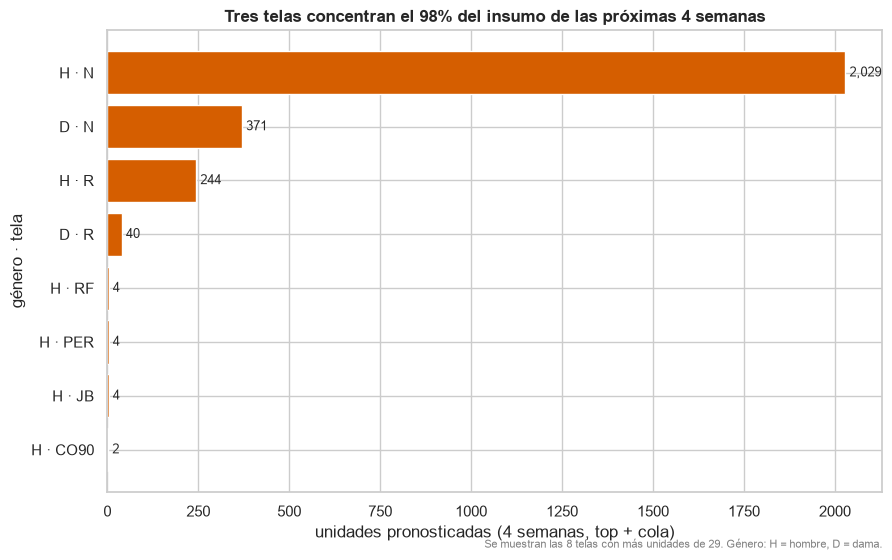

In [92]:
# 7.2.4 Insumo: unidades por tela (género · tela) en las próximas 4 semanas, todos los catálogos
_tl = tela_vigente[tela_vigente["semana"] <= CORTE_VIGENTE + SEMANA * H]
_tl = _tl.assign(tela_g=_tl["genero"].astype(str) + " · " + _tl["tela"].astype(str)).groupby("tela_g")["pred_tela"].sum()
_tl = _tl.sort_values(ascending=False)
_n_tl = 8
_tres = _tl.head(3).sum() / _tl.sum()

fig, ax = plt.subplots(figsize=(10, 6))
_d = _tl.head(_n_tl)[::-1]
ax.barh(_d.index, _d.values, color=COLOR_PRONOSTICO)
for y, v in enumerate(_d.values):
    ax.text(v, y, f" {v:,.0f}", va="center", fontsize=9)
ax.set(xlabel=f"unidades pronosticadas ({H} semanas, top + cola)", ylabel="género · tela",
       title=f"Tres telas concentran el {_tres:.0%} del insumo de las próximas {H} semanas")
ax.text(1, -0.12, f"Se muestran las {_n_tl} telas con más unidades de {len(_tl)}. Género: H = hombre, D = dama.",
        transform=ax.transAxes, ha="right", fontsize=8, color="grey")
guardar_fig(fig, "7_2_03_pronostico_tela"); plt.show()

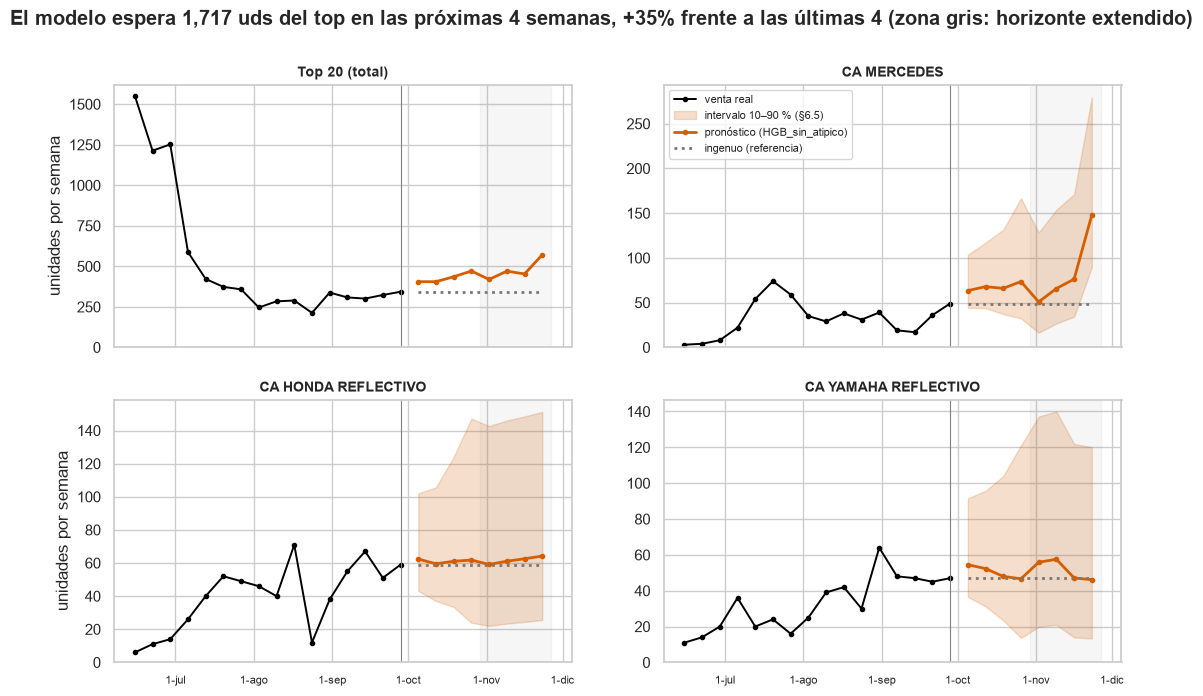

In [93]:
# 7.2.5 Historia y pronóstico: total del top y los 3 catálogos con más unidades pronosticadas, con intervalo y el ingenuo
_desde = CORTE_VIGENTE - SEMANA * 15
_paneles = [("Top 20 (total)", TOP)] + [(etiqueta_cat(c), [c]) for c in ORDEN_TOP_VIGENTE[:3]]
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True)
for ax, (titulo, cats) in zip(axes.flat, _paneles):
    hist = panel_y[panel_y["catalogo"].isin(cats) & (panel_y["semana"] >= _desde)].groupby("semana")["y"].sum()
    fut = pron_vigente[pron_vigente["catalogo"].isin(cats)].groupby("semana")[["pred", "pred_ingenuo", "lo", "hi"]].sum()
    ax.plot(hist.index, hist.values, color="black", lw=1.4, marker="o", ms=3, label="venta real")
    if len(cats) == 1:                                   # el intervalo es por catálogo; no se suma para el total
        ax.fill_between(fut.index, fut["lo"], fut["hi"], color=COLOR_PRONOSTICO, alpha=.2, label="intervalo 10–90 % (§6.5)")
    ax.plot(fut.index, fut["pred"], color=COLOR_PRONOSTICO, ls=ESTILO_MODELO[MODELO_FINAL][1], lw=2, marker="o", ms=3,
            label=f"pronóstico ({MODELO_FINAL})")
    ax.plot(fut.index, fut["pred_ingenuo"], color=COLOR_INGENUO, ls=ESTILO_MODELO["ingenuo"][1], lw=2, label="ingenuo (referencia)")
    ax.axvline(CORTE_VIGENTE, color="grey", lw=.8)
    ax.axvspan(CORTE_VIGENTE + SEMANA * (H + .5), fut.index.max() + SEMANA / 2, color="grey", alpha=.07)
    ax.set_title(f"{'* ' if set(cats) & set(REVISAR) and len(cats) == 1 else ''}{titulo}", fontsize=10)
    ax.xaxis.set_major_formatter(FMT_DIA); ax.tick_params(axis="x", labelsize=8); ax.set_ylim(bottom=0)
for ax in axes[:, 0]:
    ax.set_ylabel("unidades por semana")
axes[0, 1].legend(fontsize=8, loc="upper left")
_tt = pron_vigente[(pron_vigente["segmento"] == "top") & (pron_vigente["h"] <= H)]["pred"].sum()
_u4 = panel_y[panel_y["catalogo"].isin(TOP) & (panel_y["semana"] > CORTE_VIGENTE - SEMANA * H)]["y"].sum()
fig.suptitle(f"El modelo espera {_tt:,.0f} uds del top en las próximas 4 semanas, {_tt / _u4 - 1:+.0%} frente a las últimas 4 "
             f"(zona gris: horizonte extendido)", fontweight="bold")
guardar_fig(fig, "7_2_04_historia_y_pronostico"); plt.show()

### 7.3 Versión póster

Cuatro gráficas para el flujo del póster (plan §9.2), una idea cada una:

| Archivo (`figuras/poster/`) | Bloque del póster | Mensaje |
|---|---|---|
| `P1_concentracion` | Datos | Pocos catálogos concentran la venta: se modela el top y la cola va por regla |
| `P2_mundial_base_evento` | Problema | Cuánto del pico fue evento (Colombia) y cuánto demanda base |
| `P3_colombia_despues_mundial` | Resultado (titular) | Después del Mundial el modelo no siguió pronosticando evento; la media móvil sí |
| `P4_plan_produccion` | Recomendación | Unidades por catálogo para las próximas 4 semanas, listas para producción |

El titular del póster es **P3** y no "X % mejor que el ingenuo": en §6 la mejora frente al ingenuo no fue concluyente (reporte 04, punto 1).

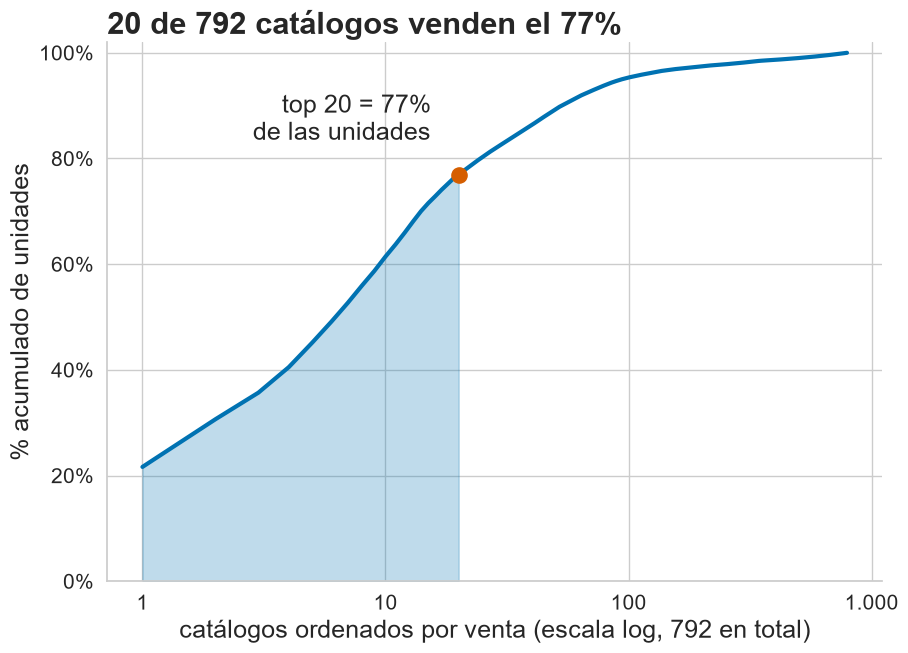

In [94]:
# 7.3.1 P1 · Concentración de la demanda (Pareto con los catálogos normalizados de §4)
_vol = panel_y.groupby("catalogo")["y"].sum().sort_values(ascending=False)
_vol = _vol[_vol > 0]
_acum = _vol.cumsum() / _vol.sum()
_n_top = len(TOP)
_p_top = _acum.iloc[_n_top - 1]

with estilo_poster():
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.plot(np.arange(1, len(_acum) + 1), _acum.values, color=COLOR_FAMILIA["RESTO"])
    ax.fill_between(np.arange(1, _n_top + 1), 0, _acum.values[:_n_top], color=COLOR_FAMILIA["RESTO"], alpha=.25)
    ax.scatter([_n_top], [_p_top], s=120, color=COLOR_FAMILIA["COLOMBIA"], zorder=3)
    ax.annotate(f"top {_n_top} = {_p_top:.0%}\nde las unidades", xy=(_n_top, _p_top), xytext=(-20, 25),
                textcoords="offset points", ha="right")
    ax.set_xscale("log")
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda x, p: f"{x:,.0f}".replace(",", ".")))
    ax.set(ylim=(0, 1.02), xlabel=f"catálogos ordenados por venta (escala log, {len(_vol)} en total)",
           ylabel="% acumulado de unidades")
    ax.set_title(f"{_n_top} de {len(_vol)} catálogos venden el {_p_top:.0%}", loc="left")
    guardar_poster(fig, "P1_concentracion"); plt.show()

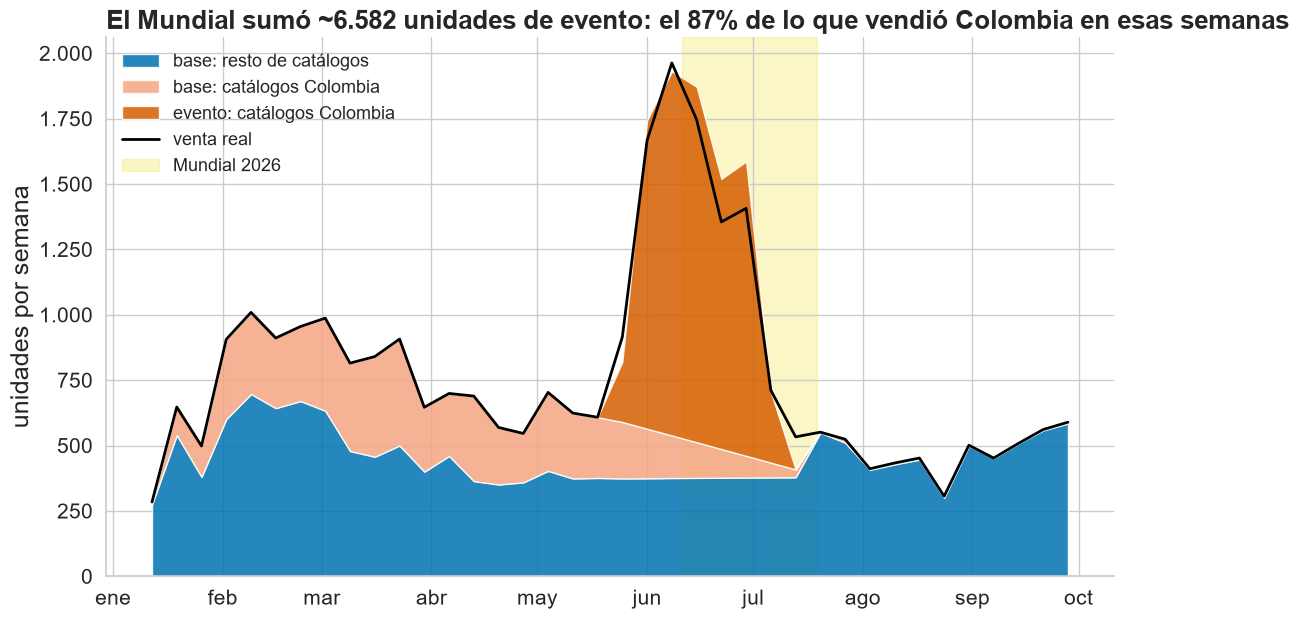

In [95]:
# 7.3.2 P2 · El Mundial: demanda base frente a demanda de evento (ruta 1 de §4.5)
_fam = base_evento.groupby(["semana", "familia"])[["y", "y_base", "y_evento"]].sum().unstack("familia")
_ev_col = incremental_familia.loc["COLOMBIA", "uds_evento_neto"]
_pct_col = incremental_familia.loc["COLOMBIA", "%_evento_sobre_real"]

with estilo_poster():
    fig, ax = plt.subplots(figsize=(13, 7))
    ax.stackplot(_fam.index, _fam[("y_base", "RESTO")], _fam[("y_base", "COLOMBIA")], _fam[("y_evento", "COLOMBIA")].clip(lower=0),
                 colors=[COLOR_FAMILIA["RESTO"], "#F4A582", COLOR_FAMILIA["COLOMBIA"]], alpha=.85,
                 labels=["base: resto de catálogos", "base: catálogos Colombia", "evento: catálogos Colombia"])
    ax.plot(_fam.index, _fam[("y", "RESTO")] + _fam[("y", "COLOMBIA")], color="black", lw=2, label="venta real")
    sombrear_mundial(ax, alpha=.3)
    ax.xaxis.set_major_formatter(FMT_MES)
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda x, p: miles(x)))
    ax.set(ylabel="unidades por semana", xlabel="")
    ax.legend(loc="upper left", fontsize=13, frameon=False)
    ax.set_title(f"El Mundial sumó ~{miles(_ev_col)} unidades de evento: el {_pct_col:.0%} de lo que vendió Colombia en esas semanas",
                 loc="left", fontsize=19)
    guardar_poster(fig, "P2_mundial_base_evento"); plt.show()

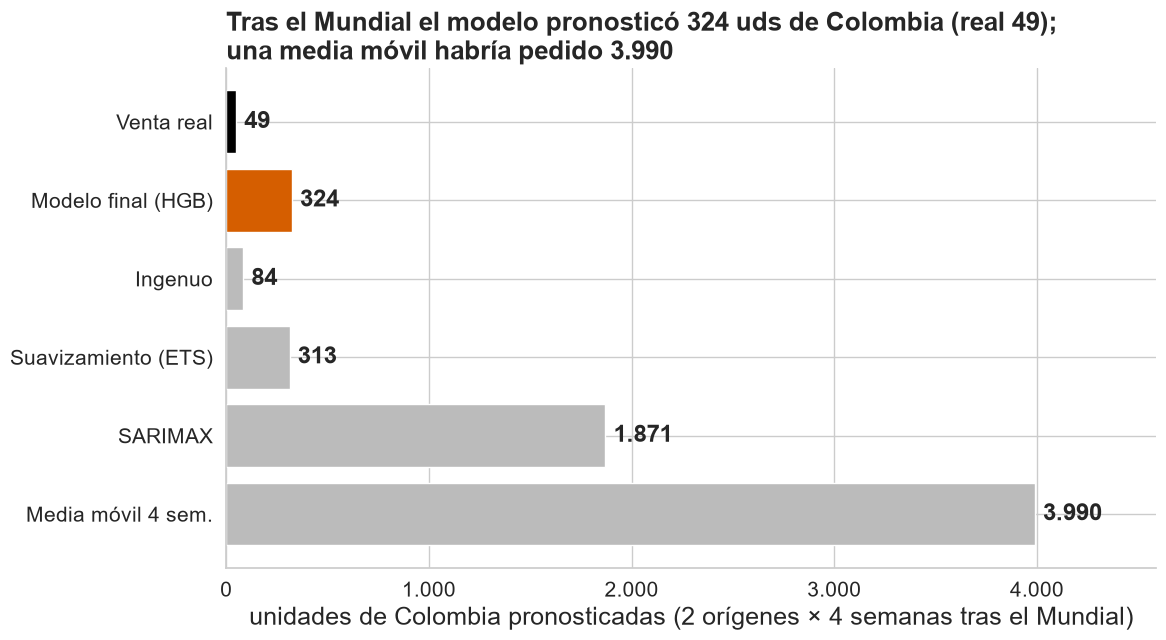

In [96]:
# 7.3.3 P3 · Titular: unidades de Colombia pronosticadas después del Mundial (backtesting, orígenes "después del evento")
_mods = [MODELO_FINAL, "ingenuo", "ETS", "SARIMAX", "media_movil_4"]
_nombres = {MODELO_FINAL: "Modelo final (HGB)", "ingenuo": "Ingenuo", "ETS": "Suavizamiento (ETS)", "SARIMAX": "SARIMAX",
            "media_movil_4": "Media móvil 4 sem."}
_real_col = float(resumen_bt.loc[MODELO_FINAL, "uds_Colombia_post_real"])
_pc = resumen_bt.loc[_mods, "uds_Colombia_post_pron"].astype(float)
_d = pd.concat([pd.Series({"Venta real": _real_col}), _pc.rename(index=_nombres)])[::-1]
_col = ["#BBBBBB" if n not in ("Venta real", _nombres[MODELO_FINAL]) else ("black" if n == "Venta real" else COLOR_PRONOSTICO)
        for n in _d.index]
_n_or = sum(fase_origen(c) == "después del evento" for c in CORTES_BT)

with estilo_poster():
    fig, ax = plt.subplots(figsize=(12, 6.5))
    ax.barh(_d.index, _d.values, color=_col)
    for y, v in enumerate(_d.values):
        ax.text(v + _d.max() * .01, y, miles(v), va="center", fontsize=17, fontweight="bold")
    ax.set_xlim(0, _d.max() * 1.15)
    ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda x, p: miles(x)))
    ax.set(xlabel=f"unidades de Colombia pronosticadas ({_n_or} orígenes × {H} semanas tras el Mundial)")
    ax.set_title(f"Tras el Mundial el modelo pronosticó {miles(_pc[MODELO_FINAL])} uds de Colombia (real {miles(_real_col)});\n"
                 f"una media móvil habría pedido {miles(_pc['media_movil_4'])}", loc="left", fontsize=19)
    guardar_poster(fig, "P3_colombia_despues_mundial"); plt.show()

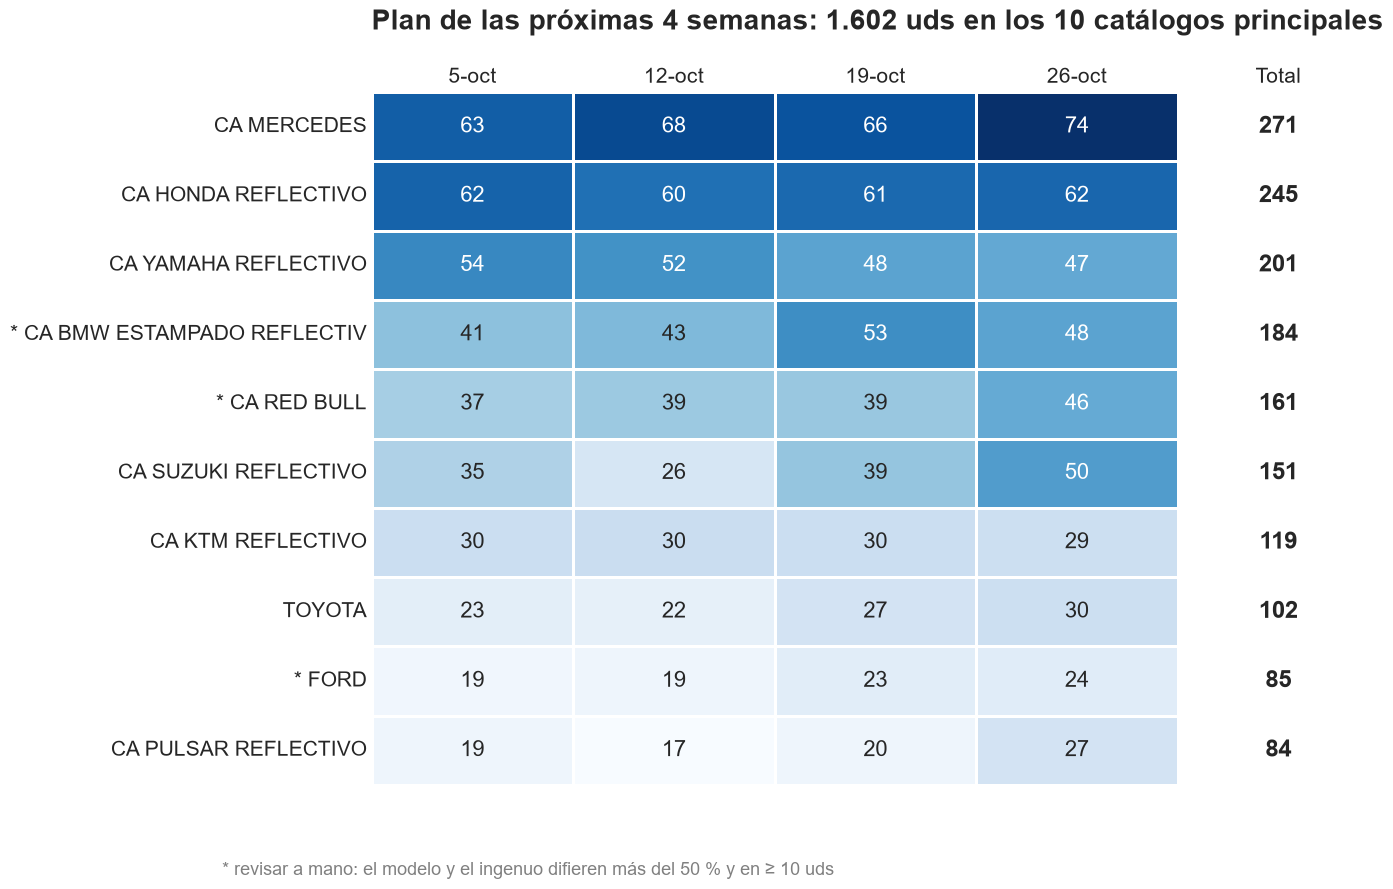

In [97]:
# 7.3.4 P4 · Plan de producción: top 10 × próximas 4 semanas
_n_p4 = 10
_m4 = (pron_vigente[(pron_vigente["segmento"] == "top") & (pron_vigente["h"] <= H)]
       .pivot(index="catalogo", columns="semana", values="pred").loc[ORDEN_TOP_VIGENTE[:_n_p4]])
_m4["Total"] = _m4.sum(axis=1)

with estilo_poster():
    fig, ax = plt.subplots(figsize=(13, 9))
    _mask = np.zeros(_m4.shape, dtype=bool); _mask[:, -1] = True
    sns.heatmap(_m4, mask=_mask, annot=True, fmt=".0f", cmap=CMAP_UNIDADES, cbar=False, linewidths=1, linecolor="white",
                annot_kws={"fontsize": 16}, ax=ax)
    for y, v in enumerate(_m4["Total"]):
        ax.text(H + .5, y + .5, miles(v), ha="center", va="center", fontsize=17, fontweight="bold")
    ax.set_yticks(np.arange(_n_p4) + .5, [f"{'* ' if c in REVISAR else ''}{etiqueta_cat(c, 26)}" for c in _m4.index], rotation=0)
    ax.set_xticks(np.arange(H + 1) + .5, [fecha_corta(s) for s in _m4.columns[:H]] + ["Total"], rotation=0)
    ax.tick_params(axis="x", top=False, labeltop=True, bottom=False, labelbottom=False, length=0)
    ax.tick_params(axis="y", length=0); ax.grid(False)
    ax.set(xlabel="", ylabel="")
    ax.set_title(f"Plan de las próximas {H} semanas: {miles(_m4['Total'].sum())} uds en los {_n_p4} catálogos principales",
                 loc="left", pad=45, fontsize=20)
    if REVISAR:
        fig.text(.01, .01, "* revisar a mano: el modelo y el ingenuo difieren más del 50 % y en ≥ 10 uds", fontsize=13, color="grey")
    guardar_poster(fig, "P4_plan_produccion"); plt.show()

### 7.4 Índice de figuras

Cada fila del catálogo del plan §7.2 apunta a su archivo. La tabla se guarda en `docs/7_indice_figuras.csv` para usarla en la documentación
y en el póster. Las figuras que no están en el plan (por ejemplo, el cuadre de fechas de §3.1 o la cobertura de intervalos de §6.5)
aparecen como "complementaria".

In [98]:
# 7.4 Índice: plan §7.2 → archivo en figuras/ (se verifica que exista)
_PLAN_72 = [
    ("EDA", "Serie semanal total y por canal, con banda del Mundial", ["3_2_01_serie_semanal_canal"]),
    ("EDA", "Curva de Pareto de catálogos", ["3_2_02_pareto_catalogos", "poster/P1_concentracion"]),
    ("EDA", "Dispersión ADI vs CV² con cuadrantes", ["3_2_03_adi_cv2"]),
    ("EDA", "STL de la serie total y de 2–3 catálogos top", ["3_2_04_stl_diaria_total", "3_2_05_stl_top3"]),
    ("EDA", "ACF / PACF", ["3_2_06_acf_pacf_semanal"]),
    ("EDA", "Heatmap día de la semana × semana", ["3_2_08_heatmap_dia_semana"]),
    ("EDA", "Barras al 100 % de talla dentro de los catálogos top", ["3_2_11_mezcla_tallas_top4"]),
    ("Preparación", "Perfiles promedio por clúster K-means", ["4_4_02_perfiles_cluster"]),
    ("Modelo", "Real vs pronóstico con intervalo, 3–4 catálogos top", ["6_5_02_holdout_real_vs_pronostico", "7_2_04_historia_y_pronostico"]),
    ("Modelo", "Base vs evento apilado", ["4_5_01_base_evento_top6", "4_5_02_base_evento_familia", "5_7_01_base_evento_dos_rutas",
                                          "poster/P2_mundial_base_evento"]),
    ("Evaluación", "Barras de WAPE / MASE por modelo", ["5_5_01_wape_por_modelo", "6_2_01_wape_por_origen_backtesting",
                                                         "6_2_02_wape_por_horizonte", "poster/P3_colombia_despues_mundial"]),
    ("Evaluación", "Error por catálogo (ordenado)", ["6_6_01_error_por_catalogo_holdout"]),
    ("Explicabilidad", "Importancia por permutación", ["5_9_01_importancia_permutacion"]),
    ("Negocio", "Tabla/heatmap catálogo × talla × semana pronosticada", ["7_2_01_pronostico_catalogo_semana", "7_2_02_pronostico_catalogo_talla",
                                                                        "7_2_03_pronostico_tela", "poster/P4_plan_produccion"]),
]
_filas = [{"fase_plan": f, "grafica_plan": g, "archivo": f"figuras/{a}.png", "poster": a.startswith("poster/")}
          for f, g, archivos in _PLAN_72 for a in archivos]
_en_plan = {Path(r["archivo"]).name for r in _filas}
_SECCION = {"3": "EDA", "4": "Preparación", "5": "Modelo", "6": "Evaluación", "7": "Negocio"}
_filas += [{"fase_plan": _SECCION.get(p.name[0], "—"), "grafica_plan": "complementaria", "archivo": f"figuras/{p.name}", "poster": False}
           for p in sorted(RUTAS["figuras"].glob("*.png")) if p.name not in _en_plan]
indice_figuras = pd.DataFrame(_filas)
indice_figuras["existe"] = [(BASE / a).exists() for a in indice_figuras["archivo"]]
assert indice_figuras["existe"].all(), indice_figuras.loc[~indice_figuras["existe"], "archivo"].tolist()
indice_figuras.to_csv(RUTAS["docs"] / "7_indice_figuras.csv", index=False, encoding="utf-8")
_n_plan = (indice_figuras["grafica_plan"] != "complementaria")
print(f"{len(_PLAN_72)} gráficas del plan §7.2 cubiertas con {_n_plan.sum()} archivos (4 de póster) "
      f"+ {(~_n_plan).sum()} complementarias. Índice en docs/7_indice_figuras.csv")
indice_figuras[_n_plan]

14 gráficas del plan §7.2 cubiertas con 26 archivos (4 de póster) + 12 complementarias. Índice en docs/7_indice_figuras.csv


,fase_plan,grafica_plan,archivo,poster,existe
0,EDA,"Serie semanal total y por canal, con banda del...",figuras/3_2_01_serie_semanal_canal.png,False,True
1,EDA,Curva de Pareto de catálogos,figuras/3_2_02_pareto_catalogos.png,False,True
2,EDA,Curva de Pareto de catálogos,figuras/poster/P1_concentracion.png,True,True
3,EDA,Dispersión ADI vs CV² con cuadrantes,figuras/3_2_03_adi_cv2.png,False,True
4,EDA,STL de la serie total y de 2–3 catálogos top,figuras/3_2_04_stl_diaria_total.png,False,True
5,EDA,STL de la serie total y de 2–3 catálogos top,figuras/3_2_05_stl_top3.png,False,True
6,EDA,ACF / PACF,figuras/3_2_06_acf_pacf_semanal.png,False,True
7,EDA,Heatmap día de la semana × semana,figuras/3_2_08_heatmap_dia_semana.png,False,True
8,EDA,Barras al 100 % de talla dentro de los catálog...,figuras/3_2_11_mezcla_tallas_top4.png,False,True
9,Preparación,Perfiles promedio por clúster K-means,figuras/4_4_02_perfiles_cluster.png,False,True


In [99]:
# 7.5 Exportación de las tablas que alimentan las gráficas de producción (§8 genera las oficiales)
_exportar7 = {
    "7_pronostico_vigente_catalogo.csv": pron_vigente[["catalogo", "segmento", "semana", "h", "pred", "pred_modelo", "pred_ingenuo",
                                                       "lo", "hi", "revisar"]],
    "7_pronostico_vigente_talla_color.csv": tc_vigente[["catalogo", "semana", "h", "talla_std", "color", "prop", "pred_tc"]],
    "7_pronostico_vigente_tela.csv": tela_vigente,
    "7_revision_vs_ingenuo.csv": _s4.reset_index(),
}
for nombre, df in _exportar7.items():
    df.to_csv(RUTAS["procesado"] / nombre, index=False, encoding="utf-8")
    print(f"{nombre:<40} {len(df):>8,} filas")

7_pronostico_vigente_catalogo.csv           6,336 filas
7_pronostico_vigente_talla_color.csv        4,824 filas
7_pronostico_vigente_tela.csv                 960 filas
7_revision_vs_ingenuo.csv                      20 filas


### 7.6 Hallazgos de la graficación (para redactar con palabras propias)

In [100]:
_top4 = pron_vigente[(pron_vigente["segmento"] == "top") & (pron_vigente["h"] <= H)]
h7 = {
    "corte y horizonte del pronóstico vigente": f"{CORTE_VIGENTE.date()} → {fecha_corta(pron_vigente['semana'].min())} … "
                                                f"{fecha_corta(pron_vigente['semana'].max())} ({H_EXT} semanas)",
    "uds próximas 4 semanas: top modelo / top ingenuo / cola": (round(float(_top4["pred"].sum())), round(float(_top4["pred_ingenuo"].sum())),
        round(float(pron_vigente[(pron_vigente["segmento"] == "cola") & (pron_vigente["h"] <= H)]["pred"].sum()))),
    "uds top últimas 4 semanas reales": round(float(_u4)),
    "catálogos del top para revisión manual": REVISAR,
    "catálogo con más unidades pronosticadas (4 semanas)": ORDEN_TOP_VIGENTE[0],
    "2 tallas principales y su %": (list(_dos.index), f"{_dos.sum():.0%}"),
    "3 telas principales y su %": (list(_tl.head(3).index), f"{_tres:.0%}"),
    "P1: catálogos del top / total y % de unidades": (_n_top, len(_vol), f"{_p_top:.0%}"),
    "P2: uds de evento Colombia y % de su venta en la ventana": (round(float(_ev_col)), f"{_pct_col:.0%}"),
    "P3: Colombia tras el Mundial (real / final / ingenuo / media móvil)": (round(_real_col), *[round(float(_pc[m])) for m in [MODELO_FINAL, "ingenuo", "media_movil_4"]]),
    "figuras del plan / complementarias / póster": (int(_n_plan.sum()), int((~_n_plan).sum()), int(indice_figuras["poster"].sum())),
}
for k, v in h7.items():
    print(f"- {k}: {v}")

- corte y horizonte del pronóstico vigente: 2026-09-28 → 5-oct … 23-nov (8 semanas)
- uds próximas 4 semanas: top modelo / top ingenuo / cola: (1717, 1372, 984)
- uds top últimas 4 semanas reales: 1275
- catálogos del top para revisión manual: ['CUELLO ALTO BMW ESTAMPADO REFLECTIVO', 'CUELLO ALTO NACIONAL REY DE COPAS', 'CUELLO ALTO RED BULL', 'FORD']
- catálogo con más unidades pronosticadas (4 semanas): CUELLO ALTO MERCEDES
- 2 tallas principales y su %: (['M', 'L'], '58%')
- 3 telas principales y su %: (['H · N', 'D · N', 'H · R'], '98%')
- P1: catálogos del top / total y % de unidades: (20, 792, '77%')
- P2: uds de evento Colombia y % de su venta en la ventana: (6582, '87%')
- P3: Colombia tras el Mundial (real / final / ingenuo / media móvil): (49, 324, 84, 3990)
- figuras del plan / complementarias / póster: (26, 12, 4)


## 8. Documentación y despliegue (Deployment)

El enunciado pide **documentación suficiente para orientar un pronóstico**: alguien de Klixmant debe poder generar uno nuevo sin el grupo.
Esta sección separa lo que §7 hacía en un solo paso (`METODO_FINAL` reentrena por dentro) en tres pasos explícitos:

| Paso | Celda | Producto |
|---|---|---|
| Entrenar y guardar | 8.1 | `modelos/hgb_final.joblib` + `modelos/metadata.json` (versiones, corte, parámetros, variables, categorías, intervalos) |
| Cargar y pronosticar | 8.2 | `cargar_modelo()` y `generar_pronostico()` → tablas **oficiales** `procesado/8_pronostico_*.csv`. Prueba: reproduce `pron_vigente["pred_modelo"]` de §7 |
| Documentar | 8.3 | `docs/guia_generar_pronostico.md`, `docs/model_card.md`, `docs/registro_decisiones.md` |
| Datos del tablero | 8.4 | `exportar_bundle_app()` → `app/data/` (parquet + `cifras_clave.json` + figuras + `ESQUEMA.md`) para la app Streamlit |

Modelo de producción: **`HGB_redondeo`** en el top 20 (HistGradientBoosting Poisson global, trayectoria recursiva en unidades enteras,
`early_stopping=False`) y **ingenuo** en la cola. Se entrena con toda la historia hasta la última semana completa (28-sep): el holdout ya
cumplió su papel en §6 y ahora se usa para entrenar, como es habitual antes de producción.

*Fuente: Mitchell, M. et al. (2019). Model cards for model reporting. FAT\* '19, 220–229.*

In [101]:
# 8.1 Modelo de producción: entrenar con toda la historia (corte = última semana completa), verificar y guardar
import json, hashlib, shutil
import joblib
import sklearn

CORTE_PRODUCCION = ULTIMA_SEMANA_COMPLETA
RUTA_MODELO = RUTAS["modelos"] / "hgb_final.joblib"
RUTA_METADATA = RUTAS["modelos"] / "metadata.json"
VERSIONES["joblib"] = joblib.__version__

_t0 = time.time()
ctx_prod = contexto_sin_atipico(CORTE_PRODUCCION) if MODELO_FINAL == "HGB_sin_atipico" else contexto(CORTE_PRODUCCION)
modelo_final = ajustar_hgb(ctx_prod, CORTE_PRODUCCION)                 # mismos datos y parámetros que METODO_FINAL en §7.2.1
X_prod, y_prod = datos_entrenamiento(ctx_prod, CORTE_PRODUCCION, VARIABLES_MODELO)

# Verificaciones: sin early stopping (reporte 05 §2) y las variables en el orden esperado
assert modelo_final.get_params()["early_stopping"] is False
assert MODELO_FINAL in ("HGB_redondeo", "HGB_sin_atipico"), "§8 guarda un único HGB con trayectoria redondeada"
assert modelo_final.n_iter_ == PARAMS_HGB["max_iter"] == 300, f"n_iter_ = {modelo_final.n_iter_}: revisar early_stopping"
assert list(modelo_final.feature_names_in_) == list(VARIABLES_MODELO)

joblib.dump(modelo_final, RUTA_MODELO, compress=3)
_sha = hashlib.sha256(RUTA_MODELO.read_bytes()).hexdigest()


def _a_json(x):
    """Convierte tipos de numpy/pandas a tipos de JSON (también se usa en §8.4)."""
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating,)):
        return None if np.isnan(x) else float(x)
    if isinstance(x, (np.bool_,)):
        return bool(x)
    if isinstance(x, (pd.Timestamp,)):
        return str(x.date()) if x == x.normalize() else x.isoformat()
    if isinstance(x, (pd.Timedelta,)):
        return str(x)
    if isinstance(x, (np.ndarray, pd.Index, pd.Series)):
        return [_a_json(v) for v in list(x)]
    if isinstance(x, (set, tuple)):
        return [_a_json(v) for v in x]
    if isinstance(x, dict):
        return {str(k): _a_json(v) for k, v in x.items()}
    if isinstance(x, list):
        return [_a_json(v) for v in x]
    if isinstance(x, float) and np.isnan(x):
        return None
    return x


_cats_cat = [c for c in VARIABLES_MODELO if isinstance(X_prod[c].dtype, pd.CategoricalDtype)]
metadata = {
    "modelo": MODELO_FINAL,
    "descripcion": "HistGradientBoostingRegressor (pérdida Poisson) global para los catálogos del top; pronóstico recursivo "
                   "con la trayectoria redondeada a unidades enteras. La cola se pronostica con el ingenuo (última semana)."
                   + (" El Mundial se trata como atípico: sus semanas no entran al entrenamiento y los rezagos se calculan sin el pico."
                      if MODELO_FINAL == "HGB_sin_atipico" else ""),
    "mundial_como_atipico": MODELO_FINAL == "HGB_sin_atipico",
    "archivo": RUTA_MODELO.name,
    "sha256": _sha,
    "fecha_entrenamiento": pd.Timestamp.now().isoformat(timespec="seconds"),
    "corte": CORTE_PRODUCCION,
    "primera_semana_pronostico": CORTE_PRODUCCION + SEMANA,
    "horizonte_principal": H,
    "horizonte_extendido": H_EXT,
    "frecuencia": DECISIONES["frecuencia"],
    "filas_entrenamiento": len(X_prod),
    "catalogos_entrenamiento": int(ctx_prod["panel"].loc[ctx_prod["panel"]["semana"] <= CORTE_PRODUCCION, "catalogo"].nunique()),
    "unidades_entrenamiento": float(y_prod.sum()),
    "n_iter": int(modelo_final.n_iter_),
    "params_hgb": {k: v for k, v in PARAMS_HGB.items()},
    "variables": list(VARIABLES_MODELO),
    "variables_categoricas": _cats_cat,
    "categorias": {c: [str(v) for v in X_prod[c].cat.categories] for c in _cats_cat},
    "pronostico": {"estrategia": "recursiva", "redondear": True, "tope_relativo": TOPE_RELATIVO,
                   "semanas_activo": SEMANAS_ACTIVO, "modelo_cola": MODELO_COLA_FINAL, "top": TOP},
    "intervalo": {"niveles": list(NIVELES_INTERVALO), "calibracion": CALIBRACION_ELEGIDA,
                  "z_por_h": {int(h_): {"z10": float(r[NIVELES_INTERVALO[0]]), "z90": float(r[NIVELES_INTERVALO[1]])}
                              for h_, r in CALIBRACION_INTERVALO.iterrows()},
                  "formula": "pred + z · sqrt(pred + 1), recortado en 0; para h > 4 se usa h = 4"},
    "revision_manual": {"umbral_relativo": UMBRAL_REVISION, "umbral_uds": UMBRAL_REVISION_UDS, "semanas": H},
    "eventos": {"mundial": [EVENTOS["mundial_inicio"], EVENTOS["mundial_fin"]],
                "ventana_evento": [VENTANA_EVENTO.min(), VENTANA_EVENTO.max()]},
    "semilla": SEMILLA,
    "versiones": {**VERSIONES, "scikit-learn": sklearn.__version__},
}
RUTA_METADATA.write_text(json.dumps(_a_json(metadata), ensure_ascii=False, indent=2), encoding="utf-8")

print(f"Modelo entrenado en {time.time() - _t0:.0f} s con {len(X_prod):,} filas ({metadata['catalogos_entrenamiento']} catálogos, "
      f"{y_prod.sum():,.0f} uds) hasta el {CORTE_PRODUCCION.date()} | n_iter_ = {modelo_final.n_iter_} ✅")
print(f"Guardado: {RUTA_MODELO.name} ({RUTA_MODELO.stat().st_size / 1024:,.0f} KB, sha256 {_sha[:12]}…) y {RUTA_METADATA.name}")

Modelo entrenado en 2 s con 13,233 filas (792 catálogos, 19,131 uds) hasta el 2026-09-28 | n_iter_ = 300 ✅
Guardado: hgb_final.joblib (198 KB, sha256 76deebff6a8d…) y metadata.json


### 8.2 Cargar el modelo guardado y generar el pronóstico oficial

`generar_pronostico(modelo, corte, h)` es el procedimiento que describe la guía (`docs/guia_generar_pronostico.md`):

1. `contexto(corte)` arma el panel con ceros, las variables y el clúster con datos hasta el corte.
2. **Top 20 y catálogos activos:** el modelo cargado pronostica de forma recursiva (`pronostico_recursivo(..., redondear=True)`),
   con el tope de 2 × la mejor semana del catálogo. Los catálogos sin venta en 12 semanas quedan en 0.
3. **Cola:** ingenuo (última semana). El ingenuo también se publica al lado del modelo en el top, como referencia.
4. **Intervalo 10–90 %** calibrado en §6.5 (solo top) y **bandera `revisar`** (modelo e ingenuo difieren > 50 % y ≥ 10 uds en 4 semanas).
5. Hacia abajo, **talla × color** (proporciones de las últimas 12 semanas); hacia arriba, **tela** (insumo).

**Prueba de reproducibilidad (reporte 05 §6.1):** con el mismo corte, el modelo cargado debe dar exactamente el mismo `pred_modelo` que §7.2.1.

In [102]:
# 8.2 Cargar el modelo guardado y generar el pronóstico oficial (prueba: reproduce pron_vigente de §7.2.1)
def cargar_modelo(ruta=RUTA_MODELO, ruta_meta=RUTA_METADATA):
    """Carga el modelo y su metadata; verifica integridad (sha256), iteraciones y variables."""
    meta = json.loads(Path(ruta_meta).read_text(encoding="utf-8"))
    assert hashlib.sha256(Path(ruta).read_bytes()).hexdigest() == meta["sha256"], "El archivo del modelo no coincide con la metadata"
    mod = joblib.load(ruta)
    assert mod.n_iter_ == meta["n_iter"] and list(mod.feature_names_in_) == meta["variables"]
    if meta["versiones"].get("scikit-learn") != sklearn.__version__:
        print(f"⚠️ El modelo se guardó con scikit-learn {meta['versiones'].get('scikit-learn')} y aquí hay {sklearn.__version__}")
    return mod, meta


def generar_pronostico(modelo, corte, h=H_EXT, ctx=None):
    """Pronóstico de producción desde `corte` (última semana completa observada) a `h` semanas.
    Devuelve un dict con las tablas catalogo, talla_color, tela y revision."""
    ctx = ctx or contexto(corte)                                   # serie real: ingenuo, catálogos y completar con ceros
    ctx_m = contexto_sin_atipico(corte) if MODELO_FINAL == "HGB_sin_atipico" else ctx     # rezagos sin el pico del Mundial
    pr = pronostico_recursivo({"pred": modelo}, corte, h, VARIABLES_MODELO, ctx_m["maestro"], catalogos=ctx_m["activos"],
                              p_y=ctx_m["p_y"], redondear=True)
    pron = (_completar(pr, ctx, corte, h).rename(columns={"pred": "pred_modelo"})
            .merge(m_ingenuo(corte, h, ctx).rename(columns={"pred": "pred_ingenuo"}), on=["catalogo", "semana", "h"]))
    pron["segmento"] = np.where(pron["catalogo"].isin(TOP), "top", "cola")
    pron["pred"] = np.where(pron["segmento"] == "top", pron["pred_modelo"], pron["pred_ingenuo"])
    _t = aplicar_intervalo(pron[pron["segmento"] == "top"], CALIBRACION_INTERVALO)
    pron = pron.merge(_t[["catalogo", "semana", "lo", "hi"]], on=["catalogo", "semana"], how="left")
    rev = pron[(pron["segmento"] == "top") & (pron["h"] <= H)].groupby("catalogo")[["pred_modelo", "pred_ingenuo"]].sum()
    rev["dif_rel"] = (rev["pred_modelo"] - rev["pred_ingenuo"]) / rev["pred_ingenuo"].clip(lower=1)
    rev["dif_uds"] = rev["pred_modelo"] - rev["pred_ingenuo"]
    rev["revisar"] = (rev["dif_rel"].abs() > UMBRAL_REVISION) & (rev["dif_uds"].abs() >= UMBRAL_REVISION_UDS)
    pron["revisar"] = pron["catalogo"].isin(rev.index[rev["revisar"]])
    pron["corte"] = corte
    tc = desagregar_talla_color(pron[pron["segmento"] == "top"][["catalogo", "semana", "h", "pred"]], corte)
    tela = agregar_tela(pron[["catalogo", "semana", "h", "pred"]])
    cols = ["corte", "catalogo", "segmento", "semana", "h", "pred", "pred_modelo", "pred_ingenuo", "lo", "hi", "revisar"]
    return {"catalogo": pron[cols], "talla_color": tc[["catalogo", "semana", "h", "talla_std", "color", "prop", "pred_tc"]],
            "tela": tela, "revision": rev.reset_index()}


_t0 = time.time()
modelo_cargado, meta_cargada = cargar_modelo()
pronostico = generar_pronostico(modelo_cargado, CORTE_PRODUCCION)
pron_oficial = pronostico["catalogo"]

# Prueba: mismo corte y semilla → mismo pronóstico que §7.2.1 (que reentrenaba dentro de METODO_FINAL)
_cmp = pron_oficial.merge(pron_vigente, on=["catalogo", "semana"], suffixes=("", "_s7"), validate="one_to_one")
assert len(_cmp) == len(pron_vigente) == len(pron_oficial)
DIF_MAX_REPRODUCCION = float((_cmp["pred_modelo"] - _cmp["pred_modelo_s7"]).abs().max())
assert np.allclose(_cmp["pred_modelo"], _cmp["pred_modelo_s7"], rtol=0, atol=1e-9), f"No reproduce §7: dif. máx {DIF_MAX_REPRODUCCION}"
assert np.allclose(_cmp["pred"], _cmp["pred_s7"], rtol=0, atol=1e-9)
assert (_cmp["revisar"] == _cmp["revisar_s7"]).all()
assert np.isclose(pronostico["talla_color"]["pred_tc"].sum(), pron_oficial.loc[pron_oficial["segmento"] == "top", "pred"].sum())

_exportar8 = {"8_pronostico_catalogo.csv": pron_oficial, "8_pronostico_talla_color.csv": pronostico["talla_color"],
              "8_pronostico_tela.csv": pronostico["tela"], "8_revision_vs_ingenuo.csv": pronostico["revision"]}
for nombre, df in _exportar8.items():
    df.to_csv(RUTAS["procesado"] / nombre, index=False, encoding="utf-8")
    print(f"{nombre:<34} {len(df):>7,} filas")

_p4 = pron_oficial[pron_oficial["h"] <= H].groupby("segmento")[["pred", "pred_ingenuo"]].sum()
print(f"Pronóstico oficial en {time.time() - _t0:.0f} s con el modelo cargado: {pron_oficial['catalogo'].nunique()} catálogos × {H_EXT} semanas "
      f"({fecha_corta(pron_oficial['semana'].min())} → {fecha_corta(pron_oficial['semana'].max())})")
print(f"Reproduce §7.2.1 ✅ (diferencia máxima en pred_modelo = {DIF_MAX_REPRODUCCION:g}) | próximas {H} semanas: top {_p4.loc['top', 'pred']:,.0f} uds "
      f"(ingenuo {_p4.loc['top', 'pred_ingenuo']:,.0f}), cola {_p4.loc['cola', 'pred']:,.0f} uds")
(pron_oficial[(pron_oficial["segmento"] == "top") & (pron_oficial["h"] <= H)]
 .pivot(index="catalogo", columns="semana", values="pred").loc[ORDEN_TOP_VIGENTE]
 .rename(columns=fecha_corta).assign(total=lambda d: d.sum(axis=1)).round(0).astype(int).head(10))

8_pronostico_catalogo.csv            6,336 filas
8_pronostico_talla_color.csv         4,824 filas
8_pronostico_tela.csv                  960 filas
8_revision_vs_ingenuo.csv               20 filas
Pronóstico oficial en 8 s con el modelo cargado: 792 catálogos × 8 semanas (5-oct → 23-nov)
Reproduce §7.2.1 ✅ (diferencia máxima en pred_modelo = 0) | próximas 4 semanas: top 1,717 uds (ingenuo 1,372), cola 984 uds


semana,5-oct,12-oct,19-oct,26-oct,total
catalogo,,,,,
CUELLO ALTO MERCEDES,63,68,66,74,271
CUELLO ALTO HONDA REFLECTIVO,62,60,61,62,245
CUELLO ALTO YAMAHA REFLECTIVO,54,52,48,47,201
CUELLO ALTO BMW ESTAMPADO REFLECTIVO,41,43,53,48,184
CUELLO ALTO RED BULL,37,39,39,46,161
CUELLO ALTO SUZUKI REFLECTIVO,35,26,39,50,151
CUELLO ALTO KTM REFLECTIVO,30,30,30,29,119
TOYOTA,23,22,27,30,102
FORD,19,19,23,24,85


### 8.3 Documentación para Klixmant

Tres documentos en `docs/` (borradores técnicos: **el grupo debe redactarlos con sus propias palabras**, riesgo Turnitin):

| Documento | Contenido |
|---|---|
| `docs/guia_generar_pronostico.md` | Archivo de entrada, limpieza, cómo cargar el modelo, actualizar el calendario, qué salida produce y cómo leerla, cuándo reentrenar |
| `docs/model_card.md` | Uso previsto, datos, métricas por segmento (cifras posteriores a la corrección de `early_stopping`), limitaciones, cuándo no confiar |
| `docs/registro_decisiones.md` | Decisión · alternativas · por qué, de §2 a §8 |

El diccionario de variables ya está en `docs/4_diccionario_variables.csv` (§4.6) y el índice de figuras en `docs/7_indice_figuras.csv` (§7.4).
La celda siguiente comprueba que los documentos existan y que la *model card* cite las cifras de esta corrida.

In [103]:
# 8.3 Verificación de la documentación (los .md se escriben a mano; aquí solo se comprueba que existan y estén al día)
DOCS_8 = ["guia_generar_pronostico.md", "model_card.md", "registro_decisiones.md"]
for d in DOCS_8:
    ruta = RUTAS["docs"] / d
    assert ruta.exists(), f"Falta docs/{d}"
    titulos = [l for l in ruta.read_text(encoding="utf-8").splitlines() if l.startswith("## ")]
    print(f"docs/{d:<30} {ruta.stat().st_size / 1024:5.1f} KB · {len(titulos)} secciones")

# La model card debe citar las cifras vigentes (posteriores a la corrección de early_stopping)
_mc = (RUTAS["docs"] / "model_card.md").read_text(encoding="utf-8")
_cifras_mc = {
    "WAPE top backtesting (final)": f"{resumen_bt.loc[MODELO_FINAL, 'WAPE_top']:.3f}".replace(".", ","),
    "holdout WAPE top h=1…4 (final)": f"{resumen_ho.loc[MODELO_FINAL, (f'top h=1…{H}', 'WAPE')]:.3f}".replace(".", ","),
    "holdout WAPE total semanal (final)": f"{resumen_ho.loc[MODELO_FINAL, ('total semanal h=1…6', 'WAPE')]:.3f}".replace(".", ","),
}
_faltan = {k: v for k, v in _cifras_mc.items() if v not in _mc}
print("Cifras de la corrida citadas en la model card:", "todas ✅" if not _faltan else f"⚠️ faltan {_faltan}")

docs/guia_generar_pronostico.md       9.6 KB · 7 secciones
docs/model_card.md                   10.1 KB · 8 secciones
docs/registro_decisiones.md           7.6 KB · 0 secciones
Cifras de la corrida citadas en la model card: ⚠️ faltan {'holdout WAPE top h=1…4 (final)': '0,469', 'holdout WAPE total semanal (final)': '0,099'}


### 8.4 Datos para el tablero Streamlit (`app/data/`)

La app no lee el Excel ni reentrena: consume un *bundle* precalculado. `exportar_bundle_app()` escribe tablas **filtradas o agregadas**
en parquet (nada a nivel de línea de pedido), `cifras_clave.json` con `h3…h8` y los KPI, copias de las figuras clave y `ESQUEMA.md`
con las columnas y tipos de cada archivo. Meta: menos de 15 MB en total. Los nombres de columna se limpian (sin `%`, `|` ni espacios).

In [104]:
# 8.4 Bundle de datos para la app Streamlit: parquet + cifras_clave.json + figuras + ESQUEMA.md
RUTA_APP_DATA = BASE / "app" / "data"
LIMITE_BUNDLE_MB = 15

# Cifras clave de §3 (la celda 3.5 las guarda en `h`, nombre que se reutiliza después: se toma solo si sigue siendo el dict)
h3 = h3 if "h3" in globals() else None
h8 = {
    "modelo guardado": f"{RUTA_MODELO.name} (n_iter_ = {modelo_final.n_iter_}, {len(X_prod):,} filas, corte {CORTE_PRODUCCION.date()})",
    "reproduce el pronóstico de §7.2.1": f"sí (dif. máx. {DIF_MAX_REPRODUCCION:g})",
    "uds próximas 4 semanas: top modelo / top ingenuo / cola": (round(float(_p4.loc["top", "pred"])), round(float(_p4.loc["top", "pred_ingenuo"])),
                                                                round(float(_p4.loc["cola", "pred"]))),
    "catálogos para revisión manual": list(pronostico["revision"].query("revisar")["catalogo"]),
}


def _col_limpia(c):
    c = str(c).replace("%", "pct").replace("…", "_").replace("·", "_")
    return re.sub(r"_+", "_", re.sub(r"[^0-9A-Za-zÁÉÍÓÚáéíóúÑñ]+", "_", c)).strip("_")


def _tabla_app(df):
    """Columnas limpias, sin índice; object → string; categorías → string (parquet portátil para pandas/pyarrow en la nube)."""
    d = df.copy()
    d.columns = [_col_limpia(c) for c in d.columns]
    assert d.columns.is_unique, list(d.columns)
    for c in d.columns:
        if isinstance(d[c].dtype, pd.CategoricalDtype) or d[c].dtype == object:
            d[c] = d[c].astype("string")
    return d.reset_index(drop=True)


def _wape_total_semanal(d):
    return pd.Series({m: metricas(g)["WAPE"] for m, g in d.groupby("modelo")})


def tablas_bundle():
    """Diccionario nombre → (DataFrame, página de la app, descripción, grano)."""
    T = {}
    top_set = set(TOP)
    # ---------- Inicio / 1 Problema y datos ----------
    T["cuadre_cifras_control"] = (cuadre.reset_index(names="cifra"), "1", "Cuadre de las 12 cifras globales contra la documentación de Klixmant (§3.1)", "cifra")
    T["reglas_limpieza"] = (reglas, "1", "Reglas de limpieza aplicadas en §4.1 con líneas y unidades afectadas", "regla")
    # ---------- 2 Exploración ----------
    T["serie_semanal_canal"] = (sem_canal.reset_index(names="semana"), "2", "Unidades por semana y canal (incluye la semana parcial, marcada)", "semana")
    _dd = dem.groupby(["fecha", "canal"], as_index=False)["cantidad_total"].sum()
    T["demanda_diaria_canal"] = (_dd, "2", "Unidades por día y canal (heatmap día × semana, % Dropi)", "fecha × canal")
    T["clasificacion_catalogos"] = (clasif.join(vida[["primera", "ultima", "semanas_vida", "estado"]])
                                    .assign(familia=lambda d: np.where(d.index.str.upper().str.contains(FAMILIA_COLOMBIA_REGEX), "COLOMBIA", "RESTO"))
                                    .reset_index(names="catalogo"), "2", "ADI/CV², ABC, ciclo de vida por catálogo (nombres sin normalizar, §3)", "catálogo")
    _vol = panel_y.groupby("catalogo")["y"].sum().sort_values(ascending=False)
    _vol = _vol[_vol > 0]
    T["pareto_catalogos"] = (pd.DataFrame({"catalogo": _vol.index, "rank": np.arange(1, len(_vol) + 1), "unidades": _vol.values,
                                           "pct_acum": (_vol.cumsum() / _vol.sum()).values, "top": _vol.index.isin(TOP),
                                           "familia": _vol.index.map(maestro["familia"]), "linea": _vol.index.map(maestro["linea"])}),
                             "2", "Curva de Pareto con los catálogos normalizados de §4 (semanas completas)", "catálogo")
    T["estabilidad_mezcla_top"] = (estab.reset_index(), "2", "Estabilidad de la mezcla de talla y color en el top (distancia TV)", "catálogo top")
    _tc_top = (cat_completas[cat_completas["catalogo"].isin(top_set)]
               .assign(mes=lambda d: d["semana"].dt.to_period("M").dt.to_timestamp())
               .groupby(["catalogo", "mes", "talla_std"], as_index=False)["cantidad_total"].sum())
    T["mezcla_talla_top_mes"] = (_tc_top, "2", "Unidades por catálogo del top × mes × talla (mezcla de tallas)", "catálogo top × mes × talla")
    # ---------- 3 Mundial ----------
    _be = base_evento.copy()
    T["base_evento_top"] = (_be[_be["catalogo"].isin(top_set)], "3", "Base vs evento (ruta 1) por catálogo del top y semana", "catálogo top × semana")
    _agg = []
    for nivel in ["linea", "familia"]:
        g = _be.groupby([nivel, "semana"], as_index=False)[["y", "y_base", "y_evento"]].sum().rename(columns={nivel: "grupo"})
        _agg.append(g.assign(nivel=nivel))
    _agg.append(_be.groupby("semana", as_index=False)[["y", "y_base", "y_evento"]].sum().assign(grupo="TOTAL", nivel="total"))
    T["base_evento_agregado"] = (pd.concat(_agg, ignore_index=True)[["nivel", "grupo", "semana", "y", "y_base", "y_evento"]], "3",
                                 "Base vs evento sumado por línea, por familia y total", "nivel × grupo × semana")
    T["incremental_mundial_top"] = (incremental_top.reset_index(), "3", "Unidades de evento netas / positivas / desplazadas por catálogo del top", "catálogo top")
    T["incremental_mundial_linea"] = (incremental_linea.reset_index(), "3", "Unidades de evento por línea de producto", "línea")
    T["sensibilidad_base_evento"] = (sensibilidad, "3", "Evento estimado al variar semanas previas y k del nivel", "escenario")
    T["comparacion_rutas"] = (comparacion_rutas.reset_index(), "3", "Base/evento: ruta 1 (interpolación) vs ruta 2 (modelo)", "grupo × familia")
    T["calendario_semanal"] = (cal_modelo.reset_index(names="semana") if "semana" not in cal_modelo.columns else cal_modelo.reset_index(drop=True),
                               "3", "Calendario del modelo (Mundial, festivos, fechas comerciales) hasta el fin del horizonte", "semana")
    # ---------- 4 Segmentación ----------
    T["perfil_clusters"] = (clusters.reset_index(names="catalogo"), "4", "Indicadores del perfil y clúster K-means (catálogos elegibles)", "catálogo elegible")
    _cols_m = ["unidades", "rank", "clase_abc", "top_n", "familia", "linea", "tipo_prenda", "tela_principal", "n_telas", "pct_dama",
               "tipo_proceso", "reflectivo", "personalizado", "tiene_ficha", "cluster", "primera_venta", "ultima_venta"]
    T["maestro_catalogos"] = (maestro[[c for c in _cols_m if c in maestro.columns]].reset_index(names="catalogo"), "4",
                              "Ficha maestra de catálogos normalizados (atributos estáticos y clúster)", "catálogo")
    # ---------- 5 Modelos y validación ----------
    T["metricas_validacion_s5"] = (resumen.reset_index(), "5", "Escalera de modelos de §5 (6 orígenes, validación preliminar)", "modelo")
    T["metricas_backtesting"] = (resumen_bt.reset_index(), "5", "Backtesting de 15 orígenes (top 20): WAPE, sesgo, MASE, RMSSE, por fase, vs ingenuo", "modelo")
    T["wape_por_origen_backtesting"] = (wape_origen_bt.reset_index(), "5", "WAPE del top por origen del backtesting y fase", "origen")
    _h = pd.DataFrame([{"modelo": m, "h": hh, **metricas(g)} for (m, hh), g in bt_top.groupby(["modelo", "h"])])
    T["wape_por_horizonte_backtesting"] = (_h[["modelo", "h", "WAPE", "sesgo", "uds_reales", "uds_pronosticadas"]], "5",
                                           "WAPE y sesgo del top por horizonte (backtesting)", "modelo × h")
    T["backtesting_total_top"] = (bt_top.groupby(["modelo", "corte", "semana", "h"], as_index=False)[["y", "pred"]].sum()
                                  .assign(fase_origen=lambda d: d["corte"].map(fase_origen)), "5",
                                  "Real vs pronóstico del total del top por modelo, origen y semana (backtesting)", "modelo × origen × semana")
    _col = bt_top[bt_top["familia"] == "COLOMBIA"].groupby(["modelo", "corte", "semana"], as_index=False)[["y", "pred"]].sum()
    T["backtesting_colombia"] = (_col.assign(fase_origen=_col["corte"].map(fase_origen)), "5",
                                 "Real vs pronóstico de la familia Colombia del top (base del titular P3)", "modelo × origen × semana")
    T["metricas_holdout"] = (resumen_ho.set_axis([" | ".join(c) for c in resumen_ho.columns], axis=1).reset_index(), "5",
                             "Holdout (24-ago → 28-sep): top h=1…4, h=1…6, cola y total semanal", "modelo")
    T["diagnostico_holdout"] = (diag_ho.reset_index(), "5", f"Holdout con y sin el catálogo de mayor exceso ({CATALOGO_PEOR_HO})", "modelo")
    T["holdout_predicciones_top"] = (ho_top[["modelo", "catalogo", "semana", "h", "y", "pred", "familia"]], "5",
                                     "Predicciones del holdout para el top, todos los modelos", "modelo × catálogo top × semana")
    _tot = ho.groupby(["modelo", "semana"], as_index=False)[["y", "pred"]].sum()
    _seg = ho.groupby(["modelo", "segmento", "semana"], as_index=False)[["y", "pred"]].sum()
    T["holdout_total_semanal"] = (pd.concat([_tot.assign(segmento="total"), _seg], ignore_index=True), "5",
                                  "Holdout sumado por semana: total, top y cola, por modelo", "modelo × segmento × semana")
    T["intervalos_holdout"] = (_ho_int[CALIBRACION_ELEGIDA][["catalogo", "semana", "h", "y", "pred", "lo", "hi"]], "5",
                               "Intervalo 10–90 % calibrado del modelo final en el holdout", "catálogo top × semana")
    T["evaluacion_intervalos"] = (intervalos_ho.reset_index(names="metodo"), "5", "Cobertura, ancho y pinball de cada método de intervalo", "método")
    T["cobertura_por_horizonte"] = (cobertura_h.reset_index(), "5", "Cobertura del intervalo por horizonte en el holdout", "h")
    T["calibracion_intervalos"] = (calibracion_tabla.reset_index(), "5", "Factores z10 / z90 por horizonte", "calibración × h")
    T["metricas_por_segmento"] = (segmentos, "5", "Métricas por segmento, familia, periodo y horizonte (backtesting y holdout)", "fuente × dimensión × grupo × modelo")
    T["error_por_catalogo_holdout"] = (err_cat_ho.set_axis([" | ".join(map(str, c)).strip(" |") for c in err_cat_ho.columns], axis=1).reset_index(),
                                       "5", "Error del final vs ingenuo por catálogo del top en el holdout", "catálogo top")
    T["importancia_permutacion"] = (importancia, "5", "Importancia por permutación (aumento del MAE)", "variable")
    T["comparacion_modelo_inicial"] = (comparacion_sku, "5", "Comparación con el modelo inicial del curso a nivel SKU (§6.11): mismas métricas, paso a paso", "panel × paso")
    T["cola_estado_catalogos"] = (cola_estados.reset_index(names="origen"), "5", "Venta de la cola por estado del catálogo en el origen", "origen")
    # ---------- 6 Plan de producción (pronóstico oficial de §8.2) ----------
    T["pronostico_catalogo"] = (pron_oficial, "6", "Pronóstico oficial (§8.2): catálogo × semana, con ingenuo, intervalo y bandera revisar", "catálogo × semana")
    T["pronostico_talla_color"] = (pronostico["talla_color"], "6", "Pronóstico del top desagregado a talla × color", "catálogo top × semana × talla × color")
    T["pronostico_tela"] = (pronostico["tela"], "6", "Pronóstico agregado a insumo (género × tela × color), top + cola", "semana × género × tela × color")
    T["revision_vs_ingenuo"] = (pronostico["revision"], "6", "Suma de 4 semanas modelo vs ingenuo y bandera revisar (top)", "catálogo top")
    _hist = panel_y[["catalogo", "semana", "y"]].copy()
    _hist["segmento"] = np.where(_hist["catalogo"].isin(top_set), "top", "cola")
    T["historia_semanal_catalogo"] = (_hist, "6", "Venta semanal real (semanas completas, con ceros desde la primera venta) de todos los catálogos del panel", "catálogo × semana")
    # ---------- 7 Guía ----------
    T["diccionario_variables"] = (pd.read_csv(RUTAS["docs"] / "4_diccionario_variables.csv"), "7", "Diccionario de variables del panel (§4.6)", "variable")
    T["indice_figuras"] = (indice_figuras, "7", "Índice de figuras del plan §7.2", "archivo")
    return T


FIGURAS_APP = ["poster/P1_concentracion", "poster/P2_mundial_base_evento", "poster/P3_colombia_despues_mundial", "poster/P4_plan_produccion",
               "3_2_01_serie_semanal_canal", "3_2_03_adi_cv2", "3_2_08_heatmap_dia_semana", "4_4_02_perfiles_cluster",
               "4_5_02_base_evento_familia", "5_9_01_importancia_permutacion", "6_2_01_wape_por_origen_backtesting",
               "6_5_02_holdout_real_vs_pronostico", "7_2_01_pronostico_catalogo_semana", "7_2_02_pronostico_catalogo_talla",
               "7_2_03_pronostico_tela", "7_2_04_historia_y_pronostico"]

DESC_COLUMNAS = {
    "catalogo": "Nombre del catálogo (normalizado en §4.1 salvo donde se indica)", "semana": "Lunes de la semana (W-MON)",
    "fecha": "Día de remisión", "y": "Unidades reales de la semana", "pred": "Unidades pronosticadas (publicadas)",
    "pred_modelo": "Pronóstico del modelo final (HGB)", "pred_ingenuo": "Pronóstico ingenuo (repite la última semana)",
    "lo": "Límite inferior del intervalo 10–90 % (solo top)", "hi": "Límite superior del intervalo 10–90 % (solo top)",
    "revisar": "True si modelo e ingenuo difieren > 50 % y ≥ 10 uds en 4 semanas", "h": "Semanas hacia adelante (1 = primera semana pronosticada)",
    "corte": "Última semana observada antes de pronosticar", "segmento": "top (20 catálogos modelados) o cola (regla ingenua)",
    "modelo": "Nombre del modelo", "familia": "COLOMBIA (catálogos de la Selección) o RESTO", "linea": "Línea de producto (regex §4.2.1)",
    "y_base": "Demanda base (ruta 1: interpolación entre medianas)", "y_evento": "Demanda de evento = y − y_base",
    "cluster": "Grupo K-means (evento, base, en declive, base errática, cola)", "talla_std": "Talla estandarizada", "color": "Color",
    "prop": "Proporción usada para repartir", "pred_tc": "Unidades pronosticadas en esa talla × color",
    "genero": "H = hombre, D = dama", "tela": "Código de tela (2.º token de la referencia)", "color_ref": "Color de la referencia",
    "pred_tela": "Unidades pronosticadas que pasan por esa tela", "WAPE": "Σ|error| / Σ real", "sesgo": "Σ error / Σ real (+ = sobrepronóstico)",
    "MASE": "Error absoluto escalado por el ingenuo de 1 semana", "MAPE_con_venta": "MAPE solo en las filas con venta (métrica del modelo inicial)",
    "MAE": "Error absoluto medio (uds)", "RMSE": "Raíz del error cuadrático medio (uds)", "paso": "Paso de la comparación (§6.11)", "panel": "Unidad y semanas usadas", "RMSSE": "Error cuadrático escalado (M5)",
    "uds_reales": "Unidades reales", "uds_pronosticadas": "Unidades pronosticadas", "cantidad_total": "Unidades",
    "canal": "EFFI o DROPI", "fase_origen": "antes del evento / toca el evento / después del evento", "rank": "Puesto por unidades",
    "unidades": "Unidades vendidas", "pct_acum": "% acumulado de unidades", "top": "True si está en el top 20",
}


def _md_tipo(s):
    return str(s.dtype).replace("datetime64[ns]", "datetime64").replace("datetime64[us]", "datetime64").replace("datetime64[ms]", "datetime64")


def exportar_bundle_app(destino=RUTA_APP_DATA):
    """Escribe en `destino` los parquet de la app, cifras_clave.json, figuras/ y ESQUEMA.md. Devuelve el inventario."""
    destino = Path(destino)
    (destino / "figuras").mkdir(parents=True, exist_ok=True)
    for viejo in destino.glob("*.parquet"):
        viejo.unlink()
    inventario = []
    esquema = []
    for nombre, (df, pagina, desc, grano) in tablas_bundle().items():
        d = _tabla_app(df)
        ruta = destino / f"{nombre}.parquet"
        d.to_parquet(ruta, index=False, compression="zstd")
        inventario.append({"archivo": ruta.name, "pagina": pagina, "filas": len(d), "columnas": d.shape[1], "KB": ruta.stat().st_size / 1024})
        filas_col = "\n".join(f"| `{c}` | {_md_tipo(d[c])} | {DESC_COLUMNAS.get(c, '')} |" for c in d.columns)
        esquema.append(f"### `{ruta.name}`\n\n{desc}. **Grano:** {grano}. **Página:** {pagina}. **Filas:** {len(d):,}.\n\n"
                       f"| Columna | Tipo | Descripción |\n|---|---|---|\n{filas_col}\n")
    # Figuras de respaldo (PNG)
    for f in FIGURAS_APP:
        origen = RUTAS["figuras"] / f"{f}.png"
        shutil.copy2(origen, destino / "figuras" / origen.name)
    # Cifras clave
    _fechas = dem["fecha"]
    kpi = {
        "unidades_totales": int(cuadre.loc["unidades", "obtenido"]),
        "lineas": int(cuadre.loc["lineas", "obtenido"]),
        "catalogos_con_venta": int(cuadre.loc["catalogos_con_venta", "obtenido"]),
        "catalogos_normalizados": int(len(maestro)),
        "unidades_demanda_sin_canceladas": int(dem["cantidad_total"].sum()),
        "meses_historia": int(round((_fechas.max() - _fechas.min()).days / 30.44)),
        "fecha_primera_venta": _fechas.min().normalize(), "fecha_ultima_venta": _fechas.max().normalize(),
        "fecha_corte_datos": DECISIONES["fecha_corte_datos"], "ultima_semana_completa": ULTIMA_SEMANA_COMPLETA,
        "semanas_completas": int((~sem_canal["parcial"]).sum()),
        "top_n": len(TOP), "pct_unidades_top": float(_p_top), "catalogos_pareto": int(len(_vol)),
        "uds_evento_colombia": float(_ev_col), "pct_evento_colombia": float(_pct_col),
        "uds_evento_resto_neto": float(incremental_familia.loc["RESTO", "uds_evento_neto"]),
        "colombia_post_mundial": {"real": float(_real_col), **{m: float(_pc[m]) for m in _pc.index}},
        "modelo_final": MODELO_FINAL, "modelo_cola": MODELO_COLA_FINAL, "ingenuo_empata": bool(INGENUO_EMPATA),
        "wape_top_backtesting": {m: float(resumen_bt.loc[m, "WAPE_top"]) for m in resumen_bt.index},
        "wape_top_post_backtesting": {m: float(resumen_bt.loc[m, "WAPE_top_post"]) for m in resumen_bt.index},
        "holdout_wape_top_h4": {m: float(resumen_ho.loc[m, (f"top h=1…{H}", "WAPE")]) for m in resumen_ho.index},
        "holdout_wape_top_h6": {m: float(resumen_ho.loc[m, (f"top h=1…{SEMANAS_HOLDOUT}", "WAPE")]) for m in resumen_ho.index},
        "holdout_sesgo_top_h6": {m: float(resumen_ho.loc[m, (f"top h=1…{SEMANAS_HOLDOUT}", "sesgo")]) for m in resumen_ho.index},
        "holdout_wape_total_semanal": {m: float(resumen_ho.loc[m, ("total semanal h=1…6", "WAPE")]) for m in resumen_ho.index},
        "cobertura_intervalo_holdout": float(intervalos_ho.loc[f"conformal ({CALIBRACION_ELEGIDA}) · holdout", "cobertura_80"]),
        "pronostico_4s_top": float(_p4.loc["top", "pred"]), "pronostico_4s_top_ingenuo": float(_p4.loc["top", "pred_ingenuo"]),
        "pronostico_4s_cola": float(_p4.loc["cola", "pred"]), "real_ultimas_4s_top": float(_u4),
        "catalogos_revisar": h8["catálogos para revisión manual"],
    }
    cifras = {
        "generado": pd.Timestamp.now().isoformat(timespec="seconds"),
        "nota": "Cifras posteriores a la corrección de early_stopping (reporte 05 §2). Ningún número de la app se escribe a mano.",
        "kpi": kpi,
        "h3": h3, "h4": h4, "h5": h5, "h6": h6, "h611": h611, "h7": h7, "h8": h8,
        "mundial_como_atipico": {"modelo_regla": MODELO_REGLA, "modelo_final": MODELO_FINAL, "aplica": bool(TRATAR_MUNDIAL_COMO_ATIPICO),
                                 "modelo_inicial_curso": MODELO_INICIAL_CURSO},
        "correccion_early_stopping": {
            "fuente": "reporte 05 §2 (valores 'antes' = reporte 04, ya no vigentes)",
            "antes": {"wape_top_backtesting": 0.896, "colombia_post": 90, "holdout_wape_top_h4": 0.790, "holdout_wape_top_h6": 0.718,
                      "holdout_sesgo_top_h6": 0.31, "holdout_wape_total_semanal": 0.215, "n_iter_produccion": 10},
            "ahora": {"wape_top_backtesting": kpi["wape_top_backtesting"][MODELO_FINAL],
                      "colombia_post": kpi["colombia_post_mundial"][MODELO_FINAL],
                      "holdout_wape_top_h4": kpi["holdout_wape_top_h4"][MODELO_FINAL], "holdout_wape_top_h6": kpi["holdout_wape_top_h6"][MODELO_FINAL],
                      "holdout_sesgo_top_h6": kpi["holdout_sesgo_top_h6"][MODELO_FINAL],
                      "holdout_wape_total_semanal": kpi["holdout_wape_total_semanal"][MODELO_FINAL], "n_iter_produccion": int(modelo_final.n_iter_)},
        },
        "constantes": {
            "mundial": [EVENTOS["mundial_inicio"], EVENTOS["mundial_fin"]], "ventana_evento": [VENTANA_EVENTO.min(), VENTANA_EVENTO.max()],
            "holdout": [SEMANA_INICIO_HOLDOUT, ULTIMA_SEMANA_COMPLETA], "cortes_backtesting": list(CORTES_BT),
            "horizonte_principal": H, "horizonte_extendido": H_EXT, "top": TOP, "partidos_colombia": EVENTOS_PARTIDOS.assign(fecha=EVENTOS_PARTIDOS["fecha"].dt.date.astype(str)).to_dict("records"),
            "umbral_revision": UMBRAL_REVISION, "umbral_revision_uds": UMBRAL_REVISION_UDS, "tope_relativo": TOPE_RELATIVO,
            "meses_es": MESES_ES,
        },
        "paleta": {"okabe_ito": OKABE_ITO, "color_canal": COLOR_CANAL, "color_familia": COLOR_FAMILIA, "color_evento": COLOR_EVENTO,
                   "estilo_modelo": {m: {"color": c, "linea": l} for m, (c, l) in ESTILO_MODELO.items()},
                   "color_pronostico": COLOR_PRONOSTICO, "color_ingenuo": COLOR_INGENUO},
        "metadata_modelo": {k: metadata[k] for k in ["modelo", "corte", "n_iter", "filas_entrenamiento", "params_hgb", "versiones"]},
    }
    (destino / "cifras_clave.json").write_text(json.dumps(_a_json(cifras), ensure_ascii=False, indent=2), encoding="utf-8")
    inv = pd.DataFrame(inventario)
    total_mb = sum(p.stat().st_size for p in destino.rglob("*") if p.is_file()) / 1024 ** 2
    # ESQUEMA.md
    tabla_inv = "\n".join(f"| `{r.archivo}` | {r.pagina} | {r.filas:,} | {r.KB:,.0f} |" for r in inv.itertuples())
    texto = (f"# Esquema del bundle de datos de la app (`app/data/`)\n\n"
             f"Generado por `exportar_bundle_app()` (notebook §8.4) el {pd.Timestamp.now():%Y-%m-%d %H:%M}. **No editar a mano:** se regenera con *Run all*.\n"
             f"Corte de datos: {DECISIONES['fecha_corte_datos'].date()} · última semana completa: {ULTIMA_SEMANA_COMPLETA.date()} · "
             f"modelo: {MODELO_FINAL} ({modelo_final.n_iter_} iteraciones). Tamaño total: {total_mb:.1f} MB.\n\n"
             f"- Todas las tablas son parquet (zstd), sin índice. Fechas como `datetime64`; texto como `string`.\n"
             f"- Los nombres de columna se limpiaron: `%` → `pct`, `|`, espacios, `=` y `…` → `_` (p. ej. `top h=1…4 | WAPE` → `top_h_1_4_WAPE`).\n"
             f"- Página = número de la página de la app en `docs/PLAN_DESPLIEGUE_STREAMLIT.md` §3 (1–7).\n"
             f"- Las cifras sueltas (KPI, titulares, paleta, constantes) están en `cifras_clave.json` (claves `kpi`, `h3`…`h8`, "
             f"`correccion_early_stopping`, `constantes`, `paleta`, `metadata_modelo`).\n"
             f"- `figuras/` trae {len(FIGURAS_APP)} PNG del notebook como respaldo estático.\n\n"
             f"## Inventario\n\n| Archivo | Página | Filas | KB |\n|---|---|---|---|\n{tabla_inv}\n\n## Columnas por archivo\n\n" + "\n".join(esquema))
    (destino / "ESQUEMA.md").write_text(texto, encoding="utf-8")
    return inv, total_mb


inventario_app, TAMANO_BUNDLE_MB = exportar_bundle_app()
assert TAMANO_BUNDLE_MB < LIMITE_BUNDLE_MB, f"El bundle pesa {TAMANO_BUNDLE_MB:.1f} MB (meta < {LIMITE_BUNDLE_MB})"
_rt = pd.read_parquet(RUTA_APP_DATA / "pronostico_catalogo.parquet")
assert np.allclose(_rt["pred"].values, pron_oficial["pred"].values)          # ida y vuelta sin pérdida
print(f"Bundle en {RUTA_APP_DATA}: {len(inventario_app)} parquet + cifras_clave.json + {len(FIGURAS_APP)} figuras + ESQUEMA.md = "
      f"{TAMANO_BUNDLE_MB:.1f} MB (meta < {LIMITE_BUNDLE_MB} MB) ✅")
inventario_app.groupby("pagina").agg(archivos=("archivo", "count"), filas=("filas", "sum"), KB=("KB", "sum")).round(0)

Bundle en C:\Users\diani\OneDrive\Escritorio\Trabajo final Klixmant S.A.S\app\data: 43 parquet + cifras_clave.json + 16 figuras + ESQUEMA.md = 3.0 MB (meta < 15 MB) ✅


,archivos,filas,KB
pagina,,,
1,2,19,7.000
2,6,3094,64.000
3,7,1096,48.000
4,2,882,40.000
5,19,2462,132.000
6,5,29862,94.000
7,2,91,10.000


### 8.5 Hallazgos del despliegue (para redactar con palabras propias)

In [105]:
for k, v in h8.items():
    print(f"- {k}: {v}")
print(f"- bundle de la app: {len(inventario_app)} tablas, {TAMANO_BUNDLE_MB:.1f} MB")

- modelo guardado: hgb_final.joblib (n_iter_ = 300, 13,233 filas, corte 2026-09-28)
- reproduce el pronóstico de §7.2.1: sí (dif. máx. 0)
- uds próximas 4 semanas: top modelo / top ingenuo / cola: (1717, 1372, 984)
- catálogos para revisión manual: ['CUELLO ALTO BMW ESTAMPADO REFLECTIVO', 'CUELLO ALTO NACIONAL REY DE COPAS', 'CUELLO ALTO RED BULL', 'FORD']
- bundle de la app: 43 tablas, 3.0 MB


### 8.6 Lectura del despliegue (borrador técnico; redactar con palabras propias)

- **El modelo queda listo para usarse sin el grupo:** se guarda con `joblib` junto con una metadata que dice con qué datos, parámetros,
  variables y versiones se entrenó. Al cargarlo se comprueba que el archivo no cambió (sha256) y que tiene 300 iteraciones.
- **El pronóstico es reproducible:** el modelo cargado da exactamente el mismo pronóstico que §7. Las tablas oficiales son
  `procesado/8_pronostico_*.csv` (catálogo × semana, talla × color y tela).
- **Cómo usarlo:** la guía (`docs/guia_generar_pronostico.md`) explica el ciclo semanal: exportar `PEDIDOS`, correr el notebook,
  revisar los catálogos marcados `revisar`, ajustar a mano si hay un evento que el modelo no conoce (p. ej. Black Friday) y pasar
  talla × color a corte y tela a compras. Se recomienda **reentrenar cada mes**.
- **Cuándo no confiar:** la *model card* (`docs/model_card.md`) resume las limitaciones: 9 meses de historia, un solo evento,
  sin temporada de fin de año, sin precios ni pauta, y una mejora frente al ingenuo que no es concluyente en el top.
- **Tablero:** `app/data/` tiene todo lo que la app Streamlit necesita, sin datos por línea de pedido.